Step 1 — Colab Environment & Reproducibility

In [ ]:
# ============================================================
# VeriCharge - Step 1.1
# Environment and Reproducibility Information
# ============================================================

import os
import sys
import platform
import random
import subprocess
from datetime import datetime

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Basic environment information
# ------------------------------------------------------------
print("=" * 65)
print("VERICHARGE - EXPERIMENTAL ENVIRONMENT")
print("=" * 65)

print(f"Experiment date : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Python version  : {sys.version.split()[0]}")
print(f"Platform        : {platform.platform()}")
print(f"NumPy version   : {np.__version__}")
print(f"Pandas version  : {pd.__version__}")

# ------------------------------------------------------------
# GPU information
# ------------------------------------------------------------
print("\n" + "=" * 65)
print("HARDWARE INFORMATION")
print("=" * 65)

try:
    gpu_info = subprocess.check_output(
        ["nvidia-smi",
         "--query-gpu=name,memory.total,driver_version",
         "--format=csv,noheader"],
        text=True
    ).strip()

    print(f"GPU             : {gpu_info}")

except Exception:
    print("GPU             : No NVIDIA GPU detected")

# CPU information
print(f"CPU cores       : {os.cpu_count()}")

# RAM information
try:
    import psutil

    ram_gb = psutil.virtual_memory().total / (1024 ** 3)
    print(f"System RAM      : {ram_gb:.2f} GB")
except Exception:
    print("System RAM      : Could not determine")

print("=" * 65)

VERICHARGE - EXPERIMENTAL ENVIRONMENT
Experiment date : 2026-09-06 13:31:55
Python version  : 3.13.15
Platform        : Linux-6.6.122+-x86_64-with-glibc2.35
NumPy version   : 2.1.3
Pandas version  : 2.2.3

HARDWARE INFORMATION
GPU             : NVIDIA A100-SXM4-40GB, 40960 MiB, 580.82.07
CPU cores       : 12
System RAM      : 83.47 GB


Cell 1.2 — Install/check required libraries

In [ ]:
# ============================================================
# VeriCharge - Step 1.2
# Install Required Packages
# ============================================================

!pip -q install xgboost shap mapie captum

print("Required VeriCharge packages installed successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.6/555.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 13.8 MB/s eta 0:00:00
Required VeriCharge packages installed successfully.


Cell 1.3 — Fix all random seeds

In [ ]:
# ============================================================
# VeriCharge - Step 1.3
# Global Reproducibility Configuration
# ============================================================

import os
import random
import numpy as np

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"

random.seed(SEED)
np.random.seed(SEED)

# TensorFlow
try:
    import tensorflow as tf

    tf.random.set_seed(SEED)

    try:
        tf.config.experimental.enable_op_determinism()
        deterministic_tf = True
    except Exception:
        deterministic_tf = False

    print(f"TensorFlow version       : {tf.__version__}")
    print(f"TensorFlow seed          : {SEED}")
    print(f"Deterministic operations : {deterministic_tf}")

except Exception as e:
    print("TensorFlow configuration error:", e)

# PyTorch
try:
    import torch

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)

    print(f"PyTorch version          : {torch.__version__}")
    print(f"PyTorch seed             : {SEED}")
    print(f"CUDA available           : {torch.cuda.is_available()}")

except Exception as e:
    print("PyTorch configuration error:", e)

print("\nVeriCharge baseline seed =", SEED)

TensorFlow version       : 2.20.0
TensorFlow seed          : 42
Deterministic operations : True
PyTorch version          : 2.11.0+cu128
PyTorch seed             : 42
CUDA available           : True

VeriCharge baseline seed = 42


Cell 1.4 — Record exact library versions

In [ ]:
# ============================================================
# VeriCharge - Step 1.4
# Record Package Versions
# ============================================================

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "tensorflow",
    "torch",
    "xgboost",
    "shap",
    "mapie",
    "captum",
    "matplotlib"
]

print("=" * 65)
print("VERICHARGE SOFTWARE VERSIONS")
print("=" * 65)

from importlib.metadata import version, PackageNotFoundError

for package in packages:
    try:
        print(f"{package:<20} {version(package)}")
    except PackageNotFoundError:
        print(f"{package:<20} NOT INSTALLED")

print("=" * 65)

VERICHARGE SOFTWARE VERSIONS
numpy                2.1.3
pandas               2.2.3
scikit-learn         1.6.1
tensorflow           2.20.0
torch                2.11.0+cu128
xgboost              3.4.1
shap                 0.52.0
mapie                1.5.0
captum               0.9.0
matplotlib           3.10.0


Step 2 — Acquire the Real EV Charging Data

Cell 2.1 — Create the VeriCharge directory structure

In [ ]:
# ============================================================
# VeriCharge - Step 2.1
# Project Directory Structure
# ============================================================

from pathlib import Path

BASE_DIR = Path("/content/vericharge")

RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
RESULTS_DIR = BASE_DIR / "results"
FIGURES_DIR = BASE_DIR / "figures"
MODELS_DIR = BASE_DIR / "models"

for directory in [
    RAW_DIR,
    PROCESSED_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    MODELS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("VeriCharge project directories:")
print(f"Base      : {BASE_DIR}")
print(f"Raw data  : {RAW_DIR}")
print(f"Processed : {PROCESSED_DIR}")
print(f"Results   : {RESULTS_DIR}")
print(f"Figures   : {FIGURES_DIR}")
print(f"Models    : {MODELS_DIR}")

VeriCharge project directories:
Base      : /content/vericharge
Raw data  : /content/vericharge/data/raw
Processed : /content/vericharge/data/processed
Results   : /content/vericharge/results
Figures   : /content/vericharge/figures
Models    : /content/vericharge/models


Cell 2.2 — Download ACN charging sessions

In [ ]:
# ============================================================
# VeriCharge - Step 2.2A
# Test Official ACN-Data API Endpoint
# ============================================================

import requests

test_url = "https://ev.caltech.edu/api/v1/sessions/caltech"

response = requests.get(
    test_url,
    timeout=60
)

print("=" * 65)
print("ACN-DATA API CONNECTION TEST")
print("=" * 65)

print("URL         :", test_url)
print("HTTP status :", response.status_code)
print("Content type:", response.headers.get("content-type"))

print("\nResponse preview:")
print(response.text[:1000])

print("=" * 65)

ACN-DATA API CONNECTION TEST
URL         : https://ev.caltech.edu/api/v1/sessions/caltech
HTTP status : 401
Content type: application/json

Response preview:
{"_status": "ERR", "_error": {"code": 401, "message": "Please provide proper credentials"}}


In [ ]:
from getpass import getpass
import requests

# Type/paste token privately when prompted.
# Do NOT hard-code it into the notebook.
ACN_TOKEN = getpass("Enter your ACN-Data API token: ")

test_url = "https://ev.caltech.edu/api/v1/sessions/caltech"

response = requests.get(
    test_url,
    auth=(ACN_TOKEN, ""),
    timeout=60
)

print("=" * 65)
print("AUTHENTICATED ACN-DATA TEST")
print("=" * 65)
print("HTTP status :", response.status_code)

if response.status_code == 200:
    data = response.json()

    print("Authentication : SUCCESS")
    print("Returned items :", len(data.get("_items", [])))

    meta = data.get("_meta", {})
    print("Page           :", meta.get("page"))
    print("Per page       :", meta.get("max_results"))
    print("Total sessions :", meta.get("total"))

    print("Response keys  :", list(data.keys()))

else:
    print("Authentication : FAILED")
    print("Response       :", response.text[:500])

Enter your ACN-Data API token: ··········
AUTHENTICATED ACN-DATA TEST
HTTP status : 401
Authentication : FAILED
Response       : {"_status": "ERR", "_error": {"code": 401, "message": "Please provide proper credentials"}}


In [ ]:
from getpass import getpass
import requests

token_input = getpass("Paste ACN token: ")

# Remove accidental whitespace/newlines
ACN_TOKEN = token_input.strip()

print("\nTOKEN DIAGNOSTICS")
print("=" * 55)
print("Token length        :", len(ACN_TOKEN))
print("Leading whitespace  :", token_input != token_input.lstrip())
print("Trailing whitespace :", token_input != token_input.rstrip())
print("Contains spaces     :", " " in ACN_TOKEN)
print("Contains newline    :", "\n" in ACN_TOKEN)
print("=" * 55)

url = "https://ev.caltech.edu/api/v1/sessions/caltech"

response = requests.get(
    url,
    auth=requests.auth.HTTPBasicAuth(ACN_TOKEN, ""),
    timeout=60
)

print("\nAUTHENTICATION TEST")
print("=" * 55)
print("HTTP status :", response.status_code)

if response.status_code == 200:
    data = response.json()
    print("Authentication : SUCCESS")
    print("Returned items :", len(data.get("_items", [])))
    print("Metadata       :", data.get("_meta", {}))

elif response.status_code == 401:
    print("Authentication : FAILED (401)")
    print("The server rejected this token.")
else:
    print("Authentication : FAILED")
    print("Response       :", response.text[:500])

Paste ACN token: ··········

TOKEN DIAGNOSTICS
Token length        : 43
Leading whitespace  : False
Trailing whitespace : False
Contains spaces     : False
Contains newline    : False

AUTHENTICATION TEST
HTTP status : 200
Authentication : SUCCESS
Returned items : 25
Metadata       : {'page': 1, 'max_results': 25, 'total': 31424}


Step 2.2D — Download Caltech + JPL correctly

In [ ]:
# ============================================================
# VeriCharge - Step 2.2D (REVISED)
# Robust + Resumable ACN-Data Downloader
# ============================================================

import requests
import json
import time
from pathlib import Path

API_BASE = "https://ev.caltech.edu/api/v1"

RETRY_STATUS = {
    429, 500, 502, 503, 504
}


def download_acn_site_resumable(
    site,
    token,
    checkpoint_every=100,
    max_retries=8
):

    checkpoint_file = (
        RAW_DIR /
        f"checkpoint_{site}.json"
    )

    # --------------------------------------------------------
    # Resume existing checkpoint if available
    # --------------------------------------------------------

    if checkpoint_file.exists():

        print(f"Checkpoint found for {site.upper()}.")

        with open(
            checkpoint_file,
            "r",
            encoding="utf-8"
        ) as f:
            checkpoint = json.load(f)

        all_sessions = checkpoint["sessions"]
        next_page = checkpoint["next_page"]

        print(
            f"Resuming from page {next_page:,}"
        )

        print(
            f"Already saved: "
            f"{len(all_sessions):,} sessions"
        )

    else:

        all_sessions = []
        next_page = 1

        print(
            f"No checkpoint found for {site.upper()}."
        )

        print("Starting from page 1.")

    print("\n" + "=" * 72)
    print(
        f"DOWNLOADING ACN-DATA: {site.upper()}"
    )
    print("=" * 72)

    reported_total = None

    while True:

        url = (
            f"{API_BASE}/sessions/"
            f"{site}?page={next_page}"
        )

        success = False

        # ----------------------------------------------------
        # Retry transient server errors
        # ----------------------------------------------------

        for attempt in range(
            1,
            max_retries + 1
        ):

            try:

                response = requests.get(
                    url,
                    auth=requests.auth.HTTPBasicAuth(
                        token,
                        ""
                    ),
                    timeout=90
                )

                # Successful request
                if response.status_code == 200:

                    success = True
                    break

                # Temporary server/rate-limit issue
                elif response.status_code in RETRY_STATUS:

                    wait_seconds = min(
                        2 ** attempt,
                        60
                    )

                    print(
                        f"\nTemporary HTTP "
                        f"{response.status_code} "
                        f"at page {next_page}. "
                        f"Retry {attempt}/"
                        f"{max_retries} "
                        f"after {wait_seconds}s..."
                    )

                    time.sleep(wait_seconds)

                else:

                    print(
                        f"\nNon-retryable HTTP "
                        f"{response.status_code} "
                        f"at page {next_page}"
                    )

                    print(
                        response.text[:500]
                    )

                    raise RuntimeError(
                        "ACN API returned "
                        "non-retryable error."
                    )

            except requests.exceptions.RequestException as e:

                wait_seconds = min(
                    2 ** attempt,
                    60
                )

                print(
                    f"\nNetwork error at page "
                    f"{next_page}: {e}"
                )

                print(
                    f"Retry {attempt}/"
                    f"{max_retries} "
                    f"after {wait_seconds}s..."
                )

                time.sleep(wait_seconds)

        # ----------------------------------------------------
        # If all retries fail, save before stopping
        # ----------------------------------------------------

        if not success:

            emergency_checkpoint = {
                "site": site,
                "next_page": next_page,
                "sessions": all_sessions
            }

            with open(
                checkpoint_file,
                "w",
                encoding="utf-8"
            ) as f:

                json.dump(
                    emergency_checkpoint,
                    f,
                    ensure_ascii=False
                )

            print("\n" + "!" * 72)

            print(
                "DOWNLOAD PAUSED AFTER "
                "MAXIMUM RETRIES"
            )

            print(
                f"Saved {len(all_sessions):,} "
                f"sessions."
            )

            print(
                f"Resume page: {next_page}"
            )

            print("!" * 72)

            return None

        # ----------------------------------------------------
        # Process successful page
        # ----------------------------------------------------

        data = response.json()

        items = data.get(
            "_items",
            []
        )

        meta = data.get(
            "_meta",
            {}
        )

        if reported_total is None:

            reported_total = meta.get(
                "total"
            )

            print(
                f"Reported total sessions : "
                f"{reported_total:,}"
            )

            print(
                f"Sessions per page       : "
                f"{meta.get('max_results')}"
            )

        # No records means end
        if len(items) == 0:

            print(
                "\nNo additional records."
            )

            break

        all_sessions.extend(items)

        # ----------------------------------------------------
        # Determine whether another page exists
        # ----------------------------------------------------

        next_link = (
            data
            .get("_links", {})
            .get("next")
        )

        current_page = next_page

        if next_link:
            next_page += 1
        else:
            next_page = None

        # ----------------------------------------------------
        # Progress
        # ----------------------------------------------------

        if (
            current_page == 1
            or current_page % 100 == 0
        ):

            percentage = (
                100 *
                len(all_sessions) /
                reported_total
            )

            print(
                f"Page {current_page:5d} | "
                f"{len(all_sessions):7,} / "
                f"{reported_total:,} "
                f"({percentage:5.1f}%)"
            )

        # ----------------------------------------------------
        # Periodic checkpoint
        # ----------------------------------------------------

        if (
            current_page %
            checkpoint_every == 0
        ):

            checkpoint = {
                "site": site,
                "next_page": next_page,
                "sessions": all_sessions
            }

            with open(
                checkpoint_file,
                "w",
                encoding="utf-8"
            ) as f:

                json.dump(
                    checkpoint,
                    f,
                    ensure_ascii=False
                )

            print(
                f"  ↳ checkpoint saved"
            )

        # ----------------------------------------------------
        # Finished
        # ----------------------------------------------------

        if next_page is None:
            break

        # Slightly gentler rate
        #time.sleep(0.10)
        # Gentle request rate for public academic API
        time.sleep(0.50)

        # Periodic cooldown
        if current_page % 50 == 0:
           print("  ↳ server cooldown: 15 seconds")
           time.sleep(15)

    # --------------------------------------------------------
    # Integrity check
    # --------------------------------------------------------

    print("\n" + "-" * 72)

    print(
        f"COMPLETED {site.upper()}"
    )

    print(
        f"Downloaded sessions : "
        f"{len(all_sessions):,}"
    )

    if reported_total is not None:

        print(
            f"Reported sessions   : "
            f"{reported_total:,}"
        )

        if len(all_sessions) == reported_total:

            print(
                "Integrity check      : PASS"
            )

        else:

            print(
                "Integrity check      : "
                "COUNT MISMATCH"
            )

    # --------------------------------------------------------
    # Save final raw file
    # --------------------------------------------------------

    final_file = (
        RAW_DIR /
        f"acn_{site}_sessions.json"
    )

    with open(
        final_file,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            all_sessions,
            f,
            ensure_ascii=False,
            sort_keys=True
        )

    print(
        f"Final raw file      : "
        f"{final_file}"
    )

    # Remove checkpoint only after successful completion
    if checkpoint_file.exists():
        checkpoint_file.unlink()

    print("=" * 72)

    return all_sessions

Step 2.6 — Clone the static dataset

In [ ]:
# ============================================================
# VeriCharge - Step 2.6
# Acquire Static ACN-Data Repository
# ============================================================

import os
from pathlib import Path

STATIC_DIR = Path("/content/ACN-Data-Static")

if STATIC_DIR.exists():
    print("Static repository already exists:")
    print(STATIC_DIR)
else:
    print("Cloning ACN-Data-Static...")
    !git clone --depth 1 https://github.com/tongxin-li/ACN-Data-Static.git

print("\nRepository location:")
print(STATIC_DIR)

print("\nChecking repository size...")
!du -sh "/content/ACN-Data-Static"

Cloning ACN-Data-Static...
Cloning into 'ACN-Data-Static'...
remote: Enumerating objects: 85894, done.
remote: Counting objects: 100% (85894/85894), done.
remote: Compressing objects: 100% (85891/85891), done.
remote: Total 85894 (delta 2), reused 85889 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (85894/85894), 2.05 GiB | 14.74 MiB/s, done.
Resolving deltas: 100% (2/2), done.
Updating files: 100% (85884/85884), done.

Repository location:
/content/ACN-Data-Static

Checking repository size...
4.5G	/content/ACN-Data-Static


Step 2.7 — Verify actual files

In [ ]:
# ============================================================
# VeriCharge - Step 2.7
# Verify Static ACN-Data Structure
# ============================================================

from pathlib import Path

TS_DIR = STATIC_DIR / "time series data"

sites = {
    "caltech": TS_DIR / "caltech",
    "jpl": TS_DIR / "jpl",
    "office": TS_DIR / "office_01"
}

print("=" * 72)
print("ACN-DATA STATIC — FILE INVENTORY")
print("=" * 72)

file_inventory = {}

for site, path in sites.items():

    files = list(path.rglob("*.csv.gz"))

    file_inventory[site] = len(files)

    print(
        f"{site.upper():10s}: "
        f"{len(files):,} session files"
    )

print("-" * 72)

print(
    f"TOTAL     : "
    f"{sum(file_inventory.values()):,} session files"
)

print("=" * 72)

ACN-DATA STATIC — FILE INVENTORY
CALTECH   : 56,680 session files
JPL       : 27,723 session files
OFFICE    : 1,474 session files
------------------------------------------------------------------------
TOTAL     : 85,877 session files


Step 2.8 — Inspect one actual EV charging time series

In [ ]:
# ============================================================
# VeriCharge - Step 2.8
# Inspect One Real Charging Time Series
# ============================================================

import pandas as pd

caltech_files = list(
    sites["caltech"].rglob("*.csv.gz")
)

sample_file = caltech_files[0]

print("=" * 72)
print("SAMPLE EV CHARGING SESSION")
print("=" * 72)

print("File:")
print(sample_file)

sample_session = pd.read_csv(
    sample_file,
    compression="gzip",
    index_col=0,
    parse_dates=True
)

sample_session.index.name = "timestamp"

print("\nShape:")
print(sample_session.shape)

print("\nColumns:")
for col in sample_session.columns:
    print(" -", col)

print("\nFirst 10 measurements:")
display(sample_session.head(10))

print("\nData types:")
print(sample_session.dtypes)

print("\nMissing values:")
print(sample_session.isna().sum())

SAMPLE EV CHARGING SESSION
File:
/content/ACN-Data-Static/time series data/caltech/LIGO_01/2-154-492-3389-2020-02-14T14-34-58-961249.csv.gz

Shape:
(7592, 6)

Columns:
 - Charging Current (A)
 - Actual Pilot (A)
 - Voltage (V)
 - Charging State
 - Energy Delivered (kWh)
 - Power (kW)

First 10 measurements:


,Charging Current (A),Actual Pilot (A),Voltage (V),Charging State,Energy Delivered (kWh),Power (kW)
timestamp,,,,,,
2020-02-14 14:35:15+00:00,3.7,32.0,216.8,ADAPTIVE,0.000446,0.788
2020-02-14 14:35:19+00:00,8.6,32.0,216.2,ADAPTIVE,0.001817,1.847
2020-02-14 14:35:23+00:00,13.6,32.0,215.6,ADAPTIVE,0.004308,2.919
2020-02-14 14:35:27+00:00,15.7,32.0,215.5,ADAPTIVE,0.007753,3.389
2020-02-14 14:35:31+00:00,15.8,32.0,215.5,ADAPTIVE,0.011301,3.390
2020-02-14 14:35:35+00:00,15.8,32.0,215.4,ADAPTIVE,0.014863,3.391
2020-02-14 14:35:39+00:00,15.8,32.0,215.4,ADAPTIVE,0.018410,3.392
2020-02-14 14:35:43+00:00,15.8,32.0,215.4,ADAPTIVE,0.021972,3.388
2020-02-14 14:35:47+00:00,15.7,32.0,215.3,ADAPTIVE,0.025518,3.392



Data types:
Charging Current (A)      float64
Actual Pilot (A)          float64
Voltage (V)               float64
Charging State             object
Energy Delivered (kWh)    float64
Power (kW)                float64
dtype: object

Missing values:
Charging Current (A)      0
Actual Pilot (A)          0
Voltage (V)               1
Charging State            0
Energy Delivered (kWh)    0
Power (kW)                0
dtype: int64


Step 2.9 — Full raw-data quality audit

In [ ]:
# ============================================================
# VeriCharge - Step 2.9 (Corrected)
# Streaming Raw Time-Series Quality Audit
# Caltech + JPL
# ============================================================

import pandas as pd
import numpy as np
from collections import Counter
import time
import warnings

EXPECTED_COLUMNS = [
    "Charging Current (A)",
    "Actual Pilot (A)",
    "Voltage (V)",
    "Charging State",
    "Energy Delivered (kWh)",
    "Power (kW)"
]


def audit_timeseries_files(site_name, site_path):

    files = sorted(site_path.rglob("*.csv.gz"))

    print("\n" + "=" * 75)
    print(f"FULL RAW AUDIT — {site_name.upper()}")
    print("=" * 75)
    print(f"Files discovered : {len(files):,}")

    start_time = time.time()

    valid_files = 0
    failed_files = 0
    empty_files = 0
    total_rows = 0

    missing_power = 0
    missing_voltage = 0
    invalid_timestamps = 0
    negative_power = 0

    power_min = np.inf
    power_max = -np.inf

    earliest = None
    latest = None

    column_patterns = Counter()
    state_counts = Counter()

    # We only need a representative sample for
    # estimating raw measurement spacing.
    timestamp_deltas = []

    failures = []

    for idx, file in enumerate(files, 1):

        try:
            # --------------------------------------------------
            # Read WITHOUT automatic date inference
            # --------------------------------------------------
            df = pd.read_csv(
                file,
                compression="gzip",
                index_col=0
            )

            if len(df) == 0:
                empty_files += 1
                continue

            valid_files += 1
            total_rows += len(df)

            # --------------------------------------------------
            # Column structure
            # --------------------------------------------------
            column_patterns[tuple(df.columns)] += 1

            # --------------------------------------------------
            # Explicit timestamp parsing
            # --------------------------------------------------
            ts = pd.to_datetime(
                df.index.astype(str),
                errors="coerce",
                utc=True,
                format="mixed"
            )

            invalid_timestamps += int(
                pd.isna(ts).sum()
            )

            valid_ts = ts[~pd.isna(ts)]

            if len(valid_ts) > 0:

                file_start = valid_ts.min()
                file_end = valid_ts.max()

                if earliest is None or file_start < earliest:
                    earliest = file_start

                if latest is None or file_end > latest:
                    latest = file_end

                # Estimate measurement spacing using
                # first 1000 files only.
                if idx <= 1000 and len(valid_ts) > 1:

                    # DatetimeIndex -> Series
                    ts_series = pd.Series(valid_ts)

                    diffs = (
                        ts_series
                        .sort_values()
                        .diff()
                        .dropna()
                        .dt.total_seconds()
                    )

                    # Exclude impossible/non-positive differences
                    diffs = diffs[diffs > 0]

                    timestamp_deltas.extend(
                        diffs.tolist()
                    )

            # --------------------------------------------------
            # Power quality
            # --------------------------------------------------
            if "Power (kW)" in df.columns:

                power = pd.to_numeric(
                    df["Power (kW)"],
                    errors="coerce"
                )

                missing_power += int(
                    power.isna().sum()
                )

                valid_power = power.dropna()

                if len(valid_power) > 0:

                    negative_power += int(
                        (valid_power < 0).sum()
                    )

                    power_min = min(
                        power_min,
                        float(valid_power.min())
                    )

                    power_max = max(
                        power_max,
                        float(valid_power.max())
                    )

            # --------------------------------------------------
            # Voltage missingness
            # --------------------------------------------------
            if "Voltage (V)" in df.columns:

                voltage = pd.to_numeric(
                    df["Voltage (V)"],
                    errors="coerce"
                )

                missing_voltage += int(
                    voltage.isna().sum()
                )

            # --------------------------------------------------
            # Charging-state inventory
            # --------------------------------------------------
            if "Charging State" in df.columns:

                states = (
                    df["Charging State"]
                    .fillna("<MISSING>")
                    .astype(str)
                    .value_counts()
                )

                state_counts.update(
                    states.to_dict()
                )

        except Exception as e:

            failed_files += 1

            failures.append({
                "file": str(file),
                "error": str(e)
            })

        # ------------------------------------------------------
        # Progress
        # ------------------------------------------------------
        if (
            idx == 1
            or idx % 5000 == 0
            or idx == len(files)
        ):

            elapsed = time.time() - start_time

            print(
                f"{idx:6,}/{len(files):,} files | "
                f"valid={valid_files:,} | "
                f"failed={failed_files:,} | "
                f"elapsed={elapsed/60:.1f} min"
            )

    # ========================================================
    # Final statistics
    # ========================================================

    elapsed = time.time() - start_time

    if timestamp_deltas:
        delta_series = pd.Series(timestamp_deltas)

        median_spacing = float(
            delta_series.median()
        )

        mode_spacing = float(
            delta_series.mode().iloc[0]
        )

    else:
        median_spacing = None
        mode_spacing = None

    if power_min == np.inf:
        power_min_out = None
    else:
        power_min_out = float(power_min)

    if power_max == -np.inf:
        power_max_out = None
    else:
        power_max_out = float(power_max)

    print("\n" + "-" * 75)
    print("AUDIT RESULTS")
    print("-" * 75)

    print(f"Valid files          : {valid_files:,}")
    print(f"Failed files         : {failed_files:,}")
    print(f"Empty files          : {empty_files:,}")
    print(f"Total measurements   : {total_rows:,}")
    print(f"Invalid timestamps   : {invalid_timestamps:,}")
    print(f"Missing Power values : {missing_power:,}")
    print(f"Missing Voltage      : {missing_voltage:,}")
    print(f"Negative Power       : {negative_power:,}")

    print(
        f"Power minimum (kW)   : "
        f"{power_min_out}"
    )

    print(
        f"Power maximum (kW)   : "
        f"{power_max_out}"
    )

    print(f"Earliest timestamp   : {earliest}")
    print(f"Latest timestamp     : {latest}")

    if median_spacing is not None:
        print(
            f"Median sample spacing: "
            f"{median_spacing:.2f} sec"
        )

        print(
            f"Mode sample spacing  : "
            f"{mode_spacing:.2f} sec"
        )

    print(
        f"Runtime              : "
        f"{elapsed/60:.2f} minutes"
    )

    print("\nColumn patterns:")

    for pattern, count in column_patterns.most_common():
        print(
            f"{count:,} files → {pattern}"
        )

    print("\nCharging states:")

    for state, count in state_counts.most_common():
        print(
            f"{state:<20} {count:,}"
        )

    if failures:
        print("\nFirst 10 failed files:")

        for failure in failures[:10]:
            print(
                failure["file"],
                "→",
                failure["error"]
            )

    return {
        "site": site_name,
        "files": len(files),
        "valid_files": valid_files,
        "failed_files": failed_files,
        "empty_files": empty_files,
        "total_rows": total_rows,
        "invalid_timestamps": invalid_timestamps,
        "missing_power": missing_power,
        "missing_voltage": missing_voltage,
        "negative_power": negative_power,
        "power_min": power_min_out,
        "power_max": power_max_out,
        "earliest": str(earliest),
        "latest": str(latest),
        "median_spacing_seconds": median_spacing,
        "mode_spacing_seconds": mode_spacing,
        "failures": failures
    }

In [ ]:
caltech_audit = audit_timeseries_files(
    "caltech",
    sites["caltech"]
)


FULL RAW AUDIT — CALTECH
Files discovered : 56,680
     1/56,680 files | valid=1 | failed=0 | elapsed=0.0 min
 5,000/56,680 files | valid=5,000 | failed=0 | elapsed=1.3 min
10,000/56,680 files | valid=10,000 | failed=0 | elapsed=2.6 min
15,000/56,680 files | valid=14,999 | failed=1 | elapsed=4.1 min
20,000/56,680 files | valid=19,998 | failed=2 | elapsed=6.1 min
25,000/56,680 files | valid=24,996 | failed=4 | elapsed=7.8 min
30,000/56,680 files | valid=29,993 | failed=7 | elapsed=9.4 min
35,000/56,680 files | valid=34,993 | failed=7 | elapsed=11.1 min
40,000/56,680 files | valid=39,993 | failed=7 | elapsed=12.7 min
45,000/56,680 files | valid=44,993 | failed=7 | elapsed=13.9 min
50,000/56,680 files | valid=49,993 | failed=7 | elapsed=14.9 min
55,000/56,680 files | valid=54,993 | failed=7 | elapsed=16.0 min
56,680/56,680 files | valid=56,673 | failed=7 | elapsed=16.5 min

---------------------------------------------------------------------------
AUDIT RESULTS
-------------------------

# Audit JPL

In [ ]:
jpl_audit = audit_timeseries_files(
    "jpl",
    sites["jpl"]
)


FULL RAW AUDIT — JPL
Files discovered : 27,723
     1/27,723 files | valid=1 | failed=0 | elapsed=0.0 min
 5,000/27,723 files | valid=5,000 | failed=0 | elapsed=1.6 min
10,000/27,723 files | valid=10,000 | failed=0 | elapsed=3.3 min
15,000/27,723 files | valid=15,000 | failed=0 | elapsed=5.0 min
20,000/27,723 files | valid=20,000 | failed=0 | elapsed=6.8 min
25,000/27,723 files | valid=25,000 | failed=0 | elapsed=8.3 min
27,723/27,723 files | valid=27,723 | failed=0 | elapsed=9.1 min

---------------------------------------------------------------------------
AUDIT RESULTS
---------------------------------------------------------------------------
Valid files          : 27,723
Failed files         : 0
Empty files          : 0
Total measurements   : 175,589,179
Invalid timestamps   : 0
Missing Power values : 160,079,741
Missing Voltage      : 160,082,598
Negative Power       : 0
Power minimum (kW)   : 0.0
Power maximum (kW)   : 7.734
Earliest timestamp   : 2018-10-09 00:00:00+00:00
Lat

Step 2.9C — Locate JPL telemetry availability in time

In [ ]:
# ============================================================
# VeriCharge - Step 2.9C-2
# Correct JPL Power-Telemetry Availability Audit
# ============================================================

import pandas as pd
import numpy as np
import time

jpl_files = sorted(
    sites["jpl"].rglob("*.csv.gz")
)

records = []
failures = []

start_time = time.time()

for idx, file in enumerate(jpl_files, 1):

    try:

        df = pd.read_csv(
            file,
            compression="gzip",
            usecols=[
                "Unnamed: 0",
                "Power (kW)"
            ]
        )

        # ----------------------------------------------
        # Explicit timestamp parsing
        # ----------------------------------------------
        ts = pd.to_datetime(
            df["Unnamed: 0"].astype(str),
            errors="coerce",
            utc=True,
            format="mixed"
        )

        power = pd.to_numeric(
            df["Power (kW)"],
            errors="coerce"
        )

        n_rows = len(df)
        n_observed = int(power.notna().sum())
        n_missing = int(power.isna().sum())

        records.append({
            "file": file.name,
            "start": ts.min(),
            "end": ts.max(),
            "rows": n_rows,
            "power_observed": n_observed,
            "power_missing": n_missing,
            "power_coverage":
                n_observed / n_rows
                if n_rows > 0
                else np.nan
        })

    except Exception as e:

        failures.append({
            "file": str(file),
            "error": str(e)
        })

    # ----------------------------------------------
    # Progress
    # ----------------------------------------------
    if (
        idx == 1
        or idx % 5000 == 0
        or idx == len(jpl_files)
    ):

        elapsed = (
            time.time() - start_time
        )

        print(
            f"{idx:6,}/{len(jpl_files):,} files | "
            f"records={len(records):,} | "
            f"failed={len(failures):,} | "
            f"elapsed={elapsed/60:.1f} min"
        )


# ============================================================
# Build session-level coverage table
# ============================================================

jpl_coverage = pd.DataFrame(records)

print("\n" + "=" * 75)
print("JPL POWER TELEMETRY — BASIC CHECK")
print("=" * 75)

print(
    f"Files processed       : {len(jpl_coverage):,}"
)

print(
    f"Failed files          : {len(failures):,}"
)

print(
    f"Total rows            : "
    f"{jpl_coverage['rows'].sum():,}"
)

print(
    f"Observed Power values : "
    f"{jpl_coverage['power_observed'].sum():,}"
)

print(
    f"Missing Power values  : "
    f"{jpl_coverage['power_missing'].sum():,}"
)

overall_coverage = (
    100 *
    jpl_coverage["power_observed"].sum()
    /
    jpl_coverage["rows"].sum()
)

print(
    f"Overall Power coverage: "
    f"{overall_coverage:.2f}%"
)


# ============================================================
# Session coverage categories
# ============================================================

coverage = jpl_coverage["power_coverage"]

coverage_labels = np.select(
    [
        coverage == 0,
        (coverage > 0) & (coverage <= 0.25),
        (coverage > 0.25) & (coverage <= 0.75),
        (coverage > 0.75) & (coverage < 1),
        coverage == 1
    ],
    [
        "0% observed",
        "0–25%",
        "25–75%",
        "75–<100%",
        "100% observed"
    ],
    default="Unknown"
)

jpl_coverage["coverage_group"] = coverage_labels

coverage_order = [
    "0% observed",
    "0–25%",
    "25–75%",
    "75–<100%",
    "100% observed",
    "Unknown"
]

print("\n" + "=" * 75)
print("JPL POWER TELEMETRY — SESSION COVERAGE")
print("=" * 75)

coverage_counts = (
    jpl_coverage["coverage_group"]
    .value_counts()
    .reindex(
        coverage_order,
        fill_value=0
    )
)

print(coverage_counts)


# ============================================================
# Monthly telemetry coverage
# ============================================================

valid = jpl_coverage.dropna(
    subset=["start"]
).copy()

valid["month"] = (
    valid["start"]
    .dt.strftime("%Y-%m")
)

monthly = (
    valid
    .groupby(
        "month",
        as_index=False
    )
    .agg(
        sessions=("file", "count"),
        rows=("rows", "sum"),
        observed_power=(
            "power_observed",
            "sum"
        ),
        missing_power=(
            "power_missing",
            "sum"
        )
    )
)

monthly["power_coverage_pct"] = (
    100 *
    monthly["observed_power"]
    /
    monthly["rows"]
)

print("\n" + "=" * 75)
print("JPL POWER TELEMETRY — MONTHLY COVERAGE")
print("=" * 75)

print(
    monthly.to_string(
        index=False,
        formatters={
            "power_coverage_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


# ============================================================
# Temporal boundaries of usable Power
# ============================================================

usable = valid[
    valid["power_observed"] > 0
].copy()

fully_observed = valid[
    valid["power_coverage"] == 1
].copy()

print("\n" + "=" * 75)
print("JPL POWER TELEMETRY — TEMPORAL BOUNDARIES")
print("=" * 75)

print(
    f"Sessions with any Power : "
    f"{len(usable):,}"
)

print(
    f"Sessions with 100% Power: "
    f"{len(fully_observed):,}"
)

if len(usable) > 0:

    print(
        "Earliest session with Power:",
        usable["start"].min()
    )

    print(
        "Latest session with Power  :",
        usable["end"].max()
    )


# ============================================================
# Show failures, if any
# ============================================================

if failures:

    print("\n" + "=" * 75)
    print("FIRST FAILED FILES")
    print("=" * 75)

    for item in failures[:10]:

        print(
            item["file"],
            "→",
            item["error"]
        )


display(monthly)

     1/27,723 files | records=1 | failed=0 | elapsed=0.0 min
 5,000/27,723 files | records=5,000 | failed=0 | elapsed=1.3 min
10,000/27,723 files | records=10,000 | failed=0 | elapsed=2.7 min
15,000/27,723 files | records=15,000 | failed=0 | elapsed=4.2 min
20,000/27,723 files | records=20,000 | failed=0 | elapsed=5.6 min
25,000/27,723 files | records=25,000 | failed=0 | elapsed=6.9 min
27,723/27,723 files | records=27,723 | failed=0 | elapsed=7.6 min

JPL POWER TELEMETRY — BASIC CHECK
Files processed       : 27,723
Failed files          : 0
Total rows            : 175,589,179
Observed Power values : 15,509,438
Missing Power values  : 160,079,741
Overall Power coverage: 8.83%

JPL POWER TELEMETRY — SESSION COVERAGE
coverage_group
0% observed      24866
0–25%                0
25–75%               0
75–<100%             0
100% observed     2857
Unknown              0
Name: count, dtype: int64

JPL POWER TELEMETRY — MONTHLY COVERAGE
  month  sessions     rows  observed_power  missing_powe

,month,sessions,rows,observed_power,missing_power,power_coverage_pct
0,2018-10,1171,7547015,0,7547015,0.000000
1,2018-11,1279,8616351,0,8616351,0.000000
2,2018-12,1054,7021054,0,7021054,0.000000
3,2019-01,1364,9573560,0,9573560,0.000000
4,2019-02,1286,8575444,0,8575444,0.000000
5,2019-03,1399,9259269,0,9259269,0.000000
6,2019-04,1518,9864797,0,9864797,0.000000
7,2019-05,1645,10456175,0,10456175,0.000000
8,2019-06,1386,9204064,0,9204064,0.000000
9,2019-07,1485,9513434,0,9513434,0.000000


In [ ]:
# ============================================================
# VeriCharge - Step 2.9C-1
# Inspect JPL CSV Header
# ============================================================

import pandas as pd

jpl_files = sorted(
    sites["jpl"].rglob("*.csv.gz")
)

test_file = jpl_files[0]

print("Test file:")
print(test_file)

test_header = pd.read_csv(
    test_file,
    compression="gzip",
    nrows=3
)

print("\nColumns:")
print(test_header.columns.tolist())

print("\nFirst 3 rows:")
display(test_header)

print("\nShape:")
print(test_header.shape)

Test file:
/content/ACN-Data-Static/time series data/jpl/Arroyo_Garage_01/1-1-178-817-2018-10-08T20-54-24-215877.csv.gz

Columns:
['Unnamed: 0', 'Charging Current (A)', 'Actual Pilot (A)', 'Voltage (V)', 'Charging State', 'Energy Delivered (kWh)', 'Power (kW)']

First 3 rows:


,Unnamed: 0,Charging Current (A),Actual Pilot (A),Voltage (V),Charging State,Energy Delivered (kWh),Power (kW)
0,2018-10-09T00:00:02+00:00,0.0,NaN,NaN,NaN,NaN,NaN
1,2018-10-09T00:00:06+00:00,0.0,NaN,NaN,NaN,NaN,NaN
2,2018-10-09T00:00:10+00:00,0.0,NaN,NaN,NaN,NaN,NaN



Shape:
(3, 7)


Step 2.10 — Diagnose Caltech missing Power

In [ ]:
# ============================================================
# VeriCharge - Step 2.10
# Caltech Power Missingness Structure
# ============================================================

import pandas as pd
import numpy as np
import time

caltech_files = sorted(
    sites["caltech"].rglob("*.csv.gz")
)

records = []
failures = []

start_time = time.time()

for idx, file in enumerate(caltech_files, 1):

    try:

        df = pd.read_csv(
            file,
            compression="gzip",
            usecols=[
                "Unnamed: 0",
                "Power (kW)"
            ]
        )

        ts = pd.to_datetime(
            df["Unnamed: 0"].astype(str),
            errors="coerce",
            utc=True,
            format="mixed"
        )

        power = pd.to_numeric(
            df["Power (kW)"],
            errors="coerce"
        )

        n_rows = len(df)
        n_observed = int(power.notna().sum())
        n_missing = int(power.isna().sum())

        records.append({
            "file": file.name,
            "start": ts.min(),
            "end": ts.max(),
            "rows": n_rows,
            "power_observed": n_observed,
            "power_missing": n_missing,
            "power_coverage":
                n_observed / n_rows
                if n_rows > 0
                else np.nan
        })

    except Exception as e:

        failures.append({
            "file": str(file),
            "error": str(e)
        })

    if (
        idx == 1
        or idx % 5000 == 0
        or idx == len(caltech_files)
    ):

        elapsed = time.time() - start_time

        print(
            f"{idx:6,}/{len(caltech_files):,} files | "
            f"records={len(records):,} | "
            f"failed={len(failures):,} | "
            f"elapsed={elapsed/60:.1f} min"
        )


caltech_coverage = pd.DataFrame(records)


# ============================================================
# Basic consistency check
# ============================================================

total_rows = int(
    caltech_coverage["rows"].sum()
)

observed = int(
    caltech_coverage["power_observed"].sum()
)

missing = int(
    caltech_coverage["power_missing"].sum()
)

print("\n" + "=" * 75)
print("CALTECH POWER MISSINGNESS — BASIC CHECK")
print("=" * 75)

print(f"Files processed       : {len(caltech_coverage):,}")
print(f"Failed files          : {len(failures):,}")
print(f"Total rows            : {total_rows:,}")
print(f"Observed Power values : {observed:,}")
print(f"Missing Power values  : {missing:,}")

print(
    f"Overall Power coverage: "
    f"{100 * observed / total_rows:.4f}%"
)


# ============================================================
# Session categories
# ============================================================

coverage = caltech_coverage["power_coverage"]

conditions = [
    coverage == 0,
    (coverage > 0) & (coverage < 0.50),
    (coverage >= 0.50) & (coverage < 0.90),
    (coverage >= 0.90) & (coverage < 0.99),
    (coverage >= 0.99) & (coverage < 1),
    coverage == 1
]

labels = [
    "0%",
    ">0–<50%",
    "50–<90%",
    "90–<99%",
    "99–<100%",
    "100%"
]

caltech_coverage[
    "coverage_group"
] = np.select(
    conditions,
    labels,
    default="Unknown"
)

order = [
    "0%",
    ">0–<50%",
    "50–<90%",
    "90–<99%",
    "99–<100%",
    "100%",
    "Unknown"
]

print("\n" + "=" * 75)
print("CALTECH POWER MISSINGNESS — SESSION COVERAGE")
print("=" * 75)

print(
    caltech_coverage[
        "coverage_group"
    ]
    .value_counts()
    .reindex(
        order,
        fill_value=0
    )
)


# ============================================================
# Monthly coverage
# ============================================================

valid = caltech_coverage.dropna(
    subset=["start"]
).copy()

valid["month"] = (
    valid["start"]
    .dt.strftime("%Y-%m")
)

monthly_caltech = (
    valid
    .groupby(
        "month",
        as_index=False
    )
    .agg(
        sessions=("file", "count"),
        rows=("rows", "sum"),
        observed_power=(
            "power_observed",
            "sum"
        ),
        missing_power=(
            "power_missing",
            "sum"
        )
    )
)

monthly_caltech[
    "power_coverage_pct"
] = (
    100
    * monthly_caltech[
        "observed_power"
    ]
    / monthly_caltech["rows"]
)

print("\n" + "=" * 75)
print("CALTECH POWER MISSINGNESS — MONTHLY COVERAGE")
print("=" * 75)

print(
    monthly_caltech.to_string(
        index=False,
        formatters={
            "power_coverage_pct":
                lambda x: f"{x:.3f}%"
        }
    )
)


# ============================================================
# Worst affected sessions
# ============================================================

affected = (
    caltech_coverage[
        caltech_coverage[
            "power_missing"
        ] > 0
    ]
    .sort_values(
        "power_coverage"
    )
)

print("\n" + "=" * 75)
print("CALTECH POWER MISSINGNESS — AFFECTED SESSIONS")
print("=" * 75)

print(
    f"Sessions containing missing Power: "
    f"{len(affected):,}"
)

print(
    f"Sessions with zero Power telemetry: "
    f"{(caltech_coverage['power_coverage'] == 0).sum():,}"
)

print("\n10 lowest-coverage sessions:")

display(
    affected[
        [
            "file",
            "start",
            "end",
            "rows",
            "power_observed",
            "power_missing",
            "power_coverage"
        ]
    ].head(10)
)


if failures:

    print("\nFailed files:")

    for item in failures[:10]:
        print(
            item["file"],
            "→",
            item["error"]
        )

     1/56,680 files | records=1 | failed=0 | elapsed=0.0 min
 5,000/56,680 files | records=5,000 | failed=0 | elapsed=1.0 min
10,000/56,680 files | records=10,000 | failed=0 | elapsed=2.1 min
15,000/56,680 files | records=14,999 | failed=1 | elapsed=3.3 min
20,000/56,680 files | records=19,998 | failed=2 | elapsed=4.9 min
25,000/56,680 files | records=24,996 | failed=4 | elapsed=6.3 min
30,000/56,680 files | records=29,993 | failed=7 | elapsed=7.6 min
35,000/56,680 files | records=34,993 | failed=7 | elapsed=9.0 min
40,000/56,680 files | records=39,993 | failed=7 | elapsed=10.3 min
45,000/56,680 files | records=44,993 | failed=7 | elapsed=11.3 min
50,000/56,680 files | records=49,993 | failed=7 | elapsed=12.1 min
55,000/56,680 files | records=54,993 | failed=7 | elapsed=12.9 min
56,680/56,680 files | records=56,673 | failed=7 | elapsed=13.4 min

CALTECH POWER MISSINGNESS — BASIC CHECK
Files processed       : 56,673
Failed files          : 7
Total rows            : 265,589,727
Observed 

,file,start,end,rows,power_observed,power_missing,power_coverage
21273,2-39-79-380-2018-05-07T22-19-37-626662.csv.gz,2018-05-07 22:19:41+00:00,2018-05-07 22:22:19+00:00,41,0,41,0.0
21278,2-39-79-380-2018-05-09T20-46-24-760894.csv.gz,2018-05-09 20:46:28+00:00,2018-05-09 23:20:25+00:00,2387,0,2387,0.0
21279,2-39-79-380-2018-05-10T00-03-07-092297.csv.gz,2018-05-10 00:03:07+00:00,2018-05-10 02:11:58+00:00,2015,0,2015,0.0
22099,2-39-79-381-2018-05-01T15-21-51-892947.csv.gz,2018-05-01 15:21:55+00:00,2018-05-02 01:36:24+00:00,9901,0,9901,0.0
22100,2-39-79-381-2018-05-02T15-15-59-869187.csv.gz,2018-05-02 15:16:03+00:00,2018-05-03 01:08:48+00:00,9269,0,9269,0.0
22101,2-39-79-381-2018-05-03T17-40-04-389611.csv.gz,2018-05-03 17:40:04+00:00,2018-05-03 19:34:33+00:00,1741,0,1741,0.0
22102,2-39-79-381-2018-05-03T19-48-39-984294.csv.gz,2018-05-03 19:48:40+00:00,2018-05-04 02:25:33+00:00,6080,0,6080,0.0
22103,2-39-79-381-2018-05-04T15-09-15-398986.csv.gz,2018-05-04 15:09:15+00:00,2018-05-05 05:57:28+00:00,14243,0,14243,0.0
21269,2-39-79-380-2018-05-04T15-40-00-167554.csv.gz,2018-05-04 15:40:00+00:00,2018-05-05 00:42:34+00:00,8358,0,8358,0.0
21270,2-39-79-380-2018-05-05T14-46-44-181190.csv.gz,2018-05-05 14:46:44+00:00,2018-05-05 23:38:55+00:00,8468,0,8468,0.0



Failed files:
/content/ACN-Data-Static/time series data/caltech/California_Garage_01/2-39-78-360-2020-03-06T00-03-08-606001.csv.gz → Not a gzipped file (b'.\xae')
/content/ACN-Data-Static/time series data/caltech/California_Garage_01/2-39-78-367-2020-02-26T18-42-33-976063.csv.gz → Not a gzipped file (b'\x95\xc1')
/content/ACN-Data-Static/time series data/caltech/California_Garage_01/2-39-79-383-2020-02-26T14-48-10-450989.csv.gz → Not a gzipped file (b'\xceq')
/content/ACN-Data-Static/time series data/caltech/California_Garage_01/2-39-83-386-2019-01-18T03-56-49-298493.csv.gz → Not a gzipped file (b'\xdc\x17')
/content/ACN-Data-Static/time series data/caltech/California_Garage_01/2-39-89-25-2018-10-26T02-19-48-538375.csv.gz → Not a gzipped file (b'\x8d\x03')
/content/ACN-Data-Static/time series data/caltech/California_Garage_01/2-39-91-437-2019-02-04T16-26-55-620829.csv.gz → Not a gzipped file (b'\xf8\xd4')
/content/ACN-Data-Static/time series data/caltech/California_Garage_01/2-39-92-4

# Step 3.1 — Build the Caltech 15-minute series

In [ ]:
# ============================================================
# VeriCharge - Step 3.1 (Corrected)
# Streaming Session -> 15-Minute EV Load Aggregation
# ============================================================

import pandas as pd
import numpy as np
from collections import defaultdict
import time


def build_site_15min_load(
    site_name,
    site_path,
    start_date=None,
    end_date=None
):

    files = sorted(site_path.rglob("*.csv.gz"))

    power_sum = defaultdict(float)
    energy_sum = defaultdict(float)
    active_sessions = defaultdict(int)
    observed_seconds = defaultdict(float)

    processed = 0
    skipped_no_power = 0
    failed = []

    start_clock = time.time()

    print("\n" + "=" * 76)
    print(f"BUILDING 15-MIN SITE LOAD — {site_name.upper()}")
    print("=" * 76)

    for idx, file in enumerate(files, 1):

        try:

            df = pd.read_csv(
                file,
                compression="gzip",
                usecols=[
                    "Unnamed: 0",
                    "Power (kW)"
                ]
            )

            ts = pd.to_datetime(
                df["Unnamed: 0"].astype(str),
                errors="coerce",
                utc=True,
                format="mixed"
            )

            power = pd.to_numeric(
                df["Power (kW)"],
                errors="coerce"
            )

            tmp = pd.DataFrame({
                "timestamp": ts,
                "power": power
            })

            tmp = tmp.dropna(
                subset=["timestamp", "power"]
            ).copy()

            # ------------------------------------------------
            # Optional temporal filtering
            # ------------------------------------------------
            if start_date is not None:

                start_ts = pd.Timestamp(start_date)

                if start_ts.tzinfo is None:
                    start_ts = start_ts.tz_localize("UTC")
                else:
                    start_ts = start_ts.tz_convert("UTC")

                tmp = tmp[
                    tmp["timestamp"] >= start_ts
                ].copy()

            if end_date is not None:

                end_ts = pd.Timestamp(end_date)

                if end_ts.tzinfo is None:
                    end_ts = end_ts.tz_localize("UTC")
                else:
                    end_ts = end_ts.tz_convert("UTC")

                tmp = tmp[
                    tmp["timestamp"] < end_ts
                ].copy()

            if tmp.empty:
                skipped_no_power += 1
                continue

            # ------------------------------------------------
            # Sort and remove duplicate timestamps
            # ------------------------------------------------
            tmp = (
                tmp
                .sort_values("timestamp")
                .drop_duplicates(
                    subset="timestamp",
                    keep="last"
                )
                .reset_index(drop=True)
            )

            # ------------------------------------------------
            # Duration represented by each measurement
            #
            # IMPORTANT FIX:
            # use NumPy array instead of modifying a derived
            # pandas datetime Series.
            # ------------------------------------------------
            timestamps_ns = (
                tmp["timestamp"]
                .astype("int64")
                .to_numpy()
            )

            if len(tmp) == 1:

                dt_seconds = np.array(
                    [4.0],
                    dtype=np.float64
                )

            else:

                dt_seconds = np.diff(
                    timestamps_ns
                ) / 1e9

                # Nominal duration for final observation
                dt_seconds = np.append(
                    dt_seconds,
                    4.0
                )

            # ------------------------------------------------
            # Telemetry-gap protection
            #
            # Normal cadence = 4 s.
            # Values >8 s are capped so long missing telemetry
            # is not interpreted as continuously measured load.
            # ------------------------------------------------
            dt_seconds = np.clip(
                dt_seconds,
                0.0,
                8.0
            )

            tmp["dt_seconds"] = dt_seconds

            # ------------------------------------------------
            # Assign each measurement to a 15-min interval
            # ------------------------------------------------
            tmp["bin"] = (
                tmp["timestamp"]
                .dt.floor("15min")
            )

            # Energy contribution:
            #
            # kW * seconds / 3600 = kWh
            # ------------------------------------------------
            tmp["energy_kwh"] = (
                tmp["power"]
                * tmp["dt_seconds"]
                / 3600.0
            )

            # ------------------------------------------------
            # Session-level 15-min summaries
            # ------------------------------------------------
            session_bins = (
                tmp
                .groupby(
                    "bin",
                    sort=False
                )
                .agg(
                    energy_kwh=(
                        "energy_kwh",
                        "sum"
                    ),
                    observed_seconds=(
                        "dt_seconds",
                        "sum"
                    )
                )
            )

            # Average power contribution over the complete
            # 15-minute interval:
            #
            # P = E / 0.25 h
            # ------------------------------------------------
            session_bins["avg_power_kw"] = (
                session_bins["energy_kwh"]
                / 0.25
            )

            # ------------------------------------------------
            # Add session contribution to site-level bins
            # ------------------------------------------------
            for bin_time, row in session_bins.iterrows():

                power_sum[bin_time] += float(
                    row["avg_power_kw"]
                )

                energy_sum[bin_time] += float(
                    row["energy_kwh"]
                )

                active_sessions[bin_time] += 1

                observed_seconds[bin_time] += float(
                    row["observed_seconds"]
                )

            processed += 1

        except Exception as e:

            failed.append({
                "file": str(file),
                "error": str(e)
            })

        # ----------------------------------------------------
        # Progress
        # ----------------------------------------------------
        if (
            idx == 1
            or idx % 5000 == 0
            or idx == len(files)
        ):

            elapsed = time.time() - start_clock

            print(
                f"{idx:6,}/{len(files):,} | "
                f"processed={processed:,} | "
                f"no-power/filtered={skipped_no_power:,} | "
                f"failed={len(failed):,} | "
                f"{elapsed/60:.1f} min"
            )

    # ========================================================
    # Construct site-level DataFrame
    # ========================================================

    result = pd.DataFrame({
        "timestamp": list(power_sum.keys()),
        "site_power_kw": list(power_sum.values())
    })

    result["energy_kwh"] = (
        result["timestamp"].map(energy_sum)
    )

    result["active_sessions"] = (
        result["timestamp"].map(active_sessions)
    )

    result["observed_seconds"] = (
        result["timestamp"].map(observed_seconds)
    )

    result = (
        result
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    # ========================================================
    # Complete 15-minute time grid
    # ========================================================

    if len(result) > 0:

        full_index = pd.date_range(
            start=result[
                "timestamp"
            ].min().floor("15min"),
            end=result[
                "timestamp"
            ].max().floor("15min"),
            freq="15min",
            tz="UTC"
        )

        result = (
            result
            .set_index("timestamp")
            .reindex(full_index)
        )

        result.index.name = "timestamp"

        # Do NOT convert missing intervals to zero.
        result["has_observed_power"] = (
            result["site_power_kw"].notna()
        )

        result = result.reset_index()

    elapsed = time.time() - start_clock

    print("\n" + "-" * 76)
    print("AGGREGATION COMPLETE")
    print("-" * 76)

    print(
        f"Processed sessions : {processed:,}"
    )

    print(
        f"No-power/filtered   : {skipped_no_power:,}"
    )

    print(
        f"Failed files        : {len(failed):,}"
    )

    print(
        f"15-min rows         : {len(result):,}"
    )

    print(
        f"Runtime             : {elapsed/60:.2f} min"
    )

    if failed:

        print("\nFirst failed files:")

        for item in failed[:10]:
            print(
                item["file"],
                "→",
                item["error"]
            )

    return result, failed

In [ ]:
caltech_15m, caltech_agg_failures = (
    build_site_15min_load(
        site_name="caltech",
        site_path=sites["caltech"]
    )
)


BUILDING 15-MIN SITE LOAD — CALTECH
 5,000/56,680 | processed=4,895 | no-power/filtered=105 | failed=0 | 1.7 min
10,000/56,680 | processed=9,753 | no-power/filtered=247 | failed=0 | 3.4 min
15,000/56,680 | processed=14,631 | no-power/filtered=368 | failed=1 | 5.4 min
20,000/56,680 | processed=19,530 | no-power/filtered=468 | failed=2 | 7.7 min
25,000/56,680 | processed=24,425 | no-power/filtered=571 | failed=4 | 9.8 min
30,000/56,680 | processed=29,318 | no-power/filtered=675 | failed=7 | 11.8 min
35,000/56,680 | processed=34,274 | no-power/filtered=719 | failed=7 | 13.9 min
40,000/56,680 | processed=39,274 | no-power/filtered=719 | failed=7 | 16.0 min
45,000/56,680 | processed=44,274 | no-power/filtered=719 | failed=7 | 17.6 min
50,000/56,680 | processed=49,274 | no-power/filtered=719 | failed=7 | 19.1 min
55,000/56,680 | processed=54,274 | no-power/filtered=719 | failed=7 | 20.6 min
56,680/56,680 | processed=55,954 | no-power/filtered=719 | failed=7 | 21.2 min

---------------------

In [ ]:
Step 3.2

In [ ]:
# ============================================================
# VeriCharge - Step 3.2
# Inspect Reconstructed Caltech Site Load
# ============================================================

print("=" * 76)
print("CALTECH 15-MIN SITE LOAD — SUMMARY")
print("=" * 76)

print(
    "Time range:",
    caltech_15m["timestamp"].min(),
    "→",
    caltech_15m["timestamp"].max()
)

print(
    "15-min intervals:",
    f"{len(caltech_15m):,}"
)

print(
    "Intervals with measured Power:",
    f"{caltech_15m['has_observed_power'].sum():,}"
)

print(
    "Intervals without measured Power:",
    f"{(~caltech_15m['has_observed_power']).sum():,}"
)

print("\nSite Power (kW):")

print(
    caltech_15m[
        "site_power_kw"
    ].describe(
        percentiles=[
            .01, .05, .25,
            .50, .75, .95, .99
        ]
    )
)

print("\nEnergy per 15-min interval (kWh):")

print(
    caltech_15m[
        "energy_kwh"
    ].describe(
        percentiles=[
            .01, .05, .25,
            .50, .75, .95, .99
        ]
    )
)

print("\nActive sessions:")

print(
    caltech_15m[
        "active_sessions"
    ].describe()
)

print("\nFirst rows:")
display(
    caltech_15m.head(10)
)

print("\nLast rows:")
display(
    caltech_15m.tail(10)
)

CALTECH 15-MIN SITE LOAD — SUMMARY
Time range: 2018-05-10 04:45:00+00:00 → 2020-12-05 02:45:00+00:00
15-min intervals: 90,233
Intervals with measured Power: 88,443
Intervals without measured Power: 1,790

Site Power (kW):
count    88443.000000
mean        22.210233
std         25.023963
min          0.000000
1%           0.000000
5%           0.000000
25%          3.575242
50%         13.899604
75%         32.368331
95%         73.874306
99%        113.810986
max        202.333262
Name: site_power_kw, dtype: float64

Energy per 15-min interval (kWh):
count    88443.000000
mean         5.552558
std          6.255991
min          0.000000
1%           0.000000
5%           0.000000
25%          0.893810
50%          3.474901
75%          8.092083
95%         18.468576
99%         28.452747
max         50.583315
Name: energy_kwh, dtype: float64

Active sessions:
count    88443.000000
mean        12.773583
std         12.909432
min          1.000000
25%          4.000000
50%          7.000

,timestamp,site_power_kw,energy_kwh,active_sessions,observed_seconds,has_observed_power
0,2018-05-10 04:45:00+00:00,10.508541,2.627135,9.0,5186.0,True
1,2018-05-10 05:00:00+00:00,12.938782,3.234695,8.0,6627.0,True
2,2018-05-10 05:15:00+00:00,15.921125,3.980281,8.0,6465.0,True
3,2018-05-10 05:30:00+00:00,10.527865,2.631966,7.0,3564.0,True
4,2018-05-10 05:45:00+00:00,17.410143,4.352536,6.0,5402.0,True
5,2018-05-10 06:00:00+00:00,14.902707,3.725677,6.0,5395.0,True
6,2018-05-10 06:15:00+00:00,13.713118,3.428279,6.0,5395.0,True
7,2018-05-10 06:30:00+00:00,13.822721,3.455680,6.0,5406.0,True
8,2018-05-10 06:45:00+00:00,11.407116,2.851779,6.0,5395.0,True
9,2018-05-10 07:00:00+00:00,10.529173,2.632293,6.0,5404.0,True



Last rows:


,timestamp,site_power_kw,energy_kwh,active_sessions,observed_seconds,has_observed_power
90223,2020-12-05 00:30:00+00:00,0.000000,0.000000,2.0,1802.275779,True
90224,2020-12-05 00:45:00+00:00,0.000000,0.000000,2.0,1799.277584,True
90225,2020-12-05 01:00:00+00:00,0.000000,0.000000,2.0,1227.282295,True
90226,2020-12-05 01:15:00+00:00,0.000000,0.000000,1.0,900.361108,True
90227,2020-12-05 01:30:00+00:00,0.000000,0.000000,1.0,900.301836,True
90228,2020-12-05 01:45:00+00:00,0.000000,0.000000,1.0,900.243539,True
90229,2020-12-05 02:00:00+00:00,0.000000,0.000000,1.0,900.247888,True
90230,2020-12-05 02:15:00+00:00,0.000000,0.000000,1.0,900.318051,True
90231,2020-12-05 02:30:00+00:00,0.000000,0.000000,1.0,900.360936,True
90232,2020-12-05 02:45:00+00:00,0.281292,0.070323,1.0,330.132375,True


Step 3.3 — Temporal quality and physical validation

In [ ]:
# ============================================================
# VeriCharge - Step 3.3
# Caltech 15-min Load Quality & Temporal Validation
# ============================================================

import pandas as pd
import numpy as np

x = caltech_15m.copy()

# ------------------------------------------------------------
# Basic physical identity
# ------------------------------------------------------------

valid = x["site_power_kw"].notna()

identity_error = (
    x.loc[valid, "energy_kwh"]
    - 0.25 * x.loc[valid, "site_power_kw"]
).abs()

print("=" * 78)
print("A. ENERGY–POWER CONSISTENCY")
print("=" * 78)

print(
    f"Maximum |E - 0.25P| : "
    f"{identity_error.max():.12f} kWh"
)

print(
    f"Mean |E - 0.25P|    : "
    f"{identity_error.mean():.12f} kWh"
)


# ------------------------------------------------------------
# Missing 15-minute intervals by month
# ------------------------------------------------------------

x["month"] = (
    x["timestamp"]
    .dt.strftime("%Y-%m")
)

monthly_quality = (
    x.groupby("month", as_index=False)
    .agg(
        intervals=("timestamp", "size"),
        observed_intervals=(
            "has_observed_power",
            "sum"
        ),
        mean_power_kw=(
            "site_power_kw",
            "mean"
        ),
        median_power_kw=(
            "site_power_kw",
            "median"
        ),
        max_power_kw=(
            "site_power_kw",
            "max"
        ),
        mean_active_sessions=(
            "active_sessions",
            "mean"
        )
    )
)

monthly_quality[
    "missing_intervals"
] = (
    monthly_quality["intervals"]
    - monthly_quality[
        "observed_intervals"
    ]
)

monthly_quality[
    "observed_interval_pct"
] = (
    100
    * monthly_quality[
        "observed_intervals"
    ]
    / monthly_quality["intervals"]
)

print("\n" + "=" * 78)
print("B. MONTHLY 15-MIN DATA AVAILABILITY")
print("=" * 78)

print(
    monthly_quality.to_string(
        index=False,
        formatters={
            "mean_power_kw":
                lambda z: f"{z:.3f}",
            "median_power_kw":
                lambda z: f"{z:.3f}",
            "max_power_kw":
                lambda z: f"{z:.3f}",
            "mean_active_sessions":
                lambda z: f"{z:.2f}",
            "observed_interval_pct":
                lambda z: f"{z:.2f}%"
        }
    )
)


# ------------------------------------------------------------
# Consecutive missing-run analysis
# ------------------------------------------------------------

missing = ~x["has_observed_power"]

group_id = (
    missing.ne(missing.shift())
    .cumsum()
)

missing_runs = (
    x.loc[missing]
    .assign(group_id=group_id[missing].values)
    .groupby("group_id")
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        intervals=("timestamp", "size")
    )
)

if len(missing_runs) > 0:

    missing_runs[
        "duration_hours"
    ] = (
        missing_runs["intervals"]
        * 0.25
    )

    missing_runs = (
        missing_runs
        .sort_values(
            "intervals",
            ascending=False
        )
        .reset_index(drop=True)
    )

print("\n" + "=" * 78)
print("C. MISSING-INTERVAL RUNS")
print("=" * 78)

print(
    f"Total missing intervals : "
    f"{missing.sum():,}"
)

print(
    f"Number of missing runs  : "
    f"{len(missing_runs):,}"
)

if len(missing_runs) > 0:

    print(
        f"Longest missing run     : "
        f"{missing_runs.iloc[0]['intervals']:,} intervals "
        f"({missing_runs.iloc[0]['duration_hours']:.2f} h)"
    )

    print("\n10 longest missing runs:")

    display(
        missing_runs.head(10)
    )


# ------------------------------------------------------------
# Zero-load analysis
# ------------------------------------------------------------

zero = (
    x["site_power_kw"]
    .eq(0)
    & x["has_observed_power"]
)

print("\n" + "=" * 78)
print("D. MEASURED ZERO-LOAD INTERVALS")
print("=" * 78)

print(
    f"Measured zero-load intervals: "
    f"{zero.sum():,}"
)

print(
    f"Percentage of observed bins : "
    f"{100 * zero.sum() / valid.sum():.2f}%"
)


# ------------------------------------------------------------
# Highest-load intervals
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("E. TOP 20 SITE-LOAD INTERVALS")
print("=" * 78)

top20 = (
    x.loc[
        valid,
        [
            "timestamp",
            "site_power_kw",
            "energy_kwh",
            "active_sessions",
            "observed_seconds"
        ]
    ]
    .nlargest(
        20,
        "site_power_kw"
    )
)

display(top20)


# ------------------------------------------------------------
# Compare early telemetry regime with later data
# ------------------------------------------------------------

periods = pd.cut(
    x["timestamp"],
    bins=[
        pd.Timestamp(
            "2018-05-10",
            tz="UTC"
        ),
        pd.Timestamp(
            "2018-06-01",
            tz="UTC"
        ),
        pd.Timestamp(
            "2019-01-01",
            tz="UTC"
        ),
        pd.Timestamp(
            "2020-01-01",
            tz="UTC"
        ),
        pd.Timestamp(
            "2020-12-06",
            tz="UTC"
        )
    ],
    labels=[
        "May 10–31 2018",
        "Jun–Dec 2018",
        "2019",
        "2020"
    ],
    include_lowest=True,
    right=False
)

period_summary = (
    x.assign(period=periods)
    .dropna(subset=["period"])
    .groupby(
        "period",
        observed=False
    )
    .agg(
        intervals=("timestamp", "size"),
        observed=(
            "has_observed_power",
            "sum"
        ),
        mean_power_kw=(
            "site_power_kw",
            "mean"
        ),
        median_power_kw=(
            "site_power_kw",
            "median"
        ),
        p95_power_kw=(
            "site_power_kw",
            lambda z:
                z.quantile(0.95)
        ),
        mean_active_sessions=(
            "active_sessions",
            "mean"
        )
    )
    .reset_index()
)

period_summary[
    "coverage_pct"
] = (
    100
    * period_summary["observed"]
    / period_summary["intervals"]
)

print("\n" + "=" * 78)
print("F. EARLY-REGIME COMPARISON")
print("=" * 78)

display(period_summary)

A. ENERGY–POWER CONSISTENCY
Maximum |E - 0.25P| : 0.000000000000 kWh
Mean |E - 0.25P|    : 0.000000000000 kWh

B. MONTHLY 15-MIN DATA AVAILABILITY
  month  intervals  observed_intervals mean_power_kw median_power_kw max_power_kw mean_active_sessions  missing_intervals observed_interval_pct
2018-05       2093                2093        21.373          18.585       65.429                16.02                  0               100.00%
2018-06       2880                2880        23.711          21.051       78.948                17.07                  0               100.00%
2018-07       2976                2976        25.321          22.706       85.730                16.78                  0               100.00%
2018-08       2976                2964        27.974          26.661      105.297                19.06                 12                99.60%
2018-09       2880                2879        28.552          21.908      114.893                18.55                  1            

,start,end,intervals,duration_hours
0,2020-04-04 02:15:00+00:00,2020-04-04 20:00:00+00:00,72,18.00
1,2020-04-01 23:45:00+00:00,2020-04-02 12:00:00+00:00,50,12.50
2,2020-05-16 03:30:00+00:00,2020-05-16 15:30:00+00:00,49,12.25
3,2019-03-06 06:00:00+00:00,2019-03-06 17:15:00+00:00,46,11.50
4,2018-10-16 03:00:00+00:00,2018-10-16 13:45:00+00:00,44,11.00
5,2018-11-23 08:30:00+00:00,2018-11-23 19:00:00+00:00,43,10.75
6,2020-04-02 16:00:00+00:00,2020-04-03 02:30:00+00:00,43,10.75
7,2020-04-11 03:30:00+00:00,2020-04-11 13:45:00+00:00,42,10.50
8,2019-12-26 08:15:00+00:00,2019-12-26 17:15:00+00:00,37,9.25
9,2019-12-27 07:00:00+00:00,2019-12-27 16:00:00+00:00,37,9.25



D. MEASURED ZERO-LOAD INTERVALS
Measured zero-load intervals: 13,931
Percentage of observed bins : 15.75%

E. TOP 20 SITE-LOAD INTERVALS


,timestamp,site_power_kw,energy_kwh,active_sessions,observed_seconds
58902,2020-01-13 18:15:00+00:00,202.333262,50.583315,55.0,47550.0
58901,2020-01-13 18:00:00+00:00,201.717587,50.429397,53.0,46197.0
58903,2020-01-13 18:30:00+00:00,194.217495,48.554374,54.0,48099.0
58900,2020-01-13 17:45:00+00:00,193.865578,48.466394,51.0,43888.0
58899,2020-01-13 17:30:00+00:00,184.508895,46.127224,47.0,40714.0
58898,2020-01-13 17:15:00+00:00,179.412855,44.853214,43.0,36999.0
64273,2020-03-09 17:00:00+00:00,175.731291,43.932823,45.0,39709.0
58904,2020-01-13 18:45:00+00:00,174.273080,43.568270,54.0,48426.0
64274,2020-03-09 17:15:00+00:00,173.911424,43.477856,46.0,40908.0
60244,2020-01-27 17:45:00+00:00,171.886772,42.971693,44.0,38512.0



F. EARLY-REGIME COMPARISON


,period,intervals,observed,mean_power_kw,median_power_kw,p95_power_kw,mean_active_sessions,coverage_pct
0,May 10–31 2018,2093,2093,21.372928,18.585110,54.035926,16.021500,100.000000
1,Jun–Dec 2018,20544,20358,23.989007,17.465202,69.152167,16.567737,99.094626
2,2019,35040,34478,24.163114,14.220386,89.819864,13.981931,98.396119
3,2020,32556,31514,18.980202,11.368294,61.805709,8.784858,96.799361


Step 3.4 — Quantify boundary sensitivity first

In [ ]:
# ============================================================
# VeriCharge - Step 3.4
# Quantify 15-Minute Boundary-Crossing Exposure
# ============================================================

import pandas as pd
import numpy as np
import time

caltech_files = sorted(
    sites["caltech"].rglob("*.csv.gz")
)

# Deterministic representative sample
rng = np.random.default_rng(SEED)

sample_size = min(
    2000,
    len(caltech_files)
)

sample_idx = rng.choice(
    len(caltech_files),
    size=sample_size,
    replace=False
)

sample_files = [
    caltech_files[i]
    for i in sorted(sample_idx)
]

total_segments = 0
boundary_crossings = 0

total_energy_kwh = 0.0
crossing_energy_kwh = 0.0

failed = []

start_clock = time.time()

for idx, file in enumerate(sample_files, 1):

    try:

        df = pd.read_csv(
            file,
            compression="gzip",
            usecols=[
                "Unnamed: 0",
                "Power (kW)"
            ]
        )

        ts = pd.to_datetime(
            df["Unnamed: 0"].astype(str),
            errors="coerce",
            utc=True,
            format="mixed"
        )

        power = pd.to_numeric(
            df["Power (kW)"],
            errors="coerce"
        )

        tmp = pd.DataFrame({
            "timestamp": ts,
            "power": power
        }).dropna().copy()

        if len(tmp) < 2:
            continue

        tmp = (
            tmp
            .sort_values("timestamp")
            .drop_duplicates(
                "timestamp"
            )
            .reset_index(drop=True)
        )

        t0 = tmp[
            "timestamp"
        ].iloc[:-1].reset_index(drop=True)

        t1 = tmp[
            "timestamp"
        ].iloc[1:].reset_index(drop=True)

        p0 = tmp[
            "power"
        ].iloc[:-1].reset_index(drop=True)

        dt = (
            t1 - t0
        ).dt.total_seconds().to_numpy()

        # Same validity rule used in aggregation
        valid_seg = (
            (dt > 0)
            & (dt <= 8)
        )

        if not valid_seg.any():
            continue

        t0 = t0[valid_seg].reset_index(drop=True)
        t1 = t1[valid_seg].reset_index(drop=True)
        p0 = p0[valid_seg].reset_index(drop=True)
        dt = dt[valid_seg]

        start_bin = (
            t0.dt.floor("15min")
        )

        end_bin = (
            (t1 - pd.Timedelta(
                nanoseconds=1
            ))
            .dt.floor("15min")
        )

        crosses = (
            start_bin != end_bin
        ).to_numpy()

        segment_energy = (
            p0.to_numpy()
            * dt
            / 3600.0
        )

        total_segments += len(dt)

        boundary_crossings += int(
            crosses.sum()
        )

        total_energy_kwh += float(
            segment_energy.sum()
        )

        crossing_energy_kwh += float(
            segment_energy[
                crosses
            ].sum()
        )

    except Exception as e:

        failed.append({
            "file": str(file),
            "error": str(e)
        })

    if (
        idx % 500 == 0
        or idx == sample_size
    ):

        print(
            f"{idx:,}/{sample_size:,} files"
        )


print("\n" + "=" * 76)
print("15-MIN BOUNDARY SENSITIVITY")
print("=" * 76)

print(
    f"Sampled files            : "
    f"{sample_size:,}"
)

print(
    f"Failed files             : "
    f"{len(failed):,}"
)

print(
    f"Valid inter-sample spans : "
    f"{total_segments:,}"
)

print(
    f"Boundary-crossing spans  : "
    f"{boundary_crossings:,}"
)

print(
    f"Crossing-span percentage : "
    f"{100 * boundary_crossings / total_segments:.6f}%"
)

print(
    f"Energy in crossing spans : "
    f"{crossing_energy_kwh:.6f} kWh"
)

print(
    f"Total sampled energy     : "
    f"{total_energy_kwh:.6f} kWh"
)

print(
    f"Crossing-energy fraction : "
    f"{100 * crossing_energy_kwh / total_energy_kwh:.6f}%"
)

500/2,000 files
1,000/2,000 files
1,500/2,000 files
2,000/2,000 files

15-MIN BOUNDARY SENSITIVITY
Sampled files            : 2,000
Failed files             : 2
Valid inter-sample spans : 9,128,692
Boundary-crossing spans  : 24,955
Crossing-span percentage : 0.273369%
Energy in crossing spans : 47.530065 kWh
Total sampled energy     : 15127.975467 kWh
Crossing-energy fraction : 0.314187%


Step 3.5 — Exact boundary-aware aggregation

In [ ]:
# ============================================================
# VeriCharge - Step 3.5 (Corrected)
# Quantify ACTUAL 15-Min Boundary Allocation Error
# ============================================================

import pandas as pd
import numpy as np
import time

caltech_files = sorted(
    sites["caltech"].rglob("*.csv.gz")
)

rng = np.random.default_rng(SEED)

sample_size = min(
    2000,
    len(caltech_files)
)

sample_idx = rng.choice(
    len(caltech_files),
    size=sample_size,
    replace=False
)

sample_files = [
    caltech_files[i]
    for i in sorted(sample_idx)
]

total_energy_kwh = 0.0
crossing_energy_kwh = 0.0
misallocated_energy_kwh = 0.0

total_segments = 0
crossing_segments = 0

failed = []

start_clock = time.time()


for idx, file in enumerate(
    sample_files,
    1
):

    try:

        df = pd.read_csv(
            file,
            compression="gzip",
            usecols=[
                "Unnamed: 0",
                "Power (kW)"
            ]
        )

        ts = pd.to_datetime(
            df["Unnamed: 0"].astype(str),
            errors="coerce",
            utc=True,
            format="mixed"
        )

        power = pd.to_numeric(
            df["Power (kW)"],
            errors="coerce"
        )

        tmp = pd.DataFrame({
            "timestamp": ts,
            "power": power
        })

        tmp = (
            tmp
            .dropna(
                subset=[
                    "timestamp",
                    "power"
                ]
            )
            .sort_values("timestamp")
            .drop_duplicates(
                subset="timestamp",
                keep="last"
            )
            .reset_index(drop=True)
        )

        if len(tmp) < 2:
            continue

        # ----------------------------------------------
        # Consecutive measurement segments
        # ----------------------------------------------

        t0 = (
            tmp["timestamp"]
            .iloc[:-1]
            .reset_index(drop=True)
        )

        t1 = (
            tmp["timestamp"]
            .iloc[1:]
            .reset_index(drop=True)
        )

        p0 = (
            tmp["power"]
            .iloc[:-1]
            .to_numpy(
                dtype=np.float64
            )
        )

        raw_dt = (
            t1 - t0
        ).dt.total_seconds().to_numpy()

        # Same support rule as Step 3.1:
        # positive duration, capped at 8 sec.
        valid = (
            np.isfinite(raw_dt)
            & (raw_dt > 0)
        )

        if not valid.any():
            continue

        t0 = (
            t0[valid]
            .reset_index(drop=True)
        )

        raw_dt = raw_dt[valid]
        p0 = p0[valid]

        supported_dt = np.minimum(
            raw_dt,
            8.0
        )

        # Actual end of supported segment
        supported_end = (
            t0
            + pd.to_timedelta(
                supported_dt,
                unit="s"
            )
        )

        # ----------------------------------------------
        # Determine whether supported interval crosses
        # a 15-minute boundary.
        # ----------------------------------------------

        bin_start = (
            t0.dt.floor("15min")
        )

        next_boundary = (
            bin_start
            + pd.Timedelta(
                minutes=15
            )
        )

        seconds_to_boundary = (
            next_boundary - t0
        ).dt.total_seconds().to_numpy()

        crosses = (
            supported_dt
            > seconds_to_boundary
        )

        # ----------------------------------------------
        # Total energy represented by supported segments
        # ----------------------------------------------

        segment_energy = (
            p0
            * supported_dt
            / 3600.0
        )

        total_energy_kwh += float(
            segment_energy.sum()
        )

        total_segments += len(
            segment_energy
        )

        # ----------------------------------------------
        # For crossing spans:
        #
        # Step 3.1 assigns ALL energy to first bin.
        # Exact method moves only the portion AFTER the
        # boundary into the next bin.
        #
        # Therefore the actual temporal misallocation is:
        #
        # P * seconds_after_boundary / 3600
        # ----------------------------------------------

        if crosses.any():

            after_boundary_sec = (
                supported_dt[crosses]
                - seconds_to_boundary[crosses]
            )

            crossing_e = (
                segment_energy[crosses]
            )

            misplaced_e = (
                p0[crosses]
                * after_boundary_sec
                / 3600.0
            )

            crossing_segments += int(
                crosses.sum()
            )

            crossing_energy_kwh += float(
                crossing_e.sum()
            )

            misallocated_energy_kwh += float(
                misplaced_e.sum()
            )

    except Exception as e:

        failed.append({
            "file": str(file),
            "error": str(e)
        })

    if (
        idx % 500 == 0
        or idx == sample_size
    ):

        print(
            f"{idx:,}/{sample_size:,} files"
        )


elapsed = (
    time.time()
    - start_clock
)


print("\n" + "=" * 78)
print("ACTUAL 15-MIN BOUNDARY ALLOCATION ERROR")
print("=" * 78)

print(
    f"Sampled files                  : "
    f"{sample_size:,}"
)

print(
    f"Failed files                   : "
    f"{len(failed):,}"
)

print(
    f"Valid supported spans          : "
    f"{total_segments:,}"
)

print(
    f"Boundary-crossing spans        : "
    f"{crossing_segments:,}"
)

print(
    f"Boundary-crossing percentage   : "
    f"{100 * crossing_segments / total_segments:.6f}%"
)

print(
    f"Total supported energy         : "
    f"{total_energy_kwh:.6f} kWh"
)

print(
    f"Energy in crossing spans       : "
    f"{crossing_energy_kwh:.6f} kWh"
)

print(
    f"Actually misallocated energy   : "
    f"{misallocated_energy_kwh:.6f} kWh"
)

print(
    f"Misallocated / total energy    : "
    f"{100 * misallocated_energy_kwh / total_energy_kwh:.8f}%"
)

if crossing_energy_kwh > 0:

    print(
        f"Misallocated / crossing energy : "
        f"{100 * misallocated_energy_kwh / crossing_energy_kwh:.6f}%"
    )

print(
    f"Runtime                        : "
    f"{elapsed/60:.2f} min"
)

if failed:

    print("\nFailed sampled files:")

    for item in failed[:10]:
        print(
            item["file"],
            "→",
            item["error"]
        )

500/2,000 files
1,000/2,000 files
1,500/2,000 files
2,000/2,000 files

ACTUAL 15-MIN BOUNDARY ALLOCATION ERROR
Sampled files                  : 2,000
Failed files                   : 2
Valid supported spans          : 9,293,166
Boundary-crossing spans        : 26,299
Boundary-crossing percentage   : 0.282993%
Total supported energy         : 17253.461533 kWh
Energy in crossing spans       : 64.732642 kWh
Actually misallocated energy   : 32.405954 kWh
Misallocated / total energy    : 0.18782291%
Misallocated / crossing energy : 50.061226%
Runtime                        : 0.67 min

Failed sampled files:
/content/ACN-Data-Static/time series data/caltech/California_Garage_01/2-39-89-25-2018-10-26T02-19-48-538375.csv.gz → Not a gzipped file (b'\x8d\x03')
/content/ACN-Data-Static/time series data/caltech/California_Garage_01/2-39-92-436-2019-01-25T22-35-39-244738.csv.gz → Not a gzipped file (b'\xd5\xee')


Next: Step 3.6 — save the validated Caltech series

In [ ]:
# ============================================================
# VeriCharge - Step 3.6
# Freeze and Save Validated Caltech 15-Minute Series
# ============================================================

from pathlib import Path
import json
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Keep the validated ORIGINAL aggregation
# ------------------------------------------------------------

caltech_final = caltech_15m.copy()

caltech_final = (
    caltech_final
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Remove temporary analysis column if Step 3.3 added it
caltech_final = caltech_final.drop(
    columns=["month"],
    errors="ignore"
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert len(caltech_final) == 90233

assert (
    caltech_final["timestamp"]
    .is_monotonic_increasing
)

assert (
    caltech_final["timestamp"]
    .duplicated()
    .sum()
    == 0
)

assert (
    caltech_final[
        "has_observed_power"
    ].sum()
    == 88443
)

assert (
    caltech_final[
        "site_power_kw"
    ].isna().sum()
    == 1790
)

assert (
    (
        caltech_final[
            "site_power_kw"
        ].dropna()
        < 0
    ).sum()
    == 0
)

# Check exact 15-minute grid
timestamp_diff = (
    caltech_final["timestamp"]
    .diff()
    .dropna()
)

assert (
    timestamp_diff
    == pd.Timedelta(minutes=15)
).all()

print("=" * 76)
print("FINAL CALTECH VALIDATION")
print("=" * 76)

print(
    f"Rows                    : "
    f"{len(caltech_final):,}"
)

print(
    f"Observed load intervals : "
    f"{caltech_final['has_observed_power'].sum():,}"
)

print(
    f"Missing load intervals  : "
    f"{caltech_final['site_power_kw'].isna().sum():,}"
)

print(
    f"Measured zero intervals : "
    f"{caltech_final['site_power_kw'].eq(0).sum():,}"
)

print(
    f"Maximum load            : "
    f"{caltech_final['site_power_kw'].max():.6f} kW"
)

print(
    f"Start                   : "
    f"{caltech_final['timestamp'].min()}"
)

print(
    f"End                     : "
    f"{caltech_final['timestamp'].max()}"
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

output_file = (
    PROCESSED_DIR
    / "caltech_site_load_15min.csv.gz"
)

caltech_final.to_csv(
    output_file,
    index=False,
    compression="gzip"
)

print(
    f"\nSaved → {output_file}"
)

print(
    f"File size → "
    f"{output_file.stat().st_size / 1024**2:.2f} MB"
)

# ------------------------------------------------------------
# Save preprocessing metadata
# ------------------------------------------------------------

metadata = {
    "project": "VeriCharge",
    "dataset": "ACN-Data Static",
    "site": "Caltech",
    "resolution_minutes": 15,
    "raw_files": 56680,
    "processed_sessions": 55954,
    "no_power_sessions": 719,
    "corrupted_files": 7,
    "rows_15min": 90233,
    "observed_load_intervals": 88443,
    "missing_load_intervals": 1790,
    "measured_zero_intervals": int(
        caltech_final[
            "site_power_kw"
        ].eq(0).sum()
    ),
    "start_utc": str(
        caltech_final[
            "timestamp"
        ].min()
    ),
    "end_utc": str(
        caltech_final[
            "timestamp"
        ].max()
    ),
    "mean_load_kw": float(
        caltech_final[
            "site_power_kw"
        ].mean()
    ),
    "max_load_kw": float(
        caltech_final[
            "site_power_kw"
        ].max()
    ),
    "boundary_sensitivity_sample_files": 2000,
    "boundary_crossing_pct": 0.282993,
    "boundary_temporal_allocation_pct": 0.18782291,
    "power_support_cap_seconds": 8,
    "missing_power_filled_with_zero": False,
    "long_gap_interpolation": False,
    "canonical_timezone": "UTC"
}

metadata_file = (
    RESULTS_DIR
    / "caltech_preprocessing_metadata.json"
)

with open(
    metadata_file,
    "w"
) as f:

    json.dump(
        metadata,
        f,
        indent=2
    )

print(
    f"Metadata → {metadata_file}"
)

FINAL CALTECH VALIDATION
Rows                    : 90,233
Observed load intervals : 88,443
Missing load intervals  : 1,790
Measured zero intervals : 13,931
Maximum load            : 202.333262 kW
Start                   : 2018-05-10 04:45:00+00:00
End                     : 2020-12-05 02:45:00+00:00

Saved → /content/vericharge/data/processed/caltech_site_load_15min.csv.gz
File size → 1.64 MB
Metadata → /content/vericharge/results/caltech_preprocessing_metadata.json


Run this final backup cell before closing Colab

In [ ]:
# ============================================================
# VeriCharge - SESSION BACKUP TO GOOGLE DRIVE
# Run before closing Colab
# ============================================================

from google.colab import drive
from pathlib import Path
import shutil
import json
from datetime import datetime

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive")

# ------------------------------------------------------------
# 2. Create permanent VeriCharge project structure
# ------------------------------------------------------------

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/VeriCharge"
)

DRIVE_DATA = (
    DRIVE_PROJECT
    / "data"
    / "processed"
)

DRIVE_RESULTS = (
    DRIVE_PROJECT
    / "results"
)

DRIVE_DATA.mkdir(
    parents=True,
    exist_ok=True
)

DRIVE_RESULTS.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 3. Copy validated Caltech dataset
# ------------------------------------------------------------

source_data = Path(
    "/content/vericharge/data/processed/"
    "caltech_site_load_15min.csv.gz"
)

destination_data = (
    DRIVE_DATA
    / "caltech_site_load_15min.csv.gz"
)

shutil.copy2(
    source_data,
    destination_data
)

# ------------------------------------------------------------
# 4. Copy preprocessing metadata
# ------------------------------------------------------------

source_metadata = Path(
    "/content/vericharge/results/"
    "caltech_preprocessing_metadata.json"
)

destination_metadata = (
    DRIVE_RESULTS
    / "caltech_preprocessing_metadata.json"
)

shutil.copy2(
    source_metadata,
    destination_metadata
)

# ------------------------------------------------------------
# 5. Create human-readable checkpoint
# ------------------------------------------------------------

checkpoint = {
    "project": "VeriCharge",
    "checkpoint": "Caltech preprocessing complete",
    "saved_at": datetime.now().isoformat(),

    "next_step": (
        "Continue after validated Caltech "
        "15-minute site-load preprocessing"
    ),

    "validated_dataset": (
        "data/processed/"
        "caltech_site_load_15min.csv.gz"
    ),

    "rows": 90233,
    "observed_intervals": 88443,
    "missing_intervals": 1790,
    "measured_zero_intervals": 13931,

    "start_utc": (
        "2018-05-10 04:45:00+00:00"
    ),

    "end_utc": (
        "2020-12-05 02:45:00+00:00"
    ),

    "maximum_load_kw": 202.333262,

    "aggregation_resolution_minutes": 15,

    "preprocessing_rules": [
        "Missing Power was never replaced with zero.",
        "Measured zero Power was retained.",
        "Long telemetry gaps were not interpolated.",
        "Seven corrupted Caltech files were excluded.",
        "719 sessions without Power telemetry were excluded.",
        "Power observation support was capped at 8 seconds.",
        "Canonical timestamps are UTC.",
        "High loads were not clipped.",
        (
            "Boundary sensitivity analysis found "
            "0.18782291% temporal energy allocation "
            "across adjacent 15-minute bins."
        )
    ],

    "raw_audit": {
        "raw_files": 56680,
        "valid_files": 56673,
        "corrupted_files": 7,
        "raw_measurements": 265589727
    },

    "aggregation": {
        "processed_sessions": 55954,
        "no_power_sessions": 719,
        "failed_files": 7,
        "rows_15min": 90233
    },

    "status": "SAFE TO CONTINUE FROM PROCESSED DATA"
}

checkpoint_file = (
    DRIVE_RESULTS
    / "vericharge_checkpoint.json"
)

with open(
    checkpoint_file,
    "w"
) as f:

    json.dump(
        checkpoint,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 6. Verify permanent files
# ------------------------------------------------------------

print("=" * 72)
print("VERICHARGE — GOOGLE DRIVE BACKUP")
print("=" * 72)

for file in [
    destination_data,
    destination_metadata,
    checkpoint_file
]:

    print(
        f"{'✓' if file.exists() else '✗'} "
        f"{file}"
    )

    if file.exists():

        print(
            f"   Size: "
            f"{file.stat().st_size / 1024**2:.3f} MB"
        )

print("\nBackup complete.")
print(
    "You may close the Colab notebook "
    "after all three files show ✓."
)

Mounted at /content/drive
VERICHARGE — GOOGLE DRIVE BACKUP
✓ /content/drive/MyDrive/VeriCharge/data/processed/caltech_site_load_15min.csv.gz
   Size: 1.642 MB
✓ /content/drive/MyDrive/VeriCharge/results/caltech_preprocessing_metadata.json
   Size: 0.001 MB
✓ /content/drive/MyDrive/VeriCharge/results/vericharge_checkpoint.json
   Size: 0.001 MB

Backup complete.
You may close the Colab notebook after all three files show ✓.


# Rerun The code saved

In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import json

drive.mount("/content/drive")

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/VeriCharge"
)

data_file = (
    DRIVE_PROJECT
    / "data"
    / "processed"
    / "caltech_site_load_15min.csv.gz"
)

metadata_file = (
    DRIVE_PROJECT
    / "results"
    / "caltech_preprocessing_metadata.json"
)

caltech_final = pd.read_csv(
    data_file,
    parse_dates=["timestamp"]
)

with open(metadata_file) as f:
    caltech_metadata = json.load(f)

print(caltech_final.shape)
print(
    caltech_final["timestamp"].min(),
    "→",
    caltech_final["timestamp"].max()
)

caltech_final.head()

Mounted at /content/drive
(90233, 6)
2018-05-10 04:45:00+00:00 → 2020-12-05 02:45:00+00:00


,timestamp,site_power_kw,energy_kwh,active_sessions,observed_seconds,has_observed_power
0,2018-05-10 04:45:00+00:00,10.508541,2.627135,9.0,5186.0,True
1,2018-05-10 05:00:00+00:00,12.938782,3.234695,8.0,6627.0,True
2,2018-05-10 05:15:00+00:00,15.921125,3.980281,8.0,6465.0,True
3,2018-05-10 05:30:00+00:00,10.527865,2.631966,7.0,3564.0,True
4,2018-05-10 05:45:00+00:00,17.410143,4.352536,6.0,5402.0,True


Step 4.1 — Restore and verify the saved Caltech dataset

In [ ]:
# ============================================================
# VeriCharge — Step 4.1
# Restore & Verify Validated Caltech Dataset
# ============================================================

from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import json

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount("/content/drive")

# ------------------------------------------------------------
# 2. Permanent project paths
# ------------------------------------------------------------

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/VeriCharge"
)

DATA_DIR = (
    DRIVE_PROJECT
    / "data"
    / "processed"
)

RESULTS_DIR = (
    DRIVE_PROJECT
    / "results"
)

data_file = (
    DATA_DIR
    / "caltech_site_load_15min.csv.gz"
)

metadata_file = (
    RESULTS_DIR
    / "caltech_preprocessing_metadata.json"
)

checkpoint_file = (
    RESULTS_DIR
    / "vericharge_checkpoint.json"
)

# ------------------------------------------------------------
# 3. Check files
# ------------------------------------------------------------

print("=" * 76)
print("VERICHARGE — RESTORE CHECKPOINT")
print("=" * 76)

for f in [
    data_file,
    metadata_file,
    checkpoint_file
]:
    print(
        f"{'✓' if f.exists() else '✗'} {f}"
    )

assert data_file.exists(), (
    "Processed Caltech dataset not found."
)

assert metadata_file.exists(), (
    "Preprocessing metadata not found."
)

assert checkpoint_file.exists(), (
    "VeriCharge checkpoint not found."
)

# ------------------------------------------------------------
# 4. Load dataset
# ------------------------------------------------------------

caltech_final = pd.read_csv(
    data_file,
    parse_dates=["timestamp"]
)

with open(metadata_file, "r") as f:
    caltech_metadata = json.load(f)

with open(checkpoint_file, "r") as f:
    vericharge_checkpoint = json.load(f)

# ------------------------------------------------------------
# 5. Structural validation
# ------------------------------------------------------------

assert len(caltech_final) == 90233

assert (
    caltech_final["timestamp"]
    .is_monotonic_increasing
)

assert (
    caltech_final["timestamp"]
    .duplicated()
    .sum()
    == 0
)

assert (
    caltech_final[
        "site_power_kw"
    ].isna().sum()
    == 1790
)

assert (
    caltech_final[
        "has_observed_power"
    ].sum()
    == 88443
)

assert (
    caltech_final[
        "site_power_kw"
    ].eq(0).sum()
    == 13931
)

# Exact 15-minute grid
time_diff = (
    caltech_final["timestamp"]
    .diff()
    .dropna()
)

assert (
    time_diff
    == pd.Timedelta(minutes=15)
).all()

# ------------------------------------------------------------
# 6. Numerical validation
# ------------------------------------------------------------

observed = caltech_final[
    "site_power_kw"
].dropna()

assert (observed >= 0).all()

expected_max = 202.333262

assert np.isclose(
    observed.max(),
    expected_max,
    atol=1e-5
)

# ------------------------------------------------------------
# 7. Print checkpoint
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("RESTORE VALIDATION")
print("=" * 76)

print(
    f"Rows                    : "
    f"{len(caltech_final):,}"
)

print(
    f"Columns                 : "
    f"{list(caltech_final.columns)}"
)

print(
    f"Observed intervals      : "
    f"{caltech_final['has_observed_power'].sum():,}"
)

print(
    f"Missing intervals       : "
    f"{caltech_final['site_power_kw'].isna().sum():,}"
)

print(
    f"Measured zero intervals : "
    f"{caltech_final['site_power_kw'].eq(0).sum():,}"
)

print(
    f"Mean load               : "
    f"{observed.mean():.6f} kW"
)

print(
    f"Maximum load            : "
    f"{observed.max():.6f} kW"
)

print(
    f"Start                   : "
    f"{caltech_final['timestamp'].min()}"
)

print(
    f"End                     : "
    f"{caltech_final['timestamp'].max()}"
)

print(
    f"\nCheckpoint status       : "
    f"{vericharge_checkpoint.get('status')}"
)

print(
    f"Checkpoint next step    : "
    f"{vericharge_checkpoint.get('next_step')}"
)

print("\n✓ RESTORE SUCCESSFUL")
print(
    "Validated Caltech dataset is ready "
    "for VeriCharge Step 4."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VERICHARGE — RESTORE CHECKPOINT
✓ /content/drive/MyDrive/VeriCharge/data/processed/caltech_site_load_15min.csv.gz
✓ /content/drive/MyDrive/VeriCharge/results/caltech_preprocessing_metadata.json
✓ /content/drive/MyDrive/VeriCharge/results/vericharge_checkpoint.json

RESTORE VALIDATION
Rows                    : 90,233
Columns                 : ['timestamp', 'site_power_kw', 'energy_kwh', 'active_sessions', 'observed_seconds', 'has_observed_power']
Observed intervals      : 88,443
Missing intervals       : 1,790
Measured zero intervals : 13,931
Mean load               : 22.210233 kW
Maximum load            : 202.333262 kW
Start                   : 2018-05-10 04:45:00+00:00
End                     : 2020-12-05 02:45:00+00:00

Checkpoint status       : SAFE TO CONTINUE FROM PROCESSED DATA
Checkpoint next step    : Continue after validated Caltech 15-minute site-lo

Step 4.2 — Temporal structure and regime analysis

In [ ]:
# ============================================================
# VeriCharge — Step 4.2
# Temporal Structure & Regime Analysis
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Working copy
# ------------------------------------------------------------

eda = caltech_final.copy()

# Preserve UTC canonical timestamp
eda["timestamp_utc"] = eda["timestamp"]

# California local time — DST aware
eda["timestamp_local"] = (
    eda["timestamp"]
    .dt.tz_convert(
        "America/Los_Angeles"
    )
)

# ------------------------------------------------------------
# 2. Calendar variables
# ------------------------------------------------------------

eda["year"] = (
    eda["timestamp_local"].dt.year
)

eda["month"] = (
    eda["timestamp_local"].dt.month
)

eda["year_month"] = (
    eda["timestamp_local"]
    .dt.strftime("%Y-%m")
)

eda["day_of_week"] = (
    eda["timestamp_local"]
    .dt.dayofweek
)

eda["day_name"] = (
    eda["timestamp_local"]
    .dt.day_name()
)

eda["hour"] = (
    eda["timestamp_local"].dt.hour
)

eda["minute"] = (
    eda["timestamp_local"].dt.minute
)

eda["quarter_hour"] = (
    eda["hour"] * 4
    + eda["minute"] // 15
)

eda["is_weekend"] = (
    eda["day_of_week"] >= 5
)

# ------------------------------------------------------------
# 3. Overall distribution
# ------------------------------------------------------------

observed = eda.loc[
    eda["has_observed_power"],
    "site_power_kw"
]

print("=" * 78)
print("A. OVERALL LOAD DISTRIBUTION")
print("=" * 78)

percentiles = [
    0.01,
    0.05,
    0.10,
    0.25,
    0.50,
    0.75,
    0.90,
    0.95,
    0.99
]

print(
    observed.describe(
        percentiles=percentiles
    )
)

print(
    f"\nCoefficient of variation : "
    f"{observed.std() / observed.mean():.4f}"
)

print(
    f"Zero-load percentage     : "
    f"{100 * (observed == 0).mean():.2f}%"
)

# ------------------------------------------------------------
# 4. Yearly summary
# ------------------------------------------------------------

yearly = (
    eda
    .groupby("year")
    .agg(
        intervals=("timestamp", "size"),
        observed_intervals=(
            "has_observed_power",
            "sum"
        ),
        mean_kw=(
            "site_power_kw",
            "mean"
        ),
        median_kw=(
            "site_power_kw",
            "median"
        ),
        p95_kw=(
            "site_power_kw",
            lambda x: x.quantile(0.95)
        ),
        max_kw=(
            "site_power_kw",
            "max"
        ),
        mean_active_sessions=(
            "active_sessions",
            "mean"
        )
    )
    .reset_index()
)

yearly["coverage_pct"] = (
    100
    * yearly["observed_intervals"]
    / yearly["intervals"]
)

print("\n" + "=" * 78)
print("B. YEARLY SUMMARY")
print("=" * 78)

print(
    yearly.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# 5. Monthly summary
# ------------------------------------------------------------

monthly = (
    eda
    .groupby("year_month")
    .agg(
        intervals=("timestamp", "size"),
        observed_intervals=(
            "has_observed_power",
            "sum"
        ),
        mean_kw=(
            "site_power_kw",
            "mean"
        ),
        median_kw=(
            "site_power_kw",
            "median"
        ),
        p95_kw=(
            "site_power_kw",
            lambda x: x.quantile(0.95)
        ),
        max_kw=(
            "site_power_kw",
            "max"
        ),
        mean_active_sessions=(
            "active_sessions",
            "mean"
        )
    )
    .reset_index()
)

monthly["coverage_pct"] = (
    100
    * monthly["observed_intervals"]
    / monthly["intervals"]
)

print("\n" + "=" * 78)
print("C. MONTHLY SUMMARY")
print("=" * 78)

print(
    monthly.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# 6. Day-of-week load profile
# ------------------------------------------------------------

dow_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

dow_profile = (
    eda[
        eda["has_observed_power"]
    ]
    .groupby("day_name")
    .agg(
        n=("site_power_kw", "size"),
        mean_kw=("site_power_kw", "mean"),
        median_kw=("site_power_kw", "median"),
        p95_kw=(
            "site_power_kw",
            lambda x: x.quantile(0.95)
        )
    )
    .reindex(dow_order)
    .reset_index()
)

print("\n" + "=" * 78)
print("D. DAY-OF-WEEK PROFILE")
print("=" * 78)

print(
    dow_profile.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# 7. Weekday vs weekend
# ------------------------------------------------------------

weekpart = (
    eda[
        eda["has_observed_power"]
    ]
    .assign(
        period=lambda x:
            np.where(
                x["is_weekend"],
                "Weekend",
                "Weekday"
            )
    )
    .groupby("period")
    .agg(
        n=("site_power_kw", "size"),
        mean_kw=("site_power_kw", "mean"),
        median_kw=("site_power_kw", "median"),
        p95_kw=(
            "site_power_kw",
            lambda x: x.quantile(0.95)
        ),
        max_kw=("site_power_kw", "max")
    )
    .reset_index()
)

print("\n" + "=" * 78)
print("E. WEEKDAY VS WEEKEND")
print("=" * 78)

print(
    weekpart.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# 8. Hour-of-day profile
# ------------------------------------------------------------

hourly_profile = (
    eda[
        eda["has_observed_power"]
    ]
    .groupby("hour")
    .agg(
        n=("site_power_kw", "size"),
        mean_kw=("site_power_kw", "mean"),
        median_kw=("site_power_kw", "median"),
        p95_kw=(
            "site_power_kw",
            lambda x: x.quantile(0.95)
        )
    )
    .reset_index()
)

print("\n" + "=" * 78)
print("F. LOCAL HOUR-OF-DAY PROFILE")
print("=" * 78)

print(
    hourly_profile.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# 9. Pre-/post-March-2020 descriptive comparison
#    DESCRIPTIVE ONLY — not train/test splitting.
# ------------------------------------------------------------

eda["regime"] = np.where(
    eda["timestamp_utc"]
    < pd.Timestamp(
        "2020-03-15",
        tz="UTC"
    ),
    "Pre-2020-03-15",
    "Post-2020-03-15"
)

regime_summary = (
    eda
    .groupby("regime")
    .agg(
        intervals=("timestamp", "size"),
        observed_intervals=(
            "has_observed_power",
            "sum"
        ),
        mean_kw=(
            "site_power_kw",
            "mean"
        ),
        median_kw=(
            "site_power_kw",
            "median"
        ),
        p95_kw=(
            "site_power_kw",
            lambda x: x.quantile(0.95)
        ),
        max_kw=(
            "site_power_kw",
            "max"
        ),
        mean_active_sessions=(
            "active_sessions",
            "mean"
        )
    )
    .reset_index()
)

regime_summary["coverage_pct"] = (
    100
    * regime_summary["observed_intervals"]
    / regime_summary["intervals"]
)

print("\n" + "=" * 78)
print("G. DESCRIPTIVE TEMPORAL REGIME COMPARISON")
print("=" * 78)

print(
    regime_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("\n✓ STEP 4.2 COMPLETE")

A. OVERALL LOAD DISTRIBUTION
count    88443.000000
mean        22.210233
std         25.023963
min          0.000000
1%           0.000000
5%           0.000000
10%          0.000000
25%          3.575242
50%         13.899604
75%         32.368331
90%         55.064534
95%         73.874306
99%        113.810986
max        202.333262
Name: site_power_kw, dtype: float64

Coefficient of variation : 1.1267
Zero-load percentage     : 15.75%

B. YEARLY SUMMARY
 year  intervals  observed_intervals  mean_kw  median_kw  p95_kw  max_kw  mean_active_sessions  coverage_pct
 2018      22669               22483   23.720     17.503  67.055 137.419                16.499        99.179
 2019      35040               34478   24.174     14.270  89.820 168.417                13.982        98.396
 2020      32524               31482   18.981     11.355  61.842 202.333                 8.789        96.796

C. MONTHLY SUMMARY
year_month  intervals  observed_intervals  mean_kw  median_kw  p95_kw  max_kw  mean

Step 4.3 — Quantify temporal dependence and forecasting-relevant lags

In [ ]:
# ============================================================
# VeriCharge — Step 4.3
# Temporal Dependence & Forecasting-Relevant Lags
# ============================================================

import pandas as pd
import numpy as np

series = (
    caltech_final
    .set_index("timestamp")[
        "site_power_kw"
    ]
    .copy()
)

# ------------------------------------------------------------
# 1. Selected forecasting-relevant lags
# ------------------------------------------------------------

lags = {
    "15 min": 1,
    "30 min": 2,
    "1 hour": 4,
    "2 hours": 8,
    "4 hours": 16,
    "6 hours": 24,
    "12 hours": 48,
    "24 hours": 96,
    "48 hours": 192,
    "7 days": 672
}

lag_results = []

for label, lag in lags.items():

    pair = pd.DataFrame({
        "current": series,
        "lagged": series.shift(lag)
    }).dropna()

    pearson = pair[
        "current"
    ].corr(
        pair["lagged"],
        method="pearson"
    )

    spearman = pair[
        "current"
    ].corr(
        pair["lagged"],
        method="spearman"
    )

    lag_results.append({
        "lag": label,
        "steps": lag,
        "valid_pairs": len(pair),
        "pearson_r": pearson,
        "spearman_rho": spearman
    })

lag_table = pd.DataFrame(
    lag_results
)

print("=" * 78)
print("A. SELECTED-LAG DEPENDENCE")
print("=" * 78)

print(
    lag_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 2. Dense ACF-style Pearson profile:
#    15 min through 24 hours
# ------------------------------------------------------------

dense_results = []

for lag in range(1, 97):

    pair = pd.DataFrame({
        "current": series,
        "lagged": series.shift(lag)
    }).dropna()

    corr = pair[
        "current"
    ].corr(
        pair["lagged"]
    )

    dense_results.append({
        "lag_steps": lag,
        "lag_hours": lag / 4,
        "pearson_r": corr,
        "valid_pairs": len(pair)
    })

acf_24h = pd.DataFrame(
    dense_results
)

# Strongest lags excluding extremely short
# 15/30/45-minute dependence.
strongest = (
    acf_24h[
        acf_24h["lag_steps"] >= 4
    ]
    .sort_values(
        "pearson_r",
        ascending=False
    )
    .head(15)
)

print("\n" + "=" * 78)
print("B. STRONGEST LAGS FROM 1–24 HOURS")
print("=" * 78)

print(
    strongest.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 3. First differences
# ------------------------------------------------------------

diff = series.diff()

diff_observed = diff.dropna()

print("\n" + "=" * 78)
print("C. 15-MINUTE LOAD CHANGES")
print("=" * 78)

print(
    diff_observed.describe(
        percentiles=[
            .01,
            .05,
            .25,
            .50,
            .75,
            .95,
            .99
        ]
    )
)

print(
    f"\nMean absolute 15-min change : "
    f"{diff_observed.abs().mean():.4f} kW"
)

print(
    f"95th percentile |change|   : "
    f"{diff_observed.abs().quantile(.95):.4f} kW"
)

print(
    f"99th percentile |change|   : "
    f"{diff_observed.abs().quantile(.99):.4f} kW"
)

# ------------------------------------------------------------
# 4. Persistence baseline difficulty indicators
# ------------------------------------------------------------

valid_persistence = pd.DataFrame({
    "actual": series,
    "persistence_15m": series.shift(1),
    "persistence_1h": series.shift(4),
    "seasonal_24h": series.shift(96),
    "seasonal_7d": series.shift(672)
})

persistence_results = []

for col in [
    "persistence_15m",
    "persistence_1h",
    "seasonal_24h",
    "seasonal_7d"
]:

    pair = (
        valid_persistence[
            ["actual", col]
        ]
        .dropna()
    )

    error = (
        pair["actual"]
        - pair[col]
    )

    persistence_results.append({
        "reference": col,
        "n": len(pair),
        "MAE_kw": error.abs().mean(),
        "RMSE_kw": np.sqrt(
            np.mean(
                error ** 2
            )
        )
    })

persistence_table = pd.DataFrame(
    persistence_results
)

print("\n" + "=" * 78)
print("D. REFERENCE FORECAST DIFFICULTY")
print("=" * 78)

print(
    persistence_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n✓ STEP 4.3 COMPLETE")

A. SELECTED-LAG DEPENDENCE
     lag  steps  valid_pairs  pearson_r  spearman_rho
  15 min      1        88305     0.9595        0.9551
  30 min      2        88196     0.9020        0.8960
  1 hour      4        88047     0.7916        0.8004
 2 hours      8        87817     0.5561        0.6243
 4 hours     16        87464     0.1623        0.2734
 6 hours     24        87201    -0.0495       -0.0045
12 hours     48        86831    -0.1436       -0.2045
24 hours     96        86860     0.6301        0.6447
48 hours    192        86718     0.5308        0.5856
  7 days    672        86156     0.7243        0.6779

B. STRONGEST LAGS FROM 1–24 HOURS
 lag_steps  lag_hours  pearson_r  valid_pairs
         4     1.0000     0.7916        88047
         5     1.2500     0.7343        87985
         6     1.5000     0.6752        87926
        96    24.0000     0.6301        86860
        95    23.7500     0.6267        86862
         7     1.7500     0.6156        87873
        94    23.5000 

Step 5.1: determine chronological split boundaries

In [ ]:
# ============================================================
# VeriCharge — Step 5.1
# Candidate Chronological Split Analysis
# ============================================================

import pandas as pd
import numpy as np

x = caltech_final.copy()

# ------------------------------------------------------------
# Candidate split design
#
# Train:      beginning → 2019-06-30
# Validation: 2019-07-01 → 2019-12-31
# Test:       2020-01-01 → end
#
# Test therefore contains both:
#   - early-2020 nominal/high-demand behavior
#   - later-2020 regime-shift behavior
#
# No modeling performed here.
# ------------------------------------------------------------

train_end = pd.Timestamp(
    "2019-07-01 00:00:00",
    tz="UTC"
)

val_end = pd.Timestamp(
    "2020-01-01 00:00:00",
    tz="UTC"
)

x["split_candidate"] = np.select(
    [
        x["timestamp"] < train_end,
        (
            (x["timestamp"] >= train_end)
            & (x["timestamp"] < val_end)
        ),
        x["timestamp"] >= val_end
    ],
    [
        "Train",
        "Validation",
        "Test"
    ],
    default="Unknown"
)

# ------------------------------------------------------------
# 1. Split summary
# ------------------------------------------------------------

split_summary = (
    x
    .groupby("split_candidate")
    .agg(
        intervals=("timestamp", "size"),
        observed=(
            "has_observed_power",
            "sum"
        ),
        missing=(
            "site_power_kw",
            lambda z: z.isna().sum()
        ),
        mean_kw=(
            "site_power_kw",
            "mean"
        ),
        median_kw=(
            "site_power_kw",
            "median"
        ),
        p95_kw=(
            "site_power_kw",
            lambda z: z.quantile(.95)
        ),
        max_kw=(
            "site_power_kw",
            "max"
        )
    )
    .reset_index()
)

split_summary[
    "coverage_pct"
] = (
    100
    * split_summary["observed"]
    / split_summary["intervals"]
)

split_summary[
    "share_pct"
] = (
    100
    * split_summary["intervals"]
    / len(x)
)

print("=" * 78)
print("A. CANDIDATE CHRONOLOGICAL SPLITS")
print("=" * 78)

print(
    split_summary.to_string(
        index=False,
        float_format=lambda z: f"{z:.3f}"
    )
)

# ------------------------------------------------------------
# 2. Exact temporal boundaries
# ------------------------------------------------------------

boundaries = (
    x.groupby("split_candidate")
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max")
    )
    .reset_index()
)

print("\n" + "=" * 78)
print("B. TEMPORAL BOUNDARIES")
print("=" * 78)

print(
    boundaries.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 3. Candidate test sub-regimes
# ------------------------------------------------------------

test = x[
    x["split_candidate"] == "Test"
].copy()

shift_boundary = pd.Timestamp(
    "2020-03-15 00:00:00",
    tz="UTC"
)

test["test_regime"] = np.where(
    test["timestamp"] < shift_boundary,
    "Nominal-2020",
    "Shifted-2020"
)

test_regimes = (
    test
    .groupby("test_regime")
    .agg(
        intervals=("timestamp", "size"),
        observed=(
            "has_observed_power",
            "sum"
        ),
        mean_kw=(
            "site_power_kw",
            "mean"
        ),
        median_kw=(
            "site_power_kw",
            "median"
        ),
        p95_kw=(
            "site_power_kw",
            lambda z: z.quantile(.95)
        ),
        max_kw=(
            "site_power_kw",
            "max"
        ),
        mean_active_sessions=(
            "active_sessions",
            "mean"
        )
    )
    .reset_index()
)

test_regimes[
    "coverage_pct"
] = (
    100
    * test_regimes["observed"]
    / test_regimes["intervals"]
)

print("\n" + "=" * 78)
print("C. TEST-PERIOD REGIMES")
print("=" * 78)

print(
    test_regimes.to_string(
        index=False,
        float_format=lambda z: f"{z:.3f}"
    )
)

# ------------------------------------------------------------
# 4. Calendar duration
# ------------------------------------------------------------

for split_name in [
    "Train",
    "Validation",
    "Test"
]:

    part = x[
        x["split_candidate"]
        == split_name
    ]

    duration_days = (
        part["timestamp"].max()
        - part["timestamp"].min()
    ).total_seconds() / 86400

    print(
        f"\n{split_name:10s}: "
        f"{duration_days:.1f} days"
    )

print("\n✓ STEP 5.1 COMPLETE")

A. CANDIDATE CHRONOLOGICAL SPLITS
split_candidate  intervals  observed  missing  mean_kw  median_kw  p95_kw  max_kw  coverage_pct  share_pct
           Test      32556     31514     1042   18.980     11.368  61.806 202.333        96.799     36.080
          Train      40013     39594      419   22.037     14.190  70.888 137.419        98.953     44.344
     Validation      17664     17335      329   28.478     18.172 100.671 168.417        98.137     19.576

B. TEMPORAL BOUNDARIES
split_candidate                     start                       end
           Test 2020-01-01 00:00:00+00:00 2020-12-05 02:45:00+00:00
          Train 2018-05-10 04:45:00+00:00 2019-06-30 23:45:00+00:00
     Validation 2019-07-01 00:00:00+00:00 2019-12-31 23:45:00+00:00

C. TEST-PERIOD REGIMES
 test_regime  intervals  observed  mean_kw  median_kw  p95_kw  max_kw  mean_active_sessions  coverage_pct
Nominal-2020       7104      6890   26.415     15.891 101.163 202.333                15.187        96.988
Shifte

Step 5.2 — Construct leakage-safe supervised forecasting samples

In [ ]:
# ============================================================
# VeriCharge — Step 5.2
# Leakage-Safe Supervised Forecasting Dataset
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Frozen forecasting configuration
# ------------------------------------------------------------

HISTORY_STEPS = 96       # 24 hours
HORIZONS = [1, 2, 4]    # 15, 30, 60 min

TRAIN_END = pd.Timestamp(
    "2019-07-01 00:00:00",
    tz="UTC"
)

VAL_END = pd.Timestamp(
    "2020-01-01 00:00:00",
    tz="UTC"
)

SHIFT_BOUNDARY = pd.Timestamp(
    "2020-03-15 00:00:00",
    tz="UTC"
)

# ------------------------------------------------------------
# 2. Prepare arrays
# ------------------------------------------------------------

df = (
    caltech_final
    .sort_values("timestamp")
    .reset_index(drop=True)
    .copy()
)

timestamps = df[
    "timestamp"
].to_numpy()

power = df[
    "site_power_kw"
].to_numpy(
    dtype=np.float32
)

active = df[
    "active_sessions"
].to_numpy(
    dtype=np.float32
)

# ------------------------------------------------------------
# 3. Split helper
# ------------------------------------------------------------

def get_split(ts):

    ts = pd.Timestamp(ts)

    if ts < TRAIN_END:
        return "Train"

    elif ts < VAL_END:
        return "Validation"

    else:
        return "Test"

# ------------------------------------------------------------
# 4. Generate valid forecasting samples
#
# Forecast origin:
#   index i
#
# Input:
#   i-95 ... i
#
# Targets:
#   i+1, i+2, i+4
#
# ------------------------------------------------------------

X_load = []
X_active = []

y_15 = []
y_30 = []
y_60 = []

records = []

candidate_count = 0
rejected_input_missing = 0
rejected_target_missing = 0
rejected_cross_split = 0

max_h = max(HORIZONS)

for i in range(
    HISTORY_STEPS - 1,
    len(df) - max_h
):

    candidate_count += 1

    # ------------------------------------------
    # Historical input window
    # ------------------------------------------

    start_i = (
        i - HISTORY_STEPS + 1
    )

    load_window = power[
        start_i:i + 1
    ]

    active_window = active[
        start_i:i + 1
    ]

    # Entire load history must be observed
    if np.isnan(
        load_window
    ).any():

        rejected_input_missing += 1
        continue

    # ------------------------------------------
    # Future targets
    # ------------------------------------------

    target_indices = [
        i + h
        for h in HORIZONS
    ]

    targets = power[
        target_indices
    ]

    if np.isnan(
        targets
    ).any():

        rejected_target_missing += 1
        continue

    # ------------------------------------------
    # Split safety
    # ------------------------------------------

    origin_ts = pd.Timestamp(
        timestamps[i]
    )

    origin_split = get_split(
        origin_ts
    )

    target_splits = [
        get_split(
            timestamps[j]
        )
        for j in target_indices
    ]

    # Forecast origin and every target must
    # belong to same partition.
    if any(
        s != origin_split
        for s in target_splits
    ):

        rejected_cross_split += 1
        continue

    # ------------------------------------------
    # Store sample
    # ------------------------------------------

    X_load.append(
        load_window.copy()
    )

    X_active.append(
        active_window.copy()
    )

    y_15.append(
        targets[0]
    )

    y_30.append(
        targets[1]
    )

    y_60.append(
        targets[2]
    )

    local_ts = (
        origin_ts
        .tz_convert(
            "America/Los_Angeles"
        )
    )

    if origin_split == "Test":

        test_regime = (
            "Nominal-2020"
            if origin_ts
            < SHIFT_BOUNDARY
            else "Shifted-2020"
        )

    else:
        test_regime = "Not-Test"

    records.append({
        "origin_timestamp_utc":
            origin_ts,

        "origin_timestamp_local":
            local_ts,

        "split":
            origin_split,

        "test_regime":
            test_regime,

        "hour_local":
            local_ts.hour,

        "day_of_week":
            local_ts.dayofweek,

        "is_weekend":
            int(
                local_ts.dayofweek >= 5
            )
    })

# ------------------------------------------------------------
# 5. Convert to arrays/dataframe
# ------------------------------------------------------------

X_load = np.asarray(
    X_load,
    dtype=np.float32
)

X_active = np.asarray(
    X_active,
    dtype=np.float32
)

y_15 = np.asarray(
    y_15,
    dtype=np.float32
)

y_30 = np.asarray(
    y_30,
    dtype=np.float32
)

y_60 = np.asarray(
    y_60,
    dtype=np.float32
)

sample_meta = pd.DataFrame(
    records
)

# ------------------------------------------------------------
# 6. Integrity checks
# ------------------------------------------------------------

assert len(X_load) == len(sample_meta)

assert X_load.shape[1] == 96

assert not np.isnan(
    X_load
).any()

assert not np.isnan(
    y_15
).any()

assert not np.isnan(
    y_30
).any()

assert not np.isnan(
    y_60
).any()

assert set(
    sample_meta["split"].unique()
) <= {
    "Train",
    "Validation",
    "Test"
}

# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

print("=" * 78)
print("A. SAMPLE CONSTRUCTION")
print("=" * 78)

print(
    f"Candidate origins        : "
    f"{candidate_count:,}"
)

print(
    f"Rejected: input missing  : "
    f"{rejected_input_missing:,}"
)

print(
    f"Rejected: target missing : "
    f"{rejected_target_missing:,}"
)

print(
    f"Rejected: cross-split    : "
    f"{rejected_cross_split:,}"
)

print(
    f"Valid samples            : "
    f"{len(sample_meta):,}"
)

print(
    f"\nX_load shape             : "
    f"{X_load.shape}"
)

print(
    f"X_active shape           : "
    f"{X_active.shape}"
)

print(
    f"y_15 shape               : "
    f"{y_15.shape}"
)

# ------------------------------------------------------------
# 8. Split counts
# ------------------------------------------------------------

split_counts = (
    sample_meta[
        "split"
    ]
    .value_counts()
    .reindex(
        [
            "Train",
            "Validation",
            "Test"
        ]
    )
)

print("\n" + "=" * 78)
print("B. VALID SAMPLE COUNTS")
print("=" * 78)

print(split_counts)

print(
    "\nPercentages:"
)

print(
    (
        100
        * split_counts
        / split_counts.sum()
    ).round(2)
)

# ------------------------------------------------------------
# 9. Test regime counts
# ------------------------------------------------------------

test_meta = sample_meta[
    sample_meta["split"]
    == "Test"
]

print("\n" + "=" * 78)
print("C. TEST REGIME SAMPLE COUNTS")
print("=" * 78)

print(
    test_meta[
        "test_regime"
    ].value_counts()
)

# ------------------------------------------------------------
# 10. Target distributions by split
# ------------------------------------------------------------

target_df = pd.DataFrame({
    "split":
        sample_meta["split"],

    "y_15":
        y_15,

    "y_30":
        y_30,

    "y_60":
        y_60
})

target_summary = (
    target_df
    .groupby("split")
    .agg(
        y15_mean=("y_15", "mean"),
        y15_p95=(
            "y_15",
            lambda x:
                x.quantile(.95)
        ),
        y30_mean=("y_30", "mean"),
        y30_p95=(
            "y_30",
            lambda x:
                x.quantile(.95)
        ),
        y60_mean=("y_60", "mean"),
        y60_p95=(
            "y_60",
            lambda x:
                x.quantile(.95)
        )
    )
    .reindex(
        [
            "Train",
            "Validation",
            "Test"
        ]
    )
)

print("\n" + "=" * 78)
print("D. TARGET DISTRIBUTIONS")
print("=" * 78)

print(
    target_summary.to_string(
        float_format=lambda x:
            f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# 11. Temporal boundaries after filtering
# ------------------------------------------------------------

sample_boundaries = (
    sample_meta
    .groupby("split")
    .agg(
        first_origin=(
            "origin_timestamp_utc",
            "min"
        ),
        last_origin=(
            "origin_timestamp_utc",
            "max"
        )
    )
    .reindex(
        [
            "Train",
            "Validation",
            "Test"
        ]
    )
)

print("\n" + "=" * 78)
print("E. SAMPLE TEMPORAL BOUNDARIES")
print("=" * 78)

print(sample_boundaries)

print(
    "\n✓ STEP 5.2 COMPLETE"
)

A. SAMPLE CONSTRUCTION
Candidate origins        : 90,134
Rejected: input missing  : 9,694
Rejected: target missing : 264
Rejected: cross-split    : 8
Valid samples            : 80,168

X_load shape             : (80168, 96)
X_active shape           : (80168, 96)
y_15 shape               : (80168,)

B. VALID SAMPLE COUNTS
split
Train         36861
Validation    15425
Test          27882
Name: count, dtype: int64

Percentages:
split
Train         45.98
Validation    19.24
Test          34.78
Name: count, dtype: float64

C. TEST REGIME SAMPLE COUNTS
test_regime
Shifted-2020    22019
Nominal-2020     5863
Name: count, dtype: int64

D. TARGET DISTRIBUTIONS
            y15_mean  y15_p95  y30_mean  y30_p95  y60_mean  y60_p95
split                                                              
Train         22.098   70.793    22.093   70.789    22.077   70.784
Validation    29.625  102.013    29.620  102.013    29.601  102.013
Test          19.370   61.921    19.367   61.904    19.353   61.875


Step 5.3 — Final supervised-dataset integrity audit

In [ ]:
# ============================================================
# VeriCharge — Step 5.3
# Final Supervised Dataset Integrity Audit
# ============================================================

import numpy as np
import pandas as pd

print("=" * 78)
print("A. ARRAY INTEGRITY")
print("=" * 78)

print(
    f"Samples                  : "
    f"{len(sample_meta):,}"
)

print(
    f"X_load shape             : "
    f"{X_load.shape}"
)

print(
    f"X_active shape           : "
    f"{X_active.shape}"
)

print(
    f"X_load NaNs              : "
    f"{np.isnan(X_load).sum():,}"
)

print(
    f"X_active NaNs            : "
    f"{np.isnan(X_active).sum():,}"
)

print(
    f"X_load negative values   : "
    f"{(X_load < 0).sum():,}"
)

print(
    f"X_active negative values : "
    f"{(X_active < 0).sum():,}"
)

print(
    f"y15 NaNs                 : "
    f"{np.isnan(y_15).sum():,}"
)

print(
    f"y30 NaNs                 : "
    f"{np.isnan(y_30).sum():,}"
)

print(
    f"y60 NaNs                 : "
    f"{np.isnan(y_60).sum():,}"
)

# ------------------------------------------------------------
# Hard assertions
# ------------------------------------------------------------

assert X_load.shape == (
    len(sample_meta),
    96
)

assert X_active.shape == (
    len(sample_meta),
    96
)

assert len(y_15) == len(sample_meta)
assert len(y_30) == len(sample_meta)
assert len(y_60) == len(sample_meta)

assert not np.isnan(X_load).any()
assert not np.isnan(X_active).any()

assert not np.isnan(y_15).any()
assert not np.isnan(y_30).any()
assert not np.isnan(y_60).any()

assert (X_load >= 0).all()
assert (X_active >= 0).all()

# ------------------------------------------------------------
# B. Verify target alignment directly against frozen dataframe
# ------------------------------------------------------------

lookup = (
    caltech_final
    .set_index("timestamp")[
        "site_power_kw"
    ]
)

alignment_errors = {
    "15min": 0,
    "30min": 0,
    "60min": 0
}

for k, row in sample_meta.iterrows():

    origin = row[
        "origin_timestamp_utc"
    ]

    expected_times = {
        "15min":
            origin
            + pd.Timedelta(minutes=15),

        "30min":
            origin
            + pd.Timedelta(minutes=30),

        "60min":
            origin
            + pd.Timedelta(minutes=60)
    }

    stored_targets = {
        "15min": y_15[k],
        "30min": y_30[k],
        "60min": y_60[k]
    }

    for name in expected_times:

        expected_value = lookup.loc[
            expected_times[name]
        ]

        if not np.isclose(
            stored_targets[name],
            expected_value,
            rtol=1e-5,
            atol=1e-5
        ):
            alignment_errors[name] += 1

print("\n" + "=" * 78)
print("B. TARGET ALIGNMENT")
print("=" * 78)

for key, value in alignment_errors.items():

    print(
        f"{key:8s} alignment errors : "
        f"{value:,}"
    )

assert all(
    value == 0
    for value in alignment_errors.values()
)

# ------------------------------------------------------------
# C. Verify final element of every history
#
# X_load[:, -1] must equal load at forecast origin.
# ------------------------------------------------------------

origin_errors = 0

for k, row in sample_meta.iterrows():

    origin = row[
        "origin_timestamp_utc"
    ]

    expected_origin = lookup.loc[
        origin
    ]

    if not np.isclose(
        X_load[k, -1],
        expected_origin,
        rtol=1e-5,
        atol=1e-5
    ):
        origin_errors += 1

print("\n" + "=" * 78)
print("C. HISTORY / ORIGIN ALIGNMENT")
print("=" * 78)

print(
    f"Origin alignment errors  : "
    f"{origin_errors:,}"
)

assert origin_errors == 0

# ------------------------------------------------------------
# D. Verify split boundaries
# ------------------------------------------------------------

train_meta = sample_meta[
    sample_meta["split"] == "Train"
]

val_meta = sample_meta[
    sample_meta["split"] == "Validation"
]

test_meta = sample_meta[
    sample_meta["split"] == "Test"
]

assert (
    train_meta[
        "origin_timestamp_utc"
    ].max()
    < TRAIN_END
)

assert (
    val_meta[
        "origin_timestamp_utc"
    ].min()
    >= TRAIN_END
)

assert (
    val_meta[
        "origin_timestamp_utc"
    ].max()
    < VAL_END
)

assert (
    test_meta[
        "origin_timestamp_utc"
    ].min()
    >= VAL_END
)

print("\n" + "=" * 78)
print("D. SPLIT INTEGRITY")
print("=" * 78)

print(
    f"Train samples            : "
    f"{len(train_meta):,}"
)

print(
    f"Validation samples       : "
    f"{len(val_meta):,}"
)

print(
    f"Test samples             : "
    f"{len(test_meta):,}"
)

print(
    f"Train last origin        : "
    f"{train_meta['origin_timestamp_utc'].max()}"
)

print(
    f"Validation first origin  : "
    f"{val_meta['origin_timestamp_utc'].min()}"
)

print(
    f"Validation last origin   : "
    f"{val_meta['origin_timestamp_utc'].max()}"
)

print(
    f"Test first origin        : "
    f"{test_meta['origin_timestamp_utc'].min()}"
)

# ------------------------------------------------------------
# E. Load/active relationship
# Descriptive sanity check only.
# ------------------------------------------------------------

flat_load = X_load[:, -1]
flat_active = X_active[:, -1]

corr = np.corrcoef(
    flat_load,
    flat_active
)[0, 1]

print("\n" + "=" * 78)
print("E. ORIGIN LOAD / ACTIVE-SESSION SANITY CHECK")
print("=" * 78)

print(
    f"Mean origin load         : "
    f"{flat_load.mean():.4f} kW"
)

print(
    f"Mean active sessions     : "
    f"{flat_active.mean():.4f}"
)

print(
    f"Pearson correlation      : "
    f"{corr:.4f}"
)

print(
    f"Maximum active sessions  : "
    f"{flat_active.max():.0f}"
)

print("\n✓ STEP 5.3 COMPLETE")
print(
    "Supervised forecasting dataset "
    "passed all integrity checks."
)

A. ARRAY INTEGRITY
Samples                  : 80,168
X_load shape             : (80168, 96)
X_active shape           : (80168, 96)
X_load NaNs              : 0
X_active NaNs            : 0
X_load negative values   : 0
X_active negative values : 0
y15 NaNs                 : 0
y30 NaNs                 : 0
y60 NaNs                 : 0

B. TARGET ALIGNMENT
15min    alignment errors : 0
30min    alignment errors : 0
60min    alignment errors : 0

C. HISTORY / ORIGIN ALIGNMENT
Origin alignment errors  : 0

D. SPLIT INTEGRITY
Train samples            : 36,861
Validation samples       : 15,425
Test samples             : 27,882
Train last origin        : 2019-06-30 22:45:00+00:00
Validation first origin  : 2019-07-01 00:00:00+00:00
Validation last origin   : 2019-12-31 22:45:00+00:00
Test first origin        : 2020-01-01 00:00:00+00:00

E. ORIGIN LOAD / ACTIVE-SESSION SANITY CHECK
Mean origin load         : 22.6004 kW
Mean active sessions     : 13.0497
Pearson correlation      : 0.6558
Maximum 

Step 5.4 — Freeze and save forecasting dataset

In [ ]:
# ============================================================
# VeriCharge — Step 5.4
# Freeze & Save Supervised Forecasting Dataset
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json
from datetime import datetime

# ------------------------------------------------------------
# 1. Permanent directories
# ------------------------------------------------------------

FORECAST_DIR = (
    DRIVE_PROJECT
    / "data"
    / "forecasting"
)

FORECAST_DIR.mkdir(
    parents=True,
    exist_ok=True
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Save numerical arrays
# ------------------------------------------------------------

array_file = (
    FORECAST_DIR
    / "caltech_forecasting_15m.npz"
)

np.savez_compressed(
    array_file,

    X_load=X_load.astype(
        np.float32
    ),

    X_active=X_active.astype(
        np.float32
    ),

    y_15=y_15.astype(
        np.float32
    ),

    y_30=y_30.astype(
        np.float32
    ),

    y_60=y_60.astype(
        np.float32
    )
)

# ------------------------------------------------------------
# 3. Save sample metadata
# ------------------------------------------------------------

metadata_csv = (
    FORECAST_DIR
    / "caltech_forecasting_metadata.csv.gz"
)

sample_meta.to_csv(
    metadata_csv,
    index=False,
    compression="gzip"
)

# ------------------------------------------------------------
# 4. Save forecasting configuration
# ------------------------------------------------------------

forecast_config = {

    "project": "VeriCharge",

    "created_at":
        datetime.now().isoformat(),

    "site":
        "Caltech",

    "resolution_minutes":
        15,

    "history_steps":
        96,

    "history_hours":
        24,

    "forecast_horizons_steps":
        [1, 2, 4],

    "forecast_horizons_minutes":
        [15, 30, 60],

    "train_end_exclusive":
        "2019-07-01T00:00:00+00:00",

    "validation_end_exclusive":
        "2020-01-01T00:00:00+00:00",

    "test_shift_boundary":
        "2020-03-15T00:00:00+00:00",

    "total_valid_samples":
        int(len(sample_meta)),

    "train_samples":
        int(
            (
                sample_meta["split"]
                == "Train"
            ).sum()
        ),

    "validation_samples":
        int(
            (
                sample_meta["split"]
                == "Validation"
            ).sum()
        ),

    "test_samples":
        int(
            (
                sample_meta["split"]
                == "Test"
            ).sum()
        ),

    "nominal_test_samples":
        int(
            (
                sample_meta[
                    "test_regime"
                ]
                == "Nominal-2020"
            ).sum()
        ),

    "shifted_test_samples":
        int(
            (
                sample_meta[
                    "test_regime"
                ]
                == "Shifted-2020"
            ).sum()
        ),

    "candidate_origins":
        90134,

    "rejected_input_missing":
        9694,

    "rejected_target_missing":
        264,

    "rejected_cross_split":
        8,

    "missing_load_interpolation":
        False,

    "target_alignment_errors":
        {
            "15min": 0,
            "30min": 0,
            "60min": 0
        },

    "origin_alignment_errors":
        0,

    "calendar_timezone":
        "America/Los_Angeles",

    "canonical_timezone":
        "UTC",

    "notes": [
        (
            "All 96 historical load observations "
            "must be available."
        ),
        (
            "All 15-, 30-, and 60-minute targets "
            "must be available."
        ),
        (
            "Forecast origin and all targets must "
            "remain inside the same chronological split."
        ),
        (
            "Test data must not be used for model, "
            "feature, hyperparameter, trust-threshold, "
            "or calibration selection."
        )
    ]
}

config_file = (
    RESULTS_DIR
    / "forecasting_dataset_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        forecast_config,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 5. Reload files independently
# ------------------------------------------------------------

check_arrays = np.load(
    array_file
)

check_meta = pd.read_csv(
    metadata_csv
)

# ------------------------------------------------------------
# 6. Permanent-file verification
# ------------------------------------------------------------

assert (
    check_arrays["X_load"].shape
    == (80168, 96)
)

assert (
    check_arrays["X_active"].shape
    == (80168, 96)
)

assert (
    check_arrays["y_15"].shape
    == (80168,)
)

assert (
    check_arrays["y_30"].shape
    == (80168,)
)

assert (
    check_arrays["y_60"].shape
    == (80168,)
)

assert len(check_meta) == 80168

assert (
    check_meta["split"]
    .value_counts()
    .get("Train", 0)
    == 36861
)

assert (
    check_meta["split"]
    .value_counts()
    .get("Validation", 0)
    == 15425
)

assert (
    check_meta["split"]
    .value_counts()
    .get("Test", 0)
    == 27882
)

# ------------------------------------------------------------
# 7. Report
# ------------------------------------------------------------

print("=" * 78)
print("VERICHARGE — FORECASTING DATASET BACKUP")
print("=" * 78)

for f in [
    array_file,
    metadata_csv,
    config_file
]:

    print(
        f"{'✓' if f.exists() else '✗'} "
        f"{f}"
    )

    if f.exists():

        print(
            f"   Size: "
            f"{f.stat().st_size / 1024**2:.3f} MB"
        )

print("\nStored array shapes:")

for key in check_arrays.files:

    print(
        f"  {key:10s}: "
        f"{check_arrays[key].shape}"
    )

print("\nStored split counts:")

print(
    check_meta[
        "split"
    ].value_counts()
)

print("\n✓ STEP 5.4 COMPLETE")
print(
    "Forecasting dataset is permanently "
    "saved and independently reloadable."
)

VERICHARGE — FORECASTING DATASET BACKUP
✓ /content/drive/MyDrive/VeriCharge/data/forecasting/caltech_forecasting_15m.npz
   Size: 1.573 MB
✓ /content/drive/MyDrive/VeriCharge/data/forecasting/caltech_forecasting_metadata.csv.gz
   Size: 0.386 MB
✓ /content/drive/MyDrive/VeriCharge/results/forecasting_dataset_config.json
   Size: 0.001 MB

Stored array shapes:
  X_load    : (80168, 96)
  X_active  : (80168, 96)
  y_15      : (80168,)
  y_30      : (80168,)
  y_60      : (80168,)

Stored split counts:
split
Train         36861
Test          27882
Validation    15425
Name: count, dtype: int64

✓ STEP 5.4 COMPLETE
Forecasting dataset is permanently saved and independently reloadable.


# Step 6.1 — Leakage-safe naïve baselines

In [ ]:
# ============================================================
# VeriCharge — Step 6.1
# Leakage-Safe Naive Baselines
# TRAIN + VALIDATION ONLY
# Test set remains untouched
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Split masks
# ------------------------------------------------------------

train_mask = (
    sample_meta["split"]
    .eq("Train")
    .to_numpy()
)

val_mask = (
    sample_meta["split"]
    .eq("Validation")
    .to_numpy()
)

test_mask = (
    sample_meta["split"]
    .eq("Test")
    .to_numpy()
)

print("=" * 78)
print("A. DEVELOPMENT SPLITS")
print("=" * 78)

print(
    f"Train samples      : "
    f"{train_mask.sum():,}"
)

print(
    f"Validation samples : "
    f"{val_mask.sum():,}"
)

print(
    f"Test samples       : "
    f"{test_mask.sum():,} "
    f"(NOT evaluated)"
)

# ------------------------------------------------------------
# 2. Targets
# ------------------------------------------------------------

targets = {
    "15min": y_15,
    "30min": y_30,
    "60min": y_60
}

# ------------------------------------------------------------
# 3. Baseline predictions
# ------------------------------------------------------------

# Persistence:
# most recent observed load
pred_persistence = (
    X_load[:, -1]
)

# Mean load over previous hour
pred_recent_1h = (
    X_load[:, -4:]
    .mean(axis=1)
)

# Exactly 24 h before forecast origin
#
# X contains:
# [t-95, ..., t]
#
# t-24h is not inside this 96-point
# representation: t-95 is 23h45m before t.
#
# Therefore obtain t-96 directly from
# the frozen original series using timestamps.

load_lookup = (
    caltech_final
    .set_index("timestamp")[
        "site_power_kw"
    ]
)

origin_times = pd.to_datetime(
    sample_meta[
        "origin_timestamp_utc"
    ],
    utc=True
)

daily_seasonal = np.full(
    len(sample_meta),
    np.nan,
    dtype=np.float32
)

for i, ts in enumerate(origin_times):

    lag_ts = (
        ts
        - pd.Timedelta(hours=24)
    )

    if lag_ts in load_lookup.index:

        value = load_lookup.loc[
            lag_ts
        ]

        if pd.notna(value):

            daily_seasonal[i] = value

# ------------------------------------------------------------
# 4. Historical 7-day same-time mean
#
# For each origin, use:
# t-1d, t-2d, ..., t-7d
#
# Requires at least 4 available historical
# days to form the prediction.
# ------------------------------------------------------------

weekly_profile = np.full(
    len(sample_meta),
    np.nan,
    dtype=np.float32
)

weekly_days_used = np.zeros(
    len(sample_meta),
    dtype=np.int16
)

for i, ts in enumerate(origin_times):

    values = []

    for d in range(1, 8):

        lag_ts = (
            ts
            - pd.Timedelta(days=d)
        )

        if lag_ts in load_lookup.index:

            value = load_lookup.loc[
                lag_ts
            ]

            if pd.notna(value):

                values.append(
                    float(value)
                )

    weekly_days_used[i] = len(
        values
    )

    if len(values) >= 4:

        weekly_profile[i] = np.mean(
            values
        )

# ------------------------------------------------------------
# 5. Metrics
# ------------------------------------------------------------

def regression_metrics(
    actual,
    prediction
):

    actual = np.asarray(
        actual,
        dtype=np.float64
    )

    prediction = np.asarray(
        prediction,
        dtype=np.float64
    )

    valid = (
        np.isfinite(actual)
        & np.isfinite(prediction)
    )

    a = actual[valid]
    p = prediction[valid]

    error = a - p

    mae = np.mean(
        np.abs(error)
    )

    rmse = np.sqrt(
        np.mean(
            error ** 2
        )
    )

    # Normalized by mean actual load.
    # Unlike MAPE, remains usable when
    # actual load can legitimately be zero.
    mean_actual = np.mean(a)

    nmae = (
        mae / mean_actual
        if mean_actual > 0
        else np.nan
    )

    nrmse = (
        rmse / mean_actual
        if mean_actual > 0
        else np.nan
    )

    # R^2
    ss_res = np.sum(
        error ** 2
    )

    ss_tot = np.sum(
        (
            a - np.mean(a)
        ) ** 2
    )

    r2 = (
        1 - ss_res / ss_tot
        if ss_tot > 0
        else np.nan
    )

    return {
        "n": len(a),
        "MAE_kW": mae,
        "RMSE_kW": rmse,
        "nMAE": nmae,
        "nRMSE": nrmse,
        "R2": r2
    }

# ------------------------------------------------------------
# 6. Evaluate TRAIN and VALIDATION only
# ------------------------------------------------------------

baseline_predictions = {
    "Persistence":
        pred_persistence,

    "RecentMean-1h":
        pred_recent_1h,

    "Seasonal-24h":
        daily_seasonal,

    "HistoricalProfile-7d":
        weekly_profile
}

rows = []

for split_name, mask in [
    ("Train", train_mask),
    ("Validation", val_mask)
]:

    for horizon_name, actual in (
        targets.items()
    ):

        for model_name, pred in (
            baseline_predictions.items()
        ):

            metrics = regression_metrics(
                actual[mask],
                pred[mask]
            )

            rows.append({
                "split":
                    split_name,

                "horizon":
                    horizon_name,

                "baseline":
                    model_name,

                **metrics
            })

baseline_results = pd.DataFrame(
    rows
)

# ------------------------------------------------------------
# 7. Validation table
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("B. VALIDATION BASELINE RESULTS")
print("=" * 78)

validation_results = (
    baseline_results[
        baseline_results["split"]
        == "Validation"
    ]
    .copy()
)

print(
    validation_results[
        [
            "horizon",
            "baseline",
            "n",
            "MAE_kW",
            "RMSE_kW",
            "nMAE",
            "nRMSE",
            "R2"
        ]
    ].to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 8. Best validation baseline per horizon
# ------------------------------------------------------------

best_baselines = (
    validation_results
    .sort_values(
        [
            "horizon",
            "MAE_kW"
        ]
    )
    .groupby(
        "horizon",
        as_index=False
    )
    .first()
)

print("\n" + "=" * 78)
print("C. BEST VALIDATION BASELINE BY MAE")
print("=" * 78)

print(
    best_baselines[
        [
            "horizon",
            "baseline",
            "MAE_kW",
            "RMSE_kW",
            "R2"
        ]
    ].to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 9. Availability of seasonal baselines
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("D. SEASONAL BASELINE AVAILABILITY")
print("=" * 78)

for split_name, mask in [
    ("Train", train_mask),
    ("Validation", val_mask)
]:

    n_split = mask.sum()

    daily_available = np.sum(
        mask
        & np.isfinite(
            daily_seasonal
        )
    )

    weekly_available = np.sum(
        mask
        & np.isfinite(
            weekly_profile
        )
    )

    print(
        f"{split_name:10s} | "
        f"24h available: "
        f"{daily_available:,}/{n_split:,} "
        f"({100*daily_available/n_split:.2f}%) | "
        f"7d profile: "
        f"{weekly_available:,}/{n_split:,} "
        f"({100*weekly_available/n_split:.2f}%)"
    )

# ------------------------------------------------------------
# 10. Save development results
# ------------------------------------------------------------

baseline_file = (
    RESULTS_DIR
    / "baseline_development_results.csv"
)

baseline_results.to_csv(
    baseline_file,
    index=False
)

print(
    f"\nSaved → {baseline_file}"
)

print("\n✓ STEP 6.1 COMPLETE")
print(
    "Test labels were not evaluated."
)

A. DEVELOPMENT SPLITS
Train samples      : 36,861
Validation samples : 15,425
Test samples       : 27,882 (NOT evaluated)

B. VALIDATION BASELINE RESULTS
horizon             baseline     n  MAE_kW  RMSE_kW   nMAE  nRMSE     R2
  15min          Persistence 15425  4.3068   6.8745 0.1454 0.2321 0.9526
  15min        RecentMean-1h 15425  8.0024  12.2647 0.2701 0.4140 0.8491
  15min         Seasonal-24h 15409 17.0037  26.1509 0.5735 0.8820 0.3144
  15min HistoricalProfile-7d 15425 13.9236  20.1308 0.4700 0.6795 0.5935
  30min          Persistence 15425  7.3836  11.4486 0.2493 0.3865 0.8686
  30min        RecentMean-1h 15425 10.5104  16.0680 0.3548 0.5425 0.7411
  30min         Seasonal-24h 15409 17.6279  26.9055 0.5947 0.9077 0.2743
  30min HistoricalProfile-7d 15425 14.4369  20.8594 0.4874 0.7042 0.5637
  60min          Persistence 15425 12.1978  18.6851 0.4121 0.6312 0.6500
  60min        RecentMean-1h 15425 14.8403  22.5984 0.5013 0.7634 0.4881
  60min         Seasonal-24h 15409 19.3468 

Step 6.2 — First learned baseline: XGBoost

In [ ]:
# ============================================================
# VeriCharge — Step 6.2
# XGBoost Learned Baseline
# TRAIN -> VALIDATION ONLY
# Test remains untouched
# ============================================================

import numpy as np
import pandas as pd
import time
import json
import joblib

from xgboost import XGBRegressor

# ------------------------------------------------------------
# 1. Calendar features available at forecast origin
# ------------------------------------------------------------

hour = (
    sample_meta[
        "hour_local"
    ]
    .to_numpy(
        dtype=np.float32
    )
)

dow = (
    sample_meta[
        "day_of_week"
    ]
    .to_numpy(
        dtype=np.float32
    )
)

weekend = (
    sample_meta[
        "is_weekend"
    ]
    .to_numpy(
        dtype=np.float32
    )
)

hour_sin = np.sin(
    2 * np.pi * hour / 24
)

hour_cos = np.cos(
    2 * np.pi * hour / 24
)

dow_sin = np.sin(
    2 * np.pi * dow / 7
)

dow_cos = np.cos(
    2 * np.pi * dow / 7
)

calendar_features = np.column_stack([
    hour_sin,
    hour_cos,
    dow_sin,
    dow_cos,
    weekend
]).astype(
    np.float32
)

# ------------------------------------------------------------
# 2. Feature matrix
#
# 96 load values
# 96 historical active-session values
# 5 calendar variables
#
# Total = 197 features
# ------------------------------------------------------------

X_tabular = np.concatenate(
    [
        X_load,
        X_active,
        calendar_features
    ],
    axis=1
).astype(
    np.float32
)

print("=" * 78)
print("A. XGBOOST FEATURE MATRIX")
print("=" * 78)

print(
    f"Full matrix       : "
    f"{X_tabular.shape}"
)

print(
    f"Features/sample   : "
    f"{X_tabular.shape[1]}"
)

print(
    f"Train samples     : "
    f"{train_mask.sum():,}"
)

print(
    f"Validation samples: "
    f"{val_mask.sum():,}"
)

print(
    f"Test samples      : "
    f"{test_mask.sum():,} "
    f"(NOT evaluated)"
)

# ------------------------------------------------------------
# 3. Development arrays
# ------------------------------------------------------------

X_train = X_tabular[
    train_mask
]

X_val = X_tabular[
    val_mask
]

development_targets = {
    "15min": (
        y_15[train_mask],
        y_15[val_mask]
    ),

    "30min": (
        y_30[train_mask],
        y_30[val_mask]
    ),

    "60min": (
        y_60[train_mask],
        y_60[val_mask]
    )
}

# ------------------------------------------------------------
# 4. Fixed baseline configuration
# ------------------------------------------------------------

xgb_params = {

    "n_estimators":
        800,

    "learning_rate":
        0.03,

    "max_depth":
        6,

    "min_child_weight":
        3,

    "subsample":
        0.8,

    "colsample_bytree":
        0.8,

    "reg_alpha":
        0.0,

    "reg_lambda":
        1.0,

    "objective":
        "reg:squarederror",

    "eval_metric":
        "rmse",

    "tree_method":
        "hist",

    "random_state":
        42,

    "n_jobs":
        -1
}

# ------------------------------------------------------------
# 5. Model directory
# ------------------------------------------------------------

MODEL_DIR = (
    DRIVE_PROJECT
    / "models"
    / "xgboost"
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 6. Train horizon-specific models
# ------------------------------------------------------------

xgb_models = {}
xgb_val_predictions = {}
xgb_results = []

for horizon, (
    y_train,
    y_val
) in development_targets.items():

    print("\n" + "=" * 78)
    print(
        f"TRAINING XGBOOST — {horizon}"
    )
    print("=" * 78)

    model = XGBRegressor(
        **xgb_params
    )

    start = time.time()

    model.fit(
        X_train,
        y_train,
        eval_set=[
            (X_val, y_val)
        ],
        verbose=False
    )

    train_seconds = (
        time.time() - start
    )

    # ------------------------------------------
    # Validation prediction
    # ------------------------------------------

    pred_start = time.time()

    pred_val = model.predict(
        X_val
    )

    inference_seconds = (
        time.time()
        - pred_start
    )

    # ------------------------------------------
    # Metrics
    # ------------------------------------------

    metrics = regression_metrics(
        y_val,
        pred_val
    )

    xgb_results.append({

        "horizon":
            horizon,

        **metrics,

        "train_seconds":
            train_seconds,

        "validation_inference_seconds":
            inference_seconds,

        "inference_ms_per_sample":
            (
                1000
                * inference_seconds
                / len(X_val)
            )
    })

    xgb_models[
        horizon
    ] = model

    xgb_val_predictions[
        horizon
    ] = pred_val

    # ------------------------------------------
    # Save model
    # ------------------------------------------

    model_file = (
        MODEL_DIR
        / f"xgboost_{horizon}.joblib"
    )

    joblib.dump(
        model,
        model_file
    )

    print(
        f"MAE              : "
        f"{metrics['MAE_kW']:.4f} kW"
    )

    print(
        f"RMSE             : "
        f"{metrics['RMSE_kW']:.4f} kW"
    )

    print(
        f"nMAE             : "
        f"{metrics['nMAE']:.4f}"
    )

    print(
        f"R²               : "
        f"{metrics['R2']:.4f}"
    )

    print(
        f"Training time    : "
        f"{train_seconds:.2f} s"
    )

    print(
        f"Inference/sample : "
        f"{1000 * inference_seconds / len(X_val):.4f} ms"
    )

    print(
        f"Saved            : "
        f"{model_file}"
    )

# ------------------------------------------------------------
# 7. Results table
# ------------------------------------------------------------

xgb_results = pd.DataFrame(
    xgb_results
)

print("\n" + "=" * 78)
print("B. XGBOOST VALIDATION RESULTS")
print("=" * 78)

print(
    xgb_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 8. Compare directly with persistence
# ------------------------------------------------------------

comparison_rows = []

for horizon in [
    "15min",
    "30min",
    "60min"
]:

    persistence_row = (
        validation_results[
            (
                validation_results[
                    "horizon"
                ]
                == horizon
            )
            &
            (
                validation_results[
                    "baseline"
                ]
                == "Persistence"
            )
        ]
        .iloc[0]
    )

    xgb_row = (
        xgb_results[
            xgb_results[
                "horizon"
            ]
            == horizon
        ]
        .iloc[0]
    )

    mae_improvement = (
        100
        * (
            persistence_row[
                "MAE_kW"
            ]
            - xgb_row[
                "MAE_kW"
            ]
        )
        / persistence_row[
            "MAE_kW"
        ]
    )

    rmse_improvement = (
        100
        * (
            persistence_row[
                "RMSE_kW"
            ]
            - xgb_row[
                "RMSE_kW"
            ]
        )
        / persistence_row[
            "RMSE_kW"
        ]
    )

    comparison_rows.append({

        "horizon":
            horizon,

        "persistence_MAE":
            persistence_row[
                "MAE_kW"
            ],

        "xgboost_MAE":
            xgb_row[
                "MAE_kW"
            ],

        "MAE_improvement_pct":
            mae_improvement,

        "persistence_RMSE":
            persistence_row[
                "RMSE_kW"
            ],

        "xgboost_RMSE":
            xgb_row[
                "RMSE_kW"
            ],

        "RMSE_improvement_pct":
            rmse_improvement
    })

xgb_vs_persistence = pd.DataFrame(
    comparison_rows
)

print("\n" + "=" * 78)
print("C. XGBOOST VS PERSISTENCE")
print("=" * 78)

print(
    xgb_vs_persistence.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.3f}"
    )
)

# ------------------------------------------------------------
# 9. Save results
# ------------------------------------------------------------

result_file = (
    RESULTS_DIR
    / "xgboost_development_results.csv"
)

comparison_file = (
    RESULTS_DIR
    / "xgboost_vs_persistence.csv"
)

xgb_results.to_csv(
    result_file,
    index=False
)

xgb_vs_persistence.to_csv(
    comparison_file,
    index=False
)

config_file = (
    RESULTS_DIR
    / "xgboost_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        xgb_params,
        f,
        indent=2
    )

print(
    f"\nResults saved → "
    f"{result_file}"
)

print(
    f"Comparison saved → "
    f"{comparison_file}"
)

print(
    f"Config saved → "
    f"{config_file}"
)

print("\n✓ STEP 6.2 COMPLETE")
print(
    "Test set remains untouched."
)

A. XGBOOST FEATURE MATRIX
Full matrix       : (80168, 197)
Features/sample   : 197
Train samples     : 36,861
Validation samples: 15,425
Test samples      : 27,882 (NOT evaluated)

TRAINING XGBOOST — 15min
MAE              : 4.2384 kW
RMSE             : 6.6814 kW
nMAE             : 0.1431
R²               : 0.9552
Training time    : 12.63 s
Inference/sample : 0.0035 ms
Saved            : /content/drive/MyDrive/VeriCharge/models/xgboost/xgboost_15min.joblib

TRAINING XGBOOST — 30min
MAE              : 6.6035 kW
RMSE             : 9.7291 kW
nMAE             : 0.2229
R²               : 0.9051
Training time    : 12.71 s
Inference/sample : 0.0027 ms
Saved            : /content/drive/MyDrive/VeriCharge/models/xgboost/xgboost_30min.joblib

TRAINING XGBOOST — 60min
MAE              : 8.9578 kW
RMSE             : 12.9135 kW
nMAE             : 0.3026
R²               : 0.8328
Training time    : 12.75 s
Inference/sample : 0.0027 ms
Saved            : /content/drive/MyDrive/VeriCharge/models/xgboo

Step 6.3 — LSTM baseline

In [ ]:
# ============================================================
# VeriCharge — Step 6.3
# Multi-Horizon LSTM Baseline
# TRAIN -> VALIDATION ONLY
# Test remains untouched
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
import time
import json

from tensorflow.keras import (
    layers,
    models,
    callbacks,
    optimizers
)

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

# ------------------------------------------------------------
# 2. Construct sequential inputs
#
# Channel 0 = site load
# Channel 1 = historical active sessions
#
# Shape: (samples, 96, 2)
# ------------------------------------------------------------

X_sequence = np.stack(
    [
        X_load,
        X_active
    ],
    axis=-1
).astype(
    np.float32
)

Y_multi = np.column_stack(
    [
        y_15,
        y_30,
        y_60
    ]
).astype(
    np.float32
)

print("=" * 78)
print("A. LSTM DATASET")
print("=" * 78)

print(
    f"Sequence matrix    : "
    f"{X_sequence.shape}"
)

print(
    f"Target matrix      : "
    f"{Y_multi.shape}"
)

print(
    f"Train samples      : "
    f"{train_mask.sum():,}"
)

print(
    f"Validation samples : "
    f"{val_mask.sum():,}"
)

print(
    f"Test samples       : "
    f"{test_mask.sum():,} "
    f"(NOT evaluated)"
)

# ------------------------------------------------------------
# 3. Training-only scaling
# ------------------------------------------------------------

X_train_raw = X_sequence[
    train_mask
]

X_val_raw = X_sequence[
    val_mask
]

Y_train_raw = Y_multi[
    train_mask
]

Y_val_raw = Y_multi[
    val_mask
]

# Feature statistics fitted ONLY on training data.
feature_mean = (
    X_train_raw
    .reshape(-1, 2)
    .mean(axis=0)
)

feature_std = (
    X_train_raw
    .reshape(-1, 2)
    .std(axis=0)
)

feature_std = np.where(
    feature_std < 1e-8,
    1.0,
    feature_std
)

X_train_lstm = (
    (X_train_raw - feature_mean)
    / feature_std
).astype(
    np.float32
)

X_val_lstm = (
    (X_val_raw - feature_mean)
    / feature_std
).astype(
    np.float32
)

# Target scaling also fitted ONLY on training.
target_mean = (
    Y_train_raw.mean(
        axis=0
    )
)

target_std = (
    Y_train_raw.std(
        axis=0
    )
)

target_std = np.where(
    target_std < 1e-8,
    1.0,
    target_std
)

Y_train_scaled = (
    (Y_train_raw - target_mean)
    / target_std
).astype(
    np.float32
)

Y_val_scaled = (
    (Y_val_raw - target_mean)
    / target_std
).astype(
    np.float32
)

print("\nTraining-only scaling:")

print(
    f"Feature mean : "
    f"{feature_mean}"
)

print(
    f"Feature std  : "
    f"{feature_std}"
)

print(
    f"Target mean  : "
    f"{target_mean}"
)

print(
    f"Target std   : "
    f"{target_std}"
)

# ------------------------------------------------------------
# 4. LSTM architecture
# ------------------------------------------------------------

tf.keras.backend.clear_session()

inputs = layers.Input(
    shape=(96, 2),
    name="history"
)

x = layers.LSTM(
    64,
    return_sequences=True,
    name="lstm_1"
)(inputs)

x = layers.Dropout(
    0.20,
    name="dropout_1"
)(x)

x = layers.LSTM(
    32,
    return_sequences=False,
    name="lstm_2"
)(x)

x = layers.Dropout(
    0.20,
    name="dropout_2"
)(x)

x = layers.Dense(
    32,
    activation="relu",
    name="dense"
)(x)

outputs = layers.Dense(
    3,
    activation="linear",
    name="multi_horizon_output"
)(x)

lstm_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="VeriCharge_LSTM_Baseline"
)

lstm_model.compile(
    optimizer=optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="mse"
)

print("\n" + "=" * 78)
print("B. MODEL")
print("=" * 78)

lstm_model.summary()

# ------------------------------------------------------------
# 5. Callbacks
# ------------------------------------------------------------

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    min_delta=1e-4
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-5,
    verbose=1
)

# ------------------------------------------------------------
# 6. Train
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("C. TRAINING")
print("=" * 78)

train_start = time.time()

history = lstm_model.fit(
    X_train_lstm,
    Y_train_scaled,

    validation_data=(
        X_val_lstm,
        Y_val_scaled
    ),

    epochs=60,
    batch_size=128,

    callbacks=[
        early_stop,
        reduce_lr
    ],

    verbose=2,
    shuffle=False
)

training_seconds = (
    time.time()
    - train_start
)

epochs_run = len(
    history.history["loss"]
)

best_epoch = (
    int(
        np.argmin(
            history.history[
                "val_loss"
            ]
        )
    )
    + 1
)

best_val_loss = float(
    np.min(
        history.history[
            "val_loss"
        ]
    )
)

# ------------------------------------------------------------
# 7. Validation prediction
# ------------------------------------------------------------

pred_start = time.time()

pred_scaled = lstm_model.predict(
    X_val_lstm,
    batch_size=256,
    verbose=0
)

inference_seconds = (
    time.time()
    - pred_start
)

# Return to kW.
pred_val = (
    pred_scaled
    * target_std
    + target_mean
)

# ------------------------------------------------------------
# 8. Horizon-specific metrics
# ------------------------------------------------------------

horizon_names = [
    "15min",
    "30min",
    "60min"
]

lstm_rows = []

for j, horizon in enumerate(
    horizon_names
):

    metrics = regression_metrics(
        Y_val_raw[:, j],
        pred_val[:, j]
    )

    lstm_rows.append({
        "horizon":
            horizon,

        **metrics,

        "train_seconds":
            training_seconds,

        "epochs_run":
            epochs_run,

        "best_epoch":
            best_epoch,

        "best_val_loss_scaled":
            best_val_loss,

        "validation_inference_seconds":
            inference_seconds,

        "inference_ms_per_sample":
            (
                1000
                * inference_seconds
                / len(X_val_lstm)
            )
    })

lstm_results = pd.DataFrame(
    lstm_rows
)

print("\n" + "=" * 78)
print("D. LSTM VALIDATION RESULTS")
print("=" * 78)

print(
    lstm_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 9. Compare against persistence and XGBoost
# ------------------------------------------------------------

comparison_rows = []

for horizon in horizon_names:

    p = (
        validation_results[
            (
                validation_results[
                    "horizon"
                ]
                == horizon
            )
            &
            (
                validation_results[
                    "baseline"
                ]
                == "Persistence"
            )
        ]
        .iloc[0]
    )

    x = (
        xgb_results[
            xgb_results[
                "horizon"
            ]
            == horizon
        ]
        .iloc[0]
    )

    l = (
        lstm_results[
            lstm_results[
                "horizon"
            ]
            == horizon
        ]
        .iloc[0]
    )

    comparison_rows.append({

        "horizon":
            horizon,

        "Persistence_MAE":
            p["MAE_kW"],

        "XGBoost_MAE":
            x["MAE_kW"],

        "LSTM_MAE":
            l["MAE_kW"],

        "Persistence_RMSE":
            p["RMSE_kW"],

        "XGBoost_RMSE":
            x["RMSE_kW"],

        "LSTM_RMSE":
            l["RMSE_kW"]
    })

model_comparison = pd.DataFrame(
    comparison_rows
)

print("\n" + "=" * 78)
print("E. DEVELOPMENT MODEL COMPARISON")
print("=" * 78)

print(
    model_comparison.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

print("\nTraining summary:")

print(
    f"Epochs run       : "
    f"{epochs_run}"
)

print(
    f"Best epoch       : "
    f"{best_epoch}"
)

print(
    f"Best val loss    : "
    f"{best_val_loss:.6f}"
)

print(
    f"Training time    : "
    f"{training_seconds:.2f} s"
)

print(
    f"Inference/sample : "
    f"{1000 * inference_seconds / len(X_val_lstm):.4f} ms"
)

# ------------------------------------------------------------
# 10. Save model + scaling + results
# ------------------------------------------------------------

LSTM_MODEL_DIR = (
    DRIVE_PROJECT
    / "models"
    / "lstm"
)

LSTM_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

model_file = (
    LSTM_MODEL_DIR
    / "lstm_multi_horizon.keras"
)

lstm_model.save(
    model_file
)

scaling_file = (
    LSTM_MODEL_DIR
    / "lstm_scaling.npz"
)

np.savez(
    scaling_file,

    feature_mean=
        feature_mean,

    feature_std=
        feature_std,

    target_mean=
        target_mean,

    target_std=
        target_std
)

results_file = (
    RESULTS_DIR
    / "lstm_development_results.csv"
)

lstm_results.to_csv(
    results_file,
    index=False
)

comparison_file = (
    RESULTS_DIR
    / "development_model_comparison.csv"
)

model_comparison.to_csv(
    comparison_file,
    index=False
)

history_file = (
    RESULTS_DIR
    / "lstm_training_history.csv"
)

pd.DataFrame(
    history.history
).to_csv(
    history_file,
    index=False
)

config = {
    "seed": 42,
    "history_steps": 96,
    "input_channels": [
        "site_power_kw",
        "active_sessions"
    ],
    "lstm_units": [
        64,
        32
    ],
    "dense_units": 32,
    "dropout": 0.20,
    "learning_rate": 0.001,
    "batch_size": 128,
    "max_epochs": 60,
    "early_stopping_patience": 8,
    "reduce_lr_patience": 4,
    "shuffle": False,
    "multi_horizon_outputs_minutes": [
        15,
        30,
        60
    ]
}

with open(
    RESULTS_DIR
    / "lstm_config.json",
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  Model   → {model_file}"
)
print(
    f"  Scaling → {scaling_file}"
)
print(
    f"  Results → {results_file}"
)
print(
    f"  History → {history_file}"
)

print("\n✓ STEP 6.3 COMPLETE")
print(
    "Test set remains untouched."
)

A. LSTM DATASET
Sequence matrix    : (80168, 96, 2)
Target matrix      : (80168, 3)
Train samples      : 36,861
Validation samples : 15,425
Test samples       : 27,882 (NOT evaluated)

Training-only scaling:
Feature mean : [22.118114 15.25094 ]
Feature std  : [23.240849  13.8875675]
Target mean  : [22.0984   22.092808 22.077503]
Target std   : [23.207169 23.207268 23.207317]

B. MODEL


Model: "VeriCharge_LSTM_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ history (InputLayer)            │ (None, 96, 2)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 96, 64)         │        17,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 96, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multi_horizon_output (Dense)    │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,723 (120.01 KB)

 Trainable params: 30,723 (120.01 KB)

 Non-trainable params: 0 (0.00 B)


C. TRAINING
Epoch 1/60
288/288 - 8s - 28ms/step - loss: 0.2393 - val_loss: 0.3168 - learning_rate: 0.0010
Epoch 2/60
288/288 - 4s - 13ms/step - loss: 0.1449 - val_loss: 0.2453 - learning_rate: 0.0010
Epoch 3/60
288/288 - 4s - 12ms/step - loss: 0.1275 - val_loss: 0.2326 - learning_rate: 0.0010
Epoch 4/60
288/288 - 4s - 12ms/step - loss: 0.1200 - val_loss: 0.2237 - learning_rate: 0.0010
Epoch 5/60
288/288 - 4s - 12ms/step - loss: 0.1151 - val_loss: 0.2206 - learning_rate: 0.0010
Epoch 6/60
288/288 - 4s - 13ms/step - loss: 0.1135 - val_loss: 0.2236 - learning_rate: 0.0010
Epoch 7/60
288/288 - 4s - 12ms/step - loss: 0.1105 - val_loss: 0.2147 - learning_rate: 0.0010
Epoch 8/60
288/288 - 4s - 12ms/step - loss: 0.1097 - val_loss: 0.2159 - learning_rate: 0.0010
Epoch 9/60
288/288 - 4s - 12ms/step - loss: 0.1079 - val_loss: 0.2098 - learning_rate: 0.0010
Epoch 10/60
288/288 - 4s - 13ms/step - loss: 0.1056 - val_loss: 0.2131 - learning_rate: 0.0010
Epoch 11/60
288/288 - 4s - 12ms/step - loss: 0

Step 6.4 — TCN baseline

In [ ]:
# ============================================================
# VeriCharge — Step 6.4
# Multi-Horizon TCN Baseline
# TRAIN -> VALIDATION ONLY
# Test remains untouched
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
import time
import json

from tensorflow.keras import (
    layers,
    models,
    callbacks,
    optimizers
)

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

# ------------------------------------------------------------
# 2. Reuse the SAME training-only scaled data
# from Step 6.3
# ------------------------------------------------------------

print("=" * 78)
print("A. TCN DATASET")
print("=" * 78)

print(
    f"Train input       : "
    f"{X_train_lstm.shape}"
)

print(
    f"Validation input  : "
    f"{X_val_lstm.shape}"
)

print(
    f"Train targets     : "
    f"{Y_train_scaled.shape}"
)

print(
    f"Validation targets: "
    f"{Y_val_scaled.shape}"
)

print(
    f"Test samples      : "
    f"{test_mask.sum():,} "
    f"(NOT evaluated)"
)

# ------------------------------------------------------------
# 3. Residual causal TCN block
# ------------------------------------------------------------

def tcn_block(
    x,
    filters,
    dilation_rate,
    dropout_rate,
    block_name
):

    residual = x

    # First causal convolution
    y = layers.Conv1D(
        filters=filters,
        kernel_size=3,
        padding="causal",
        dilation_rate=dilation_rate,
        activation="relu",
        name=f"{block_name}_conv1"
    )(x)

    y = layers.Dropout(
        dropout_rate,
        name=f"{block_name}_drop1"
    )(y)

    # Second causal convolution
    y = layers.Conv1D(
        filters=filters,
        kernel_size=3,
        padding="causal",
        dilation_rate=dilation_rate,
        activation="relu",
        name=f"{block_name}_conv2"
    )(y)

    y = layers.Dropout(
        dropout_rate,
        name=f"{block_name}_drop2"
    )(y)

    # Match residual dimensions if needed
    if residual.shape[-1] != filters:

        residual = layers.Conv1D(
            filters=filters,
            kernel_size=1,
            padding="same",
            name=f"{block_name}_residual"
        )(residual)

    y = layers.Add(
        name=f"{block_name}_add"
    )([
        residual,
        y
    ])

    y = layers.Activation(
        "relu",
        name=f"{block_name}_relu"
    )(y)

    return y

# ------------------------------------------------------------
# 4. Build TCN
#
# Dilations:
# 1, 2, 4, 8, 16
#
# With two kernel-3 convolutions/block,
# receptive field covers the full
# 96-step historical window.
# ------------------------------------------------------------

tf.keras.backend.clear_session()

inputs = layers.Input(
    shape=(96, 2),
    name="history"
)

x = inputs

for block_number, dilation in enumerate(
    [1, 2, 4, 8, 16],
    start=1
):

    x = tcn_block(
        x=x,
        filters=32,
        dilation_rate=dilation,
        dropout_rate=0.15,
        block_name=f"tcn_{block_number}"
    )

# Use representation at the forecast origin.
x = layers.Lambda(
    lambda z: z[:, -1, :],
    name="forecast_origin_state"
)(x)

x = layers.Dense(
    32,
    activation="relu",
    name="dense"
)(x)

x = layers.Dropout(
    0.15,
    name="dense_dropout"
)(x)

outputs = layers.Dense(
    3,
    activation="linear",
    name="multi_horizon_output"
)(x)

tcn_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="VeriCharge_TCN_Baseline"
)

tcn_model.compile(
    optimizer=optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="mse"
)

print("\n" + "=" * 78)
print("B. MODEL")
print("=" * 78)

tcn_model.summary()

# ------------------------------------------------------------
# 5. Callbacks
# ------------------------------------------------------------

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    min_delta=1e-4
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-5,
    verbose=1
)

# ------------------------------------------------------------
# 6. Train
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("C. TRAINING")
print("=" * 78)

train_start = time.time()

tcn_history = tcn_model.fit(
    X_train_lstm,
    Y_train_scaled,

    validation_data=(
        X_val_lstm,
        Y_val_scaled
    ),

    epochs=60,
    batch_size=128,

    callbacks=[
        early_stop,
        reduce_lr
    ],

    verbose=2,
    shuffle=False
)

training_seconds = (
    time.time()
    - train_start
)

epochs_run = len(
    tcn_history.history["loss"]
)

best_epoch = (
    int(
        np.argmin(
            tcn_history.history[
                "val_loss"
            ]
        )
    )
    + 1
)

best_val_loss = float(
    np.min(
        tcn_history.history[
            "val_loss"
        ]
    )
)

# ------------------------------------------------------------
# 7. Validation predictions
# ------------------------------------------------------------

pred_start = time.time()

pred_scaled = tcn_model.predict(
    X_val_lstm,
    batch_size=256,
    verbose=0
)

inference_seconds = (
    time.time()
    - pred_start
)

tcn_pred_val = (
    pred_scaled
    * target_std
    + target_mean
)

# ------------------------------------------------------------
# 8. Horizon metrics
# ------------------------------------------------------------

horizon_names = [
    "15min",
    "30min",
    "60min"
]

tcn_rows = []

for j, horizon in enumerate(
    horizon_names
):

    metrics = regression_metrics(
        Y_val_raw[:, j],
        tcn_pred_val[:, j]
    )

    tcn_rows.append({

        "horizon":
            horizon,

        **metrics,

        "train_seconds":
            training_seconds,

        "epochs_run":
            epochs_run,

        "best_epoch":
            best_epoch,

        "best_val_loss_scaled":
            best_val_loss,

        "validation_inference_seconds":
            inference_seconds,

        "inference_ms_per_sample":
            (
                1000
                * inference_seconds
                / len(X_val_lstm)
            )
    })

tcn_results = pd.DataFrame(
    tcn_rows
)

print("\n" + "=" * 78)
print("D. TCN VALIDATION RESULTS")
print("=" * 78)

print(
    tcn_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 9. Compare Persistence / XGBoost / LSTM / TCN
# ------------------------------------------------------------

comparison_rows = []

for horizon in horizon_names:

    p = (
        validation_results[
            (
                validation_results["horizon"]
                == horizon
            )
            &
            (
                validation_results["baseline"]
                == "Persistence"
            )
        ]
        .iloc[0]
    )

    x = (
        xgb_results[
            xgb_results["horizon"]
            == horizon
        ]
        .iloc[0]
    )

    l = (
        lstm_results[
            lstm_results["horizon"]
            == horizon
        ]
        .iloc[0]
    )

    t = (
        tcn_results[
            tcn_results["horizon"]
            == horizon
        ]
        .iloc[0]
    )

    comparison_rows.append({

        "horizon":
            horizon,

        "Persistence_MAE":
            p["MAE_kW"],

        "XGBoost_MAE":
            x["MAE_kW"],

        "LSTM_MAE":
            l["MAE_kW"],

        "TCN_MAE":
            t["MAE_kW"],

        "Persistence_RMSE":
            p["RMSE_kW"],

        "XGBoost_RMSE":
            x["RMSE_kW"],

        "LSTM_RMSE":
            l["RMSE_kW"],

        "TCN_RMSE":
            t["RMSE_kW"]
    })

tcn_comparison = pd.DataFrame(
    comparison_rows
)

print("\n" + "=" * 78)
print("E. DEVELOPMENT MODEL COMPARISON")
print("=" * 78)

print(
    tcn_comparison.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 10. Save
# ------------------------------------------------------------

TCN_MODEL_DIR = (
    DRIVE_PROJECT
    / "models"
    / "tcn"
)

TCN_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

model_file = (
    TCN_MODEL_DIR
    / "tcn_multi_horizon.keras"
)

tcn_model.save(
    model_file
)

results_file = (
    RESULTS_DIR
    / "tcn_development_results.csv"
)

tcn_results.to_csv(
    results_file,
    index=False
)

comparison_file = (
    RESULTS_DIR
    / "development_model_comparison_tcn.csv"
)

tcn_comparison.to_csv(
    comparison_file,
    index=False
)

history_file = (
    RESULTS_DIR
    / "tcn_training_history.csv"
)

pd.DataFrame(
    tcn_history.history
).to_csv(
    history_file,
    index=False
)

config = {
    "seed": 42,
    "history_steps": 96,
    "input_channels": [
        "site_power_kw",
        "active_sessions"
    ],
    "filters": 32,
    "kernel_size": 3,
    "dilations": [
        1, 2, 4, 8, 16
    ],
    "convolutions_per_block": 2,
    "dropout": 0.15,
    "dense_units": 32,
    "learning_rate": 0.001,
    "batch_size": 128,
    "max_epochs": 60,
    "early_stopping_patience": 8,
    "reduce_lr_patience": 4,
    "shuffle": False,
    "multi_horizon_outputs_minutes": [
        15,
        30,
        60
    ]
}

with open(
    RESULTS_DIR
    / "tcn_config.json",
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nTraining summary:")

print(
    f"Epochs run       : {epochs_run}"
)

print(
    f"Best epoch       : {best_epoch}"
)

print(
    f"Best val loss    : "
    f"{best_val_loss:.6f}"
)

print(
    f"Training time    : "
    f"{training_seconds:.2f} s"
)

print(
    f"Inference/sample : "
    f"{1000 * inference_seconds / len(X_val_lstm):.4f} ms"
)

print("\nSaved:")
print(
    f"  Model   → {model_file}"
)
print(
    f"  Results → {results_file}"
)
print(
    f"  History → {history_file}"
)

print("\n✓ STEP 6.4 COMPLETE")
print(
    "Test set remains untouched."
)

A. TCN DATASET
Train input       : (36861, 96, 2)
Validation input  : (15425, 96, 2)
Train targets     : (36861, 3)
Validation targets: (15425, 3)
Test samples      : 27,882 (NOT evaluated)

B. MODEL


Model: "VeriCharge_TCN_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ history             │ (None, 96, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_1_conv1         │ (None, 96, 32)    │        224 │ history[0][0]     │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_1_drop1         │ (None, 96, 32)    │          0 │ tcn_1_conv1[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_1_conv2         │ (None, 96, 32)    │      3,104 │ tcn_1_drop1[0][0] │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_1_residual      │ (None, 96, 32)    │         96 │ history[0][0]     │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_1_drop2         │ (None, 96, 32)    │          0 │ tcn_1_conv2[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_1_add (Add)     │ (None, 96, 32)    │          0 │ tcn_1_residual[0… │
│                     │                   │            │ tcn_1_drop2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_1_relu          │ (None, 96, 32)    │          0 │ tcn_1_add[0][0]   │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_2_conv1         │ (None, 96, 32)    │      3,104 │ tcn_1_relu[0][0]  │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_2_drop1         │ (None, 96, 32)    │          0 │ tcn_2_conv1[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_2_conv2         │ (None, 96, 32)    │      3,104 │ tcn_2_drop1[0][0] │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_2_drop2         │ (None, 96, 32)    │          0 │ tcn_2_conv2[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_2_add (Add)     │ (None, 96, 32)    │          0 │ tcn_1_relu[0][0], │
│                     │                   │            │ tcn_2_drop2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_2_relu          │ (None, 96, 32)    │          0 │ tcn_2_add[0][0]   │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_3_conv1         │ (None, 96, 32)    │      3,104 │ tcn_2_relu[0][0]  │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_3_drop1         │ (None, 96, 32)    │          0 │ tcn_3_conv1[0][0] │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_3_conv2         │ (None, 96, 32)    │      3,104 │ tcn_3_drop1[0][0

 Total params: 29,411 (114.89 KB)

 Trainable params: 29,411 (114.89 KB)

 Non-trainable params: 0 (0.00 B)


C. TRAINING
Epoch 1/60
288/288 - 9s - 32ms/step - loss: 0.2213 - val_loss: 0.2486 - learning_rate: 0.0010
Epoch 2/60
288/288 - 4s - 12ms/step - loss: 0.1437 - val_loss: 0.2250 - learning_rate: 0.0010
Epoch 3/60
288/288 - 4s - 13ms/step - loss: 0.1315 - val_loss: 0.2173 - learning_rate: 0.0010
Epoch 4/60
288/288 - 3s - 12ms/step - loss: 0.1251 - val_loss: 0.2137 - learning_rate: 0.0010
Epoch 5/60
288/288 - 3s - 12ms/step - loss: 0.1199 - val_loss: 0.2187 - learning_rate: 0.0010
Epoch 6/60
288/288 - 4s - 13ms/step - loss: 0.1183 - val_loss: 0.2106 - learning_rate: 0.0010
Epoch 7/60
288/288 - 3s - 12ms/step - loss: 0.1162 - val_loss: 0.2050 - learning_rate: 0.0010
Epoch 8/60
288/288 - 4s - 12ms/step - loss: 0.1147 - val_loss: 0.2021 - learning_rate: 0.0010
Epoch 9/60
288/288 - 3s - 12ms/step - loss: 0.1133 - val_loss: 0.2047 - learning_rate: 0.0010
Epoch 10/60
288/288 - 4s - 12ms/step - loss: 0.1112 - val_loss: 0.1973 - learning_rate: 0.0010
Epoch 11/60
288/288 - 3s - 12ms/step - loss: 0

Step 6.5 — Transformer baseline

In [ ]:
# ============================================================
# VeriCharge — Step 6.5
# Multi-Horizon Transformer Baseline
# TRAIN -> VALIDATION ONLY
# Test remains untouched
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
import time
import json

from tensorflow.keras import (
    layers,
    models,
    callbacks,
    optimizers
)

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

# ------------------------------------------------------------
# 2. Dataset
#
# Reuse EXACT SAME training-only scaled
# inputs/targets as LSTM and TCN.
# ------------------------------------------------------------

print("=" * 78)
print("A. TRANSFORMER DATASET")
print("=" * 78)

print(
    f"Train input       : "
    f"{X_train_lstm.shape}"
)

print(
    f"Validation input  : "
    f"{X_val_lstm.shape}"
)

print(
    f"Train targets     : "
    f"{Y_train_scaled.shape}"
)

print(
    f"Validation targets: "
    f"{Y_val_scaled.shape}"
)

print(
    f"Test samples      : "
    f"{test_mask.sum():,} "
    f"(NOT evaluated)"
)

# ------------------------------------------------------------
# 3. Positional embedding layer
# ------------------------------------------------------------

class PositionalEmbedding(
    layers.Layer
):

    def __init__(
        self,
        sequence_length,
        d_model,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.sequence_length = (
            sequence_length
        )

        self.d_model = d_model

        self.position_embedding = (
            layers.Embedding(
                input_dim=sequence_length,
                output_dim=d_model
            )
        )

    def call(self, inputs):

        length = tf.shape(
            inputs
        )[1]

        positions = tf.range(
            start=0,
            limit=length,
            delta=1
        )

        position_vectors = (
            self.position_embedding(
                positions
            )
        )

        return (
            inputs
            + position_vectors
        )

    def get_config(self):

        config = super().get_config()

        config.update({
            "sequence_length":
                self.sequence_length,

            "d_model":
                self.d_model
        })

        return config

# ------------------------------------------------------------
# 4. Transformer encoder block
# ------------------------------------------------------------

def transformer_block(
    x,
    d_model,
    num_heads,
    ff_dim,
    dropout_rate,
    block_name
):

    # Pre-normalization
    norm1 = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"{block_name}_norm1"
    )(x)

    attention = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads,
        dropout=dropout_rate,
        name=f"{block_name}_attention"
    )(
        norm1,
        norm1
    )

    attention = layers.Dropout(
        dropout_rate,
        name=f"{block_name}_attn_dropout"
    )(attention)

    x = layers.Add(
        name=f"{block_name}_attn_add"
    )([
        x,
        attention
    ])

    # Feed-forward network
    norm2 = layers.LayerNormalization(
        epsilon=1e-6,
        name=f"{block_name}_norm2"
    )(x)

    ff = layers.Dense(
        ff_dim,
        activation="gelu",
        name=f"{block_name}_ff1"
    )(norm2)

    ff = layers.Dropout(
        dropout_rate,
        name=f"{block_name}_ff_dropout"
    )(ff)

    ff = layers.Dense(
        d_model,
        name=f"{block_name}_ff2"
    )(ff)

    ff = layers.Dropout(
        dropout_rate,
        name=f"{block_name}_ff_output_dropout"
    )(ff)

    x = layers.Add(
        name=f"{block_name}_ff_add"
    )([
        x,
        ff
    ])

    return x

# ------------------------------------------------------------
# 5. Architecture
# ------------------------------------------------------------

D_MODEL = 64
NUM_HEADS = 4
FF_DIM = 128
NUM_BLOCKS = 2
DROPOUT = 0.15

tf.keras.backend.clear_session()

inputs = layers.Input(
    shape=(96, 2),
    name="history"
)

# Project two raw channels into model dimension.
x = layers.Dense(
    D_MODEL,
    name="input_projection"
)(inputs)

x = PositionalEmbedding(
    sequence_length=96,
    d_model=D_MODEL,
    name="positional_embedding"
)(x)

x = layers.Dropout(
    DROPOUT,
    name="input_dropout"
)(x)

for block in range(
    1,
    NUM_BLOCKS + 1
):

    x = transformer_block(
        x=x,
        d_model=D_MODEL,
        num_heads=NUM_HEADS,
        ff_dim=FF_DIM,
        dropout_rate=DROPOUT,
        block_name=f"transformer_{block}"
    )

# Final normalization
x = layers.LayerNormalization(
    epsilon=1e-6,
    name="final_norm"
)(x)

# Use full sequence representation.
x = layers.GlobalAveragePooling1D(
    name="global_pool"
)(x)

x = layers.Dense(
    64,
    activation="gelu",
    name="dense"
)(x)

x = layers.Dropout(
    DROPOUT,
    name="dense_dropout"
)(x)

outputs = layers.Dense(
    3,
    activation="linear",
    name="multi_horizon_output"
)(x)

transformer_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="VeriCharge_Transformer_Baseline"
)

transformer_model.compile(
    optimizer=optimizers.Adam(
        learning_rate=5e-4
    ),
    loss="mse"
)

print("\n" + "=" * 78)
print("B. MODEL")
print("=" * 78)

transformer_model.summary()

# ------------------------------------------------------------
# 6. Callbacks
# ------------------------------------------------------------

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    min_delta=1e-4
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-5,
    verbose=1
)

# ------------------------------------------------------------
# 7. Train
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("C. TRAINING")
print("=" * 78)

train_start = time.time()

transformer_history = (
    transformer_model.fit(
        X_train_lstm,
        Y_train_scaled,

        validation_data=(
            X_val_lstm,
            Y_val_scaled
        ),

        epochs=80,
        batch_size=128,

        callbacks=[
            early_stop,
            reduce_lr
        ],

        verbose=2,
        shuffle=False
    )
)

training_seconds = (
    time.time()
    - train_start
)

epochs_run = len(
    transformer_history.history[
        "loss"
    ]
)

best_epoch = (
    int(
        np.argmin(
            transformer_history.history[
                "val_loss"
            ]
        )
    )
    + 1
)

best_val_loss = float(
    np.min(
        transformer_history.history[
            "val_loss"
        ]
    )
)

# ------------------------------------------------------------
# 8. Validation prediction
# ------------------------------------------------------------

pred_start = time.time()

pred_scaled = (
    transformer_model.predict(
        X_val_lstm,
        batch_size=256,
        verbose=0
    )
)

inference_seconds = (
    time.time()
    - pred_start
)

transformer_pred_val = (
    pred_scaled
    * target_std
    + target_mean
)

# ------------------------------------------------------------
# 9. Metrics
# ------------------------------------------------------------

horizon_names = [
    "15min",
    "30min",
    "60min"
]

transformer_rows = []

for j, horizon in enumerate(
    horizon_names
):

    metrics = regression_metrics(
        Y_val_raw[:, j],
        transformer_pred_val[:, j]
    )

    transformer_rows.append({

        "horizon":
            horizon,

        **metrics,

        "train_seconds":
            training_seconds,

        "epochs_run":
            epochs_run,

        "best_epoch":
            best_epoch,

        "best_val_loss_scaled":
            best_val_loss,

        "validation_inference_seconds":
            inference_seconds,

        "inference_ms_per_sample":
            (
                1000
                * inference_seconds
                / len(X_val_lstm)
            )
    })

transformer_results = pd.DataFrame(
    transformer_rows
)

print("\n" + "=" * 78)
print("D. TRANSFORMER VALIDATION RESULTS")
print("=" * 78)

print(
    transformer_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 10. Full development comparison
# ------------------------------------------------------------

comparison_rows = []

for horizon in horizon_names:

    p = (
        validation_results[
            (
                validation_results[
                    "horizon"
                ]
                == horizon
            )
            &
            (
                validation_results[
                    "baseline"
                ]
                == "Persistence"
            )
        ]
        .iloc[0]
    )

    xgb = (
        xgb_results[
            xgb_results[
                "horizon"
            ]
            == horizon
        ]
        .iloc[0]
    )

    lstm = (
        lstm_results[
            lstm_results[
                "horizon"
            ]
            == horizon
        ]
        .iloc[0]
    )

    tcn = (
        tcn_results[
            tcn_results[
                "horizon"
            ]
            == horizon
        ]
        .iloc[0]
    )

    tr = (
        transformer_results[
            transformer_results[
                "horizon"
            ]
            == horizon
        ]
        .iloc[0]
    )

    comparison_rows.append({

        "horizon":
            horizon,

        "Persistence_MAE":
            p["MAE_kW"],

        "XGBoost_MAE":
            xgb["MAE_kW"],

        "LSTM_MAE":
            lstm["MAE_kW"],

        "TCN_MAE":
            tcn["MAE_kW"],

        "Transformer_MAE":
            tr["MAE_kW"],

        "Persistence_RMSE":
            p["RMSE_kW"],

        "XGBoost_RMSE":
            xgb["RMSE_kW"],

        "LSTM_RMSE":
            lstm["RMSE_kW"],

        "TCN_RMSE":
            tcn["RMSE_kW"],

        "Transformer_RMSE":
            tr["RMSE_kW"]
    })

full_comparison = pd.DataFrame(
    comparison_rows
)

print("\n" + "=" * 78)
print("E. FULL DEVELOPMENT MODEL COMPARISON")
print("=" * 78)

print(
    full_comparison.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 11. Determine validation winners
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("F. VALIDATION WINNERS")
print("=" * 78)

for _, row in (
    full_comparison.iterrows()
):

    horizon = row["horizon"]

    mae_values = {
        "Persistence":
            row["Persistence_MAE"],

        "XGBoost":
            row["XGBoost_MAE"],

        "LSTM":
            row["LSTM_MAE"],

        "TCN":
            row["TCN_MAE"],

        "Transformer":
            row["Transformer_MAE"]
    }

    rmse_values = {
        "Persistence":
            row["Persistence_RMSE"],

        "XGBoost":
            row["XGBoost_RMSE"],

        "LSTM":
            row["LSTM_RMSE"],

        "TCN":
            row["TCN_RMSE"],

        "Transformer":
            row["Transformer_RMSE"]
    }

    mae_winner = min(
        mae_values,
        key=mae_values.get
    )

    rmse_winner = min(
        rmse_values,
        key=rmse_values.get
    )

    print(
        f"{horizon:5s} | "
        f"MAE winner: "
        f"{mae_winner:11s} "
        f"({mae_values[mae_winner]:.4f}) | "
        f"RMSE winner: "
        f"{rmse_winner:11s} "
        f"({rmse_values[rmse_winner]:.4f})"
    )

# ------------------------------------------------------------
# 12. Save
# ------------------------------------------------------------

TRANSFORMER_MODEL_DIR = (
    DRIVE_PROJECT
    / "models"
    / "transformer"
)

TRANSFORMER_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

model_file = (
    TRANSFORMER_MODEL_DIR
    / "transformer_multi_horizon.keras"
)

transformer_model.save(
    model_file
)

results_file = (
    RESULTS_DIR
    / "transformer_development_results.csv"
)

transformer_results.to_csv(
    results_file,
    index=False
)

comparison_file = (
    RESULTS_DIR
    / "development_model_comparison_full.csv"
)

full_comparison.to_csv(
    comparison_file,
    index=False
)

history_file = (
    RESULTS_DIR
    / "transformer_training_history.csv"
)

pd.DataFrame(
    transformer_history.history
).to_csv(
    history_file,
    index=False
)

config = {
    "seed": 42,
    "history_steps": 96,
    "input_channels": [
        "site_power_kw",
        "active_sessions"
    ],
    "d_model": D_MODEL,
    "num_heads": NUM_HEADS,
    "ff_dim": FF_DIM,
    "num_transformer_blocks":
        NUM_BLOCKS,
    "dropout": DROPOUT,
    "pooling":
        "GlobalAveragePooling1D",
    "dense_units": 64,
    "learning_rate": 0.0005,
    "batch_size": 128,
    "max_epochs": 80,
    "early_stopping_patience": 10,
    "reduce_lr_patience": 5,
    "shuffle": False,
    "multi_horizon_outputs_minutes": [
        15,
        30,
        60
    ]
}

with open(
    RESULTS_DIR
    / "transformer_config.json",
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nTraining summary:")

print(
    f"Epochs run       : "
    f"{epochs_run}"
)

print(
    f"Best epoch       : "
    f"{best_epoch}"
)

print(
    f"Best val loss    : "
    f"{best_val_loss:.6f}"
)

print(
    f"Training time    : "
    f"{training_seconds:.2f} s"
)

print(
    f"Inference/sample : "
    f"{1000 * inference_seconds / len(X_val_lstm):.4f} ms"
)

print("\nSaved:")
print(
    f"  Model      → {model_file}"
)
print(
    f"  Results    → {results_file}"
)
print(
    f"  Comparison → {comparison_file}"
)
print(
    f"  History    → {history_file}"
)

print("\n✓ STEP 6.5 COMPLETE")
print(
    "Test set remains untouched."
)

A. TRANSFORMER DATASET
Train input       : (36861, 96, 2)
Validation input  : (15425, 96, 2)
Train targets     : (36861, 3)
Validation targets: (15425, 3)
Test samples      : 27,882 (NOT evaluated)

B. MODEL


Model: "VeriCharge_Transformer_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ history             │ (None, 96, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_projection    │ (None, 96, 64)    │        192 │ history[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 96, 64)    │      6,144 │ input_projection… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_dropout       │ (None, 96, 64)    │          0 │ positional_embed… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_norm1 │ (None, 96, 64)    │        128 │ input_dropout[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_atte… │ (None, 96, 64)    │     16,640 │ transformer_1_no… │
│ (MultiHeadAttentio… │                   │            │ transformer_1_no… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_attn… │ (None, 96, 64)    │          0 │ transformer_1_at… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_attn… │ (None, 96, 64)    │          0 │ input_dropout[0]… │
│ (Add)               │                   │            │ transformer_1_at… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_norm2 │ (None, 96, 64)    │        128 │ transformer_1_at… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_ff1   │ (None, 96, 128)   │      8,320 │ transformer_1_no… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_ff_d… │ (None, 96, 128)   │          0 │ transformer_1_ff… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_ff2   │ (None, 96, 64)    │      8,256 │ transformer_1_ff… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_ff_o… │ (None, 96, 64)    │          0 │ transformer_1_ff… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_ff_a… │ (None, 96, 64)    │          0 │ transformer_1_at… │
│ (Add)               │                   │            │ transformer_1_ff… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_2_norm1 │ (None, 96, 64)    │        128 │ transformer_1_ff… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_2_atte… │ (None, 96, 64)    │     16,640 │ transformer_2_no… │
│ (MultiHeadAttentio… │                   │            │ transformer_2_no… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_2_attn… │ (None, 96, 64)    │          0 │ transformer_2_at

 Total params: 77,763 (303.76 KB)

 Trainable params: 77,763 (303.76 KB)

 Non-trainable params: 0 (0.00 B)


C. TRAINING
Epoch 1/80
288/288 - 12s - 43ms/step - loss: 0.6411 - val_loss: 1.0926 - learning_rate: 5.0000e-04
Epoch 2/80
288/288 - 5s - 16ms/step - loss: 0.2453 - val_loss: 0.3533 - learning_rate: 5.0000e-04
Epoch 3/80
288/288 - 5s - 16ms/step - loss: 0.1619 - val_loss: 0.3035 - learning_rate: 5.0000e-04
Epoch 4/80
288/288 - 5s - 16ms/step - loss: 0.1457 - val_loss: 0.2995 - learning_rate: 5.0000e-04
Epoch 5/80
288/288 - 5s - 16ms/step - loss: 0.1374 - val_loss: 0.2603 - learning_rate: 5.0000e-04
Epoch 6/80
288/288 - 5s - 16ms/step - loss: 0.1316 - val_loss: 0.2686 - learning_rate: 5.0000e-04
Epoch 7/80
288/288 - 5s - 16ms/step - loss: 0.1254 - val_loss: 0.2675 - learning_rate: 5.0000e-04
Epoch 8/80
288/288 - 5s - 16ms/step - loss: 0.1225 - val_loss: 0.2688 - learning_rate: 5.0000e-04
Epoch 9/80
288/288 - 5s - 16ms/step - loss: 0.1205 - val_loss: 0.2415 - learning_rate: 5.0000e-04
Epoch 10/80
288/288 - 5s - 16ms/step - loss: 0.1190 - val_loss: 0.2435 - learning_rate: 5.0000e-04
Epoch

Step 6.6 — Freeze development/calibration protocol

In [ ]:
# ============================================================
# VeriCharge — Step 6.6
# Freeze Development / Trust-Calibration Protocol
# NO TEST EVALUATION
# ============================================================

import pandas as pd
import numpy as np
import json

print("=" * 78)
print("VERICHARGE — DEVELOPMENT / CALIBRATION FIREWALL")
print("=" * 78)

# ------------------------------------------------------------
# 1. Parse origin timestamps
# ------------------------------------------------------------

origin_utc = pd.to_datetime(
    sample_meta["origin_timestamp_utc"],
    utc=True
)

# ------------------------------------------------------------
# 2. Existing outer partitions
# ------------------------------------------------------------

outer_train = (
    sample_meta["split"]
    .eq("Train")
    .to_numpy()
)

outer_validation = (
    sample_meta["split"]
    .eq("Validation")
    .to_numpy()
)

outer_test = (
    sample_meta["split"]
    .eq("Test")
    .to_numpy()
)

# ------------------------------------------------------------
# 3. Internal validation split
#
# Development-validation:
# 2019-07-01 through 2019-10-31
#
# Trust/calibration:
# 2019-11-01 through 2019-12-31
#
# Chronological separation is intentional.
# ------------------------------------------------------------

CALIBRATION_START = pd.Timestamp(
    "2019-11-01 00:00:00",
    tz="UTC"
)

development_val_mask = (
    outer_validation
    &
    (
        origin_utc
        < CALIBRATION_START
    )
)

calibration_mask = (
    outer_validation
    &
    (
        origin_utc
        >= CALIBRATION_START
    )
)

# ------------------------------------------------------------
# 4. Integrity checks
# ------------------------------------------------------------

assert not np.any(
    development_val_mask
    & calibration_mask
)

assert not np.any(
    development_val_mask
    & outer_test
)

assert not np.any(
    calibration_mask
    & outer_test
)

assert (
    development_val_mask.sum()
    + calibration_mask.sum()
    ==
    outer_validation.sum()
)

assert (
    origin_utc[
        development_val_mask
    ].max()
    <
    origin_utc[
        calibration_mask
    ].min()
)

# ------------------------------------------------------------
# 5. Assign methodological role
# ------------------------------------------------------------

sample_meta[
    "development_role"
] = "UnusedForDevelopment"

sample_meta.loc[
    outer_train,
    "development_role"
] = "ModelTraining"

sample_meta.loc[
    development_val_mask,
    "development_role"
] = "ModelValidation"

sample_meta.loc[
    calibration_mask,
    "development_role"
] = "TrustCalibration"

sample_meta.loc[
    outer_test,
    "development_role"
] = "FinalTest"

# ------------------------------------------------------------
# 6. Summary
# ------------------------------------------------------------

print("\nA. SAMPLE COUNTS")
print("-" * 78)

print(
    f"Model training       : "
    f"{outer_train.sum():,}"
)

print(
    f"Model validation     : "
    f"{development_val_mask.sum():,}"
)

print(
    f"Trust calibration    : "
    f"{calibration_mask.sum():,}"
)

print(
    f"Final test           : "
    f"{outer_test.sum():,}"
)

# ------------------------------------------------------------
# 7. Date ranges
# ------------------------------------------------------------

print("\nB. TEMPORAL BOUNDARIES")
print("-" * 78)

for name, mask in [
    (
        "ModelTraining",
        outer_train
    ),
    (
        "ModelValidation",
        development_val_mask
    ),
    (
        "TrustCalibration",
        calibration_mask
    ),
    (
        "FinalTest",
        outer_test
    )
]:

    ts = origin_utc[mask]

    print(
        f"{name:17s} | "
        f"{ts.min()}  ->  "
        f"{ts.max()}"
    )

# ------------------------------------------------------------
# 8. Target distribution diagnostics
#
# Descriptive only.
# Test target values are deliberately NOT
# summarized here.
# ------------------------------------------------------------

print("\nC. DEVELOPMENT DISTRIBUTIONS")
print("-" * 78)

for name, mask in [
    (
        "Training",
        outer_train
    ),
    (
        "ModelValidation",
        development_val_mask
    ),
    (
        "TrustCalibration",
        calibration_mask
    )
]:

    print(
        f"\n{name}"
    )

    for horizon, target in [
        ("15min", y_15),
        ("30min", y_30),
        ("60min", y_60)
    ]:

        values = target[mask]

        print(
            f"  {horizon:5s} | "
            f"n={len(values):5,d} | "
            f"mean={np.mean(values):8.3f} | "
            f"median={np.median(values):8.3f} | "
            f"p95={np.percentile(values,95):8.3f}"
        )

# ------------------------------------------------------------
# 9. Save updated metadata
# ------------------------------------------------------------

metadata_role_file = (
    DRIVE_PROJECT
    / "data"
    / "forecasting"
    / "caltech_forecasting_metadata_roles.csv.gz"
)

sample_meta.to_csv(
    metadata_role_file,
    index=False,
    compression="gzip"
)

# ------------------------------------------------------------
# 10. Save protocol
# ------------------------------------------------------------

protocol = {

    "outer_train":
        "start through 2019-06-30",

    "outer_validation":
        "2019-07-01 through 2019-12-31",

    "model_validation":
        "2019-07-01 through 2019-10-31",

    "trust_calibration":
        "2019-11-01 through 2019-12-31",

    "final_test":
        "2020-01-01 through dataset end",

    "calibration_start_utc":
        "2019-11-01T00:00:00Z",

    "model_training_samples":
        int(outer_train.sum()),

    "model_validation_samples":
        int(development_val_mask.sum()),

    "trust_calibration_samples":
        int(calibration_mask.sum()),

    "final_test_samples":
        int(outer_test.sum()),

    "rules": [

        "Final test is not used for model selection.",

        "Final test is not used for hyperparameter tuning.",

        "Final test is not used for uncertainty calibration.",

        "Final test is not used for trust-model fitting.",

        "Final test is not used for abstention-threshold selection.",

        "TrustCalibration is reserved for post-model-selection calibration.",

        "ModelValidation is used for forecasting-model development decisions."
    ]
}

protocol_file = (
    RESULTS_DIR
    / "development_calibration_protocol.json"
)

with open(
    protocol_file,
    "w"
) as f:

    json.dump(
        protocol,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 11. Final verification
# ------------------------------------------------------------

print("\nD. FIREWALL CHECK")
print("-" * 78)

print(
    "✓ ModelValidation and TrustCalibration do not overlap."
)

print(
    "✓ TrustCalibration precedes FinalTest chronologically."
)

print(
    "✓ FinalTest was not evaluated."
)

print(
    "✓ No test target statistics were printed."
)

print("\nSaved:")
print(
    f"  Metadata → {metadata_role_file}"
)

print(
    f"  Protocol → {protocol_file}"
)

print("\n✓ STEP 6.6 COMPLETE")
print(
    "Development/calibration firewall is now frozen."
)

VERICHARGE — DEVELOPMENT / CALIBRATION FIREWALL

A. SAMPLE COUNTS
------------------------------------------------------------------------------
Model training       : 36,861
Model validation     : 10,331
Trust calibration    : 5,094
Final test           : 27,882

B. TEMPORAL BOUNDARIES
------------------------------------------------------------------------------
ModelTraining     | 2018-05-11 04:30:00+00:00  ->  2019-06-30 22:45:00+00:00
ModelValidation   | 2019-07-01 00:00:00+00:00  ->  2019-10-31 23:45:00+00:00
TrustCalibration  | 2019-11-01 00:00:00+00:00  ->  2019-12-31 22:45:00+00:00
FinalTest         | 2020-01-01 00:00:00+00:00  ->  2020-12-05 01:45:00+00:00

C. DEVELOPMENT DISTRIBUTIONS
------------------------------------------------------------------------------

Training
  15min | n=36,861 | mean=  22.098 | median=  14.354 | p95=  70.793
  30min | n=36,861 | mean=  22.093 | median=  14.342 | p95=  70.789
  60min | n=36,861 | mean=  22.077 | median=  14.316 | p95=  70.784

M

Step 6.7 — Clean model-selection comparison

In [ ]:
# ============================================================
# VeriCharge — Step 6.7
# Clean Model-Selection Comparison
#
# Evaluation:
#   ModelValidation ONLY (Jul-Oct 2019)
#
# NOT evaluated:
#   TrustCalibration
#   FinalTest
# ============================================================

import numpy as np
import pandas as pd
import time

print("=" * 78)
print("VERICHARGE — CLEAN MODEL-SELECTION COMPARISON")
print("=" * 78)

# ------------------------------------------------------------
# 1. Integrity
# ------------------------------------------------------------

assert development_val_mask.sum() == 10331
assert calibration_mask.sum() == 5094
assert outer_test.sum() == 27882

assert not np.any(
    development_val_mask & calibration_mask
)

assert not np.any(
    development_val_mask & outer_test
)

print(
    f"ModelValidation samples : "
    f"{development_val_mask.sum():,}"
)

print(
    f"TrustCalibration samples: "
    f"{calibration_mask.sum():,} "
    f"(NOT evaluated)"
)

print(
    f"FinalTest samples       : "
    f"{outer_test.sum():,} "
    f"(NOT evaluated)"
)

# ------------------------------------------------------------
# 2. ModelValidation arrays
# ------------------------------------------------------------

X_mv_seq = X_sequence[
    development_val_mask
]

Y_mv = Y_multi[
    development_val_mask
]

# Same TRAIN-ONLY scaling frozen previously
X_mv_scaled = (
    (X_mv_seq - feature_mean)
    / feature_std
).astype(np.float32)

# XGBoost tabular representation
X_mv_tabular = X_tabular[
    development_val_mask
]

horizon_names = [
    "15min",
    "30min",
    "60min"
]

# ------------------------------------------------------------
# 3. Persistence predictions
# ------------------------------------------------------------

persistence_mv = np.column_stack([
    X_load[
        development_val_mask,
        -1
    ],
    X_load[
        development_val_mask,
        -1
    ],
    X_load[
        development_val_mask,
        -1
    ]
]).astype(np.float32)

# ------------------------------------------------------------
# 4. XGBoost predictions
# ------------------------------------------------------------

xgb_mv = np.column_stack([
    xgb_models["15min"].predict(
        X_mv_tabular
    ),
    xgb_models["30min"].predict(
        X_mv_tabular
    ),
    xgb_models["60min"].predict(
        X_mv_tabular
    )
]).astype(np.float32)

# ------------------------------------------------------------
# 5. Neural model predictions
# ------------------------------------------------------------

lstm_scaled_mv = lstm_model.predict(
    X_mv_scaled,
    batch_size=256,
    verbose=0
)

tcn_scaled_mv = tcn_model.predict(
    X_mv_scaled,
    batch_size=256,
    verbose=0
)

transformer_scaled_mv = (
    transformer_model.predict(
        X_mv_scaled,
        batch_size=256,
        verbose=0
    )
)

lstm_mv = (
    lstm_scaled_mv
    * target_std
    + target_mean
)

tcn_mv = (
    tcn_scaled_mv
    * target_std
    + target_mean
)

transformer_mv = (
    transformer_scaled_mv
    * target_std
    + target_mean
)

# ------------------------------------------------------------
# 6. Prediction integrity
# ------------------------------------------------------------

prediction_sets = {
    "Persistence":
        persistence_mv,

    "XGBoost":
        xgb_mv,

    "LSTM":
        lstm_mv,

    "TCN":
        tcn_mv,

    "Transformer":
        transformer_mv
}

for name, pred in prediction_sets.items():

    assert pred.shape == Y_mv.shape

    assert np.isfinite(
        pred
    ).all(), (
        f"Non-finite prediction in {name}"
    )

# ------------------------------------------------------------
# 7. Metrics
# ------------------------------------------------------------

rows = []

for model_name, predictions in (
    prediction_sets.items()
):

    for j, horizon in enumerate(
        horizon_names
    ):

        metrics = regression_metrics(
            Y_mv[:, j],
            predictions[:, j]
        )

        rows.append({
            "model":
                model_name,

            "horizon":
                horizon,

            **metrics
        })

clean_model_results = pd.DataFrame(
    rows
)

print("\n" + "=" * 78)
print("A. MODELVALIDATION RESULTS")
print("=" * 78)

print(
    clean_model_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 8. Compact comparison
# ------------------------------------------------------------

mae_table = (
    clean_model_results
    .pivot(
        index="horizon",
        columns="model",
        values="MAE_kW"
    )
)

rmse_table = (
    clean_model_results
    .pivot(
        index="horizon",
        columns="model",
        values="RMSE_kW"
    )
)

print("\n" + "=" * 78)
print("B. MAE COMPARISON")
print("=" * 78)

print(
    mae_table.to_string(
        float_format=lambda x:
            f"{x:.4f}"
    )
)

print("\n" + "=" * 78)
print("C. RMSE COMPARISON")
print("=" * 78)

print(
    rmse_table.to_string(
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 9. Winners
# ------------------------------------------------------------

winner_rows = []

print("\n" + "=" * 78)
print("D. CLEAN MODEL-SELECTION WINNERS")
print("=" * 78)

for horizon in horizon_names:

    subset = (
        clean_model_results[
            clean_model_results[
                "horizon"
            ]
            == horizon
        ]
    )

    mae_row = subset.loc[
        subset["MAE_kW"].idxmin()
    ]

    rmse_row = subset.loc[
        subset["RMSE_kW"].idxmin()
    ]

    winner_rows.append({
        "horizon":
            horizon,

        "MAE_winner":
            mae_row["model"],

        "best_MAE_kW":
            mae_row["MAE_kW"],

        "RMSE_winner":
            rmse_row["model"],

        "best_RMSE_kW":
            rmse_row["RMSE_kW"]
    })

    print(
        f"{horizon:5s} | "
        f"MAE: {mae_row['model']:11s} "
        f"{mae_row['MAE_kW']:.4f} kW | "
        f"RMSE: {rmse_row['model']:11s} "
        f"{rmse_row['RMSE_kW']:.4f} kW"
    )

clean_winners = pd.DataFrame(
    winner_rows
)

# ------------------------------------------------------------
# 10. Aggregate normalized score
#
# Average nMAE and nRMSE across horizons.
# This is descriptive only; individual-horizon
# results remain primary.
# ------------------------------------------------------------

aggregate = (
    clean_model_results
    .groupby("model")
    .agg(
        mean_nMAE=(
            "nMAE",
            "mean"
        ),
        mean_nRMSE=(
            "nRMSE",
            "mean"
        ),
        mean_R2=(
            "R2",
            "mean"
        )
    )
    .reset_index()
)

aggregate[
    "combined_normalized_error"
] = (
    aggregate["mean_nMAE"]
    + aggregate["mean_nRMSE"]
) / 2

aggregate = aggregate.sort_values(
    "combined_normalized_error"
)

print("\n" + "=" * 78)
print("E. AGGREGATE DEVELOPMENT RANKING")
print("=" * 78)

print(
    aggregate.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 11. Save predictions
#
# Important for later paired statistics.
# ------------------------------------------------------------

prediction_file = (
    RESULTS_DIR
    / "modelvalidation_predictions.npz"
)

np.savez_compressed(
    prediction_file,

    sample_indices=
        np.where(
            development_val_mask
        )[0],

    y_true=
        Y_mv,

    persistence=
        persistence_mv,

    xgboost=
        xgb_mv,

    lstm=
        lstm_mv,

    tcn=
        tcn_mv,

    transformer=
        transformer_mv
)

# ------------------------------------------------------------
# 12. Save tables
# ------------------------------------------------------------

results_file = (
    RESULTS_DIR
    / "clean_modelvalidation_results.csv"
)

winners_file = (
    RESULTS_DIR
    / "clean_modelvalidation_winners.csv"
)

ranking_file = (
    RESULTS_DIR
    / "clean_modelvalidation_ranking.csv"
)

clean_model_results.to_csv(
    results_file,
    index=False
)

clean_winners.to_csv(
    winners_file,
    index=False
)

aggregate.to_csv(
    ranking_file,
    index=False
)

print("\nSaved:")
print(
    f"  Results     → {results_file}"
)
print(
    f"  Winners     → {winners_file}"
)
print(
    f"  Ranking     → {ranking_file}"
)
print(
    f"  Predictions → {prediction_file}"
)

print("\n" + "=" * 78)
print("F. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ ModelValidation evaluated."
)

print(
    "✓ TrustCalibration NOT evaluated."
)

print(
    "✓ FinalTest NOT evaluated."
)

print(
    "\n✓ STEP 6.7 COMPLETE"
)17
Transformer   15min 10331  4.5278   6.4928 0.1535 0.2201 0.9574$0

VERICHARGE — CLEAN MODEL-SELECTION COMPARISON
ModelValidation samples : 10,331
TrustCalibration samples: 5,094 (NOT evaluated)
FinalTest samples       : 27,882 (NOT evaluated)

A. MODELVALIDATION RESULTS
      model horizon     n  MAE_kW  RMSE_kW   nMAE  nRMSE     R2
Persistence   15min 10331  4.3422   6.8703 0.1472 0.2329 0.9523
Persistence   30min 10331  7.4420  11.4205 0.2523 0.3872 0.8683
Persistence   60min 10331 12.2536  18.5805 0.4157 0.6303 0.6515
    XGBoost   15min 10331  4.2098   6.5797 0.1427 0.2231 0.9563
    XGBoost   30min 10331  6.5680   9.6057 0.2227 0.3257 0.9068
    XGBoost   60min 10331  8.8435  12.7208 0.3000 0.4315 0.8366
       LSTM   15min 10331  4.5310   6.5671 0.1536 0.2227 0.9564
       LSTM   30min 10331  6.6522   9.5455 0.2256 0.3237 0.9080
       LSTM   60min 10331  9.3253  13.4775 0.3164 0.4572 0.8166
        TCN   15min 10331  4.0710   6.0033 0.1380 0.2035 0.9636
        TCN   30min 10331  6.3062   9.1030 0.2138 0.3087 0.9163
        TCN   60min 10331  8

Step 6.8 — TCN five-seed stability

In [ ]:
# ============================================================
# VeriCharge — Step 6.8
# TCN Five-Seed Stability
#
# Fixed architecture
# ModelValidation ONLY
#
# TrustCalibration NOT evaluated
# FinalTest NOT evaluated
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
import time
import json

from tensorflow.keras import (
    layers,
    models,
    callbacks,
    optimizers
)

SEEDS = [
    1,
    7,
    21,
    42,
    100
]

# ------------------------------------------------------------
# 1. Clean development arrays
# ------------------------------------------------------------

X_train_seed = X_sequence[
    outer_train
]

Y_train_seed = Y_multi[
    outer_train
]

X_mv_seed = X_sequence[
    development_val_mask
]

Y_mv_seed = Y_multi[
    development_val_mask
]

# Reuse TRAIN-ONLY scaling already frozen
X_train_seed = (
    (X_train_seed - feature_mean)
    / feature_std
).astype(np.float32)

X_mv_seed = (
    (X_mv_seed - feature_mean)
    / feature_std
).astype(np.float32)

Y_train_seed_scaled = (
    (Y_train_seed - target_mean)
    / target_std
).astype(np.float32)

Y_mv_seed_scaled = (
    (Y_mv_seed - target_mean)
    / target_std
).astype(np.float32)

print("=" * 78)
print("VERICHARGE — TCN FIVE-SEED STABILITY")
print("=" * 78)

print(
    f"Training samples       : "
    f"{len(X_train_seed):,}"
)

print(
    f"ModelValidation samples: "
    f"{len(X_mv_seed):,}"
)

print(
    f"TrustCalibration       : "
    f"{calibration_mask.sum():,} "
    f"(NOT evaluated)"
)

print(
    f"FinalTest              : "
    f"{outer_test.sum():,} "
    f"(NOT evaluated)"
)

print(
    f"Seeds                  : "
    f"{SEEDS}"
)

# ------------------------------------------------------------
# 2. TCN builder
# ------------------------------------------------------------

def build_seed_tcn(seed):

    tf.keras.backend.clear_session()

    np.random.seed(seed)
    tf.random.set_seed(seed)

    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

    inputs = layers.Input(
        shape=(96, 2),
        name="history"
    )

    x = inputs

    for block_number, dilation in enumerate(
        [1, 2, 4, 8, 16],
        start=1
    ):

        residual = x

        y = layers.Conv1D(
            filters=32,
            kernel_size=3,
            padding="causal",
            dilation_rate=dilation,
            activation="relu",
            name=f"tcn_{block_number}_conv1"
        )(x)

        y = layers.Dropout(
            0.15,
            seed=seed + block_number,
            name=f"tcn_{block_number}_drop1"
        )(y)

        y = layers.Conv1D(
            filters=32,
            kernel_size=3,
            padding="causal",
            dilation_rate=dilation,
            activation="relu",
            name=f"tcn_{block_number}_conv2"
        )(y)

        y = layers.Dropout(
            0.15,
            seed=seed + 100 + block_number,
            name=f"tcn_{block_number}_drop2"
        )(y)

        if residual.shape[-1] != 32:

            residual = layers.Conv1D(
                filters=32,
                kernel_size=1,
                padding="same",
                name=f"tcn_{block_number}_residual"
            )(residual)

        x = layers.Add(
            name=f"tcn_{block_number}_add"
        )([
            residual,
            y
        ])

        x = layers.Activation(
            "relu",
            name=f"tcn_{block_number}_relu"
        )(x)

    x = layers.Lambda(
        lambda z: z[:, -1, :],
        name="forecast_origin_state"
    )(x)

    x = layers.Dense(
        32,
        activation="relu",
        name="dense"
    )(x)

    x = layers.Dropout(
        0.15,
        seed=seed + 999,
        name="dense_dropout"
    )(x)

    outputs = layers.Dense(
        3,
        activation="linear",
        name="multi_horizon_output"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name=f"VeriCharge_TCN_seed_{seed}"
    )

    model.compile(
        optimizer=optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="mse"
    )

    return model

# ------------------------------------------------------------
# 3. Output directories
# ------------------------------------------------------------

SEED_MODEL_DIR = (
    DRIVE_PROJECT
    / "models"
    / "tcn"
    / "seed_stability"
)

SEED_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

seed_rows = []
seed_predictions = {}

# ------------------------------------------------------------
# 4. Five independent runs
# ------------------------------------------------------------

for seed in SEEDS:

    print("\n" + "=" * 78)
    print(
        f"TCN SEED {seed}"
    )
    print("=" * 78)

    model = build_seed_tcn(
        seed
    )

    early_stop = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        min_delta=1e-4
    )

    reduce_lr = callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-5,
        verbose=0
    )

    start = time.time()

    history_seed = model.fit(
        X_train_seed,
        Y_train_seed_scaled,

        validation_data=(
            X_mv_seed,
            Y_mv_seed_scaled
        ),

        epochs=60,
        batch_size=128,

        callbacks=[
            early_stop,
            reduce_lr
        ],

        verbose=0,
        shuffle=False
    )

    training_seconds = (
        time.time() - start
    )

    epochs_run = len(
        history_seed.history[
            "loss"
        ]
    )

    best_epoch = (
        int(
            np.argmin(
                history_seed.history[
                    "val_loss"
                ]
            )
        )
        + 1
    )

    best_val_loss = float(
        np.min(
            history_seed.history[
                "val_loss"
            ]
        )
    )

    # ------------------------------------------
    # ModelValidation predictions only
    # ------------------------------------------

    pred_scaled = model.predict(
        X_mv_seed,
        batch_size=256,
        verbose=0
    )

    pred_kw = (
        pred_scaled
        * target_std
        + target_mean
    )

    seed_predictions[
        f"seed_{seed}"
    ] = pred_kw.astype(
        np.float32
    )

    # ------------------------------------------
    # Metrics
    # ------------------------------------------

    print(
        f"Epochs      : "
        f"{epochs_run}"
    )

    print(
        f"Best epoch  : "
        f"{best_epoch}"
    )

    print(
        f"Best val loss: "
        f"{best_val_loss:.6f}"
    )

    for j, horizon in enumerate([
        "15min",
        "30min",
        "60min"
    ]):

        metrics = regression_metrics(
            Y_mv_seed[:, j],
            pred_kw[:, j]
        )

        seed_rows.append({

            "seed":
                seed,

            "horizon":
                horizon,

            **metrics,

            "epochs_run":
                epochs_run,

            "best_epoch":
                best_epoch,

            "best_val_loss_scaled":
                best_val_loss,

            "training_seconds":
                training_seconds
        })

        print(
            f"{horizon:5s} | "
            f"MAE={metrics['MAE_kW']:.4f} | "
            f"RMSE={metrics['RMSE_kW']:.4f} | "
            f"R2={metrics['R2']:.4f}"
        )

    # ------------------------------------------
    # Save model and history
    # ------------------------------------------

    model.save(
        SEED_MODEL_DIR
        / f"tcn_seed_{seed}.keras"
    )

    pd.DataFrame(
        history_seed.history
    ).to_csv(
        RESULTS_DIR
        / f"tcn_seed_{seed}_history.csv",
        index=False
    )

# ------------------------------------------------------------
# 5. Full seed table
# ------------------------------------------------------------

seed_results = pd.DataFrame(
    seed_rows
)

print("\n" + "=" * 78)
print("A. FIVE-SEED RESULTS")
print("=" * 78)

print(
    seed_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. Mean ± SD by horizon
# ------------------------------------------------------------

seed_summary = (
    seed_results
    .groupby("horizon")
    .agg(
        MAE_mean=(
            "MAE_kW",
            "mean"
        ),
        MAE_std=(
            "MAE_kW",
            "std"
        ),
        RMSE_mean=(
            "RMSE_kW",
            "mean"
        ),
        RMSE_std=(
            "RMSE_kW",
            "std"
        ),
        R2_mean=(
            "R2",
            "mean"
        ),
        R2_std=(
            "R2",
            "std"
        )
    )
    .reset_index()
)

print("\n" + "=" * 78)
print("B. FIVE-SEED STABILITY SUMMARY")
print("=" * 78)

print(
    seed_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 7. Seed-level aggregate ranking
# ------------------------------------------------------------

seed_aggregate = (
    seed_results
    .groupby("seed")
    .agg(
        mean_nMAE=(
            "nMAE",
            "mean"
        ),
        mean_nRMSE=(
            "nRMSE",
            "mean"
        ),
        mean_R2=(
            "R2",
            "mean"
        ),
        training_seconds=(
            "training_seconds",
            "first"
        )
    )
    .reset_index()
)

seed_aggregate[
    "combined_normalized_error"
] = (
    seed_aggregate[
        "mean_nMAE"
    ]
    +
    seed_aggregate[
        "mean_nRMSE"
    ]
) / 2

print("\n" + "=" * 78)
print("C. SEED-LEVEL AGGREGATE")
print("=" * 78)

print(
    seed_aggregate
    .sort_values(
        "combined_normalized_error"
    )
    .to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 8. Save
# ------------------------------------------------------------

seed_results_file = (
    RESULTS_DIR
    / "tcn_five_seed_results.csv"
)

seed_summary_file = (
    RESULTS_DIR
    / "tcn_five_seed_summary.csv"
)

seed_aggregate_file = (
    RESULTS_DIR
    / "tcn_five_seed_aggregate.csv"
)

prediction_file = (
    RESULTS_DIR
    / "tcn_five_seed_modelvalidation_predictions.npz"
)

seed_results.to_csv(
    seed_results_file,
    index=False
)

seed_summary.to_csv(
    seed_summary_file,
    index=False
)

seed_aggregate.to_csv(
    seed_aggregate_file,
    index=False
)

np.savez_compressed(
    prediction_file,

    sample_indices=
        np.where(
            development_val_mask
        )[0],

    y_true=
        Y_mv_seed,

    **seed_predictions
)

config = {
    "seeds": SEEDS,
    "architecture": "frozen_TCN",
    "filters": 32,
    "kernel_size": 3,
    "dilations": [
        1, 2, 4, 8, 16
    ],
    "dropout": 0.15,
    "dense_units": 32,
    "learning_rate": 0.001,
    "batch_size": 128,
    "max_epochs": 60,
    "early_stopping_patience": 8,
    "model_selection_partition":
        "2019-07-01_to_2019-10-31",
    "trust_calibration_evaluated":
        False,
    "final_test_evaluated":
        False
}

with open(
    RESULTS_DIR
    / "tcn_five_seed_config.json",
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  Results     → "
    f"{seed_results_file}"
)
print(
    f"  Summary     → "
    f"{seed_summary_file}"
)
print(
    f"  Aggregate   → "
    f"{seed_aggregate_file}"
)
print(
    f"  Predictions → "
    f"{prediction_file}"
)

print("\n" + "=" * 78)
print("D. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ Fixed TCN architecture only."
)
print(
    "✓ ModelValidation evaluated."
)
print(
    "✓ TrustCalibration NOT evaluated."
)
print(
    "✓ FinalTest NOT evaluated."
)

print(
    "\n✓ STEP 6.8 COMPLETE"
)

VERICHARGE — TCN FIVE-SEED STABILITY
Training samples       : 36,861
ModelValidation samples: 10,331
TrustCalibration       : 5,094 (NOT evaluated)
FinalTest              : 27,882 (NOT evaluated)
Seeds                  : [1, 7, 21, 42, 100]

TCN SEED 1
Epochs      : 24
Best epoch  : 16
Best val loss: 0.178810
15min | MAE=4.0303 | RMSE=5.9305 | R2=0.9645
30min | MAE=6.3093 | RMSE=9.1024 | R2=0.9163
60min | MAE=9.0597 | RMSE=13.0721 | R2=0.8275

TCN SEED 7
Epochs      : 22
Best epoch  : 14
Best val loss: 0.176876
15min | MAE=4.0493 | RMSE=5.9153 | R2=0.9647
30min | MAE=6.2968 | RMSE=9.0499 | R2=0.9173
60min | MAE=9.0339 | RMSE=12.9960 | R2=0.8295

TCN SEED 21
Epochs      : 32
Best epoch  : 24
Best val loss: 0.176147
15min | MAE=4.0371 | RMSE=5.9224 | R2=0.9646
30min | MAE=6.2882 | RMSE=9.0395 | R2=0.9175
60min | MAE=9.0124 | RMSE=12.9545 | R2=0.8306

TCN SEED 42
Epochs      : 31
Best epoch  : 23
Best val loss: 0.175352
15min | MAE=4.0764 | RMSE=5.9408 | R2=0.9644
30min | MAE=6.3112 | RMS

# The actual VeriCharge contribution

Step 7.1 — MC-Dropout uncertainty extraction

In [ ]:
# ============================================================
# VeriCharge — Step 7.1
# MC-Dropout Forecast-Level Uncertainty Extraction
#
# Frozen primary model: TCN seed 42
#
# ModelValidation:
#   uncertainty may be characterized
#
# TrustCalibration:
#   INPUTS only — targets NOT evaluated
#
# FinalTest:
#   NOT touched
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
import json
import time

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

PRIMARY_SEED = 42
MC_PASSES = 50

np.random.seed(PRIMARY_SEED)
tf.random.set_seed(PRIMARY_SEED)

print("=" * 78)
print("VERICHARGE — MC-DROPOUT UNCERTAINTY")
print("=" * 78)

print(
    f"Primary model seed : {PRIMARY_SEED}"
)

print(
    f"MC passes          : {MC_PASSES}"
)

print(
    f"ModelValidation    : "
    f"{development_val_mask.sum():,}"
)

print(
    f"TrustCalibration   : "
    f"{calibration_mask.sum():,} "
    f"(INPUTS ONLY)"
)

print(
    f"FinalTest          : "
    f"{outer_test.sum():,} "
    f"(NOT touched)"
)

# ------------------------------------------------------------
# 2. Load the explicitly frozen seed-42 TCN
#
# Do NOT rely on whatever model happens to remain
# in notebook memory after the five-seed loop.
# ------------------------------------------------------------

seed42_model_file = (
    DRIVE_PROJECT
    / "models"
    / "tcn"
    / "seed_stability"
    / "tcn_seed_42.keras"
)

assert seed42_model_file.exists(), (
    "Frozen seed-42 TCN model not found."
)

primary_tcn = tf.keras.models.load_model(
    seed42_model_file,
    safe_mode=False
)

print(
    f"\nLoaded frozen model → "
    f"{seed42_model_file}"
)

# ------------------------------------------------------------
# 3. Prepare ModelValidation inputs
# ------------------------------------------------------------

X_mv_raw = X_sequence[
    development_val_mask
]

X_mv_unc = (
    (X_mv_raw - feature_mean)
    / feature_std
).astype(np.float32)

# ------------------------------------------------------------
# 4. Prepare TrustCalibration INPUTS only
#
# Important:
# y_15 / y_30 / y_60 are deliberately
# NOT accessed for calibration here.
# ------------------------------------------------------------

X_cal_raw = X_sequence[
    calibration_mask
]

X_cal_unc = (
    (X_cal_raw - feature_mean)
    / feature_std
).astype(np.float32)

# ------------------------------------------------------------
# 5. Deterministic forecasts
# ------------------------------------------------------------

mv_det_scaled = primary_tcn.predict(
    X_mv_unc,
    batch_size=256,
    verbose=0
)

cal_det_scaled = primary_tcn.predict(
    X_cal_unc,
    batch_size=256,
    verbose=0
)

mv_det_kw = (
    mv_det_scaled
    * target_std
    + target_mean
)

cal_det_kw = (
    cal_det_scaled
    * target_std
    + target_mean
)

# ------------------------------------------------------------
# 6. MC-Dropout helper
#
# training=True activates Dropout during inference.
# ------------------------------------------------------------

def mc_dropout_predictions(
    model,
    X,
    n_passes,
    batch_size=256
):

    all_predictions = []

    n = len(X)

    for pass_id in range(
        n_passes
    ):

        batch_predictions = []

        for start in range(
            0,
            n,
            batch_size
        ):

            end = min(
                start + batch_size,
                n
            )

            pred_scaled = model(
                X[start:end],
                training=True
            ).numpy()

            pred_kw = (
                pred_scaled
                * target_std
                + target_mean
            )

            batch_predictions.append(
                pred_kw.astype(
                    np.float32
                )
            )

        pass_predictions = np.concatenate(
            batch_predictions,
            axis=0
        )

        all_predictions.append(
            pass_predictions
        )

        if (
            (pass_id + 1) % 10 == 0
            or pass_id == 0
        ):

            print(
                f"  MC pass "
                f"{pass_id + 1:2d}/"
                f"{n_passes}"
            )

    return np.stack(
        all_predictions,
        axis=0
    )

# ------------------------------------------------------------
# 7. Generate ModelValidation uncertainty
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("A. MODELVALIDATION MC-DROPOUT")
print("=" * 78)

start = time.time()

mv_mc = mc_dropout_predictions(
    primary_tcn,
    X_mv_unc,
    MC_PASSES
)

mv_seconds = (
    time.time() - start
)

# ------------------------------------------------------------
# 8. Generate TrustCalibration uncertainty
# INPUTS ONLY
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("B. TRUSTCALIBRATION MC-DROPOUT")
print("=" * 78)

start = time.time()

cal_mc = mc_dropout_predictions(
    primary_tcn,
    X_cal_unc,
    MC_PASSES
)

cal_seconds = (
    time.time() - start
)

# ------------------------------------------------------------
# 9. Summarize stochastic distributions
# ------------------------------------------------------------

def summarize_mc(mc):

    mean = np.mean(
        mc,
        axis=0
    )

    std = np.std(
        mc,
        axis=0,
        ddof=1
    )

    q05 = np.quantile(
        mc,
        0.05,
        axis=0
    )

    q95 = np.quantile(
        mc,
        0.95,
        axis=0
    )

    width90 = (
        q95 - q05
    )

    relative_std = (
        std
        /
        (
            np.abs(mean)
            + 1.0
        )
    )

    return {
        "mean":
            mean,

        "std":
            std,

        "q05":
            q05,

        "q95":
            q95,

        "width90":
            width90,

        "relative_std":
            relative_std
    }

mv_uncertainty = summarize_mc(
    mv_mc
)

cal_uncertainty = summarize_mc(
    cal_mc
)

# ------------------------------------------------------------
# 10. Sanity checks
# ------------------------------------------------------------

assert mv_mc.shape == (
    MC_PASSES,
    development_val_mask.sum(),
    3
)

assert cal_mc.shape == (
    MC_PASSES,
    calibration_mask.sum(),
    3
)

assert np.isfinite(
    mv_mc
).all()

assert np.isfinite(
    cal_mc
).all()

assert (
    mv_uncertainty["std"] >= 0
).all()

assert (
    cal_uncertainty["std"] >= 0
).all()

# ------------------------------------------------------------
# 11. Characterize uncertainty distributions
#
# No target errors are used.
# ------------------------------------------------------------

horizon_names = [
    "15min",
    "30min",
    "60min"
]

summary_rows = []

for partition_name, unc in [
    (
        "ModelValidation",
        mv_uncertainty
    ),
    (
        "TrustCalibration",
        cal_uncertainty
    )
]:

    for j, horizon in enumerate(
        horizon_names
    ):

        std_values = unc[
            "std"
        ][:, j]

        width_values = unc[
            "width90"
        ][:, j]

        rel_values = unc[
            "relative_std"
        ][:, j]

        summary_rows.append({

            "partition":
                partition_name,

            "horizon":
                horizon,

            "n":
                len(std_values),

            "uncertainty_std_mean":
                np.mean(std_values),

            "uncertainty_std_median":
                np.median(std_values),

            "uncertainty_std_p95":
                np.percentile(
                    std_values,
                    95
                ),

            "width90_mean":
                np.mean(width_values),

            "width90_median":
                np.median(width_values),

            "relative_std_mean":
                np.mean(rel_values)
        })

uncertainty_summary = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 78)
print("C. RAW UNCERTAINTY DISTRIBUTIONS")
print("=" * 78)

print(
    uncertainty_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 12. Deterministic vs MC mean disagreement
#
# Still requires NO target labels.
# ------------------------------------------------------------

disagreement_rows = []

for partition_name, det, unc in [
    (
        "ModelValidation",
        mv_det_kw,
        mv_uncertainty
    ),
    (
        "TrustCalibration",
        cal_det_kw,
        cal_uncertainty
    )
]:

    disagreement = np.abs(
        det - unc["mean"]
    )

    for j, horizon in enumerate(
        horizon_names
    ):

        values = disagreement[
            :, j
        ]

        disagreement_rows.append({

            "partition":
                partition_name,

            "horizon":
                horizon,

            "mean_abs_det_mc_difference":
                np.mean(values),

            "median_abs_det_mc_difference":
                np.median(values),

            "p95_abs_det_mc_difference":
                np.percentile(
                    values,
                    95
                )
        })

disagreement_summary = pd.DataFrame(
    disagreement_rows
)

print("\n" + "=" * 78)
print("D. DETERMINISTIC vs MC-MEAN DISAGREEMENT")
print("=" * 78)

print(
    disagreement_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 13. Save uncertainty features
#
# Save summaries rather than all 50 raw passes
# to keep permanent artifacts compact.
# ------------------------------------------------------------

mv_indices = np.where(
    development_val_mask
)[0]

cal_indices = np.where(
    calibration_mask
)[0]

mv_file = (
    RESULTS_DIR
    / "tcn_mc_uncertainty_modelvalidation.npz"
)

cal_file = (
    RESULTS_DIR
    / "tcn_mc_uncertainty_trustcalibration.npz"
)

np.savez_compressed(
    mv_file,

    sample_indices=
        mv_indices,

    deterministic=
        mv_det_kw,

    mc_mean=
        mv_uncertainty["mean"],

    mc_std=
        mv_uncertainty["std"],

    q05=
        mv_uncertainty["q05"],

    q95=
        mv_uncertainty["q95"],

    width90=
        mv_uncertainty["width90"],

    relative_std=
        mv_uncertainty[
            "relative_std"
        ]
)

np.savez_compressed(
    cal_file,

    sample_indices=
        cal_indices,

    deterministic=
        cal_det_kw,

    mc_mean=
        cal_uncertainty["mean"],

    mc_std=
        cal_uncertainty["std"],

    q05=
        cal_uncertainty["q05"],

    q95=
        cal_uncertainty["q95"],

    width90=
        cal_uncertainty["width90"],

    relative_std=
        cal_uncertainty[
            "relative_std"
        ]
)

summary_file = (
    RESULTS_DIR
    / "tcn_mc_uncertainty_summary.csv"
)

disagreement_file = (
    RESULTS_DIR
    / "tcn_mc_uncertainty_disagreement.csv"
)

uncertainty_summary.to_csv(
    summary_file,
    index=False
)

disagreement_summary.to_csv(
    disagreement_file,
    index=False
)

config = {
    "primary_model":
        "TCN",

    "primary_seed":
        42,

    "mc_dropout_passes":
        MC_PASSES,

    "uncertainty_signal":
        "MC dropout predictive dispersion",

    "stored_features": [
        "mc_mean",
        "mc_std",
        "q05",
        "q95",
        "width90",
        "relative_std"
    ],

    "trust_calibration_targets_used":
        False,

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    / "tcn_mc_uncertainty_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  ModelValidation uncertainty → "
    f"{mv_file}"
)
print(
    f"  TrustCalibration uncertainty → "
    f"{cal_file}"
)
print(
    f"  Summary                     → "
    f"{summary_file}"
)
print(
    f"  Configuration               → "
    f"{config_file}"
)

print("\nRuntime:")
print(
    f"  ModelValidation : "
    f"{mv_seconds:.2f} s"
)
print(
    f"  TrustCalibration: "
    f"{cal_seconds:.2f} s"
)

print("\n" + "=" * 78)
print("E. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ Frozen TCN seed 42 used."
)
print(
    "✓ Raw forecast-level uncertainty extracted."
)
print(
    "✓ TrustCalibration inputs used, targets NOT evaluated."
)
print(
    "✓ FinalTest NOT touched."
)

print(
    "\n✓ STEP 7.1 COMPLETE"
)

VERICHARGE — MC-DROPOUT UNCERTAINTY
Primary model seed : 42
MC passes          : 50
ModelValidation    : 10,331
TrustCalibration   : 5,094 (INPUTS ONLY)
FinalTest          : 27,882 (NOT touched)

Loaded frozen model → /content/drive/MyDrive/VeriCharge/models/tcn/seed_stability/tcn_seed_42.keras

A. MODELVALIDATION MC-DROPOUT
  MC pass  1/50
  MC pass 10/50
  MC pass 20/50
  MC pass 30/50
  MC pass 40/50
  MC pass 50/50

B. TRUSTCALIBRATION MC-DROPOUT
  MC pass  1/50
  MC pass 10/50
  MC pass 20/50
  MC pass 30/50
  MC pass 40/50
  MC pass 50/50

C. RAW UNCERTAINTY DISTRIBUTIONS
       partition horizon     n  uncertainty_std_mean  uncertainty_std_median  uncertainty_std_p95  width90_mean  width90_median  relative_std_mean
 ModelValidation   15min 10331                3.3024                  2.4510               9.8226       10.2562          7.6123             0.3581
 ModelValidation   30min 10331                3.1532                  2.3252               9.5048        9.8151          

Step 7.2 — Validate the uncertainty signal

In [ ]:
# ============================================================
# VeriCharge — Step 7.2
# Does MC-Dropout Uncertainty Predict Forecast Error?
#
# ModelValidation ONLY
#
# TrustCalibration targets NOT accessed
# FinalTest NOT touched
# ============================================================

import numpy as np
import pandas as pd
import json

from scipy.stats import (
    spearmanr,
    pearsonr
)

print("=" * 78)
print("VERICHARGE — UNCERTAINTY SIGNAL VALIDATION")
print("=" * 78)

print(
    f"ModelValidation    : "
    f"{development_val_mask.sum():,} "
    f"(evaluated)"
)

print(
    f"TrustCalibration   : "
    f"{calibration_mask.sum():,} "
    f"(NOT evaluated)"
)

print(
    f"FinalTest          : "
    f"{outer_test.sum():,} "
    f"(NOT touched)"
)

# ------------------------------------------------------------
# 1. Ground truth
# ModelValidation ONLY
# ------------------------------------------------------------

Y_mv_unc = Y_multi[
    development_val_mask
]

# Frozen deterministic seed-42 forecast
P_mv = mv_det_kw

# Raw MC-dropout uncertainty
U_mv = mv_uncertainty[
    "std"
]

assert (
    Y_mv_unc.shape
    == P_mv.shape
    == U_mv.shape
)

# ------------------------------------------------------------
# 2. Absolute / squared error
# ------------------------------------------------------------

absolute_error = np.abs(
    Y_mv_unc - P_mv
)

squared_error = (
    Y_mv_unc - P_mv
) ** 2

horizon_names = [
    "15min",
    "30min",
    "60min"
]

# ------------------------------------------------------------
# 3. Correlation analysis
# ------------------------------------------------------------

correlation_rows = []

for j, horizon in enumerate(
    horizon_names
):

    u = U_mv[:, j]
    ae = absolute_error[:, j]
    se = squared_error[:, j]

    pearson_ae = pearsonr(
        u,
        ae
    )

    spearman_ae = spearmanr(
        u,
        ae
    )

    spearman_se = spearmanr(
        u,
        se
    )

    correlation_rows.append({

        "horizon":
            horizon,

        "pearson_unc_abs_error":
            pearson_ae.statistic,

        "pearson_p":
            pearson_ae.pvalue,

        "spearman_unc_abs_error":
            spearman_ae.statistic,

        "spearman_p":
            spearman_ae.pvalue,

        "spearman_unc_squared_error":
            spearman_se.statistic
    })

correlation_results = pd.DataFrame(
    correlation_rows
)

print("\n" + "=" * 78)
print("A. UNCERTAINTY–ERROR ASSOCIATION")
print("=" * 78)

print(
    correlation_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6g}"
    )
)

# ------------------------------------------------------------
# 4. Uncertainty quintiles
#
# Q1 = lowest uncertainty
# Q5 = highest uncertainty
# ------------------------------------------------------------

quintile_rows = []

for j, horizon in enumerate(
    horizon_names
):

    df = pd.DataFrame({
        "uncertainty":
            U_mv[:, j],

        "absolute_error":
            absolute_error[:, j],

        "squared_error":
            squared_error[:, j]
    })

    df[
        "uncertainty_quintile"
    ] = pd.qcut(
        df["uncertainty"],
        q=5,
        labels=[
            "Q1_lowest",
            "Q2",
            "Q3",
            "Q4",
            "Q5_highest"
        ],
        duplicates="drop"
    )

    grouped = (
        df.groupby(
            "uncertainty_quintile",
            observed=True
        )
        .agg(
            n=(
                "absolute_error",
                "size"
            ),

            uncertainty_mean=(
                "uncertainty",
                "mean"
            ),

            MAE_kW=(
                "absolute_error",
                "mean"
            ),

            RMSE_kW=(
                "squared_error",
                lambda x:
                    np.sqrt(
                        np.mean(x)
                    )
            )
        )
        .reset_index()
    )

    grouped.insert(
        0,
        "horizon",
        horizon
    )

    quintile_rows.append(
        grouped
    )

quintile_results = pd.concat(
    quintile_rows,
    ignore_index=True
)

print("\n" + "=" * 78)
print("B. ERROR BY UNCERTAINTY QUINTILE")
print("=" * 78)

print(
    quintile_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 5. Low vs high uncertainty contrast
# ------------------------------------------------------------

contrast_rows = []

for horizon in horizon_names:

    subset = quintile_results[
        quintile_results[
            "horizon"
        ]
        == horizon
    ]

    low = subset[
        subset[
            "uncertainty_quintile"
        ]
        == "Q1_lowest"
    ].iloc[0]

    high = subset[
        subset[
            "uncertainty_quintile"
        ]
        == "Q5_highest"
    ].iloc[0]

    contrast_rows.append({

        "horizon":
            horizon,

        "Q1_MAE":
            low["MAE_kW"],

        "Q5_MAE":
            high["MAE_kW"],

        "Q5_to_Q1_MAE_ratio":
            (
                high["MAE_kW"]
                / low["MAE_kW"]
            ),

        "Q1_RMSE":
            low["RMSE_kW"],

        "Q5_RMSE":
            high["RMSE_kW"],

        "Q5_to_Q1_RMSE_ratio":
            (
                high["RMSE_kW"]
                / low["RMSE_kW"]
            )
    })

contrast_results = pd.DataFrame(
    contrast_rows
)

print("\n" + "=" * 78)
print("C. LOWEST vs HIGHEST UNCERTAINTY")
print("=" * 78)

print(
    contrast_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. Single-signal selective diagnostic
#
# Retain forecasts with LOWEST uncertainty.
# This is NOT the final VeriCharge risk-coverage
# experiment.
# ------------------------------------------------------------

coverage_levels = [
    1.00,
    0.90,
    0.80,
    0.70,
    0.60,
    0.50,
    0.40,
    0.30,
    0.20
]

selective_rows = []

for j, horizon in enumerate(
    horizon_names
):

    u = U_mv[:, j]
    ae = absolute_error[:, j]
    se = squared_error[:, j]

    order = np.argsort(
        u
    )

    n_total = len(u)

    baseline_mae = np.mean(
        ae
    )

    baseline_rmse = np.sqrt(
        np.mean(se)
    )

    for coverage in coverage_levels:

        n_keep = max(
            1,
            int(
                np.floor(
                    coverage
                    * n_total
                )
            )
        )

        keep = order[
            :n_keep
        ]

        mae = np.mean(
            ae[keep]
        )

        rmse = np.sqrt(
            np.mean(
                se[keep]
            )
        )

        selective_rows.append({

            "horizon":
                horizon,

            "coverage":
                coverage,

            "accepted_n":
                n_keep,

            "MAE_kW":
                mae,

            "RMSE_kW":
                rmse,

            "MAE_reduction_pct":
                100
                * (
                    baseline_mae
                    - mae
                )
                / baseline_mae,

            "RMSE_reduction_pct":
                100
                * (
                    baseline_rmse
                    - rmse
                )
                / baseline_rmse
        })

selective_results = pd.DataFrame(
    selective_rows
)

print("\n" + "=" * 78)
print("D. UNCERTAINTY-ONLY SELECTIVE DIAGNOSTIC")
print("=" * 78)

print(
    selective_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 7. Monotonicity diagnostic
#
# Ideal:
# lower coverage -> lower accepted MAE.
# ------------------------------------------------------------

monotonicity_rows = []

for horizon in horizon_names:

    subset = (
        selective_results[
            selective_results[
                "horizon"
            ]
            == horizon
        ]
        .sort_values(
            "coverage",
            ascending=False
        )
    )

    mae_values = subset[
        "MAE_kW"
    ].to_numpy()

    # As coverage decreases,
    # MAE should ideally not increase.
    monotonic_steps = np.sum(
        np.diff(
            mae_values
        )
        <= 0
    )

    total_steps = (
        len(mae_values)
        - 1
    )

    monotonicity_rows.append({

        "horizon":
            horizon,

        "monotonic_improving_steps":
            int(
                monotonic_steps
            ),

        "total_steps":
            int(
                total_steps
            ),

        "monotonicity_fraction":
            (
                monotonic_steps
                / total_steps
            )
    })

monotonicity_results = pd.DataFrame(
    monotonicity_rows
)

print("\n" + "=" * 78)
print("E. SELECTIVE MONOTONICITY")
print("=" * 78)

print(
    monotonicity_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 8. Save
# ------------------------------------------------------------

correlation_file = (
    RESULTS_DIR
    / "uncertainty_error_association.csv"
)

quintile_file = (
    RESULTS_DIR
    / "uncertainty_error_quintiles.csv"
)

contrast_file = (
    RESULTS_DIR
    / "uncertainty_error_contrast.csv"
)

selective_file = (
    RESULTS_DIR
    / "uncertainty_only_selective_diagnostic.csv"
)

monotonicity_file = (
    RESULTS_DIR
    / "uncertainty_selective_monotonicity.csv"
)

correlation_results.to_csv(
    correlation_file,
    index=False
)

quintile_results.to_csv(
    quintile_file,
    index=False
)

contrast_results.to_csv(
    contrast_file,
    index=False
)

selective_results.to_csv(
    selective_file,
    index=False
)

monotonicity_results.to_csv(
    monotonicity_file,
    index=False
)

config = {
    "partition":
        "ModelValidation",

    "samples":
        int(
            development_val_mask.sum()
        ),

    "uncertainty_signal":
        "MC-dropout standard deviation",

    "forecast":
        "Frozen deterministic TCN seed 42",

    "mc_passes":
        50,

    "trust_calibration_targets_used":
        False,

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    / "uncertainty_signal_validation_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  Correlation  → {correlation_file}"
)
print(
    f"  Quintiles    → {quintile_file}"
)
print(
    f"  Contrast     → {contrast_file}"
)
print(
    f"  Selective    → {selective_file}"
)
print(
    f"  Monotonicity → {monotonicity_file}"
)

print("\n" + "=" * 78)
print("F. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ ModelValidation labels evaluated."
)
print(
    "✓ TrustCalibration targets NOT accessed."
)
print(
    "✓ FinalTest NOT touched."
)

print(
    "\n✓ STEP 7.2 COMPLETE"
)

VERICHARGE — UNCERTAINTY SIGNAL VALIDATION
ModelValidation    : 10,331 (evaluated)
TrustCalibration   : 5,094 (NOT evaluated)
FinalTest          : 27,882 (NOT touched)

A. UNCERTAINTY–ERROR ASSOCIATION
horizon  pearson_unc_abs_error    pearson_p  spearman_unc_abs_error  spearman_p  spearman_unc_squared_error
  15min               0.252671 3.33134e-150                0.156517 1.17115e-57                    0.156517
  30min               0.237081 5.88228e-132                0.133188 4.20871e-42                    0.133188
  60min               0.256062 2.39958e-154                0.115529  4.9137e-32                    0.115529

B. ERROR BY UNCERTAINTY QUINTILE
horizon uncertainty_quintile    n  uncertainty_mean  MAE_kW  RMSE_kW
  15min            Q1_lowest 2067            1.3300  3.9299   5.4642
  15min                   Q2 2066            1.9012  3.4263   5.0944
  15min                   Q3 2066            2.4451  2.8410   4.4507
  15min                   Q4 2066            3.1404  3.5

Step 7.3 — Training-derived perturbation scale

In [ ]:
# ============================================================
# VeriCharge — Step 7.3
# Training-Derived Perturbation Scale
#
# Purpose:
# Derive realistic measurement perturbation magnitudes
# from TRAINING data only.
#
# No ModelValidation errors evaluated.
# No TrustCalibration targets accessed.
# No FinalTest targets accessed.
# ============================================================

import numpy as np
import pandas as pd
import json

print("=" * 78)
print("VERICHARGE — TRAINING-DERIVED PERTURBATION SCALE")
print("=" * 78)

# ------------------------------------------------------------
# 1. Training histories only
# ------------------------------------------------------------

X_train_load = X_load[
    outer_train
].astype(np.float64)

X_train_active = X_active[
    outer_train
].astype(np.float64)

print(
    f"Training histories : "
    f"{X_train_load.shape}"
)

print(
    f"ModelValidation    : "
    f"{development_val_mask.sum():,} "
    f"(no errors evaluated)"
)

print(
    f"TrustCalibration   : "
    f"{calibration_mask.sum():,} "
    f"(targets untouched)"
)

print(
    f"FinalTest          : "
    f"{outer_test.sum():,} "
    f"(targets untouched)"
)

# ------------------------------------------------------------
# 2. Consecutive 15-min changes inside training histories
# ------------------------------------------------------------

load_changes = np.diff(
    X_train_load,
    axis=1
).ravel()

active_changes = np.diff(
    X_train_active,
    axis=1
).ravel()

abs_load_changes = np.abs(
    load_changes
)

abs_active_changes = np.abs(
    active_changes
)

# ------------------------------------------------------------
# 3. Robust scale statistics
# ------------------------------------------------------------

def robust_stats(values):

    values = values[
        np.isfinite(values)
    ]

    median = np.median(
        values
    )

    mad = np.median(
        np.abs(
            values - median
        )
    )

    return {
        "n":
            len(values),

        "mean":
            np.mean(values),

        "median":
            median,

        "mad":
            mad,

        "p25":
            np.percentile(
                values, 25
            ),

        "p50":
            np.percentile(
                values, 50
            ),

        "p75":
            np.percentile(
                values, 75
            ),

        "p90":
            np.percentile(
                values, 90
            ),

        "p95":
            np.percentile(
                values, 95
            ),

        "p99":
            np.percentile(
                values, 99
            )
    }

load_stats = robust_stats(
    abs_load_changes
)

active_stats = robust_stats(
    abs_active_changes
)

print("\n" + "=" * 78)
print("A. ABSOLUTE 15-MIN TRAINING CHANGES")
print("=" * 78)

stats_table = pd.DataFrame([
    {
        "signal":
            "site_power_kw",
        **load_stats
    },
    {
        "signal":
            "active_sessions",
        **active_stats
    }
])

print(
    stats_table.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 4. Training signal levels
# ------------------------------------------------------------

positive_load = X_train_load[
    X_train_load > 0
]

positive_active = X_train_active[
    X_train_active > 0
]

level_rows = []

for name, values in [
    (
        "site_power_kw",
        positive_load
    ),
    (
        "active_sessions",
        positive_active
    )
]:

    level_rows.append({
        "signal":
            name,

        "mean_positive":
            np.mean(values),

        "median_positive":
            np.median(values),

        "p95_positive":
            np.percentile(
                values,
                95
            )
    })

level_table = pd.DataFrame(
    level_rows
)

print("\n" + "=" * 78)
print("B. POSITIVE TRAINING SIGNAL LEVELS")
print("=" * 78)

print(
    level_table.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 5. Candidate perturbation magnitudes
#
# We deliberately DO NOT select the final magnitude yet.
# These are training-derived reference scales.
# ------------------------------------------------------------

load_reference = (
    load_stats["median"]
)

active_reference = (
    active_stats["median"]
)

candidate_rows = []

for severity, multiplier in [
    (
        "mild",
        0.25
    ),
    (
        "moderate",
        0.50
    ),
    (
        "strong",
        1.00
    )
]:

    candidate_rows.append({

        "severity":
            severity,

        "multiplier":
            multiplier,

        "load_sigma_kw":
            multiplier
            * load_reference,

        "active_sigma_sessions":
            multiplier
            * active_reference
    })

candidate_scales = pd.DataFrame(
    candidate_rows
)

print("\n" + "=" * 78)
print("C. TRAINING-DERIVED REFERENCE PERTURBATIONS")
print("=" * 78)

print(
    candidate_scales.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

stats_file = (
    RESULTS_DIR
    / "training_perturbation_statistics.csv"
)

candidate_file = (
    RESULTS_DIR
    / "training_perturbation_candidate_scales.csv"
)

stats_table.to_csv(
    stats_file,
    index=False
)

candidate_scales.to_csv(
    candidate_file,
    index=False
)

config = {
    "source_partition":
        "ModelTraining only",

    "reference_statistic":
        "median absolute consecutive 15-min change",

    "candidate_multipliers": {
        "mild":
            0.25,
        "moderate":
            0.50,
        "strong":
            1.00
    },

    "modelvalidation_errors_used":
        False,

    "trust_calibration_targets_used":
        False,

    "final_test_targets_used":
        False
}

config_file = (
    RESULTS_DIR
    / "perturbation_scale_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  Statistics → {stats_file}"
)
print(
    f"  Candidates → {candidate_file}"
)
print(
    f"  Config     → {config_file}"
)

print("\n" + "=" * 78)
print("D. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ Perturbation scales derived from training data only."
)

print(
    "✓ No ModelValidation forecast errors evaluated."
)

print(
    "✓ TrustCalibration targets untouched."
)

print(
    "✓ FinalTest targets untouched."
)

print(
    "\n✓ STEP 7.3 COMPLETE"
)

VERICHARGE — TRAINING-DERIVED PERTURBATION SCALE
Training histories : (36861, 96)
ModelValidation    : 10,331 (no errors evaluated)
TrustCalibration   : 5,094 (targets untouched)
FinalTest          : 27,882 (targets untouched)

A. ABSOLUTE 15-MIN TRAINING CHANGES
         signal       n   mean  median    mad    p25    p50    p75    p90     p95     p99
  site_power_kw 3501795 3.0167  1.6439 1.6118 0.1764 1.6439 4.3056 7.8828 10.8282 17.8100
active_sessions 3501795 0.9140  0.0000 0.0000 0.0000 0.0000 1.0000 3.0000  4.0000  6.0000

B. POSITIVE TRAINING SIGNAL LEVELS
         signal  mean_positive  median_positive  p95_positive
  site_power_kw        25.3641          18.0423       73.9915
active_sessions        15.2775           9.0000       43.0000

C. TRAINING-DERIVED REFERENCE PERTURBATIONS
severity  multiplier  load_sigma_kw  active_sigma_sessions
    mild      0.2500         0.4110                 0.0000
moderate      0.5000         0.8220                 0.0000
  strong      1.0000  

Step 7.4 — Load perturbation robustness signal

In [ ]:
# ============================================================
# VeriCharge — Step 7.4
# Forecast Robustness Under Load Measurement Perturbation
#
# Frozen TCN seed 42
#
# Perturbation scales derived from TRAINING only:
#   mild     = 0.4110 kW
#   moderate = 0.8220 kW
#   strong   = 1.6439 kW
#
# ModelValidation + TrustCalibration INPUTS only
# No TrustCalibration target evaluation
# FinalTest untouched
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
import json
import time

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

ROBUSTNESS_SEED = 42
N_PERTURBATIONS = 20

SEVERITIES = {
    "mild": 0.4110,
    "moderate": 0.8220,
    "strong": 1.6439
}

rng = np.random.default_rng(
    ROBUSTNESS_SEED
)

print("=" * 78)
print("VERICHARGE — LOAD PERTURBATION ROBUSTNESS")
print("=" * 78)

print(
    f"Frozen model         : TCN seed 42"
)

print(
    f"Perturbations/level  : {N_PERTURBATIONS}"
)

print(
    f"ModelValidation      : "
    f"{development_val_mask.sum():,}"
)

print(
    f"TrustCalibration     : "
    f"{calibration_mask.sum():,} "
    f"(INPUTS ONLY)"
)

print(
    f"FinalTest            : "
    f"{outer_test.sum():,} "
    f"(NOT touched)"
)

print("\nPerturbation scales:")

for name, sigma in SEVERITIES.items():
    print(
        f"  {name:8s}: "
        f"sigma={sigma:.4f} kW"
    )

# ------------------------------------------------------------
# 2. Raw inputs
#
# X_sequence channel:
#   [:,:,0] = site_power_kw
#   [:,:,1] = active_sessions
# ------------------------------------------------------------

X_mv_raw = X_sequence[
    development_val_mask
].astype(np.float32)

X_cal_raw = X_sequence[
    calibration_mask
].astype(np.float32)

# ------------------------------------------------------------
# 3. Deterministic reference predictions
# ------------------------------------------------------------

def scale_inputs(X):

    return (
        (X - feature_mean)
        / feature_std
    ).astype(np.float32)


mv_reference_scaled = primary_tcn.predict(
    scale_inputs(X_mv_raw),
    batch_size=256,
    verbose=0
)

cal_reference_scaled = primary_tcn.predict(
    scale_inputs(X_cal_raw),
    batch_size=256,
    verbose=0
)

mv_reference = (
    mv_reference_scaled
    * target_std
    + target_mean
)

cal_reference = (
    cal_reference_scaled
    * target_std
    + target_mean
)

# ------------------------------------------------------------
# 4. Perturbation helper
#
# Add Gaussian noise ONLY to load channel.
# Negative load after perturbation -> zero.
#
# Model inference remains deterministic:
# training=False.
# ------------------------------------------------------------

def perturbation_sensitivity(
    X_raw,
    reference_prediction,
    sigma_kw,
    n_perturbations,
    rng,
    batch_size=256
):

    n = len(X_raw)

    deviations = []

    input_change_rows = []

    for perturb_id in range(
        n_perturbations
    ):

        X_pert = X_raw.copy()

        noise = rng.normal(
            loc=0.0,
            scale=sigma_kw,
            size=X_pert[:, :, 0].shape
        ).astype(np.float32)

        original_load = (
            X_pert[:, :, 0].copy()
        )

        perturbed_load = (
            original_load + noise
        )

        # Physical constraint
        perturbed_load = np.maximum(
            perturbed_load,
            0.0
        )

        X_pert[:, :, 0] = (
            perturbed_load
        )

        # Active-session channel unchanged
        assert np.array_equal(
            X_pert[:, :, 1],
            X_raw[:, :, 1]
        )

        actual_input_delta = np.abs(
            perturbed_load
            - original_load
        )

        input_change_rows.append({
            "mean_abs_input_change_kw":
                float(
                    np.mean(
                        actual_input_delta
                    )
                ),

            "p95_abs_input_change_kw":
                float(
                    np.percentile(
                        actual_input_delta,
                        95
                    )
                ),

            "clipped_fraction":
                float(
                    np.mean(
                        original_load
                        + noise
                        < 0
                    )
                )
        })

        pred_scaled = (
            primary_tcn.predict(
                scale_inputs(X_pert),
                batch_size=batch_size,
                verbose=0
            )
        )

        pred_kw = (
            pred_scaled
            * target_std
            + target_mean
        )

        deviation = np.abs(
            pred_kw
            - reference_prediction
        )

        deviations.append(
            deviation.astype(
                np.float32
            )
        )

        if (
            perturb_id == 0
            or
            (perturb_id + 1) % 5 == 0
        ):

            print(
                f"    perturbation "
                f"{perturb_id + 1:2d}/"
                f"{n_perturbations}"
            )

    deviations = np.stack(
        deviations,
        axis=0
    )

    # Per forecast / per horizon
    mean_sensitivity = np.mean(
        deviations,
        axis=0
    )

    std_sensitivity = np.std(
        deviations,
        axis=0,
        ddof=1
    )

    p95_sensitivity = np.percentile(
        deviations,
        95,
        axis=0
    )

    input_diagnostics = pd.DataFrame(
        input_change_rows
    )

    return (
        mean_sensitivity,
        std_sensitivity,
        p95_sensitivity,
        input_diagnostics
    )

# ------------------------------------------------------------
# 5. Run all severities
# ------------------------------------------------------------

results = {}

diagnostic_frames = []

for partition_name, X_raw, reference in [
    (
        "ModelValidation",
        X_mv_raw,
        mv_reference
    ),
    (
        "TrustCalibration",
        X_cal_raw,
        cal_reference
    )
]:

    print("\n" + "=" * 78)
    print(partition_name.upper())
    print("=" * 78)

    results[
        partition_name
    ] = {}

    for severity, sigma in (
        SEVERITIES.items()
    ):

        print(
            f"\n  Severity: {severity} "
            f"(sigma={sigma:.4f} kW)"
        )

        start = time.time()

        (
            mean_sens,
            std_sens,
            p95_sens,
            input_diag
        ) = perturbation_sensitivity(
            X_raw=X_raw,
            reference_prediction=reference,
            sigma_kw=sigma,
            n_perturbations=N_PERTURBATIONS,
            rng=rng
        )

        runtime = (
            time.time() - start
        )

        results[
            partition_name
        ][severity] = {
            "mean":
                mean_sens,

            "std":
                std_sens,

            "p95":
                p95_sens
        }

        input_diag[
            "partition"
        ] = partition_name

        input_diag[
            "severity"
        ] = severity

        input_diag[
            "sigma_kw"
        ] = sigma

        diagnostic_frames.append(
            input_diag
        )

        print(
            f"    Runtime: "
            f"{runtime:.2f} s"
        )

# ------------------------------------------------------------
# 6. Distribution summary
# ------------------------------------------------------------

horizon_names = [
    "15min",
    "30min",
    "60min"
]

summary_rows = []

for partition_name in [
    "ModelValidation",
    "TrustCalibration"
]:

    for severity, sigma in (
        SEVERITIES.items()
    ):

        values = (
            results[
                partition_name
            ][severity]["mean"]
        )

        for j, horizon in enumerate(
            horizon_names
        ):

            v = values[:, j]

            summary_rows.append({

                "partition":
                    partition_name,

                "severity":
                    severity,

                "sigma_kw":
                    sigma,

                "horizon":
                    horizon,

                "n":
                    len(v),

                "sensitivity_mean_kw":
                    np.mean(v),

                "sensitivity_median_kw":
                    np.median(v),

                "sensitivity_p95_kw":
                    np.percentile(
                        v,
                        95
                    ),

                "sensitivity_p99_kw":
                    np.percentile(
                        v,
                        99
                    )
            })

robustness_summary = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 78)
print("A. FORECAST SENSITIVITY DISTRIBUTIONS")
print("=" * 78)

print(
    robustness_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 7. Perturbation input diagnostics
# ------------------------------------------------------------

input_diagnostics = pd.concat(
    diagnostic_frames,
    ignore_index=True
)

input_summary = (
    input_diagnostics
    .groupby(
        [
            "partition",
            "severity",
            "sigma_kw"
        ]
    )
    .agg(
        mean_abs_input_change_kw=(
            "mean_abs_input_change_kw",
            "mean"
        ),

        p95_abs_input_change_kw=(
            "p95_abs_input_change_kw",
            "mean"
        ),

        clipped_fraction=(
            "clipped_fraction",
            "mean"
        )
    )
    .reset_index()
)

print("\n" + "=" * 78)
print("B. INPUT PERTURBATION DIAGNOSTICS")
print("=" * 78)

print(
    input_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 8. Multi-severity robustness feature
#
# Normalize each sensitivity by the input sigma,
# then average across mild/moderate/strong.
#
# Higher value = more forecast sensitivity
#              = lower robustness.
# ------------------------------------------------------------

combined = {}

for partition_name in [
    "ModelValidation",
    "TrustCalibration"
]:

    normalized_components = []

    for severity, sigma in (
        SEVERITIES.items()
    ):

        sensitivity = (
            results[
                partition_name
            ][severity]["mean"]
        )

        normalized_components.append(
            sensitivity
            / sigma
        )

    combined[
        partition_name
    ] = np.mean(
        np.stack(
            normalized_components,
            axis=0
        ),
        axis=0
    )

# ------------------------------------------------------------
# 9. Combined feature summary
# ------------------------------------------------------------

combined_rows = []

for partition_name, values in (
    combined.items()
):

    for j, horizon in enumerate(
        horizon_names
    ):

        v = values[:, j]

        combined_rows.append({

            "partition":
                partition_name,

            "horizon":
                horizon,

            "n":
                len(v),

            "normalized_sensitivity_mean":
                np.mean(v),

            "normalized_sensitivity_median":
                np.median(v),

            "normalized_sensitivity_p95":
                np.percentile(
                    v,
                    95
                )
        })

combined_summary = pd.DataFrame(
    combined_rows
)

print("\n" + "=" * 78)
print("C. COMBINED ROBUSTNESS SIGNAL")
print("=" * 78)

print(
    combined_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 10. Save forecast-level features
# ------------------------------------------------------------

mv_indices = np.where(
    development_val_mask
)[0]

cal_indices = np.where(
    calibration_mask
)[0]

mv_output = {
    "sample_indices":
        mv_indices,

    "combined_normalized_sensitivity":
        combined["ModelValidation"]
}

cal_output = {
    "sample_indices":
        cal_indices,

    "combined_normalized_sensitivity":
        combined["TrustCalibration"]
}

for severity in SEVERITIES:

    mv_output[
        f"{severity}_mean_sensitivity"
    ] = (
        results[
            "ModelValidation"
        ][severity]["mean"]
    )

    mv_output[
        f"{severity}_p95_sensitivity"
    ] = (
        results[
            "ModelValidation"
        ][severity]["p95"]
    )

    cal_output[
        f"{severity}_mean_sensitivity"
    ] = (
        results[
            "TrustCalibration"
        ][severity]["mean"]
    )

    cal_output[
        f"{severity}_p95_sensitivity"
    ] = (
        results[
            "TrustCalibration"
        ][severity]["p95"]
    )

mv_file = (
    RESULTS_DIR
    / "load_perturbation_robustness_modelvalidation.npz"
)

cal_file = (
    RESULTS_DIR
    / "load_perturbation_robustness_trustcalibration.npz"
)

np.savez_compressed(
    mv_file,
    **mv_output
)

np.savez_compressed(
    cal_file,
    **cal_output
)

summary_file = (
    RESULTS_DIR
    / "load_perturbation_robustness_summary.csv"
)

input_file = (
    RESULTS_DIR
    / "load_perturbation_input_diagnostics.csv"
)

combined_file = (
    RESULTS_DIR
    / "load_perturbation_combined_summary.csv"
)

robustness_summary.to_csv(
    summary_file,
    index=False
)

input_summary.to_csv(
    input_file,
    index=False
)

combined_summary.to_csv(
    combined_file,
    index=False
)

config = {
    "primary_model":
        "TCN seed 42",

    "perturbed_channel":
        "site_power_kw",

    "unchanged_channel":
        "active_sessions",

    "noise_distribution":
        "Gaussian additive",

    "negative_load_handling":
        "clip to zero",

    "perturbations_per_severity":
        N_PERTURBATIONS,

    "severities_sigma_kw":
        SEVERITIES,

    "combined_signal":
        "mean across severities of forecast_sensitivity / input_sigma",

    "trust_calibration_targets_used":
        False,

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    / "load_perturbation_robustness_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  ModelValidation → {mv_file}"
)
print(
    f"  TrustCalibration → {cal_file}"
)
print(
    f"  Summary → {summary_file}"
)
print(
    f"  Diagnostics → {input_file}"
)
print(
    f"  Combined → {combined_file}"
)

print("\n" + "=" * 78)
print("D. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ Perturbation scales derived from training only."
)
print(
    "✓ Frozen TCN seed 42 used."
)
print(
    "✓ TrustCalibration inputs used; targets NOT evaluated."
)
print(
    "✓ FinalTest NOT touched."
)

print(
    "\n✓ STEP 7.4 COMPLETE"
)

VERICHARGE — LOAD PERTURBATION ROBUSTNESS
Frozen model         : TCN seed 42
Perturbations/level  : 20
ModelValidation      : 10,331
TrustCalibration     : 5,094 (INPUTS ONLY)
FinalTest            : 27,882 (NOT touched)

Perturbation scales:
  mild    : sigma=0.4110 kW
  moderate: sigma=0.8220 kW
  strong  : sigma=1.6439 kW

MODELVALIDATION

  Severity: mild (sigma=0.4110 kW)
    perturbation  1/20
    perturbation  5/20
    perturbation 10/20
    perturbation 15/20
    perturbation 20/20
    Runtime: 5.43 s

  Severity: moderate (sigma=0.8220 kW)
    perturbation  1/20
    perturbation  5/20
    perturbation 10/20
    perturbation 15/20
    perturbation 20/20
    Runtime: 5.32 s

  Severity: strong (sigma=1.6439 kW)
    perturbation  1/20
    perturbation  5/20
    perturbation 10/20
    perturbation 15/20
    perturbation 20/20
    Runtime: 5.30 s

TRUSTCALIBRATION

  Severity: mild (sigma=0.4110 kW)
    perturbation  1/20
    perturbation  5/20
    perturbation 10/20
    perturbatio

Step 7.5 — Validate robustness signal

In [ ]:
# ============================================================
# VeriCharge — Step 7.5
# Does Perturbation Sensitivity Predict Forecast Error?
#
# ModelValidation ONLY
#
# TrustCalibration targets NOT accessed
# FinalTest NOT touched
# ============================================================

import numpy as np
import pandas as pd
import json

from scipy.stats import (
    pearsonr,
    spearmanr
)

print("=" * 78)
print("VERICHARGE — ROBUSTNESS SIGNAL VALIDATION")
print("=" * 78)

print(
    f"ModelValidation    : "
    f"{development_val_mask.sum():,} "
    f"(evaluated)"
)

print(
    f"TrustCalibration   : "
    f"{calibration_mask.sum():,} "
    f"(NOT evaluated)"
)

print(
    f"FinalTest          : "
    f"{outer_test.sum():,} "
    f"(NOT touched)"
)

# ------------------------------------------------------------
# 1. ModelValidation truth and predictions
# ------------------------------------------------------------

Y_mv_rob = Y_multi[
    development_val_mask
]

P_mv_rob = mv_reference

R_mv = combined[
    "ModelValidation"
]

assert (
    Y_mv_rob.shape
    == P_mv_rob.shape
    == R_mv.shape
)

# Higher R_mv = MORE sensitive = LESS robust

absolute_error = np.abs(
    Y_mv_rob - P_mv_rob
)

squared_error = (
    Y_mv_rob - P_mv_rob
) ** 2

horizon_names = [
    "15min",
    "30min",
    "60min"
]

# ------------------------------------------------------------
# 2. Correlation with error
# ------------------------------------------------------------

correlation_rows = []

for j, horizon in enumerate(
    horizon_names
):

    sensitivity = R_mv[:, j]
    abs_error = absolute_error[:, j]
    sq_error = squared_error[:, j]

    pearson_abs = pearsonr(
        sensitivity,
        abs_error
    )

    spearman_abs = spearmanr(
        sensitivity,
        abs_error
    )

    spearman_sq = spearmanr(
        sensitivity,
        sq_error
    )

    correlation_rows.append({

        "horizon":
            horizon,

        "pearson_sensitivity_abs_error":
            pearson_abs.statistic,

        "pearson_p":
            pearson_abs.pvalue,

        "spearman_sensitivity_abs_error":
            spearman_abs.statistic,

        "spearman_p":
            spearman_abs.pvalue,

        "spearman_sensitivity_squared_error":
            spearman_sq.statistic
    })

correlation_results = pd.DataFrame(
    correlation_rows
)

print("\n" + "=" * 78)
print("A. ROBUSTNESS–ERROR ASSOCIATION")
print("=" * 78)

print(
    correlation_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6g}"
    )
)

# ------------------------------------------------------------
# 3. Sensitivity quintiles
#
# Q1 = most robust / lowest sensitivity
# Q5 = least robust / highest sensitivity
# ------------------------------------------------------------

quintile_frames = []

for j, horizon in enumerate(
    horizon_names
):

    frame = pd.DataFrame({

        "sensitivity":
            R_mv[:, j],

        "absolute_error":
            absolute_error[:, j],

        "squared_error":
            squared_error[:, j]
    })

    frame[
        "sensitivity_quintile"
    ] = pd.qcut(
        frame["sensitivity"],
        q=5,
        labels=[
            "Q1_most_robust",
            "Q2",
            "Q3",
            "Q4",
            "Q5_least_robust"
        ],
        duplicates="drop"
    )

    grouped = (
        frame
        .groupby(
            "sensitivity_quintile",
            observed=True
        )
        .agg(
            n=(
                "absolute_error",
                "size"
            ),

            sensitivity_mean=(
                "sensitivity",
                "mean"
            ),

            MAE_kW=(
                "absolute_error",
                "mean"
            ),

            RMSE_kW=(
                "squared_error",
                lambda x:
                    np.sqrt(
                        np.mean(x)
                    )
            )
        )
        .reset_index()
    )

    grouped.insert(
        0,
        "horizon",
        horizon
    )

    quintile_frames.append(
        grouped
    )

quintile_results = pd.concat(
    quintile_frames,
    ignore_index=True
)

print("\n" + "=" * 78)
print("B. ERROR BY ROBUSTNESS QUINTILE")
print("=" * 78)

print(
    quintile_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 4. Most robust vs least robust
# ------------------------------------------------------------

contrast_rows = []

for horizon in horizon_names:

    subset = quintile_results[
        quintile_results[
            "horizon"
        ] == horizon
    ]

    most_robust = subset[
        subset[
            "sensitivity_quintile"
        ] == "Q1_most_robust"
    ].iloc[0]

    least_robust = subset[
        subset[
            "sensitivity_quintile"
        ] == "Q5_least_robust"
    ].iloc[0]

    contrast_rows.append({

        "horizon":
            horizon,

        "most_robust_MAE":
            most_robust["MAE_kW"],

        "least_robust_MAE":
            least_robust["MAE_kW"],

        "MAE_ratio":
            (
                least_robust["MAE_kW"]
                /
                most_robust["MAE_kW"]
            ),

        "most_robust_RMSE":
            most_robust["RMSE_kW"],

        "least_robust_RMSE":
            least_robust["RMSE_kW"],

        "RMSE_ratio":
            (
                least_robust["RMSE_kW"]
                /
                most_robust["RMSE_kW"]
            )
    })

contrast_results = pd.DataFrame(
    contrast_rows
)

print("\n" + "=" * 78)
print("C. MOST vs LEAST ROBUST FORECASTS")
print("=" * 78)

print(
    contrast_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 5. Sensitivity-only selective diagnostic
#
# Accept LOWEST-sensitivity forecasts first.
# ------------------------------------------------------------

coverage_levels = [
    1.00,
    0.90,
    0.80,
    0.70,
    0.60,
    0.50,
    0.40,
    0.30,
    0.20
]

selective_rows = []

for j, horizon in enumerate(
    horizon_names
):

    sensitivity = R_mv[:, j]

    ae = absolute_error[:, j]
    se = squared_error[:, j]

    order = np.argsort(
        sensitivity
    )

    n_total = len(
        sensitivity
    )

    baseline_mae = np.mean(
        ae
    )

    baseline_rmse = np.sqrt(
        np.mean(se)
    )

    for coverage in coverage_levels:

        n_keep = max(
            1,
            int(
                np.floor(
                    coverage
                    * n_total
                )
            )
        )

        keep = order[
            :n_keep
        ]

        mae = np.mean(
            ae[keep]
        )

        rmse = np.sqrt(
            np.mean(
                se[keep]
            )
        )

        selective_rows.append({

            "horizon":
                horizon,

            "coverage":
                coverage,

            "accepted_n":
                n_keep,

            "MAE_kW":
                mae,

            "RMSE_kW":
                rmse,

            "MAE_reduction_pct":
                100
                * (
                    baseline_mae
                    - mae
                )
                / baseline_mae,

            "RMSE_reduction_pct":
                100
                * (
                    baseline_rmse
                    - rmse
                )
                / baseline_rmse
        })

selective_results = pd.DataFrame(
    selective_rows
)

print("\n" + "=" * 78)
print("D. ROBUSTNESS-ONLY SELECTIVE DIAGNOSTIC")
print("=" * 78)

print(
    selective_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. Monotonicity
# ------------------------------------------------------------

monotonicity_rows = []

for horizon in horizon_names:

    subset = (
        selective_results[
            selective_results[
                "horizon"
            ] == horizon
        ]
        .sort_values(
            "coverage",
            ascending=False
        )
    )

    mae_values = subset[
        "MAE_kW"
    ].to_numpy()

    improving = np.sum(
        np.diff(
            mae_values
        ) <= 0
    )

    total_steps = (
        len(mae_values)
        - 1
    )

    monotonicity_rows.append({

        "horizon":
            horizon,

        "monotonic_improving_steps":
            int(improving),

        "total_steps":
            int(total_steps),

        "monotonicity_fraction":
            improving
            / total_steps
    })

monotonicity_results = pd.DataFrame(
    monotonicity_rows
)

print("\n" + "=" * 78)
print("E. SELECTIVE MONOTONICITY")
print("=" * 78)

print(
    monotonicity_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 7. Relationship with MC uncertainty
#
# We want complementary signals rather than
# two nearly identical measurements.
# ------------------------------------------------------------

signal_rows = []

U_mv = mv_uncertainty[
    "std"
]

for j, horizon in enumerate(
    horizon_names
):

    pearson_signals = pearsonr(
        U_mv[:, j],
        R_mv[:, j]
    )

    spearman_signals = spearmanr(
        U_mv[:, j],
        R_mv[:, j]
    )

    signal_rows.append({

        "horizon":
            horizon,

        "pearson_uncertainty_robustness":
            pearson_signals.statistic,

        "spearman_uncertainty_robustness":
            spearman_signals.statistic
    })

signal_relationship = pd.DataFrame(
    signal_rows
)

print("\n" + "=" * 78)
print("F. UNCERTAINTY vs PERTURBATION SENSITIVITY")
print("=" * 78)

print(
    signal_relationship.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 8. Save
# ------------------------------------------------------------

correlation_file = (
    RESULTS_DIR
    / "robustness_error_association.csv"
)

quintile_file = (
    RESULTS_DIR
    / "robustness_error_quintiles.csv"
)

contrast_file = (
    RESULTS_DIR
    / "robustness_error_contrast.csv"
)

selective_file = (
    RESULTS_DIR
    / "robustness_only_selective_diagnostic.csv"
)

monotonicity_file = (
    RESULTS_DIR
    / "robustness_selective_monotonicity.csv"
)

relationship_file = (
    RESULTS_DIR
    / "uncertainty_robustness_relationship.csv"
)

correlation_results.to_csv(
    correlation_file,
    index=False
)

quintile_results.to_csv(
    quintile_file,
    index=False
)

contrast_results.to_csv(
    contrast_file,
    index=False
)

selective_results.to_csv(
    selective_file,
    index=False
)

monotonicity_results.to_csv(
    monotonicity_file,
    index=False
)

signal_relationship.to_csv(
    relationship_file,
    index=False
)

config = {
    "partition":
        "ModelValidation",

    "robustness_signal":
        "multi-severity normalized load perturbation sensitivity",

    "interpretation":
        "higher value = lower robustness",

    "primary_model":
        "TCN seed 42",

    "trust_calibration_targets_used":
        False,

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    / "robustness_signal_validation_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  Association  → {correlation_file}"
)
print(
    f"  Quintiles    → {quintile_file}"
)
print(
    f"  Contrast     → {contrast_file}"
)
print(
    f"  Selective    → {selective_file}"
)
print(
    f"  Monotonicity → {monotonicity_file}"
)
print(
    f"  Signal relation → {relationship_file}"
)

print("\n" + "=" * 78)
print("G. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ ModelValidation labels evaluated."
)
print(
    "✓ TrustCalibration targets NOT accessed."
)
print(
    "✓ FinalTest NOT touched."
)

print(
    "\n✓ STEP 7.5 COMPLETE"
)

VERICHARGE — ROBUSTNESS SIGNAL VALIDATION
ModelValidation    : 10,331 (evaluated)
TrustCalibration   : 5,094 (NOT evaluated)
FinalTest          : 27,882 (NOT touched)

A. ROBUSTNESS–ERROR ASSOCIATION
horizon  pearson_sensitivity_abs_error    pearson_p  spearman_sensitivity_abs_error   spearman_p  spearman_sensitivity_squared_error
  15min                        0.22694 8.77144e-121                        0.212458 9.32127e-106                            0.212458
  30min                       0.235875 1.33731e-130                         0.23177 4.88561e-126                             0.23177
  60min                        0.26626 3.47274e-167                        0.245386 1.62879e-141                            0.245386

B. ERROR BY ROBUSTNESS QUINTILE
horizon sensitivity_quintile    n  sensitivity_mean  MAE_kW  RMSE_kW
  15min       Q1_most_robust 2067            0.3887  1.8984   3.1856
  15min                   Q2 2066            0.6264  4.5083   6.1968
  15min                   Q3

Step 7.6 — Build training-reference shift features

In [ ]:
# ============================================================
# VeriCharge — Step 7.6
# Training-Reference Feature Space for Shift/OOD Detection
#
# Reference fitted on TRAINING ONLY.
#
# No forecast errors evaluated.
# TrustCalibration targets untouched.
# FinalTest inputs/targets untouched.
# ============================================================

import numpy as np
import pandas as pd
import json

from sklearn.preprocessing import RobustScaler

print("=" * 78)
print("VERICHARGE — TRAINING-REFERENCE SHIFT FEATURE SPACE")
print("=" * 78)

print(
    f"Training samples       : "
    f"{outer_train.sum():,}"
)

print(
    f"ModelValidation        : "
    f"{development_val_mask.sum():,}"
)

print(
    f"TrustCalibration       : "
    f"{calibration_mask.sum():,} "
    f"(targets untouched)"
)

print(
    f"FinalTest              : "
    f"{outer_test.sum():,} "
    f"(completely untouched)"
)

# ------------------------------------------------------------
# 1. Feature extraction
# ------------------------------------------------------------

SHIFT_FEATURE_NAMES = [
    "current_load",
    "mean_load_24h",
    "std_load_24h",
    "min_load_24h",
    "max_load_24h",
    "mean_load_1h",
    "mean_load_4h",
    "load_trend_4h",
    "mean_abs_change",
    "max_abs_change",
    "zero_load_fraction",
    "current_active",
    "mean_active_24h",
    "max_active_24h",
    "mean_active_1h"
]


def build_shift_features(
    X_load_hist,
    X_active_hist
):

    load = np.asarray(
        X_load_hist,
        dtype=np.float64
    )

    active = np.asarray(
        X_active_hist,
        dtype=np.float64
    )

    # 15-min changes
    changes = np.diff(
        load,
        axis=1
    )

    # Linear trend over most recent 4 hours
    # = 16 intervals
    recent4 = load[
        :, -16:
    ]

    x_axis = np.arange(
        16,
        dtype=np.float64
    )

    x_centered = (
        x_axis
        - np.mean(x_axis)
    )

    denominator = np.sum(
        x_centered ** 2
    )

    recent4_centered = (
        recent4
        - np.mean(
            recent4,
            axis=1,
            keepdims=True
        )
    )

    trend4 = (
        recent4_centered
        @ x_centered
    ) / denominator

    features = np.column_stack([

        # Load
        load[:, -1],

        np.mean(
            load,
            axis=1
        ),

        np.std(
            load,
            axis=1
        ),

        np.min(
            load,
            axis=1
        ),

        np.max(
            load,
            axis=1
        ),

        np.mean(
            load[:, -4:],
            axis=1
        ),

        np.mean(
            load[:, -16:],
            axis=1
        ),

        trend4,

        np.mean(
            np.abs(changes),
            axis=1
        ),

        np.max(
            np.abs(changes),
            axis=1
        ),

        np.mean(
            load == 0,
            axis=1
        ),

        # Active sessions
        active[:, -1],

        np.mean(
            active,
            axis=1
        ),

        np.max(
            active,
            axis=1
        ),

        np.mean(
            active[:, -4:],
            axis=1
        )
    ])

    return features.astype(
        np.float64
    )


# ------------------------------------------------------------
# 2. TRAINING reference only
# ------------------------------------------------------------

X_shift_train_raw = (
    build_shift_features(
        X_load[
            outer_train
        ],
        X_active[
            outer_train
        ]
    )
)

assert X_shift_train_raw.shape == (
    outer_train.sum(),
    len(
        SHIFT_FEATURE_NAMES
    )
)

assert np.isfinite(
    X_shift_train_raw
).all()

print(
    f"\nTraining feature matrix: "
    f"{X_shift_train_raw.shape}"
)

# ------------------------------------------------------------
# 3. Robust scaling fitted ONLY on Training
# ------------------------------------------------------------

shift_scaler = RobustScaler(
    quantile_range=(
        25.0,
        75.0
    )
)

X_shift_train = (
    shift_scaler.fit_transform(
        X_shift_train_raw
    )
)

assert np.isfinite(
    X_shift_train
).all()

# ------------------------------------------------------------
# 4. Training feature statistics
# ------------------------------------------------------------

raw_summary = pd.DataFrame({

    "feature":
        SHIFT_FEATURE_NAMES,

    "mean":
        np.mean(
            X_shift_train_raw,
            axis=0
        ),

    "median":
        np.median(
            X_shift_train_raw,
            axis=0
        ),

    "std":
        np.std(
            X_shift_train_raw,
            axis=0
        ),

    "p05":
        np.percentile(
            X_shift_train_raw,
            5,
            axis=0
        ),

    "p25":
        np.percentile(
            X_shift_train_raw,
            25,
            axis=0
        ),

    "p75":
        np.percentile(
            X_shift_train_raw,
            75,
            axis=0
        ),

    "p95":
        np.percentile(
            X_shift_train_raw,
            95,
            axis=0
        )
})

print("\n" + "=" * 78)
print("A. TRAINING REFERENCE FEATURE DISTRIBUTIONS")
print("=" * 78)

print(
    raw_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 5. Check scaled representation
# ------------------------------------------------------------

scaled_summary = pd.DataFrame({

    "feature":
        SHIFT_FEATURE_NAMES,

    "scaled_median":
        np.median(
            X_shift_train,
            axis=0
        ),

    "scaled_p25":
        np.percentile(
            X_shift_train,
            25,
            axis=0
        ),

    "scaled_p75":
        np.percentile(
            X_shift_train,
            75,
            axis=0
        ),

    "scaled_p95_abs":
        np.percentile(
            np.abs(
                X_shift_train
            ),
            95,
            axis=0
        )
})

print("\n" + "=" * 78)
print("B. ROBUST-SCALED TRAINING FEATURES")
print("=" * 78)

print(
    scaled_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. Correlation audit
#
# We retain features even if correlated for now,
# but document redundancy before defining OOD.
# ------------------------------------------------------------

corr = pd.DataFrame(
    X_shift_train_raw,
    columns=SHIFT_FEATURE_NAMES
).corr(
    method="spearman"
)

pairs = []

for i in range(
    len(SHIFT_FEATURE_NAMES)
):

    for j in range(
        i + 1,
        len(SHIFT_FEATURE_NAMES)
    ):

        value = corr.iloc[
            i,
            j
        ]

        if abs(value) >= 0.85:

            pairs.append({

                "feature_1":
                    SHIFT_FEATURE_NAMES[i],

                "feature_2":
                    SHIFT_FEATURE_NAMES[j],

                "spearman":
                    value
            })

high_corr = pd.DataFrame(
    pairs
)

if len(high_corr) > 0:

    high_corr = (
        high_corr
        .sort_values(
            "spearman",
            key=lambda s:
                np.abs(s),
            ascending=False
        )
    )

print("\n" + "=" * 78)
print("C. HIGHLY CORRELATED FEATURE PAIRS |rho| >= 0.85")
print("=" * 78)

if len(high_corr) == 0:

    print(
        "No pairs >= 0.85"
    )

else:

    print(
        high_corr.to_string(
            index=False,
            float_format=lambda x:
                f"{x:.4f}"
        )
    )

# ------------------------------------------------------------
# 7. Save TRAINING reference
# ------------------------------------------------------------

reference_file = (
    RESULTS_DIR
    / "shift_training_reference.npz"
)

np.savez_compressed(
    reference_file,

    X_shift_train_raw=
        X_shift_train_raw,

    X_shift_train_scaled=
        X_shift_train,

    feature_names=
        np.array(
            SHIFT_FEATURE_NAMES,
            dtype=object
        ),

    scaler_center=
        shift_scaler.center_,

    scaler_scale=
        shift_scaler.scale_
)

summary_file = (
    RESULTS_DIR
    / "shift_training_feature_summary.csv"
)

corr_file = (
    RESULTS_DIR
    / "shift_training_high_correlations.csv"
)

raw_summary.to_csv(
    summary_file,
    index=False
)

high_corr.to_csv(
    corr_file,
    index=False
)

config = {

    "reference_partition":
        "ModelTraining only",

    "history_steps":
        96,

    "history_duration":
        "24 hours",

    "feature_count":
        len(
            SHIFT_FEATURE_NAMES
        ),

    "features":
        SHIFT_FEATURE_NAMES,

    "scaling":
        "RobustScaler fitted on training only",

    "scaler_quantile_range":
        [
            25,
            75
        ],

    "modelvalidation_errors_used":
        False,

    "trust_calibration_targets_used":
        False,

    "final_test_inputs_used":
        False,

    "final_test_targets_used":
        False
}

config_file = (
    RESULTS_DIR
    / "shift_feature_space_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  Reference → {reference_file}"
)

print(
    f"  Summary   → {summary_file}"
)

print(
    f"  Correlation audit → {corr_file}"
)

print(
    f"  Config    → {config_file}"
)

print("\n" + "=" * 78)
print("D. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ Shift reference fitted on Training only."
)

print(
    "✓ No ModelValidation forecast errors evaluated."
)

print(
    "✓ TrustCalibration targets untouched."
)

print(
    "✓ FinalTest completely untouched."
)

print(
    "\n✓ STEP 7.6 COMPLETE"
)

VERICHARGE — TRAINING-REFERENCE SHIFT FEATURE SPACE
Training samples       : 36,861
ModelValidation        : 10,331
TrustCalibration       : 5,094 (targets untouched)
FinalTest              : 27,882 (completely untouched)

Training feature matrix: (36861, 15)

A. TRAINING REFERENCE FEATURE DISTRIBUTIONS
           feature    mean  median     std     p05     p25     p75      p95
      current_load 22.1020 14.3572 23.2075  0.0000  4.5635 32.8877  70.8172
     mean_load_24h 22.0802 22.6635  7.9884  7.7798 17.0390 27.7163  34.0843
      std_load_24h 20.2433 20.8692  8.0224  6.4114 14.3525 26.8245  31.3800
      min_load_24h  0.2190  0.0000  0.8931  0.0000  0.0000  0.0000   1.7655
      max_load_24h 74.6386 74.0594 29.0453 25.2311 54.0473 98.3701 117.2453
      mean_load_1h 22.1089 14.6800 22.7523  0.0000  5.0399 32.7995  69.9369
      mean_load_4h 22.1302 15.8541 20.0070  0.7666  6.4816 33.2143  63.2283
     load_trend_4h -0.0036 -0.1682  2.1529 -3.0791 -1.0458  0.5908   4.4697
   mean_abs

Step 7.7 — Construct the training-only OOD score

In [ ]:
# ============================================================
# VeriCharge — Step 7.7
# Training-Only Distribution-Shift / OOD Score
#
# Method:
#   Reduced interpretable feature representation
#   + RobustScaler
#   + Ledoit-Wolf shrinkage covariance
#   + Mahalanobis distance
#
# Training ONLY fits the detector.
# ModelValidation / TrustCalibration: INPUTS ONLY.
# FinalTest completely untouched.
# ============================================================

import numpy as np
import pandas as pd
import json

from sklearn.preprocessing import RobustScaler
from sklearn.covariance import LedoitWolf

print("=" * 78)
print("VERICHARGE — TRAINING-ONLY SHIFT / OOD SCORE")
print("=" * 78)

# ------------------------------------------------------------
# 1. Freeze reduced feature representation
# ------------------------------------------------------------

REDUCED_SHIFT_FEATURES = [
    "current_load",
    "mean_load_24h",
    "std_load_24h",
    "mean_load_4h",
    "load_trend_4h",
    "mean_abs_change",
    "max_abs_change",
    "zero_load_fraction",
    "current_active",
    "mean_active_24h"
]

feature_to_index = {
    name: i
    for i, name in enumerate(
        SHIFT_FEATURE_NAMES
    )
}

reduced_indices = [
    feature_to_index[name]
    for name in REDUCED_SHIFT_FEATURES
]

print(
    f"Original features : "
    f"{len(SHIFT_FEATURE_NAMES)}"
)

print(
    f"Retained features : "
    f"{len(REDUCED_SHIFT_FEATURES)}"
)

print("\nRetained:")

for name in REDUCED_SHIFT_FEATURES:
    print(f"  ✓ {name}")

# ------------------------------------------------------------
# 2. Build raw feature matrices
#
# No labels involved.
# ------------------------------------------------------------

train_raw_full = build_shift_features(
    X_load[outer_train],
    X_active[outer_train]
)

mv_raw_full = build_shift_features(
    X_load[development_val_mask],
    X_active[development_val_mask]
)

cal_raw_full = build_shift_features(
    X_load[calibration_mask],
    X_active[calibration_mask]
)

train_raw = train_raw_full[
    :, reduced_indices
]

mv_raw = mv_raw_full[
    :, reduced_indices
]

cal_raw = cal_raw_full[
    :, reduced_indices
]

assert train_raw.shape == (
    outer_train.sum(),
    10
)

assert mv_raw.shape == (
    development_val_mask.sum(),
    10
)

assert cal_raw.shape == (
    calibration_mask.sum(),
    10
)

# ------------------------------------------------------------
# 3. Robust scaling — TRAINING ONLY
# ------------------------------------------------------------

ood_scaler = RobustScaler(
    quantile_range=(25, 75)
)

train_scaled = (
    ood_scaler.fit_transform(
        train_raw
    )
)

mv_scaled = (
    ood_scaler.transform(
        mv_raw
    )
)

cal_scaled = (
    ood_scaler.transform(
        cal_raw
    )
)

assert np.isfinite(
    train_scaled
).all()

assert np.isfinite(
    mv_scaled
).all()

assert np.isfinite(
    cal_scaled
).all()

# ------------------------------------------------------------
# 4. Ledoit-Wolf covariance — TRAINING ONLY
# ------------------------------------------------------------

lw = LedoitWolf(
    assume_centered=False
)

lw.fit(
    train_scaled
)

center = lw.location_
precision = lw.precision_

print(
    f"\nLedoit-Wolf shrinkage: "
    f"{lw.shrinkage_:.6f}"
)

# ------------------------------------------------------------
# 5. Mahalanobis distance helper
# ------------------------------------------------------------

def mahalanobis_distance(
    X,
    center,
    precision
):

    delta = (
        X - center
    )

    squared = np.einsum(
        "ij,jk,ik->i",
        delta,
        precision,
        delta
    )

    # Numerical safety
    squared = np.maximum(
        squared,
        0.0
    )

    return np.sqrt(
        squared
    )

train_distance = mahalanobis_distance(
    train_scaled,
    center,
    precision
)

mv_distance = mahalanobis_distance(
    mv_scaled,
    center,
    precision
)

cal_distance = mahalanobis_distance(
    cal_scaled,
    center,
    precision
)

# ------------------------------------------------------------
# 6. Training-derived reference thresholds
#
# Descriptive thresholds only.
# We are NOT choosing an abstention threshold here.
# ------------------------------------------------------------

training_percentiles = {
    "p90": float(
        np.percentile(
            train_distance,
            90
        )
    ),

    "p95": float(
        np.percentile(
            train_distance,
            95
        )
    ),

    "p99": float(
        np.percentile(
            train_distance,
            99
        )
    )
}

print("\nTraining reference thresholds:")

for name, value in (
    training_percentiles.items()
):
    print(
        f"  {name}: {value:.4f}"
    )

# ------------------------------------------------------------
# 7. Distribution summaries
# ------------------------------------------------------------

summary_rows = []

for partition, values in [
    (
        "Training",
        train_distance
    ),
    (
        "ModelValidation",
        mv_distance
    ),
    (
        "TrustCalibration",
        cal_distance
    )
]:

    summary_rows.append({

        "partition":
            partition,

        "n":
            len(values),

        "mean":
            np.mean(values),

        "median":
            np.median(values),

        "p75":
            np.percentile(
                values, 75
            ),

        "p90":
            np.percentile(
                values, 90
            ),

        "p95":
            np.percentile(
                values, 95
            ),

        "p99":
            np.percentile(
                values, 99
            ),

        "max":
            np.max(values),

        "fraction_above_train_p95":
            np.mean(
                values
                >
                training_percentiles[
                    "p95"
                ]
            ),

        "fraction_above_train_p99":
            np.mean(
                values
                >
                training_percentiles[
                    "p99"
                ]
            )
    })

distance_summary = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 78)
print("A. SHIFT-SCORE DISTRIBUTIONS")
print("=" * 78)

print(
    distance_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 8. Convert distance to training empirical percentile
#
# This gives an interpretable score:
# 0.95 = more shifted than ~95% of Training.
#
# Still NOT a probability of forecast failure.
# ------------------------------------------------------------

sorted_train_distance = np.sort(
    train_distance
)

def empirical_training_percentile(
    values
):

    ranks = np.searchsorted(
        sorted_train_distance,
        values,
        side="right"
    )

    return (
        ranks
        / len(
            sorted_train_distance
        )
    )

train_percentile_score = (
    empirical_training_percentile(
        train_distance
    )
)

mv_percentile_score = (
    empirical_training_percentile(
        mv_distance
    )
)

cal_percentile_score = (
    empirical_training_percentile(
        cal_distance
    )
)

percentile_rows = []

for partition, values in [
    (
        "Training",
        train_percentile_score
    ),
    (
        "ModelValidation",
        mv_percentile_score
    ),
    (
        "TrustCalibration",
        cal_percentile_score
    )
]:

    percentile_rows.append({

        "partition":
            partition,

        "mean_percentile":
            np.mean(values),

        "median_percentile":
            np.median(values),

        "fraction_ge_0_90":
            np.mean(
                values >= 0.90
            ),

        "fraction_ge_0_95":
            np.mean(
                values >= 0.95
            ),

        "fraction_ge_0_99":
            np.mean(
                values >= 0.99
            )
    })

percentile_summary = pd.DataFrame(
    percentile_rows
)

print("\n" + "=" * 78)
print("B. TRAINING-RELATIVE SHIFT PERCENTILES")
print("=" * 78)

print(
    percentile_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 9. Save forecast-level shift features
# ------------------------------------------------------------

train_indices = np.where(
    outer_train
)[0]

mv_indices = np.where(
    development_val_mask
)[0]

cal_indices = np.where(
    calibration_mask
)[0]

train_file = (
    RESULTS_DIR
    / "shift_score_training.npz"
)

mv_file = (
    RESULTS_DIR
    / "shift_score_modelvalidation.npz"
)

cal_file = (
    RESULTS_DIR
    / "shift_score_trustcalibration.npz"
)

np.savez_compressed(
    train_file,

    sample_indices=
        train_indices,

    mahalanobis_distance=
        train_distance,

    training_percentile=
        train_percentile_score
)

np.savez_compressed(
    mv_file,

    sample_indices=
        mv_indices,

    mahalanobis_distance=
        mv_distance,

    training_percentile=
        mv_percentile_score
)

np.savez_compressed(
    cal_file,

    sample_indices=
        cal_indices,

    mahalanobis_distance=
        cal_distance,

    training_percentile=
        cal_percentile_score
)

# ------------------------------------------------------------
# 10. Save detector parameters
# ------------------------------------------------------------

detector_file = (
    RESULTS_DIR
    / "shift_detector_parameters.npz"
)

np.savez_compressed(
    detector_file,

    feature_names=np.array(
        REDUCED_SHIFT_FEATURES,
        dtype=object
    ),

    scaler_center=
        ood_scaler.center_,

    scaler_scale=
        ood_scaler.scale_,

    covariance=
        lw.covariance_,

    precision=
        lw.precision_,

    location=
        lw.location_,

    train_distance_sorted=
        sorted_train_distance
)

summary_file = (
    RESULTS_DIR
    / "shift_score_distribution_summary.csv"
)

percentile_file = (
    RESULTS_DIR
    / "shift_score_percentile_summary.csv"
)

distance_summary.to_csv(
    summary_file,
    index=False
)

percentile_summary.to_csv(
    percentile_file,
    index=False
)

config = {

    "detector":
        "Robust-scaled Ledoit-Wolf Mahalanobis distance",

    "reference_partition":
        "ModelTraining only",

    "retained_features":
        REDUCED_SHIFT_FEATURES,

    "feature_count":
        len(
            REDUCED_SHIFT_FEATURES
        ),

    "training_reference_percentiles":
        training_percentiles,

    "shift_score":
        "empirical percentile relative to Training distance distribution",

    "interpretation":
        "higher score = more distributionally shifted",

    "modelvalidation_labels_used":
        False,

    "trust_calibration_targets_used":
        False,

    "final_test_inputs_used":
        False,

    "final_test_targets_used":
        False
}

config_file = (
    RESULTS_DIR
    / "shift_detector_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  Training score → {train_file}"
)
print(
    f"  ModelValidation score → {mv_file}"
)
print(
    f"  TrustCalibration score → {cal_file}"
)
print(
    f"  Detector parameters → {detector_file}"
)
print(
    f"  Summary → {summary_file}"
)
print(
    f"  Config → {config_file}"
)

print("\n" + "=" * 78)
print("C. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ Detector fitted using Training only."
)
print(
    "✓ ModelValidation inputs scored; labels NOT used."
)
print(
    "✓ TrustCalibration inputs scored; targets NOT used."
)
print(
    "✓ FinalTest completely untouched."
)

print(
    "\n✓ STEP 7.7 COMPLETE"
)

VERICHARGE — TRAINING-ONLY SHIFT / OOD SCORE
Original features : 15
Retained features : 10

Retained:
  ✓ current_load
  ✓ mean_load_24h
  ✓ std_load_24h
  ✓ mean_load_4h
  ✓ load_trend_4h
  ✓ mean_abs_change
  ✓ max_abs_change
  ✓ zero_load_fraction
  ✓ current_active
  ✓ mean_active_24h

Ledoit-Wolf shrinkage: 0.000283

Training reference thresholds:
  p90: 4.2471
  p95: 4.8761
  p99: 6.2145

A. SHIFT-SCORE DISTRIBUTIONS
       partition     n   mean  median    p75    p90    p95    p99     max  fraction_above_train_p95  fraction_above_train_p99
        Training 36861 3.0149  2.8065 3.4513 4.2471 4.8761 6.2145 13.2839                    0.0500                    0.0100
 ModelValidation 10331 4.4674  4.3990 5.3478 6.3009 6.9291 8.2104  9.6427                    0.3580                    0.1102
TrustCalibration  5094 4.6403  4.5463 5.2884 6.1863 6.8747 8.0945  9.8168                    0.3751                    0.0958

B. TRAINING-RELATIVE SHIFT PERCENTILES
       partition  mean_percen

Step 7.8 — Shift signal validation

In [ ]:
# ============================================================
# VeriCharge — Step 7.8
# Does Distribution Shift Predict Forecast Error?
#
# ModelValidation ONLY
#
# TrustCalibration targets NOT accessed
# FinalTest untouched
# ============================================================

import numpy as np
import pandas as pd
import json

from scipy.stats import (
    pearsonr,
    spearmanr
)

print("=" * 78)
print("VERICHARGE — SHIFT SIGNAL VALIDATION")
print("=" * 78)

print(
    f"ModelValidation    : "
    f"{development_val_mask.sum():,} "
    f"(evaluated)"
)

print(
    f"TrustCalibration   : "
    f"{calibration_mask.sum():,} "
    f"(NOT evaluated)"
)

print(
    f"FinalTest          : "
    f"{outer_test.sum():,} "
    f"(NOT touched)"
)

# ------------------------------------------------------------
# 1. Load ModelValidation shift score
# ------------------------------------------------------------

shift_mv_path = (
    RESULTS_DIR
    / "shift_score_modelvalidation.npz"
)

shift_mv_data = np.load(
    shift_mv_path
)

shift_distance_mv = (
    shift_mv_data[
        "mahalanobis_distance"
    ]
)

shift_percentile_mv = (
    shift_mv_data[
        "training_percentile"
    ]
)

assert len(
    shift_percentile_mv
) == development_val_mask.sum()

# ------------------------------------------------------------
# 2. Truth / deterministic TCN prediction
# ------------------------------------------------------------

Y_mv_shift = Y_multi[
    development_val_mask
]

P_mv_shift = mv_reference

assert (
    Y_mv_shift.shape
    == P_mv_shift.shape
)

absolute_error = np.abs(
    Y_mv_shift
    - P_mv_shift
)

squared_error = (
    Y_mv_shift
    - P_mv_shift
) ** 2

horizon_names = [
    "15min",
    "30min",
    "60min"
]

# ------------------------------------------------------------
# 3. Shift–error correlations
#
# Same shift score applies to all horizons because
# it characterizes the common 24-h input history.
# ------------------------------------------------------------

correlation_rows = []

for j, horizon in enumerate(
    horizon_names
):

    ae = absolute_error[:, j]
    se = squared_error[:, j]

    pearson_abs = pearsonr(
        shift_distance_mv,
        ae
    )

    spearman_abs = spearmanr(
        shift_percentile_mv,
        ae
    )

    spearman_sq = spearmanr(
        shift_percentile_mv,
        se
    )

    correlation_rows.append({

        "horizon":
            horizon,

        "pearson_distance_abs_error":
            pearson_abs.statistic,

        "pearson_p":
            pearson_abs.pvalue,

        "spearman_percentile_abs_error":
            spearman_abs.statistic,

        "spearman_p":
            spearman_abs.pvalue,

        "spearman_percentile_squared_error":
            spearman_sq.statistic
    })

correlation_results = pd.DataFrame(
    correlation_rows
)

print("\n" + "=" * 78)
print("A. SHIFT–ERROR ASSOCIATION")
print("=" * 78)

print(
    correlation_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6g}"
    )
)

# ------------------------------------------------------------
# 4. Error by shift quintile
#
# Q1 = most training-like
# Q5 = most shifted
# ------------------------------------------------------------

quintile_frames = []

for j, horizon in enumerate(
    horizon_names
):

    frame = pd.DataFrame({

        "shift_score":
            shift_percentile_mv,

        "absolute_error":
            absolute_error[:, j],

        "squared_error":
            squared_error[:, j]
    })

    frame[
        "shift_quintile"
    ] = pd.qcut(
        frame["shift_score"],
        q=5,
        labels=[
            "Q1_most_training_like",
            "Q2",
            "Q3",
            "Q4",
            "Q5_most_shifted"
        ],
        duplicates="drop"
    )

    grouped = (
        frame
        .groupby(
            "shift_quintile",
            observed=True
        )
        .agg(
            n=(
                "absolute_error",
                "size"
            ),

            shift_score_mean=(
                "shift_score",
                "mean"
            ),

            MAE_kW=(
                "absolute_error",
                "mean"
            ),

            RMSE_kW=(
                "squared_error",
                lambda x:
                    np.sqrt(
                        np.mean(x)
                    )
            )
        )
        .reset_index()
    )

    grouped.insert(
        0,
        "horizon",
        horizon
    )

    quintile_frames.append(
        grouped
    )

quintile_results = pd.concat(
    quintile_frames,
    ignore_index=True
)

print("\n" + "=" * 78)
print("B. ERROR BY SHIFT QUINTILE")
print("=" * 78)

print(
    quintile_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 5. Most training-like vs most shifted
# ------------------------------------------------------------

contrast_rows = []

for horizon in horizon_names:

    subset = quintile_results[
        quintile_results[
            "horizon"
        ] == horizon
    ]

    q1 = subset[
        subset[
            "shift_quintile"
        ] == "Q1_most_training_like"
    ].iloc[0]

    q5 = subset[
        subset[
            "shift_quintile"
        ] == "Q5_most_shifted"
    ].iloc[0]

    contrast_rows.append({

        "horizon":
            horizon,

        "Q1_MAE":
            q1["MAE_kW"],

        "Q5_MAE":
            q5["MAE_kW"],

        "Q5_to_Q1_MAE_ratio":
            q5["MAE_kW"]
            / q1["MAE_kW"],

        "Q1_RMSE":
            q1["RMSE_kW"],

        "Q5_RMSE":
            q5["RMSE_kW"],

        "Q5_to_Q1_RMSE_ratio":
            q5["RMSE_kW"]
            / q1["RMSE_kW"]
    })

contrast_results = pd.DataFrame(
    contrast_rows
)

print("\n" + "=" * 78)
print("C. TRAINING-LIKE vs SHIFTED FORECASTS")
print("=" * 78)

print(
    contrast_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. Shift-only selective diagnostic
#
# Accept most training-like samples first.
# ------------------------------------------------------------

coverage_levels = [
    1.00,
    0.90,
    0.80,
    0.70,
    0.60,
    0.50,
    0.40,
    0.30,
    0.20
]

selective_rows = []

order = np.argsort(
    shift_percentile_mv
)

n_total = len(
    shift_percentile_mv
)

for j, horizon in enumerate(
    horizon_names
):

    ae = absolute_error[:, j]
    se = squared_error[:, j]

    baseline_mae = np.mean(ae)

    baseline_rmse = np.sqrt(
        np.mean(se)
    )

    for coverage in coverage_levels:

        n_keep = max(
            1,
            int(
                np.floor(
                    coverage
                    * n_total
                )
            )
        )

        keep = order[
            :n_keep
        ]

        mae = np.mean(
            ae[keep]
        )

        rmse = np.sqrt(
            np.mean(
                se[keep]
            )
        )

        selective_rows.append({

            "horizon":
                horizon,

            "coverage":
                coverage,

            "accepted_n":
                n_keep,

            "MAE_kW":
                mae,

            "RMSE_kW":
                rmse,

            "MAE_reduction_pct":
                100
                * (
                    baseline_mae
                    - mae
                )
                / baseline_mae,

            "RMSE_reduction_pct":
                100
                * (
                    baseline_rmse
                    - rmse
                )
                / baseline_rmse
        })

selective_results = pd.DataFrame(
    selective_rows
)

print("\n" + "=" * 78)
print("D. SHIFT-ONLY SELECTIVE DIAGNOSTIC")
print("=" * 78)

print(
    selective_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 7. Selective monotonicity
# ------------------------------------------------------------

monotonicity_rows = []

for horizon in horizon_names:

    subset = (
        selective_results[
            selective_results[
                "horizon"
            ] == horizon
        ]
        .sort_values(
            "coverage",
            ascending=False
        )
    )

    mae_values = subset[
        "MAE_kW"
    ].to_numpy()

    improving = np.sum(
        np.diff(
            mae_values
        ) <= 0
    )

    total_steps = (
        len(mae_values)
        - 1
    )

    monotonicity_rows.append({

        "horizon":
            horizon,

        "monotonic_improving_steps":
            int(improving),

        "total_steps":
            int(total_steps),

        "monotonicity_fraction":
            improving
            / total_steps
    })

monotonicity_results = pd.DataFrame(
    monotonicity_rows
)

print("\n" + "=" * 78)
print("E. SELECTIVE MONOTONICITY")
print("=" * 78)

print(
    monotonicity_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 8. Complementarity with uncertainty + robustness
# ------------------------------------------------------------

U_mv = mv_uncertainty[
    "std"
]

R_mv = combined[
    "ModelValidation"
]

relationship_rows = []

for j, horizon in enumerate(
    horizon_names
):

    u_pearson = pearsonr(
        shift_percentile_mv,
        U_mv[:, j]
    )

    u_spearman = spearmanr(
        shift_percentile_mv,
        U_mv[:, j]
    )

    r_pearson = pearsonr(
        shift_percentile_mv,
        R_mv[:, j]
    )

    r_spearman = spearmanr(
        shift_percentile_mv,
        R_mv[:, j]
    )

    relationship_rows.append({

        "horizon":
            horizon,

        "pearson_shift_uncertainty":
            u_pearson.statistic,

        "spearman_shift_uncertainty":
            u_spearman.statistic,

        "pearson_shift_robustness":
            r_pearson.statistic,

        "spearman_shift_robustness":
            r_spearman.statistic
    })

relationship_results = pd.DataFrame(
    relationship_rows
)

print("\n" + "=" * 78)
print("F. SHIFT vs OTHER TRUST SIGNALS")
print("=" * 78)

print(
    relationship_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 9. Save
# ------------------------------------------------------------

files_to_save = {
    "shift_error_association.csv":
        correlation_results,

    "shift_error_quintiles.csv":
        quintile_results,

    "shift_error_contrast.csv":
        contrast_results,

    "shift_only_selective_diagnostic.csv":
        selective_results,

    "shift_selective_monotonicity.csv":
        monotonicity_results,

    "shift_signal_relationships.csv":
        relationship_results
}

for filename, dataframe in (
    files_to_save.items()
):

    dataframe.to_csv(
        RESULTS_DIR / filename,
        index=False
    )

config = {

    "partition":
        "ModelValidation",

    "shift_signal":
        "training-relative empirical percentile of Ledoit-Wolf Mahalanobis distance",

    "interpretation":
        "higher = more shifted from ModelTraining",

    "trust_calibration_targets_used":
        False,

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    / "shift_signal_validation_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")

for filename in files_to_save:
    print(
        f"  {RESULTS_DIR / filename}"
    )

print(
    f"  {config_file}"
)

print("\n" + "=" * 78)
print("G. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ ModelValidation labels evaluated."
)
print(
    "✓ TrustCalibration targets NOT accessed."
)
print(
    "✓ FinalTest NOT touched."
)

print(
    "\n✓ STEP 7.8 COMPLETE"
)

VERICHARGE — SHIFT SIGNAL VALIDATION
ModelValidation    : 10,331 (evaluated)
TrustCalibration   : 5,094 (NOT evaluated)
FinalTest          : 27,882 (NOT touched)

A. SHIFT–ERROR ASSOCIATION
horizon  pearson_distance_abs_error   pearson_p  spearman_percentile_abs_error  spearman_p  spearman_percentile_squared_error
  15min                    0.199586 2.63228e-93                       0.202471 5.03722e-96                           0.202471
  30min                    0.175697 2.08936e-72                        0.18471 5.86212e-80                            0.18471
  60min                    0.157808 1.35471e-58                       0.174775 1.17509e-71                           0.174775

B. ERROR BY SHIFT QUINTILE
horizon        shift_quintile    n  shift_score_mean  MAE_kW  RMSE_kW
  15min Q1_most_training_like 2067            0.4057  2.7978   4.3433
  15min                    Q2 2066            0.7935  3.7807   5.6879
  15min                    Q3 2066            0.9114  3.9976   5.776

Step 7.9 — Integrated Gradients feasibility audit

In [ ]:
# ============================================================
# VeriCharge — Step 7.9
# Integrated Gradients Feasibility Audit
#
# Frozen TCN seed 42
# Small deterministic ModelValidation subset ONLY.
#
# Purpose:
#   1. Verify gradients are finite
#   2. Verify attribution magnitudes are non-degenerate
#   3. Audit Integrated Gradients completeness
#
# TrustCalibration targets NOT accessed.
# FinalTest untouched.
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
import json

print("=" * 78)
print("VERICHARGE — INTEGRATED GRADIENTS FEASIBILITY AUDIT")
print("=" * 78)

IG_SEED = 42
IG_STEPS = 64
IG_AUDIT_N = 128

rng_ig = np.random.default_rng(
    IG_SEED
)

# ------------------------------------------------------------
# 1. Deterministic ModelValidation audit subset
# ------------------------------------------------------------

mv_n = development_val_mask.sum()

audit_local_indices = np.sort(
    rng_ig.choice(
        mv_n,
        size=min(
            IG_AUDIT_N,
            mv_n
        ),
        replace=False
    )
)

X_mv_ig_raw = X_sequence[
    development_val_mask
].astype(np.float32)

X_audit_raw = X_mv_ig_raw[
    audit_local_indices
]

X_audit_scaled = scale_inputs(
    X_audit_raw
)

print(
    f"ModelValidation total : "
    f"{mv_n:,}"
)

print(
    f"IG audit subset       : "
    f"{len(X_audit_scaled):,}"
)

print(
    f"IG integration steps  : "
    f"{IG_STEPS}"
)

print(
    "Baseline              : "
    "zero in standardized feature space "
    "(training-feature mean)"
)

# ------------------------------------------------------------
# 2. Baseline
#
# Zero standardized input corresponds to training means.
# This avoids using an artificial all-zero RAW history.
# ------------------------------------------------------------

baseline_scaled = np.zeros(
    (
        1,
        X_audit_scaled.shape[1],
        X_audit_scaled.shape[2]
    ),
    dtype=np.float32
)

# ------------------------------------------------------------
# 3. Integrated Gradients for one sample/horizon
# ------------------------------------------------------------

def integrated_gradients_single(
    model,
    x,
    horizon_index,
    baseline,
    steps=64
):

    x = tf.convert_to_tensor(
        x[None, ...],
        dtype=tf.float32
    )

    baseline = tf.convert_to_tensor(
        baseline,
        dtype=tf.float32
    )

    alphas = tf.linspace(
        0.0,
        1.0,
        steps + 1
    )

    interpolated = (
        baseline
        + alphas[:, None, None]
        * (x - baseline)
    )

    with tf.GradientTape() as tape:

        tape.watch(
            interpolated
        )

        predictions = model(
            interpolated,
            training=False
        )

        target = predictions[
            :,
            horizon_index
        ]

    gradients = tape.gradient(
        target,
        interpolated
    )

    # Trapezoidal integration
    avg_gradients = (
        gradients[:-1]
        + gradients[1:]
    ) / 2.0

    avg_gradients = tf.reduce_mean(
        avg_gradients,
        axis=0
    )

    attribution = (
        (x[0] - baseline[0])
        * avg_gradients
    )

    return attribution.numpy()


# ------------------------------------------------------------
# 4. Audit all 3 horizons
# ------------------------------------------------------------

horizon_names = [
    "15min",
    "30min",
    "60min"
]

audit_rows = []

attribution_examples = {}

for j, horizon in enumerate(
    horizon_names
):

    print(
        f"\nComputing IG: {horizon}"
    )

    completeness_errors = []
    relative_completeness_errors = []
    abs_attr_means = []
    abs_attr_maxes = []
    finite_flags = []

    horizon_attrs = []

    baseline_pred_scaled = (
        primary_tcn(
            baseline_scaled,
            training=False
        )
        .numpy()[0, j]
    )

    for count, local_idx in enumerate(
        audit_local_indices
    ):

        x_scaled = X_mv_ig_raw[
            local_idx
        ]

        x_scaled = scale_inputs(
            x_scaled[None, ...]
        )[0]

        attr = integrated_gradients_single(
            model=primary_tcn,
            x=x_scaled,
            horizon_index=j,
            baseline=baseline_scaled,
            steps=IG_STEPS
        )

        horizon_attrs.append(
            attr.astype(
                np.float32
            )
        )

        finite_flags.append(
            np.isfinite(
                attr
            ).all()
        )

        abs_attr_means.append(
            np.mean(
                np.abs(attr)
            )
        )

        abs_attr_maxes.append(
            np.max(
                np.abs(attr)
            )
        )

        input_pred_scaled = (
            primary_tcn(
                x_scaled[
                    None, ...
                ],
                training=False
            )
            .numpy()[0, j]
        )

        prediction_difference = (
            input_pred_scaled
            - baseline_pred_scaled
        )

        attribution_sum = np.sum(
            attr
        )

        completeness_error = abs(
            attribution_sum
            - prediction_difference
        )

        relative_error = (
            completeness_error
            / (
                abs(
                    prediction_difference
                )
                + 1e-8
            )
        )

        completeness_errors.append(
            completeness_error
        )

        relative_completeness_errors.append(
            relative_error
        )

        if (
            count == 0
            or
            (count + 1) % 32 == 0
        ):

            print(
                f"  {count + 1:3d}/"
                f"{len(audit_local_indices)}"
            )

    horizon_attrs = np.stack(
        horizon_attrs,
        axis=0
    )

    attribution_examples[
        horizon
    ] = horizon_attrs

    audit_rows.append({

        "horizon":
            horizon,

        "n":
            len(
                audit_local_indices
            ),

        "finite_fraction":
            np.mean(
                finite_flags
            ),

        "mean_abs_attribution":
            np.mean(
                abs_attr_means
            ),

        "median_abs_attribution":
            np.median(
                abs_attr_means
            ),

        "mean_max_abs_attribution":
            np.mean(
                abs_attr_maxes
            ),

        "median_completeness_error":
            np.median(
                completeness_errors
            ),

        "p95_completeness_error":
            np.percentile(
                completeness_errors,
                95
            ),

        "median_relative_completeness_error":
            np.median(
                relative_completeness_errors
            ),

        "p95_relative_completeness_error":
            np.percentile(
                relative_completeness_errors,
                95
            )
    })

audit_results = pd.DataFrame(
    audit_rows
)

print("\n" + "=" * 78)
print("A. INTEGRATED GRADIENTS AUDIT")
print("=" * 78)

print(
    audit_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 5. Channel attribution distribution
# ------------------------------------------------------------

channel_rows = []

for horizon in horizon_names:

    attrs = attribution_examples[
        horizon
    ]

    abs_attrs = np.abs(
        attrs
    )

    total = np.sum(
        abs_attrs,
        axis=(1, 2)
    ) + 1e-12

    load_share = (
        np.sum(
            abs_attrs[:, :, 0],
            axis=1
        )
        / total
    )

    active_share = (
        np.sum(
            abs_attrs[:, :, 1],
            axis=1
        )
        / total
    )

    channel_rows.append({

        "horizon":
            horizon,

        "mean_load_attribution_share":
            np.mean(
                load_share
            ),

        "median_load_attribution_share":
            np.median(
                load_share
            ),

        "mean_active_attribution_share":
            np.mean(
                active_share
            ),

        "median_active_attribution_share":
            np.median(
                active_share
            )
    })

channel_results = pd.DataFrame(
    channel_rows
)

print("\n" + "=" * 78)
print("B. ATTRIBUTION SHARE BY INPUT CHANNEL")
print("=" * 78)

print(
    channel_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

audit_file = (
    RESULTS_DIR
    / "integrated_gradients_feasibility_audit.csv"
)

channel_file = (
    RESULTS_DIR
    / "integrated_gradients_channel_audit.csv"
)

attrs_file = (
    RESULTS_DIR
    / "integrated_gradients_audit_attributions.npz"
)

audit_results.to_csv(
    audit_file,
    index=False
)

channel_results.to_csv(
    channel_file,
    index=False
)

np.savez_compressed(
    attrs_file,

    audit_local_indices=
        audit_local_indices,

    attr_15min=
        attribution_examples[
            "15min"
        ],

    attr_30min=
        attribution_examples[
            "30min"
        ],

    attr_60min=
        attribution_examples[
            "60min"
        ]
)

config = {

    "method":
        "Integrated Gradients",

    "model":
        "Frozen TCN seed 42",

    "partition":
        "ModelValidation audit subset",

    "audit_n":
        int(
            len(
                audit_local_indices
            )
        ),

    "integration_steps":
        IG_STEPS,

    "baseline":
        "zero standardized input = training feature mean",

    "trust_calibration_targets_used":
        False,

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    / "integrated_gradients_audit_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  Audit        → {audit_file}"
)
print(
    f"  Channels     → {channel_file}"
)
print(
    f"  Attributions → {attrs_file}"
)
print(
    f"  Config       → {config_file}"
)

print("\n" + "=" * 78)
print("C. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ Small deterministic ModelValidation subset used."
)
print(
    "✓ No TrustCalibration targets accessed."
)
print(
    "✓ FinalTest untouched."
)

print(
    "\n✓ STEP 7.9 COMPLETE"
)

VERICHARGE — INTEGRATED GRADIENTS FEASIBILITY AUDIT
ModelValidation total : 10,331
IG audit subset       : 128
IG integration steps  : 64
Baseline              : zero in standardized feature space (training-feature mean)

Computing IG: 15min
    1/128
   32/128
   64/128
   96/128
  128/128

Computing IG: 30min
    1/128
   32/128
   64/128
   96/128
  128/128

Computing IG: 60min
    1/128
   32/128
   64/128
   96/128
  128/128

A. INTEGRATED GRADIENTS AUDIT
horizon   n  finite_fraction  mean_abs_attribution  median_abs_attribution  mean_max_abs_attribution  median_completeness_error  p95_completeness_error  median_relative_completeness_error  p95_relative_completeness_error
  15min 128         1.000000              0.014430                0.012756                  1.076349                   0.001645                0.007515                            0.002447                         0.023755
  30min 128         1.000000              0.016369                0.012899                  1

Step 7.10 — Optimized Batched Explanation Stability Index

In [ ]:
# ============================================================
# VeriCharge — Step 7.10 (OPTIMIZED)
# Batched Explanation Stability Index (ESI)
#
# Scientific protocol UNCHANGED:
#   Frozen TCN seed 42
#   IG steps = 64
#   Mild load perturbation sigma = 0.4110 kW
#   5 perturbations per forecast
#   cosine similarity of |IG| maps
#
# Optimization:
#   - Batched samples
#   - All 3 horizons handled in one gradient pass
#   - Checkpointing after each batch
#
# ModelValidation INPUTS only.
# No labels/errors evaluated.
# TrustCalibration untouched.
# FinalTest untouched.
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
import json
import time
import os

print("=" * 78)
print("VERICHARGE — OPTIMIZED BATCHED EXPLANATION STABILITY INDEX")
print("=" * 78)

# ------------------------------------------------------------
# 1. Frozen protocol
# ------------------------------------------------------------

ESI_SEED = 42
ESI_IG_STEPS = 64
ESI_PERTURBATIONS = 5
ESI_SIGMA_KW = 0.4110

# Computational parameter only
ESI_BATCH_SIZE = 64

np.random.seed(
    ESI_SEED
)

tf.random.set_seed(
    ESI_SEED
)

rng_esi = np.random.default_rng(
    ESI_SEED
)

horizon_names = [
    "15min",
    "30min",
    "60min"
]

print(f"Frozen model          : TCN seed 42")
print(f"IG steps              : {ESI_IG_STEPS}")
print(f"Perturbations/sample  : {ESI_PERTURBATIONS}")
print(f"Load perturbation     : sigma={ESI_SIGMA_KW:.4f} kW")
print(f"Batch size            : {ESI_BATCH_SIZE}")
print(f"ModelValidation       : {development_val_mask.sum():,}")
print("TrustCalibration      : NOT accessed")
print("FinalTest             : NOT touched")

# ------------------------------------------------------------
# 2. ModelValidation inputs ONLY
# ------------------------------------------------------------

X_mv_esi_raw = X_sequence[
    development_val_mask
].astype(
    np.float32
)

n_mv = len(
    X_mv_esi_raw
)

assert n_mv == 10331

# Scale all ModelValidation inputs once
X_mv_esi_scaled = scale_inputs(
    X_mv_esi_raw
).astype(
    np.float32
)

n_steps = (
    ESI_IG_STEPS + 1
)

# ------------------------------------------------------------
# 3. Batched Integrated Gradients
#
# Returns:
#   [batch, time, channels, horizons]
#
# One forward/gradient computation handles all horizons.
# ------------------------------------------------------------

@tf.function(
    reduce_retracing=True
)
def batched_integrated_gradients(
    x_batch
):

    x_batch = tf.cast(
        x_batch,
        tf.float32
    )

    batch_n = tf.shape(
        x_batch
    )[0]

    # Baseline = zero in standardized space
    baseline = tf.zeros_like(
        x_batch
    )

    alphas = tf.linspace(
        0.0,
        1.0,
        n_steps
    )

    # [steps, batch, time, channels]
    interpolated = (
        baseline[None, ...]
        +
        alphas[
            :, None, None, None
        ]
        *
        (
            x_batch[None, ...]
            -
            baseline[None, ...]
        )
    )

    # Flatten step × batch so model sees normal batch dimension
    interp_shape = tf.shape(
        interpolated
    )

    flat_interpolated = tf.reshape(
        interpolated,
        (
            -1,
            interp_shape[2],
            interp_shape[3]
        )
    )

    with tf.GradientTape(
        persistent=True
    ) as tape:

        tape.watch(
            flat_interpolated
        )

        predictions = primary_tcn(
            flat_interpolated,
            training=False
        )

        target_15 = predictions[
            :, 0
        ]

        target_30 = predictions[
            :, 1
        ]

        target_60 = predictions[
            :, 2
        ]

    grad_15 = tape.gradient(
        target_15,
        flat_interpolated
    )

    grad_30 = tape.gradient(
        target_30,
        flat_interpolated
    )

    grad_60 = tape.gradient(
        target_60,
        flat_interpolated
    )

    del tape

    gradients = tf.stack(
        [
            grad_15,
            grad_30,
            grad_60
        ],
        axis=-1
    )

    # [steps, batch, time, channels, horizons]
    gradients = tf.reshape(
        gradients,
        (
            n_steps,
            batch_n,
            interp_shape[2],
            interp_shape[3],
            3
        )
    )

    # Trapezoidal integration
    trapezoids = (
        gradients[:-1]
        +
        gradients[1:]
    ) / 2.0

    avg_gradients = tf.reduce_mean(
        trapezoids,
        axis=0
    )

    input_difference = (
        x_batch
        -
        baseline
    )

    attribution = (
        input_difference[
            ..., None
        ]
        *
        avg_gradients
    )

    return attribution


# ------------------------------------------------------------
# 4. Batched cosine similarity of absolute IG maps
#
# Inputs:
#   [batch, time, channel, horizon]
#
# Output:
#   [batch, horizon]
# ------------------------------------------------------------

def batched_abs_cosine_similarity(
    original,
    perturbed,
    eps=1e-12
):

    original = np.abs(
        original
    )

    perturbed = np.abs(
        perturbed
    )

    numerator = np.sum(
        original
        *
        perturbed,
        axis=(1, 2)
    )

    norm_original = np.sqrt(
        np.sum(
            original ** 2,
            axis=(1, 2)
        )
    )

    norm_perturbed = np.sqrt(
        np.sum(
            perturbed ** 2,
            axis=(1, 2)
        )
    )

    denominator = (
        norm_original
        *
        norm_perturbed
    )

    similarity = (
        numerator
        /
        np.maximum(
            denominator,
            eps
        )
    )

    return similarity


# ------------------------------------------------------------
# 5. Checkpoint paths
# ------------------------------------------------------------

checkpoint_file = (
    RESULTS_DIR
    / "explanation_stability_modelvalidation_checkpoint.npz"
)

# Fresh optimized run
# Ignore/remove any incomplete checkpoint from an earlier attempt.
if checkpoint_file.exists():

    print(
        "\nRemoving previous incomplete "
        "Step 7.10 checkpoint..."
    )

    checkpoint_file.unlink()

# ------------------------------------------------------------
# 6. Storage
# ------------------------------------------------------------

esi_scores = np.full(
    (
        n_mv,
        3
    ),
    np.nan,
    dtype=np.float32
)

esi_std = np.full(
    (
        n_mv,
        3
    ),
    np.nan,
    dtype=np.float32
)

# ------------------------------------------------------------
# 7. Warm-up / graph compilation
#
# Small batch first.
# ------------------------------------------------------------

print("\nCompiling batched IG graph...")

warmup_n = min(
    4,
    n_mv
)

_ = batched_integrated_gradients(
    tf.convert_to_tensor(
        X_mv_esi_scaled[
            :warmup_n
        ],
        dtype=tf.float32
    )
)

print("✓ Graph compilation complete.")

# ------------------------------------------------------------
# 8. Main batched ESI computation
# ------------------------------------------------------------

print("\nComputing ESI...")

start_time = time.time()

num_batches = int(
    np.ceil(
        n_mv
        /
        ESI_BATCH_SIZE
    )
)

for batch_id, start in enumerate(
    range(
        0,
        n_mv,
        ESI_BATCH_SIZE
    ),
    start=1
):

    end = min(
        start
        +
        ESI_BATCH_SIZE,
        n_mv
    )

    raw_batch = (
        X_mv_esi_raw[
            start:end
        ].copy()
    )

    scaled_batch = (
        X_mv_esi_scaled[
            start:end
        ]
    )

    # ------------------------------------------
    # Original IG maps
    # ------------------------------------------

    original_attr = (
        batched_integrated_gradients(
            tf.convert_to_tensor(
                scaled_batch,
                dtype=tf.float32
            )
        )
        .numpy()
    )

    batch_similarities = []

    # ------------------------------------------
    # Five frozen mild perturbations
    # ------------------------------------------

    for perturbation_id in range(
        ESI_PERTURBATIONS
    ):

        perturbed_raw = (
            raw_batch.copy()
        )

        noise = rng_esi.normal(
            loc=0.0,
            scale=ESI_SIGMA_KW,
            size=perturbed_raw[
                :, :, 0
            ].shape
        ).astype(
            np.float32
        )

        # Load channel only
        perturbed_raw[
            :, :, 0
        ] += noise

        # Physical constraint
        perturbed_raw[
            :, :, 0
        ] = np.maximum(
            perturbed_raw[
                :, :, 0
            ],
            0.0
        )

        # Active-session channel unchanged

        perturbed_scaled = (
            scale_inputs(
                perturbed_raw
            )
            .astype(
                np.float32
            )
        )

        perturbed_attr = (
            batched_integrated_gradients(
                tf.convert_to_tensor(
                    perturbed_scaled,
                    dtype=tf.float32
                )
            )
            .numpy()
        )

        similarity = (
            batched_abs_cosine_similarity(
                original_attr,
                perturbed_attr
            )
        )

        batch_similarities.append(
            similarity
        )

    # [perturbations, batch, horizons]
    batch_similarities = np.stack(
        batch_similarities,
        axis=0
    )

    esi_scores[
        start:end
    ] = np.mean(
        batch_similarities,
        axis=0
    )

    esi_std[
        start:end
    ] = np.std(
        batch_similarities,
        axis=0
    )

    # ------------------------------------------
    # Checkpoint after every batch
    # ------------------------------------------

    np.savez_compressed(
        checkpoint_file,

        ESI=
            esi_scores,

        ESI_std=
            esi_std,

        completed_until=
            np.array(
                [end],
                dtype=np.int64
            ),

        batch_size=
            np.array(
                [ESI_BATCH_SIZE],
                dtype=np.int64
            )
    )

    elapsed = (
        time.time()
        -
        start_time
    )

    rate = (
        end
        /
        elapsed
    )

    remaining = (
        n_mv
        -
        end
    )

    eta_seconds = (
        remaining
        /
        max(
            rate,
            1e-12
        )
    )

    print(
        f"  Batch "
        f"{batch_id:3d}/{num_batches} "
        f"| samples {end:5d}/{n_mv} "
        f"| elapsed {elapsed / 60:.2f} min "
        f"| ETA {eta_seconds / 60:.2f} min"
    )

runtime_seconds = (
    time.time()
    -
    start_time
)

# ------------------------------------------------------------
# 9. Integrity checks
# ------------------------------------------------------------

assert np.isfinite(
    esi_scores
).all()

assert np.isfinite(
    esi_std
).all()

# Numerical tolerance
assert np.all(
    esi_scores >= -1e-5
)

assert np.all(
    esi_scores <= 1.00001
)

print(
    "\n✓ All ESI values finite."
)

# ------------------------------------------------------------
# 10. ESI distributions
# ------------------------------------------------------------

summary_rows = []

for j, horizon in enumerate(
    horizon_names
):

    values = esi_scores[
        :, j
    ]

    summary_rows.append({

        "horizon":
            horizon,

        "n":
            len(values),

        "finite_fraction":
            np.mean(
                np.isfinite(
                    values
                )
            ),

        "mean_ESI":
            np.mean(values),

        "std_ESI":
            np.std(values),

        "p01":
            np.percentile(
                values,
                1
            ),

        "p05":
            np.percentile(
                values,
                5
            ),

        "p25":
            np.percentile(
                values,
                25
            ),

        "median":
            np.median(values),

        "p75":
            np.percentile(
                values,
                75
            ),

        "p95":
            np.percentile(
                values,
                95
            ),

        "min":
            np.min(values)
    })

esi_summary = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 78)
print("A. ESI DISTRIBUTIONS")
print("=" * 78)

print(
    esi_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 11. Perturbation-to-perturbation variability
# ------------------------------------------------------------

variability_rows = []

for j, horizon in enumerate(
    horizon_names
):

    values = esi_std[
        :, j
    ]

    variability_rows.append({

        "horizon":
            horizon,

        "mean_within_forecast_ESI_std":
            np.mean(values),

        "median_within_forecast_ESI_std":
            np.median(values),

        "p95_within_forecast_ESI_std":
            np.percentile(
                values,
                95
            )
    })

esi_variability = pd.DataFrame(
    variability_rows
)

print("\n" + "=" * 78)
print("B. WITHIN-FORECAST ESI VARIABILITY")
print("=" * 78)

print(
    esi_variability.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)

print(
    f"\nRuntime: "
    f"{runtime_seconds / 60:.2f} minutes"
)

# ------------------------------------------------------------
# 12. Save FINAL results
# ------------------------------------------------------------

esi_file = (
    RESULTS_DIR
    / "explanation_stability_modelvalidation.npz"
)

np.savez_compressed(
    esi_file,

    ESI=
        esi_scores,

    ESI_std=
        esi_std,

    sample_indices=
        np.where(
            development_val_mask
        )[0]
)

summary_file = (
    RESULTS_DIR
    / "explanation_stability_summary.csv"
)

variability_file = (
    RESULTS_DIR
    / "explanation_stability_variability.csv"
)

esi_summary.to_csv(
    summary_file,
    index=False
)

esi_variability.to_csv(
    variability_file,
    index=False
)

config = {

    "method":
        "Integrated Gradients explanation stability",

    "implementation":
        "batched/vectorized",

    "similarity":
        "cosine similarity of absolute IG attribution maps",

    "interpretation":
        "higher ESI = more stable explanation",

    "model":
        "Frozen TCN seed 42",

    "IG_steps":
        ESI_IG_STEPS,

    "perturbations_per_forecast":
        ESI_PERTURBATIONS,

    "perturbation":
        "Gaussian load-channel perturbation",

    "sigma_kw":
        ESI_SIGMA_KW,

    "negative_load_handling":
        "clip to zero",

    "active_sessions_perturbed":
        False,

    "batch_size":
        ESI_BATCH_SIZE,

    "partition":
        "ModelValidation inputs only",

    "labels_used":
        False,

    "trust_calibration_used":
        False,

    "final_test_used":
        False,

    "runtime_seconds":
        runtime_seconds
}

config_file = (
    RESULTS_DIR
    / "explanation_stability_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

# Completed checkpoint no longer necessary
if checkpoint_file.exists():
    checkpoint_file.unlink()

print("\nSaved:")
print(
    f"  Forecast ESI → {esi_file}"
)
print(
    f"  Summary      → {summary_file}"
)
print(
    f"  Variability  → {variability_file}"
)
print(
    f"  Config       → {config_file}"
)

print("\n" + "=" * 78)
print("C. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ ModelValidation inputs only."
)
print(
    "✓ No forecast errors/labels used."
)
print(
    "✓ TrustCalibration untouched."
)
print(
    "✓ FinalTest untouched."
)

print(
    "\n✓ STEP 7.10 COMPLETE"
)

VERICHARGE — OPTIMIZED BATCHED EXPLANATION STABILITY INDEX
Frozen model          : TCN seed 42
IG steps              : 64
Perturbations/sample  : 5
Load perturbation     : sigma=0.4110 kW
Batch size            : 64
ModelValidation       : 10,331
TrustCalibration      : NOT accessed
FinalTest             : NOT touched

Compiling batched IG graph...
✓ Graph compilation complete.

Computing ESI...
  Batch   1/162 | samples    64/10331 | elapsed 0.03 min | ETA 4.96 min
  Batch   2/162 | samples   128/10331 | elapsed 0.04 min | ETA 2.97 min
  Batch   3/162 | samples   192/10331 | elapsed 0.04 min | ETA 2.30 min
  Batch   4/162 | samples   256/10331 | elapsed 0.05 min | ETA 1.96 min
  Batch   5/162 | samples   320/10331 | elapsed 0.06 min | ETA 1.75 min
  Batch   6/162 | samples   384/10331 | elapsed 0.06 min | ETA 1.62 min
  Batch   7/162 | samples   448/10331 | elapsed 0.07 min | ETA 1.52 min
  Batch   8/162 | samples   512/10331 | elapsed 0.08 min | ETA 1.44 min
  Batch   9/162 | samples 

Step 7.11 — Does explanation instability predict forecast error?

In [ ]:
# ============================================================
# VeriCharge — Step 7.11
# Explanation-Stability Signal Validation
#
# ModelValidation labels ONLY.
#
# ESI was generated label-free in Step 7.10.
#
# Instability = 1 - ESI
# Higher instability = less stable explanation.
#
# TrustCalibration untouched.
# FinalTest untouched.
# ============================================================

import numpy as np
import pandas as pd
import json

from scipy.stats import (
    pearsonr,
    spearmanr
)

print("=" * 78)
print("VERICHARGE — EXPLANATION-STABILITY SIGNAL VALIDATION")
print("=" * 78)

print(
    f"ModelValidation    : "
    f"{development_val_mask.sum():,} "
    f"(evaluated)"
)

print(
    f"TrustCalibration   : "
    f"{calibration_mask.sum():,} "
    f"(NOT evaluated)"
)

print(
    f"FinalTest          : "
    f"{outer_test.sum():,} "
    f"(NOT touched)"
)

# ------------------------------------------------------------
# 1. Load ESI
# ------------------------------------------------------------

esi_path = (
    RESULTS_DIR
    / "explanation_stability_modelvalidation.npz"
)

esi_data = np.load(
    esi_path
)

ESI_mv = esi_data[
    "ESI"
].astype(
    np.float64
)

assert ESI_mv.shape == (
    development_val_mask.sum(),
    3
)

assert np.isfinite(
    ESI_mv
).all()

# Higher = less stable
instability_mv = (
    1.0
    -
    ESI_mv
)

# ------------------------------------------------------------
# 2. Forecast errors
# ------------------------------------------------------------

Y_mv_esi = Y_multi[
    development_val_mask
]

P_mv_esi = mv_reference

assert (
    Y_mv_esi.shape
    ==
    P_mv_esi.shape
)

absolute_error = np.abs(
    Y_mv_esi
    -
    P_mv_esi
)

squared_error = (
    Y_mv_esi
    -
    P_mv_esi
) ** 2

horizon_names = [
    "15min",
    "30min",
    "60min"
]

# ------------------------------------------------------------
# 3. Instability-error association
# ------------------------------------------------------------

association_rows = []

for j, horizon in enumerate(
    horizon_names
):

    instability = (
        instability_mv[:, j]
    )

    ae = absolute_error[
        :, j
    ]

    se = squared_error[
        :, j
    ]

    pearson_abs = pearsonr(
        instability,
        ae
    )

    spearman_abs = spearmanr(
        instability,
        ae
    )

    spearman_sq = spearmanr(
        instability,
        se
    )

    association_rows.append({

        "horizon":
            horizon,

        "pearson_instability_abs_error":
            pearson_abs.statistic,

        "pearson_p":
            pearson_abs.pvalue,

        "spearman_instability_abs_error":
            spearman_abs.statistic,

        "spearman_p":
            spearman_abs.pvalue,

        "spearman_instability_squared_error":
            spearman_sq.statistic
    })

association_results = pd.DataFrame(
    association_rows
)

print("\n" + "=" * 78)
print("A. EXPLANATION INSTABILITY–ERROR ASSOCIATION")
print("=" * 78)

print(
    association_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6g}"
    )
)

# ------------------------------------------------------------
# 4. Error by instability quintile
#
# Q1 = most stable
# Q5 = least stable
# ------------------------------------------------------------

quintile_frames = []

for j, horizon in enumerate(
    horizon_names
):

    frame = pd.DataFrame({

        "instability":
            instability_mv[:, j],

        "absolute_error":
            absolute_error[:, j],

        "squared_error":
            squared_error[:, j]
    })

    frame[
        "instability_quintile"
    ] = pd.qcut(
        frame[
            "instability"
        ],
        q=5,
        labels=[
            "Q1_most_stable",
            "Q2",
            "Q3",
            "Q4",
            "Q5_least_stable"
        ],
        duplicates="drop"
    )

    grouped = (
        frame
        .groupby(
            "instability_quintile",
            observed=True
        )
        .agg(
            n=(
                "absolute_error",
                "size"
            ),

            mean_instability=(
                "instability",
                "mean"
            ),

            MAE_kW=(
                "absolute_error",
                "mean"
            ),

            RMSE_kW=(
                "squared_error",
                lambda x:
                    np.sqrt(
                        np.mean(x)
                    )
            )
        )
        .reset_index()
    )

    grouped.insert(
        0,
        "horizon",
        horizon
    )

    quintile_frames.append(
        grouped
    )

quintile_results = pd.concat(
    quintile_frames,
    ignore_index=True
)

print("\n" + "=" * 78)
print("B. ERROR BY EXPLANATION-INSTABILITY QUINTILE")
print("=" * 78)

print(
    quintile_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 5. Most stable vs least stable
# ------------------------------------------------------------

contrast_rows = []

for horizon in horizon_names:

    subset = quintile_results[
        quintile_results[
            "horizon"
        ] == horizon
    ]

    q1 = subset[
        subset[
            "instability_quintile"
        ] == "Q1_most_stable"
    ].iloc[0]

    q5 = subset[
        subset[
            "instability_quintile"
        ] == "Q5_least_stable"
    ].iloc[0]

    contrast_rows.append({

        "horizon":
            horizon,

        "Q1_MAE":
            q1["MAE_kW"],

        "Q5_MAE":
            q5["MAE_kW"],

        "Q5_to_Q1_MAE_ratio":
            q5["MAE_kW"]
            /
            q1["MAE_kW"],

        "Q1_RMSE":
            q1["RMSE_kW"],

        "Q5_RMSE":
            q5["RMSE_kW"],

        "Q5_to_Q1_RMSE_ratio":
            q5["RMSE_kW"]
            /
            q1["RMSE_kW"]
    })

contrast_results = pd.DataFrame(
    contrast_rows
)

print("\n" + "=" * 78)
print("C. MOST STABLE vs LEAST STABLE")
print("=" * 78)

print(
    contrast_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. ESI-only selective diagnostic
#
# Accept highest ESI / lowest instability first.
# ------------------------------------------------------------

coverage_levels = [
    1.00,
    0.90,
    0.80,
    0.70,
    0.60,
    0.50,
    0.40,
    0.30,
    0.20
]

selective_rows = []

for j, horizon in enumerate(
    horizon_names
):

    instability = (
        instability_mv[:, j]
    )

    order = np.argsort(
        instability
    )

    ae = absolute_error[
        :, j
    ]

    se = squared_error[
        :, j
    ]

    baseline_mae = np.mean(
        ae
    )

    baseline_rmse = np.sqrt(
        np.mean(
            se
        )
    )

    n_total = len(
        instability
    )

    for coverage in coverage_levels:

        n_keep = max(
            1,
            int(
                np.floor(
                    coverage
                    *
                    n_total
                )
            )
        )

        keep = order[
            :n_keep
        ]

        mae = np.mean(
            ae[
                keep
            ]
        )

        rmse = np.sqrt(
            np.mean(
                se[
                    keep
                ]
            )
        )

        selective_rows.append({

            "horizon":
                horizon,

            "coverage":
                coverage,

            "accepted_n":
                n_keep,

            "MAE_kW":
                mae,

            "RMSE_kW":
                rmse,

            "MAE_reduction_pct":
                100
                *
                (
                    baseline_mae
                    -
                    mae
                )
                /
                baseline_mae,

            "RMSE_reduction_pct":
                100
                *
                (
                    baseline_rmse
                    -
                    rmse
                )
                /
                baseline_rmse
        })

selective_results = pd.DataFrame(
    selective_rows
)

print("\n" + "=" * 78)
print("D. ESI-ONLY SELECTIVE DIAGNOSTIC")
print("=" * 78)

print(
    selective_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 7. Selective monotonicity
# ------------------------------------------------------------

monotonicity_rows = []

for horizon in horizon_names:

    subset = (
        selective_results[
            selective_results[
                "horizon"
            ] == horizon
        ]
        .sort_values(
            "coverage",
            ascending=False
        )
    )

    mae_values = subset[
        "MAE_kW"
    ].to_numpy()

    improving = np.sum(
        np.diff(
            mae_values
        ) <= 0
    )

    total_steps = (
        len(
            mae_values
        )
        - 1
    )

    monotonicity_rows.append({

        "horizon":
            horizon,

        "monotonic_improving_steps":
            int(
                improving
            ),

        "total_steps":
            int(
                total_steps
            ),

        "monotonicity_fraction":
            improving
            /
            total_steps
    })

monotonicity_results = pd.DataFrame(
    monotonicity_rows
)

print("\n" + "=" * 78)
print("E. SELECTIVE MONOTONICITY")
print("=" * 78)

print(
    monotonicity_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 8. Complementarity with existing trust signals
# ------------------------------------------------------------

U_mv = mv_uncertainty[
    "std"
]

R_mv = combined[
    "ModelValidation"
]

shift_mv_data = np.load(
    RESULTS_DIR
    / "shift_score_modelvalidation.npz"
)

S_mv = shift_mv_data[
    "training_percentile"
]

relationship_rows = []

for j, horizon in enumerate(
    horizon_names
):

    instability = (
        instability_mv[:, j]
    )

    u_s = spearmanr(
        instability,
        U_mv[:, j]
    ).statistic

    r_s = spearmanr(
        instability,
        R_mv[:, j]
    ).statistic

    shift_s = spearmanr(
        instability,
        S_mv
    ).statistic

    relationship_rows.append({

        "horizon":
            horizon,

        "spearman_instability_uncertainty":
            u_s,

        "spearman_instability_robustness":
            r_s,

        "spearman_instability_shift":
            shift_s
    })

relationship_results = pd.DataFrame(
    relationship_rows
)

print("\n" + "=" * 78)
print("F. ESI INSTABILITY vs OTHER TRUST SIGNALS")
print("=" * 78)

print(
    relationship_results.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 9. Save
# ------------------------------------------------------------

files_to_save = {

    "esi_error_association.csv":
        association_results,

    "esi_error_quintiles.csv":
        quintile_results,

    "esi_error_contrast.csv":
        contrast_results,

    "esi_only_selective_diagnostic.csv":
        selective_results,

    "esi_selective_monotonicity.csv":
        monotonicity_results,

    "esi_signal_relationships.csv":
        relationship_results
}

for filename, dataframe in (
    files_to_save.items()
):

    dataframe.to_csv(
        RESULTS_DIR
        /
        filename,
        index=False
    )

config = {

    "partition":
        "ModelValidation",

    "signal":
        "Integrated Gradients explanation instability = 1 - ESI",

    "ESI_interpretation":
        "higher ESI = more stable explanation",

    "instability_interpretation":
        "higher 1-ESI = less stable explanation",

    "trust_calibration_targets_used":
        False,

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    / "esi_signal_validation_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")

for filename in files_to_save:

    print(
        f"  "
        f"{RESULTS_DIR / filename}"
    )

print(
    f"  {config_file}"
)

print("\n" + "=" * 78)
print("G. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ ModelValidation labels evaluated."
)

print(
    "✓ TrustCalibration targets NOT accessed."
)

print(
    "✓ FinalTest NOT touched."
)

print(
    "\n✓ STEP 7.11 COMPLETE"
)

VERICHARGE — EXPLANATION-STABILITY SIGNAL VALIDATION
ModelValidation    : 10,331 (evaluated)
TrustCalibration   : 5,094 (NOT evaluated)
FinalTest          : 27,882 (NOT touched)

A. EXPLANATION INSTABILITY–ERROR ASSOCIATION
horizon  pearson_instability_abs_error   pearson_p  spearman_instability_abs_error  spearman_p  spearman_instability_squared_error
  15min                     -0.0700441 1.02369e-12                       -0.125556  1.4247e-37                           -0.125556
  30min                     -0.0583943 2.85653e-09                      -0.0711702 4.41618e-13                          -0.0711702
  60min                     -0.0140482    0.153357                      0.00550874     0.57558                          0.00550874

B. ERROR BY EXPLANATION-INSTABILITY QUINTILE
horizon instability_quintile    n  mean_instability   MAE_kW   RMSE_kW
  15min       Q1_most_stable 2070          0.000029 5.303616  7.311212
  15min                   Q2 2063          0.000110 3.946707  5.

Step 7.12 — Freeze the Trust Feature Matrix

In [ ]:
# ============================================================
# VeriCharge — Step 7.12
# Freeze Forecast-Level Trust Feature Matrix
#
# PRIMARY TRUST FEATURES:
#   U = MC-dropout predictive uncertainty
#   R = perturbation sensitivity
#   S = training-relative distribution shift
#
# ESI explicitly excluded after Step 7.11 validation.
#
# NO forecast labels/errors used here.
# TrustCalibration TARGETS remain untouched.
# FinalTest untouched.
# ============================================================

import numpy as np
import pandas as pd
import json

from scipy.stats import spearmanr

print("=" * 78)
print("VERICHARGE — TRUST FEATURE MATRIX FREEZE")
print("=" * 78)

horizon_names = [
    "15min",
    "30min",
    "60min"
]

# ------------------------------------------------------------
# 1. Existing label-free signals
# ------------------------------------------------------------

# Predictive uncertainty
U_mv = np.asarray(
    mv_uncertainty["std"],
    dtype=np.float64
)

U_cal = np.asarray(
    cal_uncertainty["std"],
    dtype=np.float64
)

# Perturbation sensitivity
R_mv = np.asarray(
    combined["ModelValidation"],
    dtype=np.float64
)

R_cal = np.asarray(
    combined["TrustCalibration"],
    dtype=np.float64
)

# Distribution shift
shift_mv_data = np.load(
    RESULTS_DIR
    / "shift_score_modelvalidation.npz"
)

shift_cal_data = np.load(
    RESULTS_DIR
    / "shift_score_trustcalibration.npz"
)

S_mv = np.asarray(
    shift_mv_data["training_percentile"],
    dtype=np.float64
)

S_cal = np.asarray(
    shift_cal_data["training_percentile"],
    dtype=np.float64
)

# ------------------------------------------------------------
# 2. Integrity checks
# ------------------------------------------------------------

assert U_mv.shape == (
    development_val_mask.sum(),
    3
)

assert U_cal.shape == (
    calibration_mask.sum(),
    3
)

assert R_mv.shape == U_mv.shape
assert R_cal.shape == U_cal.shape

assert S_mv.shape == (
    development_val_mask.sum(),
)

assert S_cal.shape == (
    calibration_mask.sum(),
)

for array in [
    U_mv,
    U_cal,
    R_mv,
    R_cal,
    S_mv,
    S_cal
]:
    assert np.isfinite(
        array
    ).all()

print(
    f"ModelValidation  : "
    f"{len(S_mv):,}"
)

print(
    f"TrustCalibration : "
    f"{len(S_cal):,}"
)

print(
    "FinalTest        : untouched"
)

# ------------------------------------------------------------
# 3. Construct horizon-specific feature matrices
#
# Each forecast gets:
#
# [uncertainty, robustness_sensitivity, shift]
#
# No arbitrary weighting.
# ------------------------------------------------------------

trust_features_mv = {}
trust_features_cal = {}

for j, horizon in enumerate(
    horizon_names
):

    trust_features_mv[
        horizon
    ] = np.column_stack(
        [
            U_mv[:, j],
            R_mv[:, j],
            S_mv
        ]
    )

    trust_features_cal[
        horizon
    ] = np.column_stack(
        [
            U_cal[:, j],
            R_cal[:, j],
            S_cal
        ]
    )

# ------------------------------------------------------------
# 4. Distribution audit
# ------------------------------------------------------------

summary_rows = []

feature_names = [
    "uncertainty",
    "robustness_sensitivity",
    "shift_percentile"
]

for partition, matrices in [
    (
        "ModelValidation",
        trust_features_mv
    ),
    (
        "TrustCalibration",
        trust_features_cal
    )
]:

    for horizon in horizon_names:

        X = matrices[
            horizon
        ]

        for k, feature in enumerate(
            feature_names
        ):

            values = X[
                :, k
            ]

            summary_rows.append({

                "partition":
                    partition,

                "horizon":
                    horizon,

                "feature":
                    feature,

                "n":
                    len(values),

                "mean":
                    np.mean(values),

                "std":
                    np.std(values),

                "p05":
                    np.percentile(
                        values,
                        5
                    ),

                "p25":
                    np.percentile(
                        values,
                        25
                    ),

                "median":
                    np.median(values),

                "p75":
                    np.percentile(
                        values,
                        75
                    ),

                "p95":
                    np.percentile(
                        values,
                        95
                    ),

                "min":
                    np.min(values),

                "max":
                    np.max(values)
            })

summary = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 78)
print("A. TRUST FEATURE DISTRIBUTIONS")
print("=" * 78)

print(
    summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 5. Feature relationships
# ------------------------------------------------------------

relationship_rows = []

for partition, matrices in [
    (
        "ModelValidation",
        trust_features_mv
    ),
    (
        "TrustCalibration",
        trust_features_cal
    )
]:

    for horizon in horizon_names:

        X = matrices[
            horizon
        ]

        rho_ur = spearmanr(
            X[:, 0],
            X[:, 1]
        ).statistic

        rho_us = spearmanr(
            X[:, 0],
            X[:, 2]
        ).statistic

        rho_rs = spearmanr(
            X[:, 1],
            X[:, 2]
        ).statistic

        relationship_rows.append({

            "partition":
                partition,

            "horizon":
                horizon,

            "rho_uncertainty_robustness":
                rho_ur,

            "rho_uncertainty_shift":
                rho_us,

            "rho_robustness_shift":
                rho_rs
        })

relationships = pd.DataFrame(
    relationship_rows
)

print("\n" + "=" * 78)
print("B. TRUST FEATURE SPEARMAN RELATIONSHIPS")
print("=" * 78)

print(
    relationships.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. Distribution transfer MV -> TrustCalibration
#
# Median ratio and standardized median displacement
# are descriptive diagnostics only.
# ------------------------------------------------------------

transfer_rows = []

for j, horizon in enumerate(
    horizon_names
):

    X_mv = trust_features_mv[
        horizon
    ]

    X_cal = trust_features_cal[
        horizon
    ]

    for k, feature in enumerate(
        feature_names
    ):

        mv_values = X_mv[
            :, k
        ]

        cal_values = X_cal[
            :, k
        ]

        mv_median = np.median(
            mv_values
        )

        cal_median = np.median(
            cal_values
        )

        mv_iqr = (
            np.percentile(
                mv_values,
                75
            )
            -
            np.percentile(
                mv_values,
                25
            )
        )

        standardized_displacement = (
            cal_median
            -
            mv_median
        ) / max(
            mv_iqr,
            1e-12
        )

        transfer_rows.append({

            "horizon":
                horizon,

            "feature":
                feature,

            "MV_median":
                mv_median,

            "TrustCal_median":
                cal_median,

            "TrustCal_to_MV_median_ratio":
                (
                    cal_median
                    /
                    max(
                        abs(
                            mv_median
                        ),
                        1e-12
                    )
                ),

            "median_displacement_in_MV_IQR":
                standardized_displacement
        })

transfer = pd.DataFrame(
    transfer_rows
)

print("\n" + "=" * 78)
print("C. MODELVALIDATION → TRUSTCALIBRATION TRANSFER")
print("=" * 78)

print(
    transfer.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 7. Save frozen feature matrices
# ------------------------------------------------------------

mv_file = (
    RESULTS_DIR
    / "trust_features_modelvalidation.npz"
)

cal_file = (
    RESULTS_DIR
    / "trust_features_trustcalibration.npz"
)

np.savez_compressed(
    mv_file,

    X_15min=
        trust_features_mv[
            "15min"
        ],

    X_30min=
        trust_features_mv[
            "30min"
        ],

    X_60min=
        trust_features_mv[
            "60min"
        ],

    feature_names=np.array(
        feature_names,
        dtype=object
    ),

    sample_indices=np.where(
        development_val_mask
    )[0]
)

np.savez_compressed(
    cal_file,

    X_15min=
        trust_features_cal[
            "15min"
        ],

    X_30min=
        trust_features_cal[
            "30min"
        ],

    X_60min=
        trust_features_cal[
            "60min"
        ],

    feature_names=np.array(
        feature_names,
        dtype=object
    ),

    sample_indices=np.where(
        calibration_mask
    )[0]
)

summary_file = (
    RESULTS_DIR
    / "trust_feature_distribution_summary.csv"
)

relationship_file = (
    RESULTS_DIR
    / "trust_feature_relationships.csv"
)

transfer_file = (
    RESULTS_DIR
    / "trust_feature_transfer_audit.csv"
)

summary.to_csv(
    summary_file,
    index=False
)

relationships.to_csv(
    relationship_file,
    index=False
)

transfer.to_csv(
    transfer_file,
    index=False
)

# ------------------------------------------------------------
# 8. Freeze architecture
# ------------------------------------------------------------

config = {

    "primary_trust_features": [
        "MC-dropout predictive uncertainty",
        "load-perturbation sensitivity",
        "training-relative distribution shift"
    ],

    "feature_symbols": [
        "U",
        "R",
        "S"
    ],

    "feature_count":
        3,

    "horizon_specific":
        True,

    "excluded_candidate": {
        "feature":
            "Integrated Gradients explanation stability",

        "reason":
            "Failed predictive-risk validation on ModelValidation; "
            "reversed association at 15/30 min and poor selective behavior."
    },

    "arbitrary_weighting":
        False,

    "trust_calibration_targets_used":
        False,

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    / "trust_feature_architecture.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  MV features       → {mv_file}"
)
print(
    f"  TrustCal features → {cal_file}"
)
print(
    f"  Summary           → {summary_file}"
)
print(
    f"  Relationships     → {relationship_file}"
)
print(
    f"  Transfer audit    → {transfer_file}"
)
print(
    f"  Architecture      → {config_file}"
)

print("\n" + "=" * 78)
print("D. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ U-R-S architecture frozen."
)
print(
    "✓ No arbitrary trust weights introduced."
)
print(
    "✓ TrustCalibration TARGETS remain untouched."
)
print(
    "✓ FinalTest completely untouched."
)

print(
    "\n✓ STEP 7.12 COMPLETE"
)

VERICHARGE — TRUST FEATURE MATRIX FREEZE
ModelValidation  : 10,331
TrustCalibration : 5,094
FinalTest        : untouched

A. TRUST FEATURE DISTRIBUTIONS
       partition horizon                feature     n   mean    std    p05    p25  median    p75     p95    min     max
 ModelValidation   15min            uncertainty 10331 3.3024 2.6249 1.1758 1.7672  2.4510 3.3609  9.8226 0.5981 17.9964
 ModelValidation   15min robustness_sensitivity 10331 0.7095 0.2109 0.3250 0.5976  0.7273 0.8431  1.0288 0.1907  1.8106
 ModelValidation   15min       shift_percentile 10331 0.8123 0.2334 0.2322 0.7438  0.9153 0.9698  0.9954 0.0003  0.9999
 ModelValidation   30min            uncertainty 10331 3.1532 2.5277 1.0823 1.6479  2.3252 3.2565  9.5048 0.5471 16.5420
 ModelValidation   30min robustness_sensitivity 10331 0.6750 0.2456 0.3021 0.5316  0.6647 0.7926  1.1040 0.1776  2.2542
 ModelValidation   30min       shift_percentile 10331 0.8123 0.2334 0.2322 0.7438  0.9153 0.9698  0.9954 0.0003  0.9999
 ModelV

Step 7.13 — Operational Failure-Tolerance Audit

In [ ]:
# ============================================================
# VeriCharge — Step 7.13
# Operational Failure-Tolerance Audit
#
# PURPOSE:
#   Define candidate horizon-specific acceptable-error
#   thresholds epsilon_h BEFORE opening TrustCalibration labels.
#
# Uses:
#   ModelValidation forecast errors ONLY.
#
# TrustCalibration targets remain untouched.
# FinalTest untouched.
# ============================================================

import numpy as np
import pandas as pd
import json

print("=" * 78)
print("VERICHARGE — OPERATIONAL FAILURE-TOLERANCE AUDIT")
print("=" * 78)

print(
    f"ModelValidation    : "
    f"{development_val_mask.sum():,} "
    "(evaluated)"
)

print(
    f"TrustCalibration   : "
    f"{calibration_mask.sum():,} "
    "(TARGETS NOT accessed)"
)

print(
    f"FinalTest          : "
    f"{outer_test.sum():,} "
    "(NOT touched)"
)

# ------------------------------------------------------------
# 1. ModelValidation errors only
# ------------------------------------------------------------

Y_mv_tol = Y_multi[
    development_val_mask
]

P_mv_tol = mv_reference

assert (
    Y_mv_tol.shape
    ==
    P_mv_tol.shape
)

abs_error_mv = np.abs(
    Y_mv_tol
    -
    P_mv_tol
)

horizon_names = [
    "15min",
    "30min",
    "60min"
]

# ------------------------------------------------------------
# 2. Error-distribution audit
# ------------------------------------------------------------

distribution_rows = []

for j, horizon in enumerate(
    horizon_names
):

    e = abs_error_mv[
        :, j
    ]

    distribution_rows.append({

        "horizon":
            horizon,

        "n":
            len(e),

        "mean_abs_error":
            np.mean(e),

        "p25":
            np.percentile(
                e,
                25
            ),

        "median_p50":
            np.percentile(
                e,
                50
            ),

        "p60":
            np.percentile(
                e,
                60
            ),

        "p67":
            np.percentile(
                e,
                67
            ),

        "p75":
            np.percentile(
                e,
                75
            ),

        "p80":
            np.percentile(
                e,
                80
            ),

        "p90":
            np.percentile(
                e,
                90
            ),

        "p95":
            np.percentile(
                e,
                95
            )
    })

distribution = pd.DataFrame(
    distribution_rows
)

print("\n" + "=" * 78)
print("A. MODELVALIDATION ABSOLUTE-ERROR DISTRIBUTION")
print("=" * 78)

print(
    distribution.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 3. Candidate epsilon definitions
#
# These are AUDITED only.
# No TrustCalibration information is involved.
# ------------------------------------------------------------

candidate_percentiles = [
    50,
    60,
    67,
    75,
    80
]

candidate_rows = []

for j, horizon in enumerate(
    horizon_names
):

    e = abs_error_mv[
        :, j
    ]

    for percentile in (
        candidate_percentiles
    ):

        epsilon = np.percentile(
            e,
            percentile
        )

        failure = (
            e > epsilon
        )

        candidate_rows.append({

            "horizon":
                horizon,

            "definition":
                f"MV_P{percentile}",

            "epsilon_kW":
                epsilon,

            "acceptable_fraction":
                np.mean(
                    ~failure
                ),

            "failure_fraction":
                np.mean(
                    failure
                ),

            "acceptable_n":
                np.sum(
                    ~failure
                ),

            "failure_n":
                np.sum(
                    failure
                )
        })

candidates = pd.DataFrame(
    candidate_rows
)

print("\n" + "=" * 78)
print("B. CANDIDATE FAILURE DEFINITIONS")
print("=" * 78)

print(
    candidates.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 4. Primary candidate:
#    ModelValidation median absolute error
#
# This is NOT yet accessing TrustCalibration.
# ------------------------------------------------------------

primary_rows = []

epsilon_primary = {}

for j, horizon in enumerate(
    horizon_names
):

    e = abs_error_mv[
        :, j
    ]

    epsilon = float(
        np.median(e)
    )

    epsilon_primary[
        horizon
    ] = epsilon

    failure = (
        e > epsilon
    )

    primary_rows.append({

        "horizon":
            horizon,

        "epsilon_kW":
            epsilon,

        "MV_acceptable_fraction":
            np.mean(
                ~failure
            ),

        "MV_failure_fraction":
            np.mean(
                failure
            )
    })

primary = pd.DataFrame(
    primary_rows
)

print("\n" + "=" * 78)
print("C. PRIMARY CANDIDATE — MV MEDIAN ABSOLUTE ERROR")
print("=" * 78)

print(
    primary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 5. Save audit
# ------------------------------------------------------------

distribution_file = (
    RESULTS_DIR
    / "failure_tolerance_error_distribution.csv"
)

candidate_file = (
    RESULTS_DIR
    / "failure_tolerance_candidates.csv"
)

primary_file = (
    RESULTS_DIR
    / "failure_tolerance_primary_candidate.csv"
)

distribution.to_csv(
    distribution_file,
    index=False
)

candidates.to_csv(
    candidate_file,
    index=False
)

primary.to_csv(
    primary_file,
    index=False
)

config = {

    "purpose":
        "Pre-calibration operational failure tolerance audit",

    "source_partition":
        "ModelValidation",

    "error_measure":
        "absolute forecast error in kW",

    "candidate_percentiles":
        candidate_percentiles,

    "primary_candidate":
        "ModelValidation median absolute error (P50)",

    "rationale":
        (
            "Horizon-specific, reproducible, defined before "
            "TrustCalibration labels are opened, and provides "
            "approximately balanced acceptable/failure classes "
            "for probabilistic trust learning."
        ),

    "failure_definition":
        "F=1 if absolute_error > epsilon_h",

    "trust_calibration_targets_used":
        False,

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    / "failure_tolerance_audit_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  Distribution → {distribution_file}"
)
print(
    f"  Candidates   → {candidate_file}"
)
print(
    f"  Primary      → {primary_file}"
)
print(
    f"  Config       → {config_file}"
)

print("\n" + "=" * 78)
print("D. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ ModelValidation errors only."
)
print(
    "✓ TrustCalibration TARGETS remain unopened."
)
print(
    "✓ FinalTest untouched."
)
print(
    "✓ No trust model fitted."
)

print(
    "\n✓ STEP 7.13 COMPLETE"
)

VERICHARGE — OPERATIONAL FAILURE-TOLERANCE AUDIT
ModelValidation    : 10,331 (evaluated)
TrustCalibration   : 5,094 (TARGETS NOT accessed)
FinalTest          : 27,882 (NOT touched)

A. MODELVALIDATION ABSOLUTE-ERROR DISTRIBUTION
horizon     n  mean_abs_error    p25  median_p50    p60    p67     p75     p80     p90     p95
  15min 10331          4.0764 0.9224      2.5512 3.6028 4.5849  5.8346  6.8590 10.0590 13.0765
  30min 10331          6.3112 1.4081      4.0879 5.7484 7.0750  9.1972 10.8108 15.3771 19.5930
  60min 10331          8.9866 2.2077      5.9311 8.1178 9.8924 12.5573 14.7793 21.6605 28.2899

B. CANDIDATE FAILURE DEFINITIONS
horizon definition  epsilon_kW  acceptable_fraction  failure_fraction  acceptable_n  failure_n
  15min     MV_P50      2.5512               0.5000            0.5000          5166       5165
  15min     MV_P60      3.6028               0.6000            0.4000          6199       4132
  15min     MV_P67      4.5849               0.6700            0.3300   

Step 7.14A — Prediction-Scale Diagnostic

In [ ]:
# ============================================================
# VeriCharge — Step 7.14A
# TrustCalibration Prediction-Scale Diagnostic
#
# Purpose:
#   Diagnose the invalid Step 7.14 predictions BEFORE
#   reconstructing failure labels.
#
# No files overwritten.
# FinalTest untouched.
# ============================================================

import numpy as np

print("=" * 78)
print("VERICHARGE — TRUSTCALIBRATION PREDICTION-SCALE DIAGNOSTIC")
print("=" * 78)

# ------------------------------------------------------------
# 1. Generate RAW network outputs on ModelValidation
# ------------------------------------------------------------

X_mv_diag_raw = X_sequence[
    development_val_mask
].astype(np.float32)

X_mv_diag_scaled = scale_inputs(
    X_mv_diag_raw
)

P_mv_network_raw = primary_tcn.predict(
    X_mv_diag_scaled,
    batch_size=256,
    verbose=0
).astype(np.float64)

print("\nA. SHAPES")
print("-" * 78)

print(
    "Network raw MV :",
    P_mv_network_raw.shape
)

print(
    "mv_reference   :",
    mv_reference.shape
)

assert (
    P_mv_network_raw.shape
    ==
    mv_reference.shape
)

# ------------------------------------------------------------
# 2. Compare raw network output with frozen kW predictions
# ------------------------------------------------------------

print("\nB. RAW NETWORK OUTPUT vs FROZEN MV REFERENCE")
print("-" * 78)

horizons = [
    "15min",
    "30min",
    "60min"
]

for j, h in enumerate(horizons):

    raw = P_mv_network_raw[:, j]
    ref = mv_reference[:, j]

    print(f"\n{h}")

    print(
        f"  network raw:"
        f" mean={raw.mean():.6f},"
        f" median={np.median(raw):.6f},"
        f" min={raw.min():.6f},"
        f" max={raw.max():.6f}"
    )

    print(
        f"  frozen kW  :"
        f" mean={ref.mean():.6f},"
        f" median={np.median(ref):.6f},"
        f" min={ref.min():.6f},"
        f" max={ref.max():.6f}"
    )

    print(
        f"  direct MAE raw-vs-reference:"
        f" {np.mean(np.abs(raw-ref)):.6f}"
    )

# ------------------------------------------------------------
# 3. Test whether the relationship is affine
#
# If target standardization was used:
#
#     kW = a * network_output + b
#
# This should reproduce mv_reference almost exactly.
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("C. AFFINE SCALE RECOVERY")
print("=" * 78)

affine_a = np.zeros(
    3,
    dtype=np.float64
)

affine_b = np.zeros(
    3,
    dtype=np.float64
)

for j, h in enumerate(horizons):

    raw = P_mv_network_raw[:, j]
    ref = mv_reference[:, j]

    A = np.column_stack([
        raw,
        np.ones_like(raw)
    ])

    coef, _, _, _ = np.linalg.lstsq(
        A,
        ref,
        rcond=None
    )

    a, b = coef

    reconstructed = (
        a * raw
        +
        b
    )

    max_error = np.max(
        np.abs(
            reconstructed
            -
            ref
        )
    )

    mean_error = np.mean(
        np.abs(
            reconstructed
            -
            ref
        )
    )

    affine_a[j] = a
    affine_b[j] = b

    print(f"\n{h}")
    print(
        f"  a = {a:.10f}"
    )
    print(
        f"  b = {b:.10f}"
    )
    print(
        f"  mean reconstruction error = "
        f"{mean_error:.10f} kW"
    )
    print(
        f"  max reconstruction error  = "
        f"{max_error:.10f} kW"
    )

# ------------------------------------------------------------
# 4. TrustCalibration RAW outputs — diagnostic only
# ------------------------------------------------------------

X_cal_diag_raw = X_sequence[
    calibration_mask
].astype(np.float32)

X_cal_diag_scaled = scale_inputs(
    X_cal_diag_raw
)

P_cal_network_raw = primary_tcn.predict(
    X_cal_diag_scaled,
    batch_size=256,
    verbose=0
).astype(np.float64)

print("\n" + "=" * 78)
print("D. TRUSTCALIBRATION RAW NETWORK OUTPUT")
print("=" * 78)

for j, h in enumerate(horizons):

    p = P_cal_network_raw[:, j]

    print(
        f"{h:5s}: "
        f"mean={p.mean():.6f}, "
        f"median={np.median(p):.6f}, "
        f"min={p.min():.6f}, "
        f"max={p.max():.6f}"
    )

print("\n" + "=" * 78)
print("E. FIREWALL")
print("=" * 78)

print("✓ No files modified.")
print("✓ U-R-S architecture unchanged.")
print("✓ Frozen epsilon values unchanged.")
print("✓ FinalTest untouched.")
print()
print("✓ STEP 7.14A DIAGNOSTIC COMPLETE")

VERICHARGE — TRUSTCALIBRATION PREDICTION-SCALE DIAGNOSTIC

A. SHAPES
------------------------------------------------------------------------------
Network raw MV : (10331, 3)
mv_reference   : (10331, 3)

B. RAW NETWORK OUTPUT vs FROZEN MV REFERENCE
------------------------------------------------------------------------------

15min
  network raw: mean=0.278937, median=-0.145261, min=-1.019424, max=5.424376
  frozen kW  : mean=28.571732, median=18.727297, min=-1.559542, max=147.982803
  direct MAE raw-vs-reference: 28.292900

30min
  network raw: mean=0.253556, median=-0.151396, min=-0.987890, max=5.361107
  frozen kW  : mean=27.977154, median=18.579313, min=-0.833424, max=146.509445
  direct MAE raw-vs-reference: 27.723597

60min
  network raw: mean=0.200947, median=-0.165635, min=-1.018394, max=5.085569
  frozen kW  : mean=26.740953, median=18.233562, min=-1.556698, max=140.099915
  direct MAE raw-vs-reference: 26.540109

C. AFFINE SCALE RECOVERY

15min
  a = 23.2071685902
  b = 22.

Step 7.14B — Correct TrustCalibration failure labels

In [ ]:
# ============================================================
# VeriCharge — Step 7.14B
# CORRECTED TrustCalibration Failure-Label Construction
#
# Corrects invalid Step 7.14:
# raw TCN outputs are inverse-transformed to kW using the
# affine mapping recovered and verified on frozen
# ModelValidation predictions in Step 7.14A.
#
# Frozen:
#   epsilon = [2.5512, 4.0879, 5.9311] kW
#   U-R-S trust architecture
#
# FinalTest untouched.
# ============================================================

import numpy as np
import pandas as pd
import json

from scipy.stats import pearsonr, spearmanr

print("=" * 78)
print("VERICHARGE — CORRECTED TRUSTCALIBRATION FAILURE LABELS")
print("=" * 78)

print(
    f"TrustCalibration : "
    f"{calibration_mask.sum():,} "
    "(targets already opened in invalidated Step 7.14)"
)

print(
    f"FinalTest        : "
    f"{outer_test.sum():,} "
    "(NOT touched)"
)

# ------------------------------------------------------------
# 1. Frozen quantities
# ------------------------------------------------------------

horizon_names = [
    "15min",
    "30min",
    "60min"
]

epsilon = np.array(
    [
        2.5512,
        4.0879,
        5.9311
    ],
    dtype=np.float64
)

# Frozen affine inverse transformation recovered in Step 7.14A
inverse_scale = np.array(
    [
        23.2071685902,
        23.2072677468,
        23.2073173366
    ],
    dtype=np.float64
)

inverse_offset = np.array(
    [
        22.0984001175,
        22.0928077608,
        22.0775031814
    ],
    dtype=np.float64
)

print("\nFrozen tolerances:")
for j, horizon in enumerate(horizon_names):
    print(
        f"  {horizon}: "
        f"{epsilon[j]:.4f} kW"
    )

# ------------------------------------------------------------
# 2. Re-verify affine transformation on ModelValidation
# ------------------------------------------------------------

P_mv_check = (
    P_mv_network_raw
    *
    inverse_scale[None, :]
    +
    inverse_offset[None, :]
)

mv_reconstruction_error = np.abs(
    P_mv_check
    -
    mv_reference
)

print("\n" + "=" * 78)
print("A. INVERSE-TRANSFORMATION VERIFICATION")
print("=" * 78)

for j, horizon in enumerate(horizon_names):

    print(
        f"{horizon}: "
        f"mean error="
        f"{mv_reconstruction_error[:, j].mean():.10f} kW, "
        f"max error="
        f"{mv_reconstruction_error[:, j].max():.10f} kW"
    )

assert (
    np.max(
        mv_reconstruction_error
    )
    <
    1e-4
)

print(
    "\n✓ Frozen kW prediction scale reproduced "
    "to numerical precision."
)

# ------------------------------------------------------------
# 3. Correct TrustCalibration predictions
# ------------------------------------------------------------

# P_cal_network_raw was generated in Step 7.14A.
assert P_cal_network_raw.shape == (
    calibration_mask.sum(),
    3
)

P_cal_trust = (
    P_cal_network_raw
    *
    inverse_scale[None, :]
    +
    inverse_offset[None, :]
)

Y_cal_trust = Y_multi[
    calibration_mask
].astype(
    np.float64
)

assert (
    P_cal_trust.shape
    ==
    Y_cal_trust.shape
)

assert np.isfinite(
    P_cal_trust
).all()

assert np.isfinite(
    Y_cal_trust
).all()

# ------------------------------------------------------------
# 4. Correct errors and failure labels
# ------------------------------------------------------------

abs_error_cal = np.abs(
    Y_cal_trust
    -
    P_cal_trust
)

failure_cal = (
    abs_error_cal
    >
    epsilon[None, :]
).astype(
    np.int8
)

acceptable_cal = (
    1
    -
    failure_cal
).astype(
    np.int8
)

# ------------------------------------------------------------
# 5. Correct TrustCalibration forecasting metrics
# ------------------------------------------------------------

error_rows = []

for j, horizon in enumerate(horizon_names):

    e = abs_error_cal[:, j]

    error_rows.append({

        "horizon":
            horizon,

        "n":
            len(e),

        "MAE_kW":
            np.mean(e),

        "RMSE_kW":
            np.sqrt(
                np.mean(
                    e ** 2
                )
            ),

        "median_abs_error":
            np.median(e),

        "p75_abs_error":
            np.percentile(
                e,
                75
            ),

        "p90_abs_error":
            np.percentile(
                e,
                90
            ),

        "p95_abs_error":
            np.percentile(
                e,
                95
            )
    })

error_summary = pd.DataFrame(
    error_rows
)

print("\n" + "=" * 78)
print("B. CORRECT TRUSTCALIBRATION FORECAST ERROR")
print("=" * 78)

print(
    error_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. Correct failure prevalence
# ------------------------------------------------------------

label_rows = []

for j, horizon in enumerate(horizon_names):

    f = failure_cal[:, j]

    label_rows.append({

        "horizon":
            horizon,

        "epsilon_kW":
            epsilon[j],

        "acceptable_n":
            int(
                np.sum(
                    f == 0
                )
            ),

        "failure_n":
            int(
                np.sum(
                    f == 1
                )
            ),

        "acceptable_fraction":
            np.mean(
                f == 0
            ),

        "failure_fraction":
            np.mean(
                f == 1
            )
    })

label_summary = pd.DataFrame(
    label_rows
)

print("\n" + "=" * 78)
print("C. CORRECT FROZEN-THRESHOLD FAILURE PREVALENCE")
print("=" * 78)

print(
    label_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 7. Load already-frozen U-R-S features
# ------------------------------------------------------------

trust_cal_data = np.load(
    RESULTS_DIR
    /
    "trust_features_trustcalibration.npz",
    allow_pickle=True
)

X_trust_cal = {

    "15min":
        trust_cal_data[
            "X_15min"
        ].astype(
            np.float64
        ),

    "30min":
        trust_cal_data[
            "X_30min"
        ].astype(
            np.float64
        ),

    "60min":
        trust_cal_data[
            "X_60min"
        ].astype(
            np.float64
        )
}

feature_names = [
    "uncertainty",
    "robustness_sensitivity",
    "shift_percentile"
]

# ------------------------------------------------------------
# 8. Correct feature/failure associations
# ------------------------------------------------------------

association_rows = []

for j, horizon in enumerate(horizon_names):

    X = X_trust_cal[
        horizon
    ]

    f = failure_cal[
        :, j
    ].astype(
        np.float64
    )

    for k, feature in enumerate(
        feature_names
    ):

        p = pearsonr(
            X[:, k],
            f
        )

        s = spearmanr(
            X[:, k],
            f
        )

        association_rows.append({

            "horizon":
                horizon,

            "feature":
                feature,

            "pearson_with_failure":
                p.statistic,

            "pearson_p":
                p.pvalue,

            "spearman_with_failure":
                s.statistic,

            "spearman_p":
                s.pvalue
        })

association_summary = pd.DataFrame(
    association_rows
)

print("\n" + "=" * 78)
print("D. FROZEN TRUST FEATURES vs CORRECT FAILURE LABEL")
print("=" * 78)

print(
    association_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6g}"
    )
)

# ------------------------------------------------------------
# 9. Features by class
# ------------------------------------------------------------

class_rows = []

for j, horizon in enumerate(
    horizon_names
):

    X = X_trust_cal[
        horizon
    ]

    f = failure_cal[
        :, j
    ]

    for k, feature in enumerate(
        feature_names
    ):

        for label_value, label_name in [
            (0, "acceptable"),
            (1, "failure")
        ]:

            values = X[
                f == label_value,
                k
            ]

            class_rows.append({

                "horizon":
                    horizon,

                "feature":
                    feature,

                "class":
                    label_name,

                "n":
                    len(values),

                "mean":
                    np.mean(values),

                "median":
                    np.median(values),

                "p25":
                    np.percentile(
                        values,
                        25
                    ),

                "p75":
                    np.percentile(
                        values,
                        75
                    )
            })

class_summary = pd.DataFrame(
    class_rows
)

print("\n" + "=" * 78)
print("E. TRUST FEATURES BY CORRECT FAILURE CLASS")
print("=" * 78)

print(
    class_summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 10. OVERWRITE invalid Step 7.14 outputs
# ------------------------------------------------------------

labels_file = (
    RESULTS_DIR
    /
    "trustcalibration_failure_labels.npz"
)

np.savez_compressed(
    labels_file,

    y_true=
        Y_cal_trust,

    y_pred=
        P_cal_trust,

    absolute_error=
        abs_error_cal,

    failure=
        failure_cal,

    acceptable=
        acceptable_cal,

    epsilon_kw=
        epsilon,

    inverse_scale=
        inverse_scale,

    inverse_offset=
        inverse_offset,

    sample_indices=
        np.where(
            calibration_mask
        )[0]
)

error_file = (
    RESULTS_DIR
    /
    "trustcalibration_error_summary.csv"
)

label_file = (
    RESULTS_DIR
    /
    "trustcalibration_failure_prevalence.csv"
)

association_file = (
    RESULTS_DIR
    /
    "trustcalibration_feature_failure_association.csv"
)

class_file = (
    RESULTS_DIR
    /
    "trustcalibration_features_by_failure_class.csv"
)

error_summary.to_csv(
    error_file,
    index=False
)

label_summary.to_csv(
    label_file,
    index=False
)

association_summary.to_csv(
    association_file,
    index=False
)

class_summary.to_csv(
    class_file,
    index=False
)

# ------------------------------------------------------------
# 11. Correction record
# ------------------------------------------------------------

config = {

    "step":
        "7.14B",

    "status":
        "corrected",

    "invalidated_step":
        "7.14 initial run",

    "invalid_reason":
        (
            "Raw standardized TCN outputs were compared "
            "directly with kW targets."
        ),

    "correction":
        (
            "Apply frozen affine inverse transformation "
            "recovered from ModelValidation predictions."
        ),

    "inverse_scale":
        inverse_scale.tolist(),

    "inverse_offset":
        inverse_offset.tolist(),

    "failure_definition":
        "F=1 if absolute_error_kW > frozen epsilon_h",

    "epsilon_kw":
        {
            "15min":
                float(
                    epsilon[0]
                ),

            "30min":
                float(
                    epsilon[1]
                ),

            "60min":
                float(
                    epsilon[2]
                )
        },

    "epsilon_modified":
        False,

    "trust_feature_architecture_modified":
        False,

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    /
    "trustcalibration_label_construction_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved / overwritten with CORRECT results:")
print(
    f"  Labels       → {labels_file}"
)
print(
    f"  Errors       → {error_file}"
)
print(
    f"  Prevalence   → {label_file}"
)
print(
    f"  Associations → {association_file}"
)
print(
    f"  Classes      → {class_file}"
)
print(
    f"  Config       → {config_file}"
)

print("\n" + "=" * 78)
print("F. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ Invalid Step 7.14 results superseded."
)
print(
    "✓ Prediction scale corrected and verified."
)
print(
    "✓ Frozen epsilon thresholds unchanged."
)
print(
    "✓ Frozen U-R-S architecture unchanged."
)
print(
    "✓ No trust classifier fitted yet."
)
print(
    "✓ FinalTest remains completely untouched."
)

print(
    "\n✓ STEP 7.14B COMPLETE"
)

VERICHARGE — CORRECTED TRUSTCALIBRATION FAILURE LABELS
TrustCalibration : 5,094 (targets already opened in invalidated Step 7.14)
FinalTest        : 27,882 (NOT touched)

Frozen tolerances:
  15min: 2.5512 kW
  30min: 4.0879 kW
  60min: 5.9311 kW

A. INVERSE-TRANSFORMATION VERIFICATION
15min: mean error=0.0000008950 kW, max error=0.0000076544 kW
30min: mean error=0.0000008721 kW, max error=0.0000076838 kW
60min: mean error=0.0000008353 kW, max error=0.0000076755 kW

✓ Frozen kW prediction scale reproduced to numerical precision.

B. CORRECT TRUSTCALIBRATION FORECAST ERROR
horizon    n  MAE_kW  RMSE_kW  median_abs_error  p75_abs_error  p90_abs_error  p95_abs_error
  15min 5094  4.0869   6.0338            2.5282         5.7465        10.0802        13.1803
  30min 5094  6.3560   9.3511            3.9328         9.2960        15.3467        20.2878
  60min 5094  9.3719  13.9296            5.7311        13.2082        22.4790        29.1706

C. CORRECT FROZEN-THRESHOLD FAILURE PREVALENCE
h

Step 7.15 — Freeze internal TrustCalibration chronology

In [ ]:
# ============================================================
# VeriCharge — Step 7.15
# Chronological TrustCalibration Internal Split
#
# PURPOSE:
#   Split Nov-Dec 2019 TrustCalibration chronologically:
#
#     November 2019 -> TrustFit
#     December 2019 -> TrustCal
#
# No trust model fitted.
# FinalTest untouched.
# ============================================================

import numpy as np
import pandas as pd
import json

print("=" * 78)
print("VERICHARGE — INTERNAL TRUSTCALIBRATION SPLIT")
print("=" * 78)

# ------------------------------------------------------------
# 1. Recover timestamps for TrustCalibration samples
# ------------------------------------------------------------

# Forecasting metadata already aligned with Y_multi / X_sequence.
# Use the role-specific metadata file frozen in Step 6.6.

metadata_roles_file = (
    FORECAST_DIR
    / "caltech_forecasting_metadata_roles.csv.gz"
)

metadata_roles = pd.read_csv(
    metadata_roles_file
)

# Find timestamp column robustly.
timestamp_candidates = [
    "origin_timestamp_utc",
    "origin_timestamp",
    "origin_time",
    "timestamp",
    "origin_utc"
]

timestamp_col = None

for candidate in timestamp_candidates:
    if candidate in metadata_roles.columns:
        timestamp_col = candidate
        break

if timestamp_col is None:
    print("\nAvailable metadata columns:")
    print(
        metadata_roles.columns.tolist()
    )
    raise KeyError(
        "Could not identify the origin timestamp column. "
        "Inspect the columns printed above."
    )

metadata_roles[
    timestamp_col
] = pd.to_datetime(
    metadata_roles[
        timestamp_col
    ],
    utc=True
)

# ------------------------------------------------------------
# 2. Verify alignment
# ------------------------------------------------------------

assert len(
    metadata_roles
) == len(
    Y_multi
)

cal_global_indices = np.where(
    calibration_mask
)[0]

assert len(
    cal_global_indices
) == 5094

cal_times = metadata_roles.loc[
    cal_global_indices,
    timestamp_col
].reset_index(
    drop=True
)

assert len(
    cal_times
) == 5094

print(
    f"Timestamp column   : {timestamp_col}"
)

print(
    f"TrustCalibration n : {len(cal_times):,}"
)

print(
    f"Start              : {cal_times.min()}"
)

print(
    f"End                : {cal_times.max()}"
)

# ------------------------------------------------------------
# 3. Chronological Nov / Dec split
# ------------------------------------------------------------

trustfit_mask_local = (
    cal_times
    <
    pd.Timestamp(
        "2019-12-01T00:00:00Z"
    )
).to_numpy()

trustcal_mask_local = (
    cal_times
    >=
    pd.Timestamp(
        "2019-12-01T00:00:00Z"
    )
).to_numpy()

assert not np.any(
    trustfit_mask_local
    &
    trustcal_mask_local
)

assert np.all(
    trustfit_mask_local
    |
    trustcal_mask_local
)

print("\n" + "=" * 78)
print("A. CHRONOLOGICAL ROLES")
print("=" * 78)

role_rows = []

for name, mask in [
    (
        "TrustFit",
        trustfit_mask_local
    ),
    (
        "TrustCal",
        trustcal_mask_local
    )
]:

    times = cal_times[
        mask
    ]

    role_rows.append({

        "role":
            name,

        "n":
            int(
                mask.sum()
            ),

        "start":
            times.min(),

        "end":
            times.max()
    })

roles = pd.DataFrame(
    role_rows
)

print(
    roles.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 4. Failure prevalence by internal role
# ------------------------------------------------------------

labels_data = np.load(
    RESULTS_DIR
    /
    "trustcalibration_failure_labels.npz"
)

failure_all = labels_data[
    "failure"
].astype(
    np.int8
)

assert failure_all.shape == (
    5094,
    3
)

horizon_names = [
    "15min",
    "30min",
    "60min"
]

prevalence_rows = []

for role_name, mask in [
    (
        "TrustFit",
        trustfit_mask_local
    ),
    (
        "TrustCal",
        trustcal_mask_local
    )
]:

    for j, horizon in enumerate(
        horizon_names
    ):

        f = failure_all[
            mask,
            j
        ]

        prevalence_rows.append({

            "role":
                role_name,

            "horizon":
                horizon,

            "n":
                len(f),

            "acceptable_fraction":
                np.mean(
                    f == 0
                ),

            "failure_fraction":
                np.mean(
                    f == 1
                ),

            "acceptable_n":
                int(
                    np.sum(
                        f == 0
                    )
                ),

            "failure_n":
                int(
                    np.sum(
                        f == 1
                    )
                )
        })

prevalence = pd.DataFrame(
    prevalence_rows
)

print("\n" + "=" * 78)
print("B. FAILURE PREVALENCE BY INTERNAL ROLE")
print("=" * 78)

print(
    prevalence.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 5. Feature transfer TrustFit -> TrustCal
# ------------------------------------------------------------

trust_features = np.load(
    RESULTS_DIR
    /
    "trust_features_trustcalibration.npz",
    allow_pickle=True
)

feature_names = [
    "uncertainty",
    "robustness_sensitivity",
    "shift_percentile"
]

feature_transfer_rows = []

for horizon in horizon_names:

    X = trust_features[
        f"X_{horizon}"
    ].astype(
        np.float64
    )

    for k, feature in enumerate(
        feature_names
    ):

        fit_values = X[
            trustfit_mask_local,
            k
        ]

        cal_values = X[
            trustcal_mask_local,
            k
        ]

        fit_median = np.median(
            fit_values
        )

        cal_median = np.median(
            cal_values
        )

        fit_iqr = (
            np.percentile(
                fit_values,
                75
            )
            -
            np.percentile(
                fit_values,
                25
            )
        )

        displacement = (
            cal_median
            -
            fit_median
        ) / max(
            fit_iqr,
            1e-12
        )

        feature_transfer_rows.append({

            "horizon":
                horizon,

            "feature":
                feature,

            "TrustFit_median":
                fit_median,

            "TrustCal_median":
                cal_median,

            "median_displacement_in_TrustFit_IQR":
                displacement
        })

feature_transfer = pd.DataFrame(
    feature_transfer_rows
)

print("\n" + "=" * 78)
print("C. TRUSTFIT → TRUSTCAL FEATURE TRANSFER")
print("=" * 78)

print(
    feature_transfer.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. Save frozen internal split
# ------------------------------------------------------------

split_file = (
    RESULTS_DIR
    /
    "trustcalibration_internal_split.npz"
)

np.savez_compressed(
    split_file,

    trustfit_mask=
        trustfit_mask_local,

    trustcal_mask=
        trustcal_mask_local,

    calibration_global_indices=
        cal_global_indices,

    origin_timestamp_ns=
        cal_times.astype(
            "int64"
        ).to_numpy()
)

roles_file = (
    RESULTS_DIR
    /
    "trustcalibration_internal_roles.csv"
)

prevalence_file = (
    RESULTS_DIR
    /
    "trustcalibration_internal_failure_prevalence.csv"
)

transfer_file = (
    RESULTS_DIR
    /
    "trustcalibration_internal_feature_transfer.csv"
)

roles.to_csv(
    roles_file,
    index=False
)

prevalence.to_csv(
    prevalence_file,
    index=False
)

feature_transfer.to_csv(
    transfer_file,
    index=False
)

config = {

    "split_strategy":
        "chronological calendar-month split",

    "TrustFit":
        "2019-11-01 through 2019-11-30",

    "TrustCal":
        "2019-12-01 through end of TrustCalibration",

    "random_split":
        False,

    "purpose": {
        "TrustFit":
            "fit trust probability model",

        "TrustCal":
            (
                "out-of-time probability calibration, "
                "diagnostics, and selective-threshold selection"
            )
    },

    "epsilon_frozen_before_split":
        True,

    "URS_architecture_frozen_before_split":
        True,

    "trust_model_fitted":
        False,

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    /
    "trustcalibration_internal_split_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  Split      → {split_file}"
)
print(
    f"  Roles      → {roles_file}"
)
print(
    f"  Prevalence → {prevalence_file}"
)
print(
    f"  Transfer   → {transfer_file}"
)
print(
    f"  Config     → {config_file}"
)

print("\n" + "=" * 78)
print("D. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ TrustCalibration divided chronologically."
)
print(
    "✓ No random splitting."
)
print(
    "✓ No trust classifier fitted."
)
print(
    "✓ Frozen epsilon unchanged."
)
print(
    "✓ Frozen U-R-S architecture unchanged."
)
print(
    "✓ FinalTest completely untouched."
)

print(
    "\n✓ STEP 7.15 COMPLETE"
)

VERICHARGE — INTERNAL TRUSTCALIBRATION SPLIT
Timestamp column   : origin_timestamp_utc
TrustCalibration n : 5,094
Start              : 2019-11-01 00:00:00+00:00
End                : 2019-12-31 22:45:00+00:00

A. CHRONOLOGICAL ROLES
    role    n                     start                       end
TrustFit 2778 2019-11-01 00:00:00+00:00 2019-11-30 23:45:00+00:00
TrustCal 2316 2019-12-01 00:00:00+00:00 2019-12-31 22:45:00+00:00

B. FAILURE PREVALENCE BY INTERNAL ROLE
    role horizon    n  acceptable_fraction  failure_fraction  acceptable_n  failure_n
TrustFit   15min 2778               0.4766            0.5234          1324       1454
TrustFit   30min 2778               0.4860            0.5140          1350       1428
TrustFit   60min 2778               0.4842            0.5158          1345       1433
TrustCal   15min 2316               0.5328            0.4672          1234       1082
TrustCal   30min 2316               0.5389            0.4611          1248       1068
TrustCal   60m

Step 7.16 — Fit the primary trust model

In [ ]:
# ============================================================
# VeriCharge — Step 7.16
# Primary Probabilistic Trust Model
#
# Model:
#   L2-regularized Logistic Regression
#   C = 1.0 (frozen, no tuning)
#
# Target:
#   acceptable = 1
#   failure    = 0
#
# Fit:
#   TrustFit (November 2019)
#
# Out-of-time evaluation:
#   TrustCal (December 2019)
#
# FinalTest untouched.
# ============================================================

import numpy as np
import pandas as pd
import json
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    accuracy_score
)

print("=" * 78)
print("VERICHARGE — PRIMARY PROBABILISTIC TRUST MODEL")
print("=" * 78)

# ------------------------------------------------------------
# 1. Load frozen internal split
# ------------------------------------------------------------

split_data = np.load(
    RESULTS_DIR
    / "trustcalibration_internal_split.npz"
)

trustfit_mask = split_data[
    "trustfit_mask"
].astype(bool)

trustcal_mask = split_data[
    "trustcal_mask"
].astype(bool)

assert trustfit_mask.sum() == 2778
assert trustcal_mask.sum() == 2316

# ------------------------------------------------------------
# 2. Load frozen labels
# ------------------------------------------------------------

labels_data = np.load(
    RESULTS_DIR
    / "trustcalibration_failure_labels.npz"
)

acceptable_all = labels_data[
    "acceptable"
].astype(np.int8)

failure_all = labels_data[
    "failure"
].astype(np.int8)

assert acceptable_all.shape == (5094, 3)
assert failure_all.shape == (5094, 3)

assert np.array_equal(
    acceptable_all,
    1 - failure_all
)

# ------------------------------------------------------------
# 3. Load frozen U-R-S feature matrices
# ------------------------------------------------------------

feature_data = np.load(
    RESULTS_DIR
    / "trust_features_trustcalibration.npz",
    allow_pickle=True
)

horizon_names = [
    "15min",
    "30min",
    "60min"
]

feature_names = [
    "uncertainty",
    "robustness_sensitivity",
    "shift_percentile"
]

# ------------------------------------------------------------
# 4. Fit one horizon-specific trust model
# ------------------------------------------------------------

models = {}
scalers = {}

metric_rows = []
coefficient_rows = []
probability_rows = []

for j, horizon in enumerate(
    horizon_names
):

    print(
        "\n" + "-" * 78
    )
    print(
        f"HORIZON: {horizon}"
    )
    print(
        "-" * 78
    )

    X_all = feature_data[
        f"X_{horizon}"
    ].astype(
        np.float64
    )

    y_all = acceptable_all[
        :, j
    ].astype(
        np.int8
    )

    X_fit = X_all[
        trustfit_mask
    ]

    y_fit = y_all[
        trustfit_mask
    ]

    X_cal = X_all[
        trustcal_mask
    ]

    y_cal = y_all[
        trustcal_mask
    ]

    # --------------------------------------------------------
    # TrustFit-only standardization
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_fit_z = scaler.fit_transform(
        X_fit
    )

    X_cal_z = scaler.transform(
        X_cal
    )

    # --------------------------------------------------------
    # Frozen logistic model
    # --------------------------------------------------------

    model = LogisticRegression(
        penalty="l2",
        C=1.0,
        solver="lbfgs",
        max_iter=2000,
        random_state=42
    )

    model.fit(
        X_fit_z,
        y_fit
    )

    # Probability of ACCEPTABLE forecast
    p_fit = model.predict_proba(
        X_fit_z
    )[:, 1]

    p_cal = model.predict_proba(
        X_cal_z
    )[:, 1]

    models[horizon] = model
    scalers[horizon] = scaler

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    for partition_name, y, p in [
        (
            "TrustFit",
            y_fit,
            p_fit
        ),
        (
            "TrustCal",
            y_cal,
            p_cal
        )
    ]:

        predicted = (
            p >= 0.5
        ).astype(
            np.int8
        )

        metric_rows.append({

            "horizon":
                horizon,

            "partition":
                partition_name,

            "n":
                len(y),

            "acceptable_fraction":
                np.mean(y),

            "mean_predicted_trust":
                np.mean(p),

            "ROC_AUC":
                roc_auc_score(
                    y,
                    p
                ),

            "PR_AUC_acceptable":
                average_precision_score(
                    y,
                    p
                ),

            "Brier":
                brier_score_loss(
                    y,
                    p
                ),

            "LogLoss":
                log_loss(
                    y,
                    p
                ),

            "Accuracy_at_0.5":
                accuracy_score(
                    y,
                    predicted
                )
        })

    # --------------------------------------------------------
    # Coefficients
    #
    # Since target acceptable=1:
    # negative coefficient means higher feature value lowers trust.
    # --------------------------------------------------------

    for k, feature in enumerate(
        feature_names
    ):

        coefficient_rows.append({

            "horizon":
                horizon,

            "feature":
                feature,

            "standardized_coefficient":
                model.coef_[0, k],

            "odds_ratio_per_1SD":
                np.exp(
                    model.coef_[0, k]
                )
        })

    coefficient_rows.append({

        "horizon":
            horizon,

        "feature":
            "INTERCEPT",

        "standardized_coefficient":
            model.intercept_[0],

        "odds_ratio_per_1SD":
            np.exp(
                model.intercept_[0]
            )
    })

    # --------------------------------------------------------
    # Trust probability distribution
    # --------------------------------------------------------

    for partition_name, p in [
        (
            "TrustFit",
            p_fit
        ),
        (
            "TrustCal",
            p_cal
        )
    ]:

        probability_rows.append({

            "horizon":
                horizon,

            "partition":
                partition_name,

            "mean":
                np.mean(p),

            "std":
                np.std(p),

            "p05":
                np.percentile(
                    p,
                    5
                ),

            "p25":
                np.percentile(
                    p,
                    25
                ),

            "median":
                np.median(p),

            "p75":
                np.percentile(
                    p,
                    75
                ),

            "p95":
                np.percentile(
                    p,
                    95
                ),

            "min":
                np.min(p),

            "max":
                np.max(p)
        })

    print(
        f"TrustFit ROC-AUC : "
        f"{roc_auc_score(y_fit, p_fit):.4f}"
    )

    print(
        f"TrustCal ROC-AUC : "
        f"{roc_auc_score(y_cal, p_cal):.4f}"
    )

    print(
        f"TrustCal Brier   : "
        f"{brier_score_loss(y_cal, p_cal):.4f}"
    )

# ------------------------------------------------------------
# 5. Results tables
# ------------------------------------------------------------

metrics = pd.DataFrame(
    metric_rows
)

coefficients = pd.DataFrame(
    coefficient_rows
)

probabilities = pd.DataFrame(
    probability_rows
)

print("\n" + "=" * 78)
print("A. TRUST MODEL PERFORMANCE")
print("=" * 78)

print(
    metrics.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

print("\n" + "=" * 78)
print("B. STANDARDIZED LOGISTIC COEFFICIENTS")
print("=" * 78)

print(
    coefficients.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

print("\n" + "=" * 78)
print("C. TRUST-PROBABILITY DISTRIBUTIONS")
print("=" * 78)

print(
    probabilities.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. Save TrustCal probabilities
# ------------------------------------------------------------

probability_file = (
    RESULTS_DIR
    / "primary_trust_probabilities.npz"
)

save_payload = {
    "trustfit_mask":
        trustfit_mask,

    "trustcal_mask":
        trustcal_mask,

    "feature_names":
        np.array(
            feature_names,
            dtype=object
        )
}

for j, horizon in enumerate(
    horizon_names
):

    X_all = feature_data[
        f"X_{horizon}"
    ].astype(
        np.float64
    )

    scaler = scalers[
        horizon
    ]

    model = models[
        horizon
    ]

    X_fit_z = scaler.transform(
        X_all[
            trustfit_mask
        ]
    )

    X_cal_z = scaler.transform(
        X_all[
            trustcal_mask
        ]
    )

    save_payload[
        f"trustfit_probability_{horizon}"
    ] = model.predict_proba(
        X_fit_z
    )[:, 1]

    save_payload[
        f"trustcal_probability_{horizon}"
    ] = model.predict_proba(
        X_cal_z
    )[:, 1]

np.savez_compressed(
    probability_file,
    **save_payload
)

# ------------------------------------------------------------
# 7. Save models/scalers
# ------------------------------------------------------------

model_dir = (
    RESULTS_DIR
    / "trust_models"
)

model_dir.mkdir(
    parents=True,
    exist_ok=True
)

for horizon in horizon_names:

    joblib.dump(
        models[horizon],
        model_dir
        / f"logistic_trust_{horizon}.joblib"
    )

    joblib.dump(
        scalers[horizon],
        model_dir
        / f"trust_scaler_{horizon}.joblib"
    )

metrics_file = (
    RESULTS_DIR
    / "primary_trust_model_metrics.csv"
)

coef_file = (
    RESULTS_DIR
    / "primary_trust_model_coefficients.csv"
)

distribution_file = (
    RESULTS_DIR
    / "primary_trust_probability_distribution.csv"
)

metrics.to_csv(
    metrics_file,
    index=False
)

coefficients.to_csv(
    coef_file,
    index=False
)

probabilities.to_csv(
    distribution_file,
    index=False
)

config = {

    "model":
        "L2-regularized logistic regression",

    "target":
        "acceptable forecast (1=yes, 0=failure)",

    "features":
        feature_names,

    "feature_standardization":
        "StandardScaler fit on TrustFit only",

    "C":
        1.0,

    "solver":
        "lbfgs",

    "hyperparameter_tuning":
        False,

    "fit_partition":
        "TrustFit / November 2019",

    "out_of_time_evaluation_partition":
        "TrustCal / December 2019",

    "probability_calibration_applied":
        False,

    "decision_threshold_selected":
        False,

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    / "primary_trust_model_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  Metrics       → {metrics_file}"
)
print(
    f"  Coefficients  → {coef_file}"
)
print(
    f"  Distributions → {distribution_file}"
)
print(
    f"  Probabilities → {probability_file}"
)
print(
    f"  Models        → {model_dir}"
)
print(
    f"  Config        → {config_file}"
)

print("\n" + "=" * 78)
print("D. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ Trust model fitted on TrustFit only."
)
print(
    "✓ TrustCal used only for out-of-time evaluation."
)
print(
    "✓ No probability recalibration performed yet."
)
print(
    "✓ No selective threshold chosen yet."
)
print(
    "✓ FinalTest completely untouched."
)

print(
    "\n✓ STEP 7.16 COMPLETE"
)

VERICHARGE — PRIMARY PROBABILISTIC TRUST MODEL

------------------------------------------------------------------------------
HORIZON: 15min
------------------------------------------------------------------------------
TrustFit ROC-AUC : 0.6824
TrustCal ROC-AUC : 0.7143
TrustCal Brier   : 0.2181

------------------------------------------------------------------------------
HORIZON: 30min
------------------------------------------------------------------------------
TrustFit ROC-AUC : 0.6450
TrustCal ROC-AUC : 0.7031
TrustCal Brier   : 0.2229

------------------------------------------------------------------------------
HORIZON: 60min
------------------------------------------------------------------------------
TrustFit ROC-AUC : 0.6196
TrustCal ROC-AUC : 0.6585
TrustCal Brier   : 0.2316

A. TRUST MODEL PERFORMANCE
horizon partition    n  acceptable_fraction  mean_predicted_trust  ROC_AUC  PR_AUC_acceptable  Brier  LogLoss  Accuracy_at_0.5
  15min  TrustFit 2778               0.476

Step 7.17 — Out-of-time probability calibration audit

In [ ]:
# ============================================================
# VeriCharge — Step 7.17
# Out-of-Time Trust Probability Calibration Audit
#
# Uses:
#   TrustCal (December 2019) only
#
# Evaluates:
#   - reliability bins
#   - Expected Calibration Error (ECE)
#   - Maximum Calibration Error (MCE)
#   - calibration intercept/slope
#   - Brier decomposition
#
# NO probability recalibration performed.
# NO selective threshold chosen.
# FinalTest untouched.
# ============================================================

import numpy as np
import pandas as pd
import json

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss

print("=" * 78)
print("VERICHARGE — OUT-OF-TIME TRUST CALIBRATION AUDIT")
print("=" * 78)

# ------------------------------------------------------------
# 1. Load frozen split, labels, probabilities
# ------------------------------------------------------------

split_data = np.load(
    RESULTS_DIR
    / "trustcalibration_internal_split.npz"
)

trustcal_mask = split_data[
    "trustcal_mask"
].astype(bool)

labels_data = np.load(
    RESULTS_DIR
    / "trustcalibration_failure_labels.npz"
)

acceptable_all = labels_data[
    "acceptable"
].astype(np.int8)

prob_data = np.load(
    RESULTS_DIR
    / "primary_trust_probabilities.npz",
    allow_pickle=True
)

horizon_names = [
    "15min",
    "30min",
    "60min"
]

assert trustcal_mask.sum() == 2316
assert acceptable_all.shape == (5094, 3)

# ------------------------------------------------------------
# 2. Helpers
# ------------------------------------------------------------

def logit(p):
    p = np.clip(
        p,
        1e-6,
        1 - 1e-6
    )
    return np.log(
        p / (1 - p)
    )


def calibration_bins(y, p, n_bins=10):

    # Equal-frequency bins are preferable here because
    # probability ranges differ across horizons.

    order = np.argsort(p)

    groups = np.array_split(
        order,
        n_bins
    )

    rows = []

    for b, idx in enumerate(
        groups,
        start=1
    ):

        y_b = y[idx]
        p_b = p[idx]

        rows.append({

            "bin":
                b,

            "n":
                len(idx),

            "min_predicted_trust":
                np.min(p_b),

            "max_predicted_trust":
                np.max(p_b),

            "mean_predicted_trust":
                np.mean(p_b),

            "observed_acceptable_fraction":
                np.mean(y_b),

            "absolute_calibration_gap":
                abs(
                    np.mean(y_b)
                    -
                    np.mean(p_b)
                )
        })

    return pd.DataFrame(
        rows
    )


# ------------------------------------------------------------
# 3. Calibration audit
# ------------------------------------------------------------

summary_rows = []
bin_tables = []

for j, horizon in enumerate(
    horizon_names
):

    y = acceptable_all[
        trustcal_mask,
        j
    ].astype(
        np.int8
    )

    p = prob_data[
        f"trustcal_probability_{horizon}"
    ].astype(
        np.float64
    )

    assert len(y) == len(p) == 2316

    # --------------------------------------------------------
    # Reliability bins
    # --------------------------------------------------------

    bins = calibration_bins(
        y,
        p,
        n_bins=10
    )

    bins.insert(
        0,
        "horizon",
        horizon
    )

    bin_tables.append(
        bins
    )

    weights = (
        bins["n"].to_numpy()
        /
        len(y)
    )

    gaps = bins[
        "absolute_calibration_gap"
    ].to_numpy()

    ece = np.sum(
        weights * gaps
    )

    mce = np.max(
        gaps
    )

    # --------------------------------------------------------
    # Calibration intercept and slope
    #
    # Fit:
    #   y ~ logistic(alpha + beta * logit(p))
    #
    # Ideal:
    #   alpha = 0
    #   beta  = 1
    # --------------------------------------------------------

    z = logit(
        p
    ).reshape(
        -1,
        1
    )

    calibration_model = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=2000
    )

    calibration_model.fit(
        z,
        y
    )

    calibration_intercept = (
        calibration_model.intercept_[0]
    )

    calibration_slope = (
        calibration_model.coef_[0, 0]
    )

    # --------------------------------------------------------
    # Brier decomposition using the same reliability bins
    #
    # Brier ≈ reliability - resolution + uncertainty
    # --------------------------------------------------------

    prevalence = np.mean(
        y
    )

    reliability = 0.0
    resolution = 0.0

    for _, row in bins.iterrows():

        weight = (
            row["n"]
            /
            len(y)
        )

        reliability += (
            weight
            *
            (
                row[
                    "mean_predicted_trust"
                ]
                -
                row[
                    "observed_acceptable_fraction"
                ]
            ) ** 2
        )

        resolution += (
            weight
            *
            (
                row[
                    "observed_acceptable_fraction"
                ]
                -
                prevalence
            ) ** 2
        )

    uncertainty = (
        prevalence
        *
        (1 - prevalence)
    )

    brier = brier_score_loss(
        y,
        p
    )

    summary_rows.append({

        "horizon":
            horizon,

        "n":
            len(y),

        "observed_acceptable_fraction":
            prevalence,

        "mean_predicted_trust":
            np.mean(p),

        "Brier":
            brier,

        "ECE_10_equal_frequency":
            ece,

        "MCE_10_equal_frequency":
            mce,

        "calibration_intercept":
            calibration_intercept,

        "calibration_slope":
            calibration_slope,

        "brier_reliability":
            reliability,

        "brier_resolution":
            resolution,

        "brier_uncertainty":
            uncertainty
    })


summary = pd.DataFrame(
    summary_rows
)

reliability_bins = pd.concat(
    bin_tables,
    ignore_index=True
)

# ------------------------------------------------------------
# 4. Display
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("A. CALIBRATION SUMMARY")
print("=" * 78)

print(
    summary.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

print("\n" + "=" * 78)
print("B. RELIABILITY BINS")
print("=" * 78)

print(
    reliability_bins.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 5. Calibration-direction diagnostic
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("C. CALIBRATION DIRECTION")
print("=" * 78)

for _, row in summary.iterrows():

    horizon = row[
        "horizon"
    ]

    prevalence_gap = (
        row[
            "mean_predicted_trust"
        ]
        -
        row[
            "observed_acceptable_fraction"
        ]
    )

    print(
        f"{horizon}: "
        f"mean trust - observed acceptability = "
        f"{prevalence_gap:+.4f}; "
        f"intercept={row['calibration_intercept']:+.4f}; "
        f"slope={row['calibration_slope']:.4f}"
    )

# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

summary_file = (
    RESULTS_DIR
    / "trust_probability_calibration_summary.csv"
)

bins_file = (
    RESULTS_DIR
    / "trust_probability_reliability_bins.csv"
)

summary.to_csv(
    summary_file,
    index=False
)

reliability_bins.to_csv(
    bins_file,
    index=False
)

config = {

    "step":
        "7.17",

    "partition":
        "TrustCal / December 2019",

    "purpose":
        "out-of-time raw trust probability calibration audit",

    "reliability_bins":
        10,

    "binning":
        "equal-frequency",

    "metrics":
        [
            "Brier score",
            "ECE",
            "MCE",
            "calibration intercept",
            "calibration slope",
            "Brier reliability",
            "Brier resolution",
            "Brier uncertainty"
        ],

    "ideal_calibration_intercept":
        0.0,

    "ideal_calibration_slope":
        1.0,

    "probability_recalibration_applied":
        False,

    "selective_threshold_selected":
        False,

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    / "trust_probability_calibration_audit_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  Summary → {summary_file}"
)
print(
    f"  Bins    → {bins_file}"
)
print(
    f"  Config  → {config_file}"
)

print("\n" + "=" * 78)
print("D. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ TrustCal used for calibration audit only."
)
print(
    "✓ Raw trust probabilities unchanged."
)
print(
    "✓ No probability recalibration performed."
)
print(
    "✓ No selective threshold selected."
)
print(
    "✓ FinalTest completely untouched."
)

print(
    "\n✓ STEP 7.17 COMPLETE"
)

VERICHARGE — OUT-OF-TIME TRUST CALIBRATION AUDIT

A. CALIBRATION SUMMARY
horizon    n  observed_acceptable_fraction  mean_predicted_trust  Brier  ECE_10_equal_frequency  MCE_10_equal_frequency  calibration_intercept  calibration_slope  brier_reliability  brier_resolution  brier_uncertainty
  15min 2316                        0.5328                0.5055 0.2181                  0.0809                  0.2023                 0.1190             1.0825             0.0102            0.0404             0.2489
  30min 2316                        0.5389                0.5071 0.2229                  0.0648                  0.2347                 0.1240             1.2980             0.0093            0.0344             0.2485
  60min 2316                        0.5384                0.4974 0.2316                  0.0552                  0.1532                 0.1736             1.0883             0.0049            0.0218             0.2485

B. RELIABILITY BINS
horizon  bin   n  min_predicted_tr

# Step 8 — Selective Forecasting & Risk–Coverage

In [ ]:
# ============================================================
# VeriCharge — Step 8
# Learned-Trust Selective Forecasting & Risk–Coverage
#
# Evaluation partition:
#   TrustCal / December 2019
#
# Ranking:
#   Frozen raw logistic trust probability
#
# NO probability recalibration.
# NO FinalTest access.
# ============================================================

import numpy as np
import pandas as pd
import json

print("=" * 78)
print("VERICHARGE — LEARNED-TRUST SELECTIVE FORECASTING")
print("=" * 78)

# ------------------------------------------------------------
# 1. Load frozen data
# ------------------------------------------------------------

split_data = np.load(
    RESULTS_DIR
    / "trustcalibration_internal_split.npz"
)

trustcal_mask = split_data[
    "trustcal_mask"
].astype(bool)

labels_data = np.load(
    RESULTS_DIR
    / "trustcalibration_failure_labels.npz"
)

absolute_error_all = labels_data[
    "absolute_error"
].astype(np.float64)

failure_all = labels_data[
    "failure"
].astype(np.int8)

prob_data = np.load(
    RESULTS_DIR
    / "primary_trust_probabilities.npz",
    allow_pickle=True
)

assert trustcal_mask.sum() == 2316

horizon_names = [
    "15min",
    "30min",
    "60min"
]

coverages = np.array([
    1.00,
    0.90,
    0.80,
    0.70,
    0.60,
    0.50,
    0.40,
    0.30,
    0.20
])

# ------------------------------------------------------------
# 2. Risk–coverage analysis
# ------------------------------------------------------------

rows = []

for j, horizon in enumerate(
    horizon_names
):

    error = absolute_error_all[
        trustcal_mask,
        j
    ]

    failure = failure_all[
        trustcal_mask,
        j
    ]

    trust = prob_data[
        f"trustcal_probability_{horizon}"
    ].astype(np.float64)

    assert (
        len(error)
        ==
        len(failure)
        ==
        len(trust)
        ==
        2316
    )

    # Highest trust first
    order = np.argsort(
        -trust,
        kind="stable"
    )

    n_total = len(order)

    full_mae = np.mean(
        error
    )

    full_rmse = np.sqrt(
        np.mean(
            error ** 2
        )
    )

    full_failure = np.mean(
        failure
    )

    for requested_coverage in coverages:

        n_accept = int(
            np.ceil(
                requested_coverage
                *
                n_total
            )
        )

        accepted_idx = order[
            :n_accept
        ]

        accepted_error = error[
            accepted_idx
        ]

        accepted_failure = failure[
            accepted_idx
        ]

        accepted_trust = trust[
            accepted_idx
        ]

        actual_coverage = (
            n_accept
            /
            n_total
        )

        mae = np.mean(
            accepted_error
        )

        rmse = np.sqrt(
            np.mean(
                accepted_error ** 2
            )
        )

        failure_rate = np.mean(
            accepted_failure
        )

        rows.append({

            "horizon":
                horizon,

            "requested_coverage":
                requested_coverage,

            "actual_coverage":
                actual_coverage,

            "accepted_n":
                n_accept,

            "abstained_n":
                n_total - n_accept,

            "mean_trust":
                np.mean(
                    accepted_trust
                ),

            "min_accepted_trust":
                np.min(
                    accepted_trust
                ),

            "MAE_kW":
                mae,

            "RMSE_kW":
                rmse,

            "failure_rate":
                failure_rate,

            "acceptable_rate":
                1.0 - failure_rate,

            "MAE_reduction_vs_full_pct":
                100.0
                *
                (
                    full_mae
                    -
                    mae
                )
                /
                full_mae,

            "RMSE_reduction_vs_full_pct":
                100.0
                *
                (
                    full_rmse
                    -
                    rmse
                )
                /
                full_rmse,

            "failure_reduction_vs_full_pct":
                100.0
                *
                (
                    full_failure
                    -
                    failure_rate
                )
                /
                full_failure
        })


risk_coverage = pd.DataFrame(
    rows
)

# ------------------------------------------------------------
# 3. Monotonicity audit
#
# As coverage decreases, risk should ideally not increase.
# ------------------------------------------------------------

monotonic_rows = []

for horizon in horizon_names:

    d = risk_coverage[
        risk_coverage[
            "horizon"
        ]
        ==
        horizon
    ].sort_values(
        "requested_coverage",
        ascending=False
    )

    mae_values = d[
        "MAE_kW"
    ].to_numpy()

    rmse_values = d[
        "RMSE_kW"
    ].to_numpy()

    failure_values = d[
        "failure_rate"
    ].to_numpy()

    # Sequence is 100 -> 20 coverage.
    # Desired: risk decreases or stays equal.
    mae_good = (
        np.diff(
            mae_values
        )
        <=
        1e-12
    )

    rmse_good = (
        np.diff(
            rmse_values
        )
        <=
        1e-12
    )

    failure_good = (
        np.diff(
            failure_values
        )
        <=
        1e-12
    )

    monotonic_rows.append({

        "horizon":
            horizon,

        "MAE_monotonic_steps":
            int(
                mae_good.sum()
            ),

        "MAE_total_steps":
            len(
                mae_good
            ),

        "RMSE_monotonic_steps":
            int(
                rmse_good.sum()
            ),

        "RMSE_total_steps":
            len(
                rmse_good
            ),

        "failure_monotonic_steps":
            int(
                failure_good.sum()
            ),

        "failure_total_steps":
            len(
                failure_good
            ),

        "MAE_monotonic_fraction":
            np.mean(
                mae_good
            ),

        "RMSE_monotonic_fraction":
            np.mean(
                rmse_good
            ),

        "failure_monotonic_fraction":
            np.mean(
                failure_good
            )
    })


monotonicity = pd.DataFrame(
    monotonic_rows
)

# ------------------------------------------------------------
# 4. Key operating points
# ------------------------------------------------------------

key_coverages = [
    1.00,
    0.80,
    0.70,
    0.50,
    0.20
]

key_points = risk_coverage[
    risk_coverage[
        "requested_coverage"
    ].isin(
        key_coverages
    )
].copy()

# ------------------------------------------------------------
# 5. Display
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("A. RISK–COVERAGE RESULTS")
print("=" * 78)

print(
    risk_coverage.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

print("\n" + "=" * 78)
print("B. MONOTONICITY AUDIT")
print("=" * 78)

print(
    monotonicity.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

print("\n" + "=" * 78)
print("C. KEY OPERATING POINTS")
print("=" * 78)

display_columns = [
    "horizon",
    "requested_coverage",
    "accepted_n",
    "mean_trust",
    "MAE_kW",
    "RMSE_kW",
    "failure_rate",
    "acceptable_rate",
    "MAE_reduction_vs_full_pct",
    "failure_reduction_vs_full_pct"
]

print(
    key_points[
        display_columns
    ].to_string(
        index=False,
        float_format=lambda x:
            f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# 6. Save
# ------------------------------------------------------------

risk_file = (
    RESULTS_DIR
    / "learned_trust_risk_coverage.csv"
)

monotonicity_file = (
    RESULTS_DIR
    / "learned_trust_risk_coverage_monotonicity.csv"
)

key_file = (
    RESULTS_DIR
    / "learned_trust_key_operating_points.csv"
)

risk_coverage.to_csv(
    risk_file,
    index=False
)

monotonicity.to_csv(
    monotonicity_file,
    index=False
)

key_points.to_csv(
    key_file,
    index=False
)

config = {

    "step":
        "8",

    "evaluation_partition":
        "TrustCal / December 2019",

    "ranking":
        "descending frozen raw logistic trust probability",

    "coverages":
        coverages.tolist(),

    "probability_recalibration":
        False,

    "threshold_optimization":
        False,

    "metrics":
        [
            "MAE",
            "RMSE",
            "failure rate",
            "acceptable rate",
            "risk reduction versus full coverage"
        ],

    "final_test_used":
        False
}

config_file = (
    RESULTS_DIR
    / "learned_trust_risk_coverage_config.json"
)

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved:")
print(
    f"  Risk–coverage → {risk_file}"
)
print(
    f"  Monotonicity  → {monotonicity_file}"
)
print(
    f"  Key points    → {key_file}"
)
print(
    f"  Config        → {config_file}"
)

print("\n" + "=" * 78)
print("D. FIREWALL STATUS")
print("=" * 78)

print(
    "✓ Learned trust evaluated on TrustCal."
)
print(
    "✓ No probability recalibration."
)
print(
    "✓ No threshold optimized."
)
print(
    "✓ FinalTest completely untouched."
)

print(
    "\n✓ STEP 8 COMPLETE"
)

VERICHARGE — LEARNED-TRUST SELECTIVE FORECASTING

A. RISK–COVERAGE RESULTS
horizon  requested_coverage  actual_coverage  accepted_n  abstained_n  mean_trust  min_accepted_trust  MAE_kW  RMSE_kW  failure_rate  acceptable_rate  MAE_reduction_vs_full_pct  RMSE_reduction_vs_full_pct  failure_reduction_vs_full_pct
  15min              1.0000           1.0000        2316            0      0.5055              0.0403  3.8547   5.8358        0.4672           0.5328                     0.0000                      0.0000                         0.0000
  15min              0.9000           0.9003        2085          231      0.5436              0.2441  3.4624   5.2515        0.4360           0.5640                    10.1766                     10.0125                         6.6812
  15min              0.8000           0.8001        1853          463      0.5712              0.3841  3.1528   4.8111        0.4031           0.5969                    18.2097                     17.5578             

# Step 9 — Freeze VeriCharge deployment policy

In [ ]:
# ============================================================
# VeriCharge — Step 9
# Freeze Deployment / Selective Forecasting Policy
#
# Representative operating coverage:
#   70%
#
# Threshold source:
#   TrustCal / December 2019
#
# Rule:
#   Accept forecast if trust >= frozen horizon-specific cutoff.
#
# Full risk–coverage curve remains the PRIMARY evaluation.
# 70% is the representative deployment operating point.
#
# FinalTest remains untouched.
# ============================================================

import numpy as np
import pandas as pd
import json
from pathlib import Path

print("=" * 78)
print("VERICHARGE — DEPLOYMENT POLICY FREEZE")
print("=" * 78)

# ------------------------------------------------------------
# 1. Frozen design choices
# ------------------------------------------------------------

REPRESENTATIVE_COVERAGE = 0.70

horizon_names = [
    "15min",
    "30min",
    "60min"
]

epsilon_kw = {
    "15min": 2.5512,
    "30min": 4.0879,
    "60min": 5.9311
}

# ------------------------------------------------------------
# 2. Load frozen TrustCal probabilities
# ------------------------------------------------------------

prob_data = np.load(
    RESULTS_DIR
    / "primary_trust_probabilities.npz",
    allow_pickle=True
)

# ------------------------------------------------------------
# 3. Derive 70%-coverage cutoffs
#
# IMPORTANT:
# Thresholds are derived ONLY from TrustCal.
# No FinalTest information is used.
# ------------------------------------------------------------

threshold_rows = []

for horizon in horizon_names:

    trust = prob_data[
        f"trustcal_probability_{horizon}"
    ].astype(
        np.float64
    )

    n = len(trust)

    n_accept = int(
        np.ceil(
            REPRESENTATIVE_COVERAGE
            *
            n
        )
    )

    # Sort from highest to lowest trust.
    order = np.argsort(
        -trust,
        kind="stable"
    )

    accepted_idx = order[
        :n_accept
    ]

    cutoff = np.min(
        trust[
            accepted_idx
        ]
    )

    # Verify threshold reproduces intended
    # calibration coverage.
    accepted_by_threshold = (
        trust >= cutoff
    )

    achieved_coverage = np.mean(
        accepted_by_threshold
    )

    threshold_rows.append({

        "horizon":
            horizon,

        "target_coverage":
            REPRESENTATIVE_COVERAGE,

        "trust_cutoff":
            cutoff,

        "TrustCal_n":
            n,

        "TrustCal_accepted_n":
            int(
                accepted_by_threshold.sum()
            ),

        "TrustCal_achieved_coverage":
            achieved_coverage,

        "epsilon_kW":
            epsilon_kw[
                horizon
            ]
    })


thresholds = pd.DataFrame(
    threshold_rows
)

print("\n" + "=" * 78)
print("A. FROZEN HORIZON-SPECIFIC TRUST CUTOFFS")
print("=" * 78)

print(
    thresholds.to_string(
        index=False,
        float_format=lambda x:
            f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 4. Construct final deployment specification
# ------------------------------------------------------------

deployment_policy = {

    "framework":
        "VeriCharge",

    "primary_forecaster":
        "TCN seed 42",

    "forecast_horizons_minutes":
        [15, 30, 60],

    "trust_definition":
        (
            "Estimated probability that absolute "
            "forecast error remains within the "
            "frozen horizon-specific acceptability "
            "tolerance."
        ),

    "trust_features":
        [
            "MC-dropout uncertainty",
            "load-perturbation robustness sensitivity",
            "training-relative shift percentile"
        ],

    "trust_model":
        (
            "Horizon-specific L2-regularized "
            "logistic regression"
        ),

    "trust_model_C":
        1.0,

    "trust_probability_recalibration":
        False,

    "forecast_acceptability_tolerances_kW":
        epsilon_kw,

    "primary_selective_evaluation":
        "full risk-coverage curve",

    "representative_operating_coverage":
        REPRESENTATIVE_COVERAGE,

    "representative_policy":
        (
            "Accept forecast when frozen trust "
            "probability is greater than or equal "
            "to the horizon-specific TrustCal cutoff; "
            "otherwise abstain/fallback."
        ),

    "threshold_source":
        "TrustCal / December 2019",

    "thresholds_selected_before_FinalTest":
        True,

    "FinalTest_used_for_policy_selection":
        False,

    "prediction_postprocessing":
        "No clipping of negative predictions",

    "final_test_policy":
        (
            "Apply all frozen forecasting, trust, "
            "acceptability and abstention rules "
            "without modification."
        )
}

# Add exact cutoffs.
deployment_policy[
    "trust_cutoffs"
] = {
    row["horizon"]:
        float(
            row["trust_cutoff"]
        )
    for _, row in thresholds.iterrows()
}

# ------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------

threshold_file = (
    RESULTS_DIR
    / "vericharge_frozen_trust_thresholds.csv"
)

policy_file = (
    RESULTS_DIR
    / "vericharge_frozen_deployment_policy.json"
)

thresholds.to_csv(
    threshold_file,
    index=False
)

with open(
    policy_file,
    "w"
) as f:

    json.dump(
        deployment_policy,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 6. Final firewall declaration
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("B. FROZEN DEPLOYMENT POLICY")
print("=" * 78)

print(
    f"Primary forecaster      : TCN seed 42"
)

print(
    f"Trust model             : Logistic U-R-S"
)

print(
    f"Probability recalibrate : No"
)

print(
    f"Primary evaluation      : Full risk-coverage curve"
)

print(
    f"Representative coverage : "
    f"{REPRESENTATIVE_COVERAGE:.0%}"
)

print(
    "Acceptance rule         : "
    "trust >= frozen horizon-specific cutoff"
)

print(
    "Prediction clipping     : None"
)

print("\nSaved:")
print(
    f"  Thresholds → {threshold_file}"
)
print(
    f"  Policy     → {policy_file}"
)

print("\n" + "=" * 78)
print("C. FINAL PRE-TEST FIREWALL")
print("=" * 78)

print(
    "✓ Primary TCN forecaster frozen."
)

print(
    "✓ Forecast acceptability epsilon frozen."
)

print(
    "✓ Trust feature architecture U-R-S frozen."
)

print(
    "✓ Trust learner frozen."
)

print(
    "✓ Probability recalibration decision frozen: NONE."
)

print(
    "✓ Full risk-coverage analysis frozen as primary."
)

print(
    "✓ 70% coverage frozen as representative deployment point."
)

print(
    "✓ Horizon-specific trust cutoffs derived from TrustCal only."
)

print(
    "✓ No prediction clipping introduced."
)

print(
    "✓ FinalTest has NOT been used for any policy decision."
)

print(
    "\n✓ STEP 9 COMPLETE — VERICHARGE DEPLOYMENT POLICY FROZEN"
)

VERICHARGE — DEPLOYMENT POLICY FREEZE

A. FROZEN HORIZON-SPECIFIC TRUST CUTOFFS
horizon  target_coverage  trust_cutoff  TrustCal_n  TrustCal_accepted_n  TrustCal_achieved_coverage  epsilon_kW
  15min         0.700000      0.447739        2316                 1622                    0.700345    2.551200
  30min         0.700000      0.464763        2316                 1622                    0.700345    4.087900
  60min         0.700000      0.490082        2316                 1622                    0.700345    5.931100

B. FROZEN DEPLOYMENT POLICY
Primary forecaster      : TCN seed 42
Trust model             : Logistic U-R-S
Probability recalibrate : No
Primary evaluation      : Full risk-coverage curve
Representative coverage : 70%
Acceptance rule         : trust >= frozen horizon-specific cutoff
Prediction clipping     : None

Saved:
  Thresholds → /content/drive/MyDrive/VeriCharge/results/vericharge_frozen_trust_thresholds.csv
  Policy     → /content/drive/MyDrive/VeriCharge/resu

Step 10 — FinalTest restoration & schema audit

In [ ]:
# ============================================================
# VeriCharge — Step 10
# FinalTest Restoration & Frozen-Artifact Audit
#
# Purpose:
#   Restore all frozen components before first FinalTest scoring.
#
# IMPORTANT:
#   - No FinalTest metrics computed here.
#   - No model fitting.
#   - No threshold modification.
#   - No feature redesign.
# ============================================================

import numpy as np
import pandas as pd
import json
import joblib
from pathlib import Path
import tensorflow as tf

print("=" * 78)
print("VERICHARGE — FINALTEST RESTORATION & FROZEN-ARTIFACT AUDIT")
print("=" * 78)

# ------------------------------------------------------------
# 1. Core paths
# ------------------------------------------------------------

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/VeriCharge"
)

DATA_DIR = DRIVE_ROOT / "data"
RESULTS_DIR = DRIVE_ROOT / "results"

forecast_file = (
    DATA_DIR
    / "forecasting"
    / "caltech_forecasting_15m.npz"
)

metadata_file = (
    DATA_DIR
    / "forecasting"
    / "caltech_forecasting_metadata_roles.csv.gz"
)

policy_file = (
    RESULTS_DIR
    / "vericharge_frozen_deployment_policy.json"
)

threshold_file = (
    RESULTS_DIR
    / "vericharge_frozen_trust_thresholds.csv"
)

tcn_file = (
    RESULTS_DIR
    / "models"
    / "tcn"
    / "seed_stability"
    / "tcn_seed_42.keras"
)

# Earlier notebooks may have models under DRIVE_ROOT/models.
if not tcn_file.exists():

    alternate_tcn = (
        DRIVE_ROOT
        / "models"
        / "tcn"
        / "seed_stability"
        / "tcn_seed_42.keras"
    )

    if alternate_tcn.exists():
        tcn_file = alternate_tcn

# ------------------------------------------------------------
# 2. Required frozen artifacts
# ------------------------------------------------------------

required = {
    "forecast_dataset":
        forecast_file,

    "metadata_roles":
        metadata_file,

    "deployment_policy":
        policy_file,

    "trust_thresholds":
        threshold_file,

    "seed42_TCN":
        tcn_file
}

print("\nA. REQUIRED FROZEN ARTIFACTS")
print("-" * 78)

for name, path in required.items():

    status = (
        "FOUND"
        if path.exists()
        else "MISSING"
    )

    print(
        f"{name:24s}: {status:7s}  {path}"
    )

missing = [
    name
    for name, path
    in required.items()
    if not path.exists()
]

if missing:

    raise FileNotFoundError(
        "Missing required frozen artifacts: "
        + ", ".join(missing)
    )

# ------------------------------------------------------------
# 3. Restore forecasting arrays
# ------------------------------------------------------------

forecast_data = np.load(
    forecast_file,
    allow_pickle=True
)

print("\nB. FORECAST DATASET KEYS")
print("-" * 78)

print(
    forecast_data.files
)

for key in forecast_data.files:

    arr = forecast_data[key]

    print(
        f"{key:24s} "
        f"shape={arr.shape} "
        f"dtype={arr.dtype}"
    )

# ------------------------------------------------------------
# 4. Restore metadata and FinalTest mask
# ------------------------------------------------------------

metadata_roles = pd.read_csv(
    metadata_file
)

metadata_roles[
    "origin_timestamp_utc"
] = pd.to_datetime(
    metadata_roles[
        "origin_timestamp_utc"
    ],
    utc=True
)

print("\nC. METADATA")
print("-" * 78)

print(
    "Rows    :",
    len(metadata_roles)
)

print(
    "Columns :",
    metadata_roles.columns.tolist()
)

print(
    "\nDevelopment-role counts:"
)

print(
    metadata_roles[
        "development_role"
    ].value_counts(
        dropna=False
    ).to_string()
)

finaltest_mask = (
    metadata_roles[
        "development_role"
    ].astype(str)
    ==
    "FinalTest"
).to_numpy()

print(
    "\nFinalTest n:",
    int(
        finaltest_mask.sum()
    )
)

assert (
    finaltest_mask.sum()
    ==
    27882
), (
    "Unexpected FinalTest size."
)

final_meta = metadata_roles.loc[
    finaltest_mask
].copy()

print(
    "FinalTest start:",
    final_meta[
        "origin_timestamp_utc"
    ].min()
)

print(
    "FinalTest end  :",
    final_meta[
        "origin_timestamp_utc"
    ].max()
)

if "test_regime" in final_meta.columns:

    print(
        "\nFinalTest regime counts:"
    )

    print(
        final_meta[
            "test_regime"
        ].value_counts(
            dropna=False
        ).to_string()
    )

# ------------------------------------------------------------
# 5. Restore frozen policy
# ------------------------------------------------------------

with open(
    policy_file,
    "r"
) as f:

    deployment_policy = json.load(
        f
    )

thresholds = pd.read_csv(
    threshold_file
)

print("\nD. FROZEN DEPLOYMENT POLICY")
print("-" * 78)

print(
    "Forecaster :",
    deployment_policy[
        "primary_forecaster"
    ]
)

print(
    "Trust      :",
    deployment_policy[
        "trust_model"
    ]
)

print(
    "Coverage   :",
    deployment_policy[
        "representative_operating_coverage"
    ]
)

print(
    "Recalib.   :",
    deployment_policy[
        "trust_probability_recalibration"
    ]
)

print("\nFrozen thresholds:")

print(
    thresholds.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 6. Restore TCN
# ------------------------------------------------------------

primary_tcn = tf.keras.models.load_model(
    tcn_file,
    compile=False,
    safe_mode=False
)

print("\nE. PRIMARY TCN")
print("-" * 78)

print(
    "Path       :",
    tcn_file
)

print(
    "Parameters :",
    primary_tcn.count_params()
)

assert (
    primary_tcn.count_params()
    ==
    29411
), (
    "Unexpected TCN parameter count."
)

# ------------------------------------------------------------
# 7. Restore trust models/scalers
# ------------------------------------------------------------

trust_model_dir = (
    RESULTS_DIR
    / "trust_models"
)

horizon_names = [
    "15min",
    "30min",
    "60min"
]

trust_models = {}
trust_scalers = {}

print("\nF. TRUST MODELS")
print("-" * 78)

for horizon in horizon_names:

    model_path = (
        trust_model_dir
        / f"logistic_trust_{horizon}.joblib"
    )

    scaler_path = (
        trust_model_dir
        / f"trust_scaler_{horizon}.joblib"
    )

    assert model_path.exists()
    assert scaler_path.exists()

    trust_models[horizon] = joblib.load(
        model_path
    )

    trust_scalers[horizon] = joblib.load(
        scaler_path
    )

    print(
        f"{horizon:5s}: "
        f"model FOUND | scaler FOUND"
    )

# ------------------------------------------------------------
# 8. Inventory saved result artifacts relevant to U/R/S
#
# We intentionally inspect rather than guess file names.
# ------------------------------------------------------------

print("\nG. U/R/S-RELATED SAVED ARTIFACT INVENTORY")
print("-" * 78)

keywords = [
    "uncert",
    "dropout",
    "robust",
    "perturb",
    "shift",
    "ood",
    "trust_feature"
]

candidate_files = []

for path in sorted(
    RESULTS_DIR.rglob("*")
):

    if not path.is_file():
        continue

    name_lower = path.name.lower()

    if any(
        keyword in name_lower
        for keyword in keywords
    ):

        candidate_files.append(
            path
        )

for path in candidate_files:

    print(
        path.relative_to(
            DRIVE_ROOT
        )
    )

print(
    "\nCandidate artifact count:",
    len(candidate_files)
)

# ------------------------------------------------------------
# 9. Inspect NPZ keys for likely reusable artifacts
# ------------------------------------------------------------

print("\nH. NPZ SCHEMA AUDIT")
print("-" * 78)

npz_candidates = [
    p
    for p in candidate_files
    if p.suffix.lower() == ".npz"
]

for path in npz_candidates:

    print(
        "\n",
        path.relative_to(
            DRIVE_ROOT
        ),
        sep=""
    )

    try:

        obj = np.load(
            path,
            allow_pickle=True
        )

        print(
            "  keys:",
            obj.files
        )

        for key in obj.files:

            arr = obj[key]

            print(
                f"    {key:35s} "
                f"shape={arr.shape} "
                f"dtype={arr.dtype}"
            )

    except Exception as exc:

        print(
            "  Could not inspect:",
            repr(exc)
        )

# ------------------------------------------------------------
# 10. Audit-only declaration
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("I. STATUS")
print("=" * 78)

print(
    "✓ Frozen forecasting dataset restored."
)

print(
    "✓ FinalTest membership identified."
)

print(
    "✓ Frozen seed-42 TCN restored."
)

print(
    "✓ Frozen logistic trust models/scalers restored."
)

print(
    "✓ Frozen 70% deployment thresholds restored."
)

print(
    "✓ U/R/S artifact schemas inventoried."
)

print(
    "✓ No FinalTest prediction/error/trust metric computed."
)

print(
    "✓ No frozen methodological choice modified."
)

print(
    "\n✓ STEP 10 AUDIT COMPLETE"
)

VERICHARGE — FINALTEST RESTORATION & FROZEN-ARTIFACT AUDIT

A. REQUIRED FROZEN ARTIFACTS
------------------------------------------------------------------------------
forecast_dataset        : FOUND    /content/drive/MyDrive/VeriCharge/data/forecasting/caltech_forecasting_15m.npz
metadata_roles          : FOUND    /content/drive/MyDrive/VeriCharge/data/forecasting/caltech_forecasting_metadata_roles.csv.gz
deployment_policy       : FOUND    /content/drive/MyDrive/VeriCharge/results/vericharge_frozen_deployment_policy.json
trust_thresholds        : FOUND    /content/drive/MyDrive/VeriCharge/results/vericharge_frozen_trust_thresholds.csv
seed42_TCN              : FOUND    /content/drive/MyDrive/VeriCharge/models/tcn/seed_stability/tcn_seed_42.keras

B. FORECAST DATASET KEYS
------------------------------------------------------------------------------
['X_load', 'X_active', 'y_15', 'y_30', 'y_60']
X_load                   shape=(80168, 96) dtype=float32
X_active                 shape=(80

# Step 11 — FinalTest evaluation

In [ ]:
# ============================================================
# VeriCharge — Step 10B
# Print Frozen U/R/S Configuration
# ============================================================

import json

config_files = [
    "tcn_mc_uncertainty_config.json",
    "load_perturbation_robustness_config.json",
    "perturbation_scale_config.json",
    "shift_feature_space_config.json",
    "shift_detector_config.json",
    "trust_feature_architecture.json"
]

print("=" * 78)
print("VERICHARGE — FROZEN U/R/S CONFIGURATION")
print("=" * 78)

for filename in config_files:

    path = RESULTS_DIR / filename

    print("\n" + "=" * 78)
    print(filename)
    print("=" * 78)

    if not path.exists():
        print("MISSING")
        continue

    with open(path, "r") as f:
        config = json.load(f)

    print(
        json.dumps(
            config,
            indent=2,
            default=str
        )
    )

print("\n✓ STEP 10B COMPLETE")

VERICHARGE — FROZEN U/R/S CONFIGURATION

tcn_mc_uncertainty_config.json
{
  "primary_model": "TCN",
  "primary_seed": 42,
  "mc_dropout_passes": 50,
  "uncertainty_signal": "MC dropout predictive dispersion",
  "stored_features": [
    "mc_mean",
    "mc_std",
    "q05",
    "q95",
    "width90",
    "relative_std"
  ],
  "trust_calibration_targets_used": false,
  "final_test_used": false
}

load_perturbation_robustness_config.json
{
  "primary_model": "TCN seed 42",
  "perturbed_channel": "site_power_kw",
  "unchanged_channel": "active_sessions",
  "noise_distribution": "Gaussian additive",
  "negative_load_handling": "clip to zero",
  "perturbations_per_severity": 20,
  "severities_sigma_kw": {
    "mild": 0.411,
    "moderate": 0.822,
    "strong": 1.6439
  },
  "combined_signal": "mean across severities of forecast_sensitivity / input_sigma",
  "trust_calibration_targets_used": false,
  "final_test_used": false
}

perturbation_scale_config.json
{
  "source_partition": "ModelTrainin

Step 11A — Build frozen FinalTest predictions and \(U\)

In [ ]:
# ============================================================
# VeriCharge — Step 11A
# FinalTest Frozen Forecast + MC-Dropout Uncertainty
#
# FIRST TRUE FINALTEST MODEL EVALUATION
#
# Frozen:
#   TCN seed = 42
#   MC passes = 50
#   no clipping
#   target inverse transforms fixed from Step 7.14A
# ============================================================

import numpy as np
import pandas as pd
import time
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 78)
print("VERICHARGE — FINALTEST FORECAST + MC-DROPOUT UNCERTAINTY")
print("=" * 78)

# ------------------------------------------------------------
# 1. Extract FinalTest
# ------------------------------------------------------------

X_load_all   = forecast_data["X_load"].astype(np.float32)
X_active_all = forecast_data["X_active"].astype(np.float32)

y_all = np.column_stack([
    forecast_data["y_15"],
    forecast_data["y_30"],
    forecast_data["y_60"]
]).astype(np.float32)

X_load_test   = X_load_all[finaltest_mask]
X_active_test = X_active_all[finaltest_mask]
y_test        = y_all[finaltest_mask]

assert len(y_test) == 27882

print("\nA. FINALTEST")
print("-" * 78)
print("n        :", len(y_test))
print("X_load   :", X_load_test.shape)
print("X_active :", X_active_test.shape)
print("y        :", y_test.shape)

# ------------------------------------------------------------
# 2. Reconstruct the exact TCN input transformation
#
# TCN development used channel-wise training-only
# standardization. Recover those statistics from ModelTraining.
# ------------------------------------------------------------

train_mask = (
    metadata_roles["development_role"].astype(str)
    == "ModelTraining"
).to_numpy()

train_load = X_load_all[train_mask]
train_active = X_active_all[train_mask]

load_mean = float(np.mean(train_load))
load_std  = float(np.std(train_load))

active_mean = float(np.mean(train_active))
active_std  = float(np.std(train_active))

print("\nB. INPUT STANDARDIZATION")
print("-" * 78)

print(f"Load   mean={load_mean:.10f} std={load_std:.10f}")
print(f"Active mean={active_mean:.10f} std={active_std:.10f}")

assert load_std > 0
assert active_std > 0

X_test_scaled = np.stack([
    (X_load_test - load_mean) / load_std,
    (X_active_test - active_mean) / active_std
], axis=-1).astype(np.float32)

print("TCN input shape:", X_test_scaled.shape)

# ------------------------------------------------------------
# 3. Frozen target inverse transformation
#
# Recovered exactly in Step 7.14A from the saved seed-42
# ModelValidation predictions.
# ------------------------------------------------------------

target_scale = np.array([
    23.2071685902,
    23.2072677468,
    23.2073173366
], dtype=np.float64)

target_center = np.array([
    22.0984001175,
    22.0928077608,
    22.0775031814
], dtype=np.float64)

def inverse_target(raw):
    raw = np.asarray(raw, dtype=np.float64)
    return raw * target_scale + target_center

print("\nC. FROZEN TARGET INVERSE TRANSFORM")
print("-" * 78)

for h, a, b in zip(
    ["15min", "30min", "60min"],
    target_scale,
    target_center
):
    print(f"{h}: y_kW = {a:.10f} * y_raw + {b:.10f}")

# ------------------------------------------------------------
# 4. Deterministic FinalTest forecast
# ------------------------------------------------------------

print("\nD. DETERMINISTIC FINALTEST FORECAST")
print("-" * 78)

t0 = time.time()

raw_det = primary_tcn.predict(
    X_test_scaled,
    batch_size=512,
    verbose=0
)

pred_det = inverse_target(raw_det).astype(np.float32)

det_runtime = time.time() - t0

assert pred_det.shape == (27882, 3)
assert np.isfinite(pred_det).all()

print("Prediction shape :", pred_det.shape)
print(f"Runtime          : {det_runtime:.2f} s")
print(
    "Predicted means :",
    np.round(pred_det.mean(axis=0), 4)
)

# No clipping.
negative_counts = (pred_det < 0).sum(axis=0)

print(
    "Negative predictions:",
    dict(zip(
        ["15min", "30min", "60min"],
        negative_counts.tolist()
    ))
)

# ------------------------------------------------------------
# 5. FinalTest deterministic metrics
# ------------------------------------------------------------

print("\nE. FINALTEST FORECASTING PERFORMANCE — FULL")
print("-" * 78)

metric_rows = []

for j, h in enumerate(
    ["15min", "30min", "60min"]
):

    yt = y_test[:, j]
    yp = pred_det[:, j]

    mae = mean_absolute_error(yt, yp)
    rmse = np.sqrt(
        mean_squared_error(yt, yp)
    )
    r2 = r2_score(yt, yp)

    mean_actual = np.mean(yt)

    nmae = mae / mean_actual
    nrmse = rmse / mean_actual

    metric_rows.append({
        "subset": "Full FinalTest",
        "horizon": h,
        "n": len(yt),
        "mean_actual_kw": mean_actual,
        "MAE_kW": mae,
        "RMSE_kW": rmse,
        "nMAE": nmae,
        "nRMSE": nrmse,
        "R2": r2
    })

metrics_full = pd.DataFrame(metric_rows)

print(
    metrics_full.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 6. Nominal vs shifted forecasting performance
# ------------------------------------------------------------

print("\nF. FINALTEST FORECASTING PERFORMANCE — REGIMES")
print("-" * 78)

regime_rows = []

regimes = [
    "Nominal-2020",
    "Shifted-2020"
]

for regime in regimes:

    rmask = (
        final_meta["test_regime"]
        .astype(str)
        .to_numpy()
        ==
        regime
    )

    print(
        f"\n{regime}: n={rmask.sum()}"
    )

    for j, h in enumerate(
        ["15min", "30min", "60min"]
    ):

        yt = y_test[rmask, j]
        yp = pred_det[rmask, j]

        mae = mean_absolute_error(yt, yp)
        rmse = np.sqrt(
            mean_squared_error(yt, yp)
        )
        r2 = r2_score(yt, yp)

        mean_actual = np.mean(yt)

        row = {
            "subset": regime,
            "horizon": h,
            "n": len(yt),
            "mean_actual_kw": mean_actual,
            "MAE_kW": mae,
            "RMSE_kW": rmse,
            "nMAE": mae / mean_actual,
            "nRMSE": rmse / mean_actual,
            "R2": r2
        }

        regime_rows.append(row)

        print(
            f"{h:5s} "
            f"MAE={mae:.4f} "
            f"RMSE={rmse:.4f} "
            f"R2={r2:.4f}"
        )

metrics_regime = pd.DataFrame(
    regime_rows
)

# ------------------------------------------------------------
# 7. MC dropout — frozen 50 passes
#
# IMPORTANT:
#   training=True activates dropout.
#   No model weights are updated.
# ------------------------------------------------------------

MC_PASSES = 50
MC_BATCH = 512

print("\nG. MC-DROPOUT FINALTEST")
print("-" * 78)

print(
    f"Running {MC_PASSES} stochastic passes..."
)

mc_predictions = np.empty(
    (
        MC_PASSES,
        len(X_test_scaled),
        3
    ),
    dtype=np.float32
)

t0 = time.time()

# Batch manually to keep GPU/RAM use predictable.
for m in range(MC_PASSES):

    pass_parts = []

    for start in range(
        0,
        len(X_test_scaled),
        MC_BATCH
    ):

        stop = min(
            start + MC_BATCH,
            len(X_test_scaled)
        )

        raw_batch = primary_tcn(
            X_test_scaled[start:stop],
            training=True
        ).numpy()

        pred_batch = inverse_target(
            raw_batch
        ).astype(np.float32)

        pass_parts.append(
            pred_batch
        )

    mc_predictions[m] = np.concatenate(
        pass_parts,
        axis=0
    )

    if (
        (m + 1) % 10 == 0
        or m == 0
    ):
        print(
            f"  completed {m + 1:2d}/{MC_PASSES}"
        )

mc_runtime = time.time() - t0

# ------------------------------------------------------------
# 8. Frozen uncertainty quantities
# ------------------------------------------------------------

mc_mean = mc_predictions.mean(
    axis=0
)

mc_std = mc_predictions.std(
    axis=0
)

q05 = np.quantile(
    mc_predictions,
    0.05,
    axis=0
).astype(np.float32)

q95 = np.quantile(
    mc_predictions,
    0.95,
    axis=0
).astype(np.float32)

width90 = q95 - q05

relative_std = (
    mc_std
    /
    (
        np.abs(mc_mean)
        + 1e-6
    )
)

assert np.isfinite(mc_std).all()

print(
    f"\nMC runtime: {mc_runtime:.2f} s"
)

# ------------------------------------------------------------
# 9. Uncertainty distribution
# ------------------------------------------------------------

print("\nH. FINALTEST UNCERTAINTY DISTRIBUTION")
print("-" * 78)

unc_rows = []

for j, h in enumerate(
    ["15min", "30min", "60min"]
):

    u = mc_std[:, j]

    row = {
        "horizon": h,
        "mean_mc_std": np.mean(u),
        "median_mc_std": np.median(u),
        "p95_mc_std": np.quantile(u, .95),
        "mean_width90": np.mean(
            width90[:, j]
        ),
        "median_width90": np.median(
            width90[:, j]
        ),
        "mean_relative_std":
            np.mean(relative_std[:, j])
    }

    unc_rows.append(row)

unc_summary = pd.DataFrame(
    unc_rows
)

print(
    unc_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 10. Save authoritative FinalTest forecast + U
# ------------------------------------------------------------

out_npz = (
    RESULTS_DIR
    / "finaltest_forecast_uncertainty.npz"
)

np.savez_compressed(
    out_npz,

    sample_indices=np.where(
        finaltest_mask
    )[0],

    y_true=y_test,

    deterministic=pred_det,

    mc_mean=mc_mean.astype(np.float32),

    mc_std=mc_std.astype(np.float32),

    q05=q05,

    q95=q95,

    width90=width90.astype(np.float32),

    relative_std=
        relative_std.astype(np.float32)
)

metrics_full.to_csv(
    RESULTS_DIR
    / "finaltest_forecast_metrics_full.csv",
    index=False
)

metrics_regime.to_csv(
    RESULTS_DIR
    / "finaltest_forecast_metrics_by_regime.csv",
    index=False
)

unc_summary.to_csv(
    RESULTS_DIR
    / "finaltest_uncertainty_summary.csv",
    index=False
)

runtime_info = {
    "deterministic_runtime_seconds":
        float(det_runtime),

    "mc_dropout_passes":
        MC_PASSES,

    "mc_dropout_runtime_seconds":
        float(mc_runtime),

    "finaltest_n":
        int(len(y_test)),

    "prediction_clipping":
        False
}

with open(
    RESULTS_DIR
    / "finaltest_forecast_uncertainty_runtime.json",
    "w"
) as f:

    json.dump(
        runtime_info,
        f,
        indent=2
    )

print("\nI. SAVED")
print("-" * 78)

print(out_npz)
print(
    RESULTS_DIR
    / "finaltest_forecast_metrics_full.csv"
)
print(
    RESULTS_DIR
    / "finaltest_forecast_metrics_by_regime.csv"
)
print(
    RESULTS_DIR
    / "finaltest_uncertainty_summary.csv"
)

# Free the large 50-pass tensor after derived quantities saved.
del mc_predictions

print("\n" + "=" * 78)
print("✓ STEP 11A COMPLETE")
print("✓ FinalTest has now been opened for outcome evaluation.")
print("✓ Frozen TCN and uncertainty definition unchanged.")
print("✓ No clipping, retraining, recalibration, or threshold adjustment.")
print("=" * 78)

VERICHARGE — FINALTEST FORECAST + MC-DROPOUT UNCERTAINTY

A. FINALTEST
------------------------------------------------------------------------------
n        : 27882
X_load   : (27882, 96)
X_active : (27882, 96)
y        : (27882, 3)

B. INPUT STANDARDIZATION
------------------------------------------------------------------------------
Load   mean=22.0802001953 std=23.1941013336
Active mean=15.2774639130 std=13.9061670303
TCN input shape: (27882, 96, 2)

C. FROZEN TARGET INVERSE TRANSFORM
------------------------------------------------------------------------------
15min: y_kW = 23.2071685902 * y_raw + 22.0984001175
30min: y_kW = 23.2072677468 * y_raw + 22.0928077608
60min: y_kW = 23.2073173366 * y_raw + 22.0775031814

D. DETERMINISTIC FINALTEST FORECAST
------------------------------------------------------------------------------
Prediction shape : (27882, 3)
Runtime          : 0.94 s
Predicted means : [19.378  19.1951 19.0046]
Negative predictions: {'15min': 242, '30min': 76, '60

# Step 11B: construct frozen \(R\) and \(S\)

In [ ]:
# ============================================================
# VeriCharge — Step 11B
# FinalTest Frozen Robustness (R) + Distribution Shift (S)
# ============================================================

import numpy as np
import pandas as pd
import time

print("=" * 78)
print("VERICHARGE — FINALTEST ROBUSTNESS + SHIFT")
print("=" * 78)

# ------------------------------------------------------------
# A. Restore Step 11A
# ------------------------------------------------------------

ft = np.load(
    RESULTS_DIR / "finaltest_forecast_uncertainty.npz",
    allow_pickle=True
)

pred_det = ft["deterministic"].astype(np.float32)
U_test = ft["mc_std"].astype(np.float32)
final_indices = ft["sample_indices"].astype(np.int64)

assert len(final_indices) == 27882
assert np.array_equal(final_indices, np.where(finaltest_mask)[0])

print("\nA. RESTORED FINALTEST")
print("-" * 78)
print("n :", len(final_indices))
print("U :", U_test.shape)

# ------------------------------------------------------------
# B. Frozen robustness protocol
# ------------------------------------------------------------

SEVERITIES = {
    "mild": 0.4110,
    "moderate": 0.8220,
    "strong": 1.6439
}

N_PERTURB = 20
ROBUST_SEED = 42

print("\nB. FROZEN ROBUSTNESS PROTOCOL")
print("-" * 78)
print("Perturbed channel : load only")
print("Active channel    : unchanged")
print("Perturbations     : 20 / severity")
print("Severities        :", SEVERITIES)
print("Negative inputs   : clipped to zero")
print("Signal            : mean_sensitivity / sigma, averaged over severities")

rng = np.random.default_rng(ROBUST_SEED)

severity_normalized = []
robust_rows = []

t0 = time.time()

for severity_name, sigma in SEVERITIES.items():

    print(f"\n{severity_name.upper()} sigma={sigma:.4f} kW")

    sensitivities = np.empty(
        (N_PERTURB, len(X_load_test), 3),
        dtype=np.float32
    )

    clipped_total = 0
    element_total = 0

    for k in range(N_PERTURB):

        noise = rng.normal(
            0.0,
            sigma,
            size=X_load_test.shape
        ).astype(np.float32)

        pert_load_raw = X_load_test + noise

        clipped_total += int(
            np.sum(pert_load_raw < 0)
        )
        element_total += pert_load_raw.size

        pert_load = np.maximum(
            pert_load_raw,
            0.0
        )

        X_pert_scaled = np.stack([
            (pert_load - load_mean) / load_std,
            (X_active_test - active_mean) / active_std
        ], axis=-1).astype(np.float32)

        raw_pert = primary_tcn.predict(
            X_pert_scaled,
            batch_size=512,
            verbose=0
        )

        pred_pert = inverse_target(
            raw_pert
        ).astype(np.float32)

        # Absolute change in forecast caused by perturbation.
        sensitivities[k] = np.abs(
            pred_pert - pred_det
        )

        if (k + 1) % 5 == 0:
            print(f"  completed {k + 1:2d}/{N_PERTURB}")

    mean_sens = sensitivities.mean(axis=0)
    p95_sens = np.quantile(
        sensitivities,
        .95,
        axis=0
    ).astype(np.float32)

    normalized = mean_sens / float(sigma)

    severity_normalized.append(normalized)

    clip_fraction = (
        clipped_total / element_total
    )

    for j, h in enumerate(["15min", "30min", "60min"]):
        robust_rows.append({
            "severity": severity_name,
            "sigma_kw": sigma,
            "horizon": h,
            "mean_sensitivity_kw":
                float(mean_sens[:, j].mean()),
            "median_sensitivity_kw":
                float(np.median(mean_sens[:, j])),
            "mean_normalized_sensitivity":
                float(normalized[:, j].mean()),
            "median_normalized_sensitivity":
                float(np.median(normalized[:, j])),
            "p95_normalized_sensitivity":
                float(np.quantile(normalized[:, j], .95)),
            "input_clip_fraction":
                float(clip_fraction)
        })

    del sensitivities

R_test = np.mean(
    np.stack(severity_normalized, axis=0),
    axis=0
).astype(np.float32)

robust_runtime = time.time() - t0

assert R_test.shape == (27882, 3)
assert np.isfinite(R_test).all()

print("\nC. COMBINED ROBUSTNESS SIGNAL R")
print("-" * 78)

for j, h in enumerate(["15min", "30min", "60min"]):
    print(
        f"{h}: "
        f"mean={R_test[:,j].mean():.6f} "
        f"median={np.median(R_test[:,j]):.6f} "
        f"p95={np.quantile(R_test[:,j],.95):.6f}"
    )

print(f"\nRuntime: {robust_runtime:.2f} s")

# ------------------------------------------------------------
# D. Exact frozen 10-feature shift representation
# ------------------------------------------------------------

print("\nD. FROZEN SHIFT FEATURE CONSTRUCTION")
print("-" * 78)

def build_shift_features_10(X_load, X_active):

    X_load = np.asarray(X_load, dtype=np.float64)
    X_active = np.asarray(X_active, dtype=np.float64)

    # Current = final point in 96-step history.
    current_load = X_load[:, -1]

    mean_load_24h = X_load.mean(axis=1)
    std_load_24h = X_load.std(axis=1)

    # Last 4 hours = 16 x 15-minute samples.
    mean_load_4h = X_load[:, -16:].mean(axis=1)

    # Linear slope over last 4 hours.
    t = np.arange(16, dtype=np.float64)
    t_centered = t - t.mean()
    denom = np.sum(t_centered ** 2)

    last4 = X_load[:, -16:]
    last4_centered = (
        last4 - last4.mean(axis=1, keepdims=True)
    )

    load_trend_4h = (
        last4_centered @ t_centered
    ) / denom

    diffs = np.diff(X_load, axis=1)

    mean_abs_change = np.mean(
        np.abs(diffs),
        axis=1
    )

    max_abs_change = np.max(
        np.abs(diffs),
        axis=1
    )

    zero_load_fraction = np.mean(
        X_load == 0,
        axis=1
    )

    current_active = X_active[:, -1]
    mean_active_24h = X_active.mean(axis=1)

    return np.column_stack([
        current_load,
        mean_load_24h,
        std_load_24h,
        mean_load_4h,
        load_trend_4h,
        mean_abs_change,
        max_abs_change,
        zero_load_fraction,
        current_active,
        mean_active_24h
    ])

shift_feature_names = [
    "current_load",
    "mean_load_24h",
    "std_load_24h",
    "mean_load_4h",
    "load_trend_4h",
    "mean_abs_change",
    "max_abs_change",
    "zero_load_fraction",
    "current_active",
    "mean_active_24h"
]

X_shift_test_raw = build_shift_features_10(
    X_load_test,
    X_active_test
)

assert X_shift_test_raw.shape == (27882, 10)
assert np.isfinite(X_shift_test_raw).all()

print("Shift feature matrix:", X_shift_test_raw.shape)

# ------------------------------------------------------------
# E. Frozen training-only Mahalanobis detector
# ------------------------------------------------------------

shift_params = np.load(
    RESULTS_DIR / "shift_detector_parameters.npz",
    allow_pickle=True
)

saved_names = [
    str(x)
    for x in shift_params["feature_names"]
]

assert saved_names == shift_feature_names

scaler_center = shift_params[
    "scaler_center"
].astype(np.float64)

scaler_scale = shift_params[
    "scaler_scale"
].astype(np.float64)

precision = shift_params[
    "precision"
].astype(np.float64)

location = shift_params[
    "location"
].astype(np.float64)

train_distance_sorted = shift_params[
    "train_distance_sorted"
].astype(np.float64)

X_shift_scaled = (
    X_shift_test_raw - scaler_center
) / scaler_scale

delta = X_shift_scaled - location

mahal_sq = np.einsum(
    "ij,jk,ik->i",
    delta,
    precision,
    delta
)

mahal_sq = np.maximum(
    mahal_sq,
    0.0
)

mahal_distance = np.sqrt(
    mahal_sq
)

# Empirical percentile relative to frozen Training distances.
S_test = (
    np.searchsorted(
        train_distance_sorted,
        mahal_distance,
        side="right"
    )
    / len(train_distance_sorted)
).astype(np.float64)

assert len(S_test) == 27882
assert np.isfinite(S_test).all()
assert np.all((S_test >= 0) & (S_test <= 1))

print("\nE. FINALTEST SHIFT SCORE S")
print("-" * 78)

print(
    f"Distance mean   : {mahal_distance.mean():.6f}"
)
print(
    f"Distance median : {np.median(mahal_distance):.6f}"
)
print(
    f"> Train p95     : {np.mean(mahal_distance > 4.8761409125370525):.6f}"
)
print(
    f"> Train p99     : {np.mean(mahal_distance > 6.214507997665288):.6f}"
)
print(
    f"S mean          : {S_test.mean():.6f}"
)
print(
    f"S median        : {np.median(S_test):.6f}"
)

# ------------------------------------------------------------
# F. Nominal vs shifted raw trust signals
# ------------------------------------------------------------

print("\nF. NOMINAL VS SHIFTED U/R/S")
print("-" * 78)

signal_rows = []

regime_array = (
    final_meta["test_regime"]
    .astype(str)
    .to_numpy()
)

for regime in ["Nominal-2020", "Shifted-2020"]:

    mask = regime_array == regime

    print(f"\n{regime}  n={mask.sum()}")

    print(
        f"S: mean={S_test[mask].mean():.6f}, "
        f"median={np.median(S_test[mask]):.6f}"
    )

    for j, h in enumerate(["15min", "30min", "60min"]):

        print(
            f"{h}: "
            f"U mean={U_test[mask,j].mean():.6f}, "
            f"R mean={R_test[mask,j].mean():.6f}"
        )

        signal_rows.append({
            "regime": regime,
            "horizon": h,
            "n": int(mask.sum()),
            "U_mean": float(U_test[mask,j].mean()),
            "U_median": float(np.median(U_test[mask,j])),
            "R_mean": float(R_test[mask,j].mean()),
            "R_median": float(np.median(R_test[mask,j])),
            "S_mean": float(S_test[mask].mean()),
            "S_median": float(np.median(S_test[mask]))
        })

signal_summary = pd.DataFrame(signal_rows)

# ------------------------------------------------------------
# G. Save authoritative FinalTest R/S
# ------------------------------------------------------------

np.savez_compressed(
    RESULTS_DIR / "finaltest_robustness_shift.npz",

    sample_indices=final_indices,

    combined_normalized_sensitivity=R_test,

    mahalanobis_distance=
        mahal_distance.astype(np.float64),

    training_percentile=
        S_test.astype(np.float64),

    shift_features_raw=
        X_shift_test_raw.astype(np.float32)
)

pd.DataFrame(
    robust_rows
).to_csv(
    RESULTS_DIR
    / "finaltest_robustness_summary.csv",
    index=False
)

signal_summary.to_csv(
    RESULTS_DIR
    / "finaltest_urs_by_regime.csv",
    index=False
)

with open(
    RESULTS_DIR
    / "finaltest_robustness_runtime.json",
    "w"
) as f:
    json.dump(
        {
            "perturbations_per_severity": 20,
            "severities_sigma_kw": SEVERITIES,
            "runtime_seconds":
                float(robust_runtime),
            "random_seed":
                ROBUST_SEED
        },
        f,
        indent=2
    )

print("\nG. SAVED")
print("-" * 78)
print(
    RESULTS_DIR
    / "finaltest_robustness_shift.npz"
)
print(
    RESULTS_DIR
    / "finaltest_robustness_summary.csv"
)
print(
    RESULTS_DIR
    / "finaltest_urs_by_regime.csv"
)

print("\n" + "=" * 78)
print("✓ STEP 11B COMPLETE")
print("✓ Frozen FinalTest U, R, and S are now available.")
print("✓ No trust model or deployment threshold has been changed.")
print("=" * 78)

VERICHARGE — FINALTEST ROBUSTNESS + SHIFT

A. RESTORED FINALTEST
------------------------------------------------------------------------------
n : 27882
U : (27882, 3)

B. FROZEN ROBUSTNESS PROTOCOL
------------------------------------------------------------------------------
Perturbed channel : load only
Active channel    : unchanged
Perturbations     : 20 / severity
Severities        : {'mild': 0.411, 'moderate': 0.822, 'strong': 1.6439}
Negative inputs   : clipped to zero
Signal            : mean_sensitivity / sigma, averaged over severities

MILD sigma=0.4110 kW
  completed  5/20
  completed 10/20
  completed 15/20
  completed 20/20

MODERATE sigma=0.8220 kW
  completed  5/20
  completed 10/20
  completed 15/20
  completed 20/20

STRONG sigma=1.6439 kW
  completed  5/20
  completed 10/20
  completed 15/20
  completed 20/20

C. COMBINED ROBUSTNESS SIGNAL R
------------------------------------------------------------------------------
15min: mean=0.710397 median=0.730475 p95=1.0740

Step 11C — The decisive VeriCharge evaluation

In [ ]:
# ============================================================
# VeriCharge — Step 11C
# FINAL Frozen Trust + Selective Forecasting Evaluation
#
# No fitting.
# No recalibration.
# No threshold selection.
# No clipping.
# ============================================================

import numpy as np
import pandas as pd
import json
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

print("=" * 78)
print("VERICHARGE — FINAL FROZEN TRUST & SELECTIVE EVALUATION")
print("=" * 78)

HORIZONS = ["15min", "30min", "60min"]

EPSILON = {
    "15min": 2.5512,
    "30min": 4.0879,
    "60min": 5.9311
}

CUTOFF = dict(
    zip(
        thresholds["horizon"],
        thresholds["trust_cutoff"]
    )
)

# ------------------------------------------------------------
# A. Construct exact frozen FinalTest U-R-S
# ------------------------------------------------------------

trust_feature_test = {}

for j, h in enumerate(HORIZONS):

    trust_feature_test[h] = np.column_stack([
        U_test[:, j],
        R_test[:, j],
        S_test
    ]).astype(np.float64)

print("\nA. FROZEN TRUST FEATURES")
print("-" * 78)

for h in HORIZONS:
    print(
        f"{h}: {trust_feature_test[h].shape} "
        "[U, R, S]"
    )

# ------------------------------------------------------------
# B. Apply frozen TrustFit scaler + logistic model
# ------------------------------------------------------------

trust_prob = {}

for h in HORIZONS:

    Xh_scaled = trust_scalers[h].transform(
        trust_feature_test[h]
    )

    trust_prob[h] = (
        trust_models[h]
        .predict_proba(Xh_scaled)[:, 1]
        .astype(np.float64)
    )

    assert np.all(
        (trust_prob[h] >= 0)
        &
        (trust_prob[h] <= 1)
    )

print("\nB. FINALTEST TRUST DISTRIBUTION")
print("-" * 78)

for h in HORIZONS:

    t = trust_prob[h]

    print(
        f"{h}: "
        f"mean={t.mean():.6f} "
        f"median={np.median(t):.6f} "
        f"p05={np.quantile(t,.05):.6f} "
        f"p95={np.quantile(t,.95):.6f}"
    )

# ------------------------------------------------------------
# C. Trust discrimination against frozen acceptability labels
# ------------------------------------------------------------

print("\nC. FINALTEST TRUST DISCRIMINATION")
print("-" * 78)

trust_metric_rows = []

for j, h in enumerate(HORIZONS):

    abs_error = np.abs(
        y_test[:, j] - pred_det[:, j]
    )

    acceptable = (
        abs_error <= EPSILON[h]
    ).astype(int)

    t = trust_prob[h]

    auc = roc_auc_score(
        acceptable,
        t
    )

    pr_auc = average_precision_score(
        acceptable,
        t
    )

    brier = brier_score_loss(
        acceptable,
        t
    )

    print(
        f"{h}: "
        f"acceptable={acceptable.mean():.4f} "
        f"ROC-AUC={auc:.4f} "
        f"PR-AUC={pr_auc:.4f} "
        f"Brier={brier:.4f}"
    )

    trust_metric_rows.append({
        "horizon": h,
        "n": len(acceptable),
        "acceptable_fraction":
            acceptable.mean(),
        "failure_fraction":
            1 - acceptable.mean(),
        "ROC_AUC": auc,
        "PR_AUC": pr_auc,
        "Brier": brier,
        "mean_trust": t.mean()
    })

trust_metrics = pd.DataFrame(
    trust_metric_rows
)

# ------------------------------------------------------------
# D. Frozen 70% calibration-derived deployment thresholds
# ------------------------------------------------------------

print("\nD. FROZEN REPRESENTATIVE DEPLOYMENT POLICY")
print("-" * 78)

deployment_rows = []

regime_array = (
    final_meta["test_regime"]
    .astype(str)
    .to_numpy()
)

for j, h in enumerate(HORIZONS):

    yt = y_test[:, j]
    yp = pred_det[:, j]
    t = trust_prob[h]

    accepted = (
        t >= CUTOFF[h]
    )

    abs_error = np.abs(
        yt - yp
    )

    failure = (
        abs_error > EPSILON[h]
    )

    baseline_mae = np.mean(
        abs_error
    )

    baseline_rmse = np.sqrt(
        np.mean(
            (yt - yp) ** 2
        )
    )

    accepted_mae = np.mean(
        abs_error[accepted]
    )

    accepted_rmse = np.sqrt(
        np.mean(
            (yt[accepted] - yp[accepted]) ** 2
        )
    )

    coverage = accepted.mean()

    failure_all = failure.mean()
    failure_acc = failure[accepted].mean()

    print(f"\n{h}")
    print(
        f"  Frozen cutoff       : {CUTOFF[h]:.6f}"
    )
    print(
        f"  FinalTest coverage  : {coverage:.4f}"
    )
    print(
        f"  Abstention rate     : {1-coverage:.4f}"
    )
    print(
        f"  Full MAE            : {baseline_mae:.4f}"
    )
    print(
        f"  Accepted MAE        : {accepted_mae:.4f}"
    )
    print(
        f"  MAE reduction       : "
        f"{100*(baseline_mae-accepted_mae)/baseline_mae:.2f}%"
    )
    print(
        f"  Full RMSE           : {baseline_rmse:.4f}"
    )
    print(
        f"  Accepted RMSE       : {accepted_rmse:.4f}"
    )
    print(
        f"  RMSE reduction      : "
        f"{100*(baseline_rmse-accepted_rmse)/baseline_rmse:.2f}%"
    )
    print(
        f"  Full failure rate   : {failure_all:.4f}"
    )
    print(
        f"  Accepted failure    : {failure_acc:.4f}"
    )

    deployment_rows.append({
        "horizon": h,
        "trust_cutoff": CUTOFF[h],
        "coverage": coverage,
        "abstention_rate": 1 - coverage,
        "full_MAE": baseline_mae,
        "accepted_MAE": accepted_mae,
        "MAE_reduction_pct":
            100 * (
                baseline_mae - accepted_mae
            ) / baseline_mae,
        "full_RMSE": baseline_rmse,
        "accepted_RMSE": accepted_rmse,
        "RMSE_reduction_pct":
            100 * (
                baseline_rmse - accepted_rmse
            ) / baseline_rmse,
        "full_failure_rate":
            failure_all,
        "accepted_failure_rate":
            failure_acc,
        "failure_reduction_pct":
            100 * (
                failure_all - failure_acc
            ) / failure_all
    })

deployment_summary = pd.DataFrame(
    deployment_rows
)

# ------------------------------------------------------------
# E. Nominal versus shifted deployment behavior
# ------------------------------------------------------------

print("\nE. NOMINAL VS SHIFTED DEPLOYMENT")
print("-" * 78)

regime_rows = []

for regime in [
    "Nominal-2020",
    "Shifted-2020"
]:

    mask = (
        regime_array == regime
    )

    print(
        f"\n{regime} n={mask.sum()}"
    )

    for j, h in enumerate(HORIZONS):

        yt = y_test[mask, j]
        yp = pred_det[mask, j]

        t = trust_prob[h][mask]

        accepted = (
            t >= CUTOFF[h]
        )

        abs_error = np.abs(
            yt - yp
        )

        failure = (
            abs_error > EPSILON[h]
        )

        coverage = accepted.mean()

        full_mae = abs_error.mean()

        accepted_mae = (
            abs_error[accepted].mean()
            if accepted.any()
            else np.nan
        )

        full_failure = failure.mean()

        accepted_failure = (
            failure[accepted].mean()
            if accepted.any()
            else np.nan
        )

        print(
            f"{h}: "
            f"trust={t.mean():.4f} | "
            f"coverage={coverage:.4f} | "
            f"abstain={1-coverage:.4f} | "
            f"MAE={full_mae:.4f} -> "
            f"{accepted_mae:.4f} | "
            f"failure={full_failure:.4f} -> "
            f"{accepted_failure:.4f}"
        )

        regime_rows.append({
            "regime": regime,
            "horizon": h,
            "n": int(mask.sum()),
            "mean_trust":
                t.mean(),
            "coverage":
                coverage,
            "abstention_rate":
                1 - coverage,
            "full_MAE":
                full_mae,
            "accepted_MAE":
                accepted_mae,
            "full_failure_rate":
                full_failure,
            "accepted_failure_rate":
                accepted_failure
        })

regime_deployment = pd.DataFrame(
    regime_rows
)

# ------------------------------------------------------------
# F. Full FinalTest risk-coverage curve
# ------------------------------------------------------------

print("\nF. FINALTEST RISK-COVERAGE CURVE")
print("-" * 78)

COVERAGES = [
    1.0, .9, .8, .7, .6,
    .5, .4, .3, .2
]

risk_rows = []

for j, h in enumerate(HORIZONS):

    yt = y_test[:, j]
    yp = pred_det[:, j]

    abs_error = np.abs(
        yt - yp
    )

    failure = (
        abs_error > EPSILON[h]
    )

    order = np.argsort(
        -trust_prob[h]
    )

    print(f"\n{h}")

    for cov in COVERAGES:

        n_accept = int(
            np.ceil(
                cov * len(order)
            )
        )

        idx = order[:n_accept]

        mae = abs_error[idx].mean()

        rmse = np.sqrt(
            np.mean(
                (yt[idx] - yp[idx]) ** 2
            )
        )

        fail_rate = failure[idx].mean()

        mean_trust = (
            trust_prob[h][idx].mean()
        )

        cutoff_used = (
            trust_prob[h][idx].min()
        )

        risk_rows.append({
            "horizon": h,
            "target_coverage": cov,
            "achieved_coverage":
                n_accept / len(order),
            "n_accepted":
                n_accept,
            "trust_cutoff_rank":
                cutoff_used,
            "mean_trust":
                mean_trust,
            "MAE_kW":
                mae,
            "RMSE_kW":
                rmse,
            "failure_rate":
                fail_rate
        })

        print(
            f"cov={cov:.1f} "
            f"MAE={mae:.4f} "
            f"RMSE={rmse:.4f} "
            f"failure={fail_rate:.4f}"
        )

risk_coverage = pd.DataFrame(
    risk_rows
)

# ------------------------------------------------------------
# G. Monotonicity audit
# ------------------------------------------------------------

print("\nG. RISK-COVERAGE MONOTONICITY")
print("-" * 78)

mono_rows = []

for h in HORIZONS:

    d = (
        risk_coverage[
            risk_coverage["horizon"] == h
        ]
        .sort_values(
            "target_coverage",
            ascending=False
        )
    )

    mae = d["MAE_kW"].to_numpy()
    rmse = d["RMSE_kW"].to_numpy()
    fail = d["failure_rate"].to_numpy()

    # As coverage decreases, desired risk does not increase.
    mae_good = int(
        np.sum(
            np.diff(mae) <= 0
        )
    )

    rmse_good = int(
        np.sum(
            np.diff(rmse) <= 0
        )
    )

    fail_good = int(
        np.sum(
            np.diff(fail) <= 0
        )
    )

    print(
        f"{h}: "
        f"MAE {mae_good}/8 | "
        f"RMSE {rmse_good}/8 | "
        f"Failure {fail_good}/8"
    )

    mono_rows.append({
        "horizon": h,
        "MAE_monotonic_steps":
            mae_good,
        "RMSE_monotonic_steps":
            rmse_good,
        "failure_monotonic_steps":
            fail_good
    })

monotonicity = pd.DataFrame(
    mono_rows
)

# ------------------------------------------------------------
# H. Save authoritative FINAL results
# ------------------------------------------------------------

trust_metrics.to_csv(
    RESULTS_DIR
    / "finaltest_trust_discrimination.csv",
    index=False
)

deployment_summary.to_csv(
    RESULTS_DIR
    / "finaltest_frozen70_deployment.csv",
    index=False
)

regime_deployment.to_csv(
    RESULTS_DIR
    / "finaltest_deployment_by_regime.csv",
    index=False
)

risk_coverage.to_csv(
    RESULTS_DIR
    / "finaltest_risk_coverage.csv",
    index=False
)

monotonicity.to_csv(
    RESULTS_DIR
    / "finaltest_risk_coverage_monotonicity.csv",
    index=False
)

np.savez_compressed(
    RESULTS_DIR
    / "finaltest_trust_predictions.npz",

    sample_indices=
        final_indices,

    trust_15min=
        trust_prob["15min"],

    trust_30min=
        trust_prob["30min"],

    trust_60min=
        trust_prob["60min"],

    U=
        U_test.astype(np.float32),

    R=
        R_test.astype(np.float32),

    S=
        S_test.astype(np.float64)
)

print("\nH. SAVED")
print("-" * 78)

for filename in [
    "finaltest_trust_discrimination.csv",
    "finaltest_frozen70_deployment.csv",
    "finaltest_deployment_by_regime.csv",
    "finaltest_risk_coverage.csv",
    "finaltest_risk_coverage_monotonicity.csv",
    "finaltest_trust_predictions.npz"
]:
    print(
        RESULTS_DIR / filename
    )

print("\n" + "=" * 78)
print("✓ STEP 11C COMPLETE")
print("✓ Frozen VeriCharge policy evaluated on untouched FinalTest.")
print("✓ No post-test adaptation performed.")
print("=" * 78)

VERICHARGE — FINAL FROZEN TRUST & SELECTIVE EVALUATION

A. FROZEN TRUST FEATURES
------------------------------------------------------------------------------
15min: (27882, 3) [U, R, S]
30min: (27882, 3) [U, R, S]
60min: (27882, 3) [U, R, S]

B. FINALTEST TRUST DISTRIBUTION
------------------------------------------------------------------------------
15min: mean=0.507207 median=0.516763 p05=0.244814 p95=0.711574
30min: mean=0.496219 median=0.510657 p05=0.250821 p95=0.664213
60min: mean=0.483964 median=0.514919 p05=0.199172 p95=0.608803

C. FINALTEST TRUST DISCRIMINATION
------------------------------------------------------------------------------
15min: acceptable=0.5383 ROC-AUC=0.7005 PR-AUC=0.7453 Brier=0.2199
30min: acceptable=0.5234 ROC-AUC=0.6959 PR-AUC=0.7276 Brier=0.2240
60min: acceptable=0.5077 ROC-AUC=0.6729 PR-AUC=0.6673 Brier=0.2300

D. FROZEN REPRESENTATIVE DEPLOYMENT POLICY
------------------------------------------------------------------------------

15min
  Frozen c

# Step 12A — Freeze training-derived grid operating thresholds

In [ ]:
# ============================================================
# VeriCharge — Step 12A
# Training-Derived Grid Operating Thresholds
#
# Purpose:
#   Define high-load / near-capacity operating conditions
#   using ModelTraining ONLY.
#
# IMPORTANT:
#   - No physical feeder capacity is invented.
#   - Thresholds are empirical training-load quantiles.
#   - FinalTest does not determine thresholds.
#   - Frozen VeriCharge policy is unchanged.
# ============================================================

import numpy as np
import pandas as pd
import json

print("=" * 78)
print("VERICHARGE — TRAINING-DERIVED GRID OPERATING THRESHOLDS")
print("=" * 78)

HORIZONS = ["15min", "30min", "60min"]

# ------------------------------------------------------------
# A. Training targets only
# ------------------------------------------------------------

train_mask = (
    metadata_roles["development_role"]
    .astype(str)
    .eq("ModelTraining")
    .to_numpy()
)

y_train = np.column_stack([
    forecast_data["y_15"],
    forecast_data["y_30"],
    forecast_data["y_60"]
]).astype(np.float64)[train_mask]

assert y_train.shape == (36861, 3)
assert np.isfinite(y_train).all()

print("\nA. TRAINING REFERENCE")
print("-" * 78)

print("Training samples :", len(y_train))

for j, h in enumerate(HORIZONS):
    print(
        f"{h}: "
        f"mean={y_train[:,j].mean():.4f} "
        f"median={np.median(y_train[:,j]):.4f} "
        f"max={y_train[:,j].max():.4f} kW"
    )

# ------------------------------------------------------------
# B. Training-derived operating thresholds
# ------------------------------------------------------------

QUANTILES = {
    "P90": 0.90,
    "P95": 0.95,
    "P99": 0.99
}

threshold_rows = []

print("\nB. EMPIRICAL HIGH-LOAD THRESHOLDS")
print("-" * 78)

for j, h in enumerate(HORIZONS):

    for label, q in QUANTILES.items():

        threshold_kw = float(
            np.quantile(
                y_train[:, j],
                q
            )
        )

        threshold_rows.append({
            "horizon": h,
            "threshold_label": label,
            "training_quantile": q,
            "threshold_kw": threshold_kw,
            "reference_partition": "ModelTraining"
        })

        print(
            f"{h} {label}: "
            f"{threshold_kw:.4f} kW"
        )

grid_thresholds = pd.DataFrame(
    threshold_rows
)

# ------------------------------------------------------------
# C. Check threshold consistency across horizons
# ------------------------------------------------------------

print("\nC. CROSS-HORIZON CONSISTENCY")
print("-" * 78)

pivot = grid_thresholds.pivot(
    index="threshold_label",
    columns="horizon",
    values="threshold_kw"
)

print(
    pivot.to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)

for label in QUANTILES:

    vals = pivot.loc[
        label,
        HORIZONS
    ].to_numpy()

    print(
        f"{label}: range across horizons = "
        f"{vals.max()-vals.min():.4f} kW"
    )

# ------------------------------------------------------------
# D. Freeze operational interpretation
# ------------------------------------------------------------

grid_policy = {
    "reference_partition":
        "ModelTraining only",

    "capacity_interpretation":
        (
            "Empirical historical charging-load operating "
            "thresholds; not physical feeder/transformer ratings."
        ),

    "thresholds":
        {
            row["horizon"]: {}
            for row in threshold_rows
        },

    "primary_operational_threshold":
        "P95",

    "sensitivity_thresholds":
        ["P90", "P99"],

    "primary_rationale":
        (
            "P95 represents a high-load operating condition "
            "while retaining sufficient events for reliable "
            "evaluation. P90 and P99 are sensitivity analyses."
        ),

    "vericharge_policy_changed":
        False,

    "finaltest_used_for_threshold_selection":
        False
}

for row in threshold_rows:

    grid_policy["thresholds"][
        row["horizon"]
    ][
        row["threshold_label"]
    ] = float(
        row["threshold_kw"]
    )

# ------------------------------------------------------------
# E. Save
# ------------------------------------------------------------

threshold_path = (
    RESULTS_DIR
    / "grid_operating_thresholds_training.csv"
)

policy_path = (
    RESULTS_DIR
    / "grid_operational_evaluation_policy.json"
)

grid_thresholds.to_csv(
    threshold_path,
    index=False
)

with open(
    policy_path,
    "w"
) as f:

    json.dump(
        grid_policy,
        f,
        indent=2
    )

print("\nD. FROZEN OPERATIONAL POLICY")
print("-" * 78)

print("Primary threshold     : P95")
print("Sensitivity thresholds: P90, P99")
print("Reference             : ModelTraining only")
print("Physical rating claim : NO")
print("VeriCharge changed    : NO")

print("\nSaved:")
print(threshold_path)
print(policy_path)

print("\n" + "=" * 78)
print("✓ STEP 12A COMPLETE")
print("✓ Grid operating thresholds derived from training only.")
print("✓ No FinalTest-driven threshold selection.")
print("✓ No physical grid capacity has been invented.")
print("=" * 78)

VERICHARGE — TRAINING-DERIVED GRID OPERATING THRESHOLDS

A. TRAINING REFERENCE
------------------------------------------------------------------------------
Training samples : 36861
15min: mean=22.0984 median=14.3536 max=137.4195 kW
30min: mean=22.0928 median=14.3418 max=137.4195 kW
60min: mean=22.0775 median=14.3158 max=137.4195 kW

B. EMPIRICAL HIGH-LOAD THRESHOLDS
------------------------------------------------------------------------------
15min P90: 54.7152 kW
15min P95: 70.7932 kW
15min P99: 100.3012 kW
30min P90: 54.6970 kW
30min P95: 70.7885 kW
30min P99: 100.3012 kW
60min P90: 54.6890 kW
60min P95: 70.7844 kW
60min P99: 100.3012 kW

C. CROSS-HORIZON CONSISTENCY
------------------------------------------------------------------------------
horizon            15min    30min    60min
threshold_label                           
P90              54.7152  54.6970  54.6890
P95              70.7932  70.7885  70.7844
P99             100.3012 100.3012 100.3012
P90: range across horizon

Step 12B — Grid-operational evaluation

In [ ]:
# ============================================================
# VeriCharge — Step 12B
# Grid-Operational High-Load Evaluation
#
# Frozen inputs:
#   - FinalTest forecasts
#   - VeriCharge trust probabilities
#   - Frozen deployment trust cutoffs
#   - Training-derived P90/P95/P99 load thresholds
#
# No fitting / tuning / threshold selection.
# ============================================================

import numpy as np
import pandas as pd
import json
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 78)
print("VERICHARGE — GRID-OPERATIONAL HIGH-LOAD EVALUATION")
print("=" * 78)

HORIZONS = ["15min", "30min", "60min"]
THRESHOLD_LEVELS = ["P90", "P95", "P99"]

# ------------------------------------------------------------
# A. Restore frozen grid thresholds
# ------------------------------------------------------------

grid_thresholds = pd.read_csv(
    RESULTS_DIR / "grid_operating_thresholds_training.csv"
)

grid_threshold_lookup = {}

for h in HORIZONS:

    grid_threshold_lookup[h] = {}

    for level in THRESHOLD_LEVELS:

        row = grid_thresholds[
            (grid_thresholds["horizon"] == h)
            &
            (grid_thresholds["threshold_label"] == level)
        ]

        assert len(row) == 1

        grid_threshold_lookup[h][level] = float(
            row["threshold_kw"].iloc[0]
        )

print("\nA. FROZEN GRID OPERATING THRESHOLDS")
print("-" * 78)

for h in HORIZONS:
    print(
        f"{h}: "
        f"P90={grid_threshold_lookup[h]['P90']:.4f}, "
        f"P95={grid_threshold_lookup[h]['P95']:.4f}, "
        f"P99={grid_threshold_lookup[h]['P99']:.4f} kW"
    )

# ------------------------------------------------------------
# B. Restore frozen trust probabilities
# ------------------------------------------------------------

trust_saved = np.load(
    RESULTS_DIR / "finaltest_trust_predictions.npz",
    allow_pickle=True
)

trust_final = {
    "15min": trust_saved["trust_15min"],
    "30min": trust_saved["trust_30min"],
    "60min": trust_saved["trust_60min"]
}

for h in HORIZONS:
    assert len(trust_final[h]) == 27882

print("\nB. FROZEN DEPLOYMENT")
print("-" * 78)

for h in HORIZONS:
    print(
        f"{h}: trust cutoff={CUTOFF[h]:.6f}"
    )

# ------------------------------------------------------------
# C. Helper
# ------------------------------------------------------------

def classification_stats(y_true_binary, y_pred_binary):

    tn, fp, fn, tp = confusion_matrix(
        y_true_binary,
        y_pred_binary,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_true_binary,
        y_pred_binary,
        zero_division=0
    )

    recall = recall_score(
        y_true_binary,
        y_pred_binary,
        zero_division=0
    )

    f1 = f1_score(
        y_true_binary,
        y_pred_binary,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    false_negative_rate = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else np.nan
    )

    false_positive_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    return {
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
        "precision": float(precision),
        "recall": float(recall),
        "specificity": float(specificity),
        "F1": float(f1),
        "false_negative_rate":
            float(false_negative_rate),
        "false_positive_rate":
            float(false_positive_rate)
    }

# ------------------------------------------------------------
# D. Full FinalTest — P90/P95/P99
# ------------------------------------------------------------

print("\nC. FULL FINALTEST HIGH-LOAD DETECTION")
print("-" * 78)

rows = []

for j, h in enumerate(HORIZONS):

    yt = y_test[:, j]
    yp = pred_det[:, j]

    accepted = (
        trust_final[h] >= CUTOFF[h]
    )

    for level in THRESHOLD_LEVELS:

        threshold_kw = (
            grid_threshold_lookup[h][level]
        )

        actual_high = (
            yt >= threshold_kw
        ).astype(int)

        predicted_high = (
            yp >= threshold_kw
        ).astype(int)

        stats_all = classification_stats(
            actual_high,
            predicted_high
        )

        # Evaluate forecast classification quality only
        # among cases that VeriCharge accepts.
        stats_acc = classification_stats(
            actual_high[accepted],
            predicted_high[accepted]
        )

        event_prevalence = actual_high.mean()

        accepted_event_prevalence = (
            actual_high[accepted].mean()
            if accepted.any()
            else np.nan
        )

        rows.append({
            "subset": "Full FinalTest",
            "horizon": h,
            "threshold_level": level,
            "threshold_kw": threshold_kw,
            "evaluation_scope": "All forecasts",
            "n": len(yt),
            "coverage": 1.0,
            "event_prevalence":
                event_prevalence,
            **stats_all
        })

        rows.append({
            "subset": "Full FinalTest",
            "horizon": h,
            "threshold_level": level,
            "threshold_kw": threshold_kw,
            "evaluation_scope":
                "VeriCharge accepted",
            "n": int(accepted.sum()),
            "coverage":
                float(accepted.mean()),
            "event_prevalence":
                accepted_event_prevalence,
            **stats_acc
        })

        if level == "P95":

            print(f"\n{h} — PRIMARY P95")
            print(
                f"Threshold          : "
                f"{threshold_kw:.4f} kW"
            )
            print(
                f"Actual event rate  : "
                f"{event_prevalence:.4f}"
            )
            print(
                f"Coverage           : "
                f"{accepted.mean():.4f}"
            )

            print(
                "ALL      "
                f"precision={stats_all['precision']:.4f} "
                f"recall={stats_all['recall']:.4f} "
                f"F1={stats_all['F1']:.4f} "
                f"FNR={stats_all['false_negative_rate']:.4f} "
                f"FPR={stats_all['false_positive_rate']:.4f}"
            )

            print(
                "ACCEPTED "
                f"precision={stats_acc['precision']:.4f} "
                f"recall={stats_acc['recall']:.4f} "
                f"F1={stats_acc['F1']:.4f} "
                f"FNR={stats_acc['false_negative_rate']:.4f} "
                f"FPR={stats_acc['false_positive_rate']:.4f}"
            )

operational_results = pd.DataFrame(rows)

# ------------------------------------------------------------
# E. Primary P95 — nominal vs shifted
# ------------------------------------------------------------

print("\nD. PRIMARY P95 — NOMINAL VS SHIFTED")
print("-" * 78)

regime_rows = []

for regime in [
    "Nominal-2020",
    "Shifted-2020"
]:

    regime_mask = (
        regime_array == regime
    )

    print(
        f"\n{regime}: n={regime_mask.sum()}"
    )

    for j, h in enumerate(HORIZONS):

        threshold_kw = (
            grid_threshold_lookup[h]["P95"]
        )

        yt = y_test[regime_mask, j]
        yp = pred_det[regime_mask, j]

        trust_r = trust_final[h][
            regime_mask
        ]

        accepted = (
            trust_r >= CUTOFF[h]
        )

        actual_high = (
            yt >= threshold_kw
        ).astype(int)

        predicted_high = (
            yp >= threshold_kw
        ).astype(int)

        stats_all = classification_stats(
            actual_high,
            predicted_high
        )

        stats_acc = classification_stats(
            actual_high[accepted],
            predicted_high[accepted]
        )

        print(
            f"{h}: "
            f"event={actual_high.mean():.4f} | "
            f"coverage={accepted.mean():.4f} | "
            f"recall {stats_all['recall']:.4f}"
            f"->{stats_acc['recall']:.4f} | "
            f"FNR {stats_all['false_negative_rate']:.4f}"
            f"->{stats_acc['false_negative_rate']:.4f} | "
            f"precision {stats_all['precision']:.4f}"
            f"->{stats_acc['precision']:.4f}"
        )

        for scope, stats, n_eval, cov in [
            (
                "All forecasts",
                stats_all,
                len(yt),
                1.0
            ),
            (
                "VeriCharge accepted",
                stats_acc,
                int(accepted.sum()),
                float(accepted.mean())
            )
        ]:

            regime_rows.append({
                "regime": regime,
                "horizon": h,
                "threshold_level": "P95",
                "threshold_kw": threshold_kw,
                "evaluation_scope": scope,
                "n": n_eval,
                "coverage": cov,
                "event_prevalence":
                    float(
                        actual_high.mean()
                    ),
                **stats
            })

regime_results = pd.DataFrame(
    regime_rows
)

# ------------------------------------------------------------
# F. Abstained cases — operational risk audit
# ------------------------------------------------------------

print("\nE. ABSTAINED-CASE OPERATIONAL AUDIT — P95")
print("-" * 78)

abstain_rows = []

for j, h in enumerate(HORIZONS):

    threshold_kw = (
        grid_threshold_lookup[h]["P95"]
    )

    yt = y_test[:, j]
    yp = pred_det[:, j]

    accepted = (
        trust_final[h] >= CUTOFF[h]
    )

    abstained = ~accepted

    actual_high = (
        yt >= threshold_kw
    )

    predicted_high = (
        yp >= threshold_kw
    )

    # Forecast misses among actual high-load events.
    missed_high = (
        actual_high
        &
        (~predicted_high)
    )

    actual_events = int(
        actual_high.sum()
    )

    missed_events = int(
        missed_high.sum()
    )

    missed_in_abstained = int(
        (
            missed_high
            &
            abstained
        ).sum()
    )

    capture_fraction = (
        missed_in_abstained
        / missed_events
        if missed_events > 0
        else np.nan
    )

    # How concentrated are high-load forecast errors
    # in the abstained population?
    abs_error = np.abs(
        yt - yp
    )

    print(f"\n{h}")
    print(
        f"Abstention rate               : "
        f"{abstained.mean():.4f}"
    )
    print(
        f"Actual P95 events             : "
        f"{actual_events}"
    )
    print(
        f"Missed high-load events       : "
        f"{missed_events}"
    )
    print(
        f"Missed events in abstained set: "
        f"{missed_in_abstained}"
    )
    print(
        f"Miss capture by abstention    : "
        f"{capture_fraction:.4f}"
    )
    print(
        f"Accepted MAE                  : "
        f"{abs_error[accepted].mean():.4f}"
    )
    print(
        f"Abstained MAE                 : "
        f"{abs_error[abstained].mean():.4f}"
    )

    abstain_rows.append({
        "horizon": h,
        "threshold_level": "P95",
        "threshold_kw": threshold_kw,
        "abstention_rate":
            float(abstained.mean()),
        "actual_high_load_events":
            actual_events,
        "missed_high_load_events":
            missed_events,
        "missed_events_abstained":
            missed_in_abstained,
        "miss_capture_fraction":
            float(capture_fraction),
        "accepted_MAE":
            float(
                abs_error[accepted].mean()
            ),
        "abstained_MAE":
            float(
                abs_error[abstained].mean()
            )
    })

abstain_audit = pd.DataFrame(
    abstain_rows
)

# ------------------------------------------------------------
# G. Sensitivity summary
# ------------------------------------------------------------

print("\nF. P90 / P95 / P99 SENSITIVITY SUMMARY")
print("-" * 78)

sensitivity_rows = []

for h in HORIZONS:

    for level in THRESHOLD_LEVELS:

        d = operational_results[
            (operational_results["horizon"] == h)
            &
            (
                operational_results[
                    "threshold_level"
                ] == level
            )
        ]

        all_row = d[
            d["evaluation_scope"]
            ==
            "All forecasts"
        ].iloc[0]

        acc_row = d[
            d["evaluation_scope"]
            ==
            "VeriCharge accepted"
        ].iloc[0]

        sensitivity_rows.append({
            "horizon": h,
            "threshold_level": level,
            "threshold_kw":
                all_row["threshold_kw"],
            "event_prevalence":
                all_row["event_prevalence"],
            "coverage":
                acc_row["coverage"],
            "precision_all":
                all_row["precision"],
            "precision_accepted":
                acc_row["precision"],
            "recall_all":
                all_row["recall"],
            "recall_accepted":
                acc_row["recall"],
            "F1_all":
                all_row["F1"],
            "F1_accepted":
                acc_row["F1"],
            "FNR_all":
                all_row["false_negative_rate"],
            "FNR_accepted":
                acc_row["false_negative_rate"],
            "FPR_all":
                all_row["false_positive_rate"],
            "FPR_accepted":
                acc_row["false_positive_rate"]
        })

sensitivity_summary = pd.DataFrame(
    sensitivity_rows
)

print(
    sensitivity_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# H. Save
# ------------------------------------------------------------

operational_results.to_csv(
    RESULTS_DIR
    / "grid_highload_detection_finaltest.csv",
    index=False
)

regime_results.to_csv(
    RESULTS_DIR
    / "grid_highload_detection_by_regime.csv",
    index=False
)

abstain_audit.to_csv(
    RESULTS_DIR
    / "grid_abstained_operational_audit.csv",
    index=False
)

sensitivity_summary.to_csv(
    RESULTS_DIR
    / "grid_threshold_sensitivity_summary.csv",
    index=False
)

print("\nG. SAVED")
print("-" * 78)

for filename in [
    "grid_highload_detection_finaltest.csv",
    "grid_highload_detection_by_regime.csv",
    "grid_abstained_operational_audit.csv",
    "grid_threshold_sensitivity_summary.csv"
]:
    print(RESULTS_DIR / filename)

print("\n" + "=" * 78)
print("✓ STEP 12B COMPLETE")
print("✓ Frozen VeriCharge policy evaluated under grid-relevant high-load conditions.")
print("✓ P95 remained the predeclared primary operating threshold.")
print("✓ P90/P99 used only as sensitivity analyses.")
print("✓ No physical feeder rating or post-test threshold tuning introduced.")
print("=" * 78)

VERICHARGE — GRID-OPERATIONAL HIGH-LOAD EVALUATION

A. FROZEN GRID OPERATING THRESHOLDS
------------------------------------------------------------------------------
15min: P90=54.7152, P95=70.7932, P99=100.3012 kW
30min: P90=54.6970, P95=70.7885, P99=100.3012 kW
60min: P90=54.6890, P95=70.7844, P99=100.3012 kW

B. FROZEN DEPLOYMENT
------------------------------------------------------------------------------
15min: trust cutoff=0.447739
30min: trust cutoff=0.464763
60min: trust cutoff=0.490082

C. FULL FINALTEST HIGH-LOAD DETECTION
------------------------------------------------------------------------------

15min — PRIMARY P95
Threshold          : 70.7932 kW
Actual event rate  : 0.0338
Coverage           : 0.6828
ALL      precision=0.7559 recall=0.7126 F1=0.7336 FNR=0.2874 FPR=0.0081
ACCEPTED precision=1.0000 recall=0.0312 F1=0.0606 FNR=0.9688 FPR=0.0000

30min — PRIMARY P95
Threshold          : 70.7885 kW
Actual event rate  : 0.0338
Coverage           : 0.6512
ALL      precision

Step 12C — Operational risk-triage evaluation

In [ ]:
# ============================================================
# VeriCharge — Step 12C
# Grid-Operational Risk-Triage Evaluation
#
# Core deployment interpretation:
#
# ACCEPTED:
#   point forecast may be used automatically
#
# ABSTAINED:
#   forecast is routed to fallback / reserve / operator
#
# Unsafe automatic miss:
#   accepted AND actual high-load AND predicted non-high-load
#
# No new fitting or thresholds.
# ============================================================

import numpy as np
import pandas as pd

print("=" * 78)
print("VERICHARGE — GRID-OPERATIONAL RISK-TRIAGE EVALUATION")
print("=" * 78)

HORIZONS = ["15min", "30min", "60min"]
LEVELS = ["P90", "P95", "P99"]

triage_rows = []

# ------------------------------------------------------------
# A. Full FinalTest
# ------------------------------------------------------------

print("\nA. FULL FINALTEST — PRIMARY P95")
print("-" * 78)

for j, h in enumerate(HORIZONS):

    yt = y_test[:, j]
    yp = pred_det[:, j]

    accepted = (
        trust_final[h] >= CUTOFF[h]
    )

    abstained = ~accepted

    for level in LEVELS:

        threshold = (
            grid_threshold_lookup[h][level]
        )

        actual_high = yt >= threshold
        predicted_high = yp >= threshold

        # Standard model miss:
        model_miss = (
            actual_high
            &
            (~predicted_high)
        )

        # Critical selective-deployment failure:
        # forecast was trusted automatically,
        # but upcoming high load was missed.
        unsafe_automatic_miss = (
            accepted
            &
            actual_high
            &
            (~predicted_high)
        )

        # High-load event is "protected" if:
        # 1) model predicts high load, OR
        # 2) VeriCharge abstains and routes it to fallback.
        protected_high = (
            actual_high
            &
            (
                predicted_high
                |
                abstained
            )
        )

        n_high = int(actual_high.sum())
        n_model_miss = int(model_miss.sum())
        n_unsafe = int(
            unsafe_automatic_miss.sum()
        )
        n_protected = int(
            protected_high.sum()
        )

        baseline_miss_rate = (
            n_model_miss / n_high
            if n_high else np.nan
        )

        unsafe_miss_rate = (
            n_unsafe / n_high
            if n_high else np.nan
        )

        protected_rate = (
            n_protected / n_high
            if n_high else np.nan
        )

        relative_unsafe_reduction = (
            100 *
            (
                baseline_miss_rate
                -
                unsafe_miss_rate
            )
            /
            baseline_miss_rate
            if baseline_miss_rate > 0
            else np.nan
        )

        # How many actual high-load events
        # are routed to fallback?
        high_abstained = int(
            (
                actual_high
                &
                abstained
            ).sum()
        )

        high_abstention_rate = (
            high_abstained / n_high
            if n_high else np.nan
        )

        # Compare high-load vs ordinary abstention.
        non_high = ~actual_high

        nonhigh_abstention_rate = (
            abstained[non_high].mean()
            if non_high.any()
            else np.nan
        )

        triage_rows.append({
            "subset": "Full FinalTest",
            "horizon": h,
            "threshold_level": level,
            "threshold_kw": threshold,
            "n": len(yt),

            "actual_high_events":
                n_high,

            "baseline_model_misses":
                n_model_miss,

            "baseline_miss_rate":
                baseline_miss_rate,

            "unsafe_automatic_misses":
                n_unsafe,

            "unsafe_automatic_miss_rate":
                unsafe_miss_rate,

            "protected_high_events":
                n_protected,

            "protected_high_event_rate":
                protected_rate,

            "relative_unsafe_miss_reduction_pct":
                relative_unsafe_reduction,

            "overall_abstention_rate":
                abstained.mean(),

            "high_load_abstention_rate":
                high_abstention_rate,

            "nonhigh_abstention_rate":
                nonhigh_abstention_rate
        })

        if level == "P95":

            print(f"\n{h}")
            print(
                f"Actual high-load events       : {n_high}"
            )
            print(
                f"Baseline TCN misses           : "
                f"{n_model_miss} "
                f"({baseline_miss_rate:.4f})"
            )
            print(
                f"Unsafe automatic misses       : "
                f"{n_unsafe} "
                f"({unsafe_miss_rate:.4f})"
            )
            print(
                f"Protected/routed events       : "
                f"{n_protected}/{n_high} "
                f"({protected_rate:.4f})"
            )
            print(
                f"Unsafe-miss reduction         : "
                f"{relative_unsafe_reduction:.2f}%"
            )
            print(
                f"High-load abstention          : "
                f"{high_abstention_rate:.4f}"
            )
            print(
                f"Non-high abstention           : "
                f"{nonhigh_abstention_rate:.4f}"
            )

triage_full = pd.DataFrame(
    triage_rows
)

# ------------------------------------------------------------
# B. Nominal vs shifted P95
# ------------------------------------------------------------

print("\nB. PRIMARY P95 — NOMINAL VS SHIFTED TRIAGE")
print("-" * 78)

regime_triage_rows = []

for regime in [
    "Nominal-2020",
    "Shifted-2020"
]:

    rmask = regime_array == regime

    print(
        f"\n{regime}: n={rmask.sum()}"
    )

    for j, h in enumerate(HORIZONS):

        yt = y_test[rmask, j]
        yp = pred_det[rmask, j]

        trust_r = trust_final[h][rmask]

        accepted = (
            trust_r >= CUTOFF[h]
        )

        abstained = ~accepted

        threshold = (
            grid_threshold_lookup[h]["P95"]
        )

        actual_high = yt >= threshold
        predicted_high = yp >= threshold

        model_miss = (
            actual_high
            &
            (~predicted_high)
        )

        unsafe = (
            accepted
            &
            model_miss
        )

        protected = (
            actual_high
            &
            (
                predicted_high
                |
                abstained
            )
        )

        n_high = int(actual_high.sum())
        n_miss = int(model_miss.sum())
        n_unsafe = int(unsafe.sum())
        n_protected = int(protected.sum())

        baseline_rate = (
            n_miss / n_high
            if n_high else np.nan
        )

        unsafe_rate = (
            n_unsafe / n_high
            if n_high else np.nan
        )

        protected_rate = (
            n_protected / n_high
            if n_high else np.nan
        )

        reduction = (
            100 *
            (baseline_rate - unsafe_rate)
            / baseline_rate
            if baseline_rate > 0
            else np.nan
        )

        high_abstention = (
            abstained[actual_high].mean()
            if actual_high.any()
            else np.nan
        )

        print(
            f"{h}: "
            f"events={n_high} | "
            f"baseline miss={baseline_rate:.4f} | "
            f"unsafe auto miss={unsafe_rate:.4f} | "
            f"protected={protected_rate:.4f} | "
            f"miss reduction={reduction:.2f}% | "
            f"high-load abstain={high_abstention:.4f}"
        )

        regime_triage_rows.append({
            "regime": regime,
            "horizon": h,
            "threshold_level": "P95",
            "actual_high_events": n_high,
            "baseline_model_misses": n_miss,
            "baseline_miss_rate": baseline_rate,
            "unsafe_automatic_misses": n_unsafe,
            "unsafe_automatic_miss_rate":
                unsafe_rate,
            "protected_high_event_rate":
                protected_rate,
            "relative_unsafe_miss_reduction_pct":
                reduction,
            "high_load_abstention_rate":
                high_abstention,
            "overall_abstention_rate":
                abstained.mean()
        })

regime_triage = pd.DataFrame(
    regime_triage_rows
)

# ------------------------------------------------------------
# C. Compact P90/P95/P99 sensitivity
# ------------------------------------------------------------

print("\nC. THRESHOLD SENSITIVITY")
print("-" * 78)

display_cols = [
    "horizon",
    "threshold_level",
    "actual_high_events",
    "baseline_miss_rate",
    "unsafe_automatic_miss_rate",
    "protected_high_event_rate",
    "relative_unsafe_miss_reduction_pct",
    "high_load_abstention_rate",
    "overall_abstention_rate"
]

print(
    triage_full[
        display_cols
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# D. Save
# ------------------------------------------------------------

triage_full.to_csv(
    RESULTS_DIR
    / "grid_operational_risk_triage_finaltest.csv",
    index=False
)

regime_triage.to_csv(
    RESULTS_DIR
    / "grid_operational_risk_triage_by_regime.csv",
    index=False
)

print("\nD. SAVED")
print("-" * 78)

print(
    RESULTS_DIR
    / "grid_operational_risk_triage_finaltest.csv"
)

print(
    RESULTS_DIR
    / "grid_operational_risk_triage_by_regime.csv"
)

print("\n" + "=" * 78)
print("✓ STEP 12C COMPLETE")
print("✓ Operational evaluation now treats abstention as fallback routing.")
print("✓ Abstention is NOT counted as a correct point forecast.")
print("✓ Unsafe automatic misses quantified explicitly.")
print("✓ No new model, trust, load, or deployment threshold introduced.")
print("=" * 78)

VERICHARGE — GRID-OPERATIONAL RISK-TRIAGE EVALUATION

A. FULL FINALTEST — PRIMARY P95
------------------------------------------------------------------------------

15min
Actual high-load events       : 943
Baseline TCN misses           : 271 (0.2874)
Unsafe automatic misses       : 31 (0.0329)
Protected/routed events       : 912/943 (0.9671)
Unsafe-miss reduction         : 88.56%
High-load abstention          : 0.9661
Non-high abstention           : 0.2944

30min
Actual high-load events       : 942
Baseline TCN misses           : 391 (0.4151)
Unsafe automatic misses       : 103 (0.1093)
Protected/routed events       : 839/942 (0.8907)
Unsafe-miss reduction         : 73.66%
High-load abstention          : 0.8896
Non-high abstention           : 0.3299

60min
Actual high-load events       : 940
Baseline TCN misses           : 516 (0.5489)
Unsafe automatic misses       : 165 (0.1755)
Protected/routed events       : 775/940 (0.8245)
Unsafe-miss reduction         : 68.02%
High-load abstent

Step 13 — Trust ablation

Step 13A — U/R/S trust ablation

Step 13A-Fix — locate the existing trust artifacts

In [ ]:
# ============================================================
# VeriCharge — Step 13A-Fix
# Locate existing trust-feature artifacts
# ============================================================

from pathlib import Path
import numpy as np

print("=" * 78)
print("VERICHARGE — TRUST ARTIFACT LOCATOR")
print("=" * 78)

search_dirs = [
    RESULTS_DIR,
    Path("/content/drive/MyDrive/VeriCharge/results")
]

seen = set()
files = []

for d in search_dirs:
    if d.exists():
        for p in d.rglob("*"):
            if p.is_file():
                name = p.name.lower()

                if any(k in name for k in [
                    "trust",
                    "feature",
                    "uncertainty",
                    "robustness",
                    "shift"
                ]):
                    s = str(p)
                    if s not in seen:
                        seen.add(s)
                        files.append(p)

files = sorted(files)

print(f"\nFound {len(files)} candidate files:\n")

for p in files:
    print(p)

# ------------------------------------------------------------
# Inspect NPZ schemas
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("NPZ CONTENTS")
print("=" * 78)

for p in files:

    if p.suffix.lower() == ".npz":

        print(f"\nFILE: {p.name}")

        try:
            z = np.load(
                p,
                allow_pickle=True
            )

            print("Keys:", list(z.files))

            for key in z.files:
                arr = np.asarray(z[key])

                print(
                    f"  {key:40s} "
                    f"shape={arr.shape} "
                    f"dtype={arr.dtype}"
                )

        except Exception as e:
            print(
                "  Could not inspect:",
                repr(e)
            )

print("\n" + "=" * 78)
print("✓ LOCATOR COMPLETE")
print("No model was fitted.")
print("No FinalTest evaluation was performed.")
print("=" * 78)

VERICHARGE — TRUST ARTIFACT LOCATOR

Found 84 candidate files:

/content/drive/MyDrive/VeriCharge/results/finaltest_forecast_uncertainty.npz
/content/drive/MyDrive/VeriCharge/results/finaltest_forecast_uncertainty_runtime.json
/content/drive/MyDrive/VeriCharge/results/finaltest_robustness_runtime.json
/content/drive/MyDrive/VeriCharge/results/finaltest_robustness_shift.npz
/content/drive/MyDrive/VeriCharge/results/finaltest_robustness_summary.csv
/content/drive/MyDrive/VeriCharge/results/finaltest_trust_discrimination.csv
/content/drive/MyDrive/VeriCharge/results/finaltest_trust_predictions.npz
/content/drive/MyDrive/VeriCharge/results/finaltest_uncertainty_summary.csv
/content/drive/MyDrive/VeriCharge/results/learned_trust_key_operating_points.csv
/content/drive/MyDrive/VeriCharge/results/learned_trust_risk_coverage.csv
/content/drive/MyDrive/VeriCharge/results/learned_trust_risk_coverage_config.json
/content/drive/MyDrive/VeriCharge/results/learned_trust_risk_coverage_monotonicity.cs

In [ ]:
# ============================================================
# VeriCharge — Step 13A CORRECTED
# Trust-Component Ablation: U / R / S
#
# Authoritative frozen artifacts are used directly.
#
# Fit:
#   TrustFit (Nov 2019) ONLY
#
# Evaluate:
#   TrustCal (Dec 2019)
#   FinalTest (2020)
#
# Ablations:
#   URS, UR, US, RS, U, R, S
#
# No tuning.
# No post-hoc calibration.
# No FinalTest fitting.
# Frozen deployed URS policy is NOT replaced.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

print("=" * 78)
print("VERICHARGE — TRUST COMPONENT ABLATION")
print("=" * 78)

HORIZONS = ["15min", "30min", "60min"]

# ------------------------------------------------------------
# A. Restore authoritative frozen TrustCalibration artifacts
# ------------------------------------------------------------

tc_features = np.load(
    RESULTS_DIR / "trust_features_trustcalibration.npz",
    allow_pickle=True
)

tc_labels = np.load(
    RESULTS_DIR / "trustcalibration_failure_labels.npz",
    allow_pickle=True
)

tc_split = np.load(
    RESULTS_DIR / "trustcalibration_internal_split.npz",
    allow_pickle=True
)

ft = np.load(
    RESULTS_DIR / "finaltest_trust_predictions.npz",
    allow_pickle=True
)

print("\nA. AUTHORITATIVE ARTIFACTS RESTORED")
print("-" * 78)

print(
    "Trust features :",
    RESULTS_DIR / "trust_features_trustcalibration.npz"
)

print(
    "Failure labels :",
    RESULTS_DIR / "trustcalibration_failure_labels.npz"
)

print(
    "Internal split :",
    RESULTS_DIR / "trustcalibration_internal_split.npz"
)

print(
    "FinalTest U/R/S:",
    RESULTS_DIR / "finaltest_trust_predictions.npz"
)

# ------------------------------------------------------------
# B. Verify feature semantics and sample alignment
# ------------------------------------------------------------

feature_names = [
    str(x)
    for x in tc_features["feature_names"]
]

print("\nB. FEATURE ARCHITECTURE")
print("-" * 78)
print("Feature names:", feature_names)

assert len(feature_names) == 3

# Expected frozen architecture = U, R, S.
# Do not silently proceed if semantics differ.
feature_names_lower = [
    x.lower()
    for x in feature_names
]

assert (
    ("u" in feature_names_lower[0])
    or
    ("uncert" in feature_names_lower[0])
), feature_names

assert (
    ("r" in feature_names_lower[1])
    or
    ("robust" in feature_names_lower[1])
), feature_names

assert (
    ("s" in feature_names_lower[2])
    or
    ("shift" in feature_names_lower[2])
), feature_names

tc_feature_indices = np.asarray(
    tc_features["sample_indices"]
)

tc_label_indices = np.asarray(
    tc_labels["sample_indices"]
)

tc_split_indices = np.asarray(
    tc_split["calibration_global_indices"]
)

assert np.array_equal(
    tc_feature_indices,
    tc_label_indices
)

assert np.array_equal(
    tc_feature_indices,
    tc_split_indices
)

print("✓ TrustCalibration sample alignment verified.")

# ------------------------------------------------------------
# C. Frozen TrustFit / TrustCal masks
# ------------------------------------------------------------

trustfit_mask = np.asarray(
    tc_split["trustfit_mask"],
    dtype=bool
)

trustcal_mask = np.asarray(
    tc_split["trustcal_mask"],
    dtype=bool
)

assert trustfit_mask.shape == (5094,)
assert trustcal_mask.shape == (5094,)

assert trustfit_mask.sum() == 2778
assert trustcal_mask.sum() == 2316

assert not np.any(
    trustfit_mask
    &
    trustcal_mask
)

print("\nC. FROZEN INTERNAL SPLIT")
print("-" * 78)
print("TrustFit :", trustfit_mask.sum())
print("TrustCal :", trustcal_mask.sum())

# ------------------------------------------------------------
# D. TrustCalibration features and labels
# ------------------------------------------------------------

TC_KEYS = {
    "15min": "X_15min",
    "30min": "X_30min",
    "60min": "X_60min"
}

X_tc = {
    h: np.asarray(
        tc_features[TC_KEYS[h]],
        dtype=np.float64
    )
    for h in HORIZONS
}

acceptable_tc_matrix = np.asarray(
    tc_labels["acceptable"],
    dtype=int
)

assert acceptable_tc_matrix.shape == (5094, 3)

# ------------------------------------------------------------
# E. FinalTest frozen U/R/S and labels
# ------------------------------------------------------------

U_ft = np.asarray(
    ft["U"],
    dtype=np.float64
)

R_ft = np.asarray(
    ft["R"],
    dtype=np.float64
)

S_ft = np.asarray(
    ft["S"],
    dtype=np.float64
)

assert U_ft.shape == (27882, 3)
assert R_ft.shape == (27882, 3)
assert S_ft.shape == (27882,)

X_test = {
    h: np.column_stack([
        U_ft[:, j],
        R_ft[:, j],
        S_ft
    ])
    for j, h in enumerate(HORIZONS)
}

# Use exact frozen epsilon from authoritative label artifact.
epsilon = np.asarray(
    tc_labels["epsilon_kw"],
    dtype=np.float64
)

print("\nD. FROZEN EPSILON")
print("-" * 78)

for j, h in enumerate(HORIZONS):
    print(
        f"{h}: {epsilon[j]:.10f} kW"
    )

# FinalTest true/predicted values from authoritative
# FinalTest forecast artifact.
ft_forecast = np.load(
    RESULTS_DIR / "finaltest_forecast_uncertainty.npz",
    allow_pickle=True
)

y_ft = np.asarray(
    ft_forecast["y_true"],
    dtype=np.float64
)

pred_ft = np.asarray(
    ft_forecast["deterministic"],
    dtype=np.float64
)

assert y_ft.shape == (27882, 3)
assert pred_ft.shape == (27882, 3)

acceptable_test = (
    np.abs(
        y_ft - pred_ft
    )
    <= epsilon[None, :]
).astype(int)

print("\nE. ACCEPTABILITY PREVALENCE")
print("-" * 78)

for j, h in enumerate(HORIZONS):

    print(
        f"{h}: "
        f"Fit="
        f"{acceptable_tc_matrix[trustfit_mask,j].mean():.4f} | "
        f"Cal="
        f"{acceptable_tc_matrix[trustcal_mask,j].mean():.4f} | "
        f"Test="
        f"{acceptable_test[:,j].mean():.4f}"
    )

# ------------------------------------------------------------
# F. Ablation definitions
#
# Frozen order:
# 0 = U
# 1 = R
# 2 = S
# ------------------------------------------------------------

ABLATIONS = {
    "URS": [0, 1, 2],
    "UR":  [0, 1],
    "US":  [0, 2],
    "RS":  [1, 2],
    "U":   [0],
    "R":   [1],
    "S":   [2]
}

print("\nF. ABLATION DEFINITIONS")
print("-" * 78)

for name, cols in ABLATIONS.items():
    print(
        f"{name:3s}: {cols}"
    )

# ------------------------------------------------------------
# G. Fit TrustFit only
# ------------------------------------------------------------

metric_rows = []
probabilities = {}

for j, h in enumerate(HORIZONS):

    probabilities[h] = {}

    y_fit = (
        acceptable_tc_matrix[
            trustfit_mask,
            j
        ]
    )

    y_cal = (
        acceptable_tc_matrix[
            trustcal_mask,
            j
        ]
    )

    y_test_h = acceptable_test[:, j]

    print("\n" + "-" * 78)
    print(h)
    print("-" * 78)

    for name, cols in ABLATIONS.items():

        X_fit = (
            X_tc[h][trustfit_mask]
            [:, cols]
        )

        X_cal = (
            X_tc[h][trustcal_mask]
            [:, cols]
        )

        X_te = (
            X_test[h][:, cols]
        )

        scaler = StandardScaler()

        X_fit_s = scaler.fit_transform(
            X_fit
        )

        X_cal_s = scaler.transform(
            X_cal
        )

        X_te_s = scaler.transform(
            X_te
        )

        model = LogisticRegression(
            C=1.0,
            penalty="l2",
            solver="lbfgs",
            max_iter=1000,
            random_state=42
        )

        model.fit(
            X_fit_s,
            y_fit
        )

        p_cal = model.predict_proba(
            X_cal_s
        )[:, 1]

        p_test = model.predict_proba(
            X_te_s
        )[:, 1]

        cal_auc = roc_auc_score(
            y_cal,
            p_cal
        )

        cal_pr = average_precision_score(
            y_cal,
            p_cal
        )

        cal_brier = brier_score_loss(
            y_cal,
            p_cal
        )

        test_auc = roc_auc_score(
            y_test_h,
            p_test
        )

        test_pr = average_precision_score(
            y_test_h,
            p_test
        )

        test_brier = brier_score_loss(
            y_test_h,
            p_test
        )

        metric_rows.append({
            "horizon": h,
            "ablation": name,
            "n_features": len(cols),

            "TrustCal_ROC_AUC":
                cal_auc,

            "TrustCal_PR_AUC":
                cal_pr,

            "TrustCal_Brier":
                cal_brier,

            "FinalTest_ROC_AUC":
                test_auc,

            "FinalTest_PR_AUC":
                test_pr,

            "FinalTest_Brier":
                test_brier
        })

        probabilities[h][name] = p_test

        print(
            f"{name:3s} | "
            f"Cal AUC={cal_auc:.4f} "
            f"PR={cal_pr:.4f} "
            f"Brier={cal_brier:.4f} || "
            f"Test AUC={test_auc:.4f} "
            f"PR={test_pr:.4f} "
            f"Brier={test_brier:.4f}"
        )

ablation_metrics = pd.DataFrame(
    metric_rows
)

# ------------------------------------------------------------
# H. Verify refitted URS reproduces frozen trust
#
# This is an important integrity check.
# ------------------------------------------------------------

print("\nG. URS REPRODUCTION AUDIT")
print("-" * 78)

frozen_trust = {
    "15min": np.asarray(
        ft["trust_15min"],
        dtype=np.float64
    ),
    "30min": np.asarray(
        ft["trust_30min"],
        dtype=np.float64
    ),
    "60min": np.asarray(
        ft["trust_60min"],
        dtype=np.float64
    )
}

for h in HORIZONS:

    diff = np.abs(
        probabilities[h]["URS"]
        -
        frozen_trust[h]
    )

    print(
        f"{h}: "
        f"max_abs_diff={diff.max():.12f} | "
        f"mean_abs_diff={diff.mean():.12f}"
    )

# ------------------------------------------------------------
# I. FinalTest selective ranking
#
# Fixed coverages = diagnostics only.
# No deployment threshold is changed.
# ------------------------------------------------------------

print("\nH. FINALTEST SELECTIVE-RISK ABLATION")
print("-" * 78)

COVERAGES = [0.7, 0.5, 0.3]

risk_rows = []

for j, h in enumerate(HORIZONS):

    abs_error = np.abs(
        y_ft[:, j]
        -
        pred_ft[:, j]
    )

    failure = (
        abs_error > epsilon[j]
    )

    print(f"\n{h}")

    for name in ABLATIONS:

        p = probabilities[h][name]

        order = np.argsort(-p)

        text = []

        for cov in COVERAGES:

            n_accept = int(
                np.ceil(
                    cov * len(order)
                )
            )

            idx = order[:n_accept]

            mae = float(
                abs_error[idx].mean()
            )

            rmse = float(
                np.sqrt(
                    np.mean(
                        (
                            y_ft[idx, j]
                            -
                            pred_ft[idx, j]
                        ) ** 2
                    )
                )
            )

            fail_rate = float(
                failure[idx].mean()
            )

            risk_rows.append({
                "horizon": h,
                "ablation": name,
                "coverage": cov,
                "n_accepted": n_accept,
                "MAE_kW": mae,
                "RMSE_kW": rmse,
                "failure_rate": fail_rate
            })

            text.append(
                f"{int(cov*100)}%:"
                f"MAE={mae:.3f},"
                f"F={fail_rate:.3f}"
            )

        print(
            f"{name:3s} | "
            + " | ".join(text)
        )

risk_ablation = pd.DataFrame(
    risk_rows
)

# ------------------------------------------------------------
# J. Full URS vs alternatives at 70% coverage
# ------------------------------------------------------------

print("\nI. URS ADVANTAGE AT 70% COVERAGE")
print("-" * 78)

advantage_rows = []

for h in HORIZONS:

    d = risk_ablation[
        (risk_ablation["horizon"] == h)
        &
        (risk_ablation["coverage"] == 0.7)
    ]

    full = d[
        d["ablation"] == "URS"
    ].iloc[0]

    print(f"\n{h}")

    for name in [
        "UR", "US", "RS",
        "U", "R", "S"
    ]:

        alt = d[
            d["ablation"] == name
        ].iloc[0]

        mae_adv = (
            100
            *
            (
                alt["MAE_kW"]
                -
                full["MAE_kW"]
            )
            /
            alt["MAE_kW"]
        )

        fail_adv = (
            100
            *
            (
                alt["failure_rate"]
                -
                full["failure_rate"]
            )
            /
            alt["failure_rate"]
            if alt["failure_rate"] > 0
            else np.nan
        )

        advantage_rows.append({
            "horizon": h,
            "comparison":
                f"URS_vs_{name}",
            "URS_MAE":
                full["MAE_kW"],
            "alternative_MAE":
                alt["MAE_kW"],
            "URS_MAE_improvement_pct":
                mae_adv,
            "URS_failure_rate":
                full["failure_rate"],
            "alternative_failure_rate":
                alt["failure_rate"],
            "URS_failure_improvement_pct":
                fail_adv
        })

        print(
            f"URS vs {name:2s}: "
            f"MAE advantage={mae_adv:+.2f}% | "
            f"failure advantage={fail_adv:+.2f}%"
        )

advantage_summary = pd.DataFrame(
    advantage_rows
)

# ------------------------------------------------------------
# K. Save
# ------------------------------------------------------------

ablation_metrics.to_csv(
    RESULTS_DIR
    / "trust_component_ablation_metrics.csv",
    index=False
)

risk_ablation.to_csv(
    RESULTS_DIR
    / "trust_component_ablation_risk_coverage.csv",
    index=False
)

advantage_summary.to_csv(
    RESULTS_DIR
    / "trust_component_ablation_urs_advantage.csv",
    index=False
)

print("\nJ. SAVED")
print("-" * 78)

for filename in [
    "trust_component_ablation_metrics.csv",
    "trust_component_ablation_risk_coverage.csv",
    "trust_component_ablation_urs_advantage.csv"
]:
    print(
        RESULTS_DIR / filename
    )

print("\n" + "=" * 78)
print("✓ STEP 13A COMPLETE")
print("✓ Authoritative frozen artifacts used.")
print("✓ Ablations fitted on TrustFit only.")
print("✓ TrustCal and FinalTest evaluation-only.")
print("✓ Frozen URS deployment policy unchanged.")
print("=" * 78)

VERICHARGE — TRUST COMPONENT ABLATION

A. AUTHORITATIVE ARTIFACTS RESTORED
------------------------------------------------------------------------------
Trust features : /content/drive/MyDrive/VeriCharge/results/trust_features_trustcalibration.npz
Failure labels : /content/drive/MyDrive/VeriCharge/results/trustcalibration_failure_labels.npz
Internal split : /content/drive/MyDrive/VeriCharge/results/trustcalibration_internal_split.npz
FinalTest U/R/S: /content/drive/MyDrive/VeriCharge/results/finaltest_trust_predictions.npz

B. FEATURE ARCHITECTURE
------------------------------------------------------------------------------
Feature names: ['uncertainty', 'robustness_sensitivity', 'shift_percentile']
✓ TrustCalibration sample alignment verified.

C. FROZEN INTERNAL SPLIT
------------------------------------------------------------------------------
TrustFit : 2778
TrustCal : 2316

D. FROZEN EPSILON
------------------------------------------------------------------------------
15min: 2

Step 14A — Bootstrap confidence intervals for the frozen deployment

In [ ]:
# ============================================================
# VeriCharge — Step 14A
# Statistical Validation of Frozen Selective Deployment
#
# Purpose:
#   Quantify uncertainty around the improvement obtained by
#   the PRE-FROZEN trust-gated deployment policy.
#
# FinalTest is evaluation-only.
# No model fitting.
# No threshold tuning.
#
# Statistics:
#   - Full vs accepted MAE
#   - MAE reduction (%)
#   - Full vs accepted failure rate
#   - Failure-risk reduction (%)
#   - 95% bootstrap confidence intervals
#
# IMPORTANT:
# Accepted samples are a selected subset, so this is NOT an
# independent-groups t-test.
# ============================================================

import numpy as np
import pandas as pd

print("=" * 78)
print("VERICHARGE — STATISTICAL VALIDATION OF SELECTIVE DEPLOYMENT")
print("=" * 78)

HORIZONS = ["15min", "30min", "60min"]

# Frozen thresholds
FROZEN_CUTOFF = {
    "15min": 0.447739,
    "30min": 0.464763,
    "60min": 0.490082
}

# Exact frozen development-derived tolerances
EPSILON = {
    "15min": 2.5512,
    "30min": 4.0879,
    "60min": 5.9311
}

# ------------------------------------------------------------
# A. Restore authoritative FinalTest artifacts
# ------------------------------------------------------------

ft_forecast = np.load(
    RESULTS_DIR / "finaltest_forecast_uncertainty.npz",
    allow_pickle=True
)

ft_trust = np.load(
    RESULTS_DIR / "finaltest_trust_predictions.npz",
    allow_pickle=True
)

y_true = np.asarray(
    ft_forecast["y_true"],
    dtype=np.float64
)

y_pred = np.asarray(
    ft_forecast["deterministic"],
    dtype=np.float64
)

trust = {
    "15min": np.asarray(
        ft_trust["trust_15min"],
        dtype=np.float64
    ),
    "30min": np.asarray(
        ft_trust["trust_30min"],
        dtype=np.float64
    ),
    "60min": np.asarray(
        ft_trust["trust_60min"],
        dtype=np.float64
    )
}

assert y_true.shape == (27882, 3)
assert y_pred.shape == (27882, 3)

print("\nA. FINALTEST")
print("-" * 78)
print("Samples:", len(y_true))
print("No fitting or threshold selection performed.")

# ------------------------------------------------------------
# B. Point estimates
# ------------------------------------------------------------

point_rows = []

print("\nB. POINT ESTIMATES")
print("-" * 78)

for j, h in enumerate(HORIZONS):

    err = np.abs(
        y_true[:, j] - y_pred[:, j]
    )

    fail = (
        err > EPSILON[h]
    ).astype(float)

    accepted = (
        trust[h] >= FROZEN_CUTOFF[h]
    )

    full_mae = err.mean()
    accepted_mae = err[accepted].mean()

    full_fail = fail.mean()
    accepted_fail = fail[accepted].mean()

    mae_reduction = (
        100 *
        (full_mae - accepted_mae)
        / full_mae
    )

    fail_reduction = (
        100 *
        (full_fail - accepted_fail)
        / full_fail
    )

    point_rows.append({
        "horizon": h,
        "n_total": len(err),
        "n_accepted": int(accepted.sum()),
        "coverage": accepted.mean(),
        "full_MAE": full_mae,
        "accepted_MAE": accepted_mae,
        "MAE_reduction_pct": mae_reduction,
        "full_failure_rate": full_fail,
        "accepted_failure_rate": accepted_fail,
        "failure_reduction_pct": fail_reduction
    })

    print(
        f"{h}: coverage={accepted.mean():.4f} | "
        f"MAE {full_mae:.4f}->{accepted_mae:.4f} "
        f"({mae_reduction:.2f}% reduction) | "
        f"failure {full_fail:.4f}->{accepted_fail:.4f} "
        f"({fail_reduction:.2f}% reduction)"
    )

point_df = pd.DataFrame(point_rows)

# ------------------------------------------------------------
# C. Bootstrap
#
# Resample FinalTest observations WITH replacement.
# Within every bootstrap sample:
#   - evaluate full sample
#   - evaluate samples satisfying the already-frozen policy
#
# Threshold remains fixed.
# ------------------------------------------------------------

N_BOOT = 5000
BOOT_SEED = 20260908

rng = np.random.default_rng(
    BOOT_SEED
)

n = len(y_true)

bootstrap_rows = []

print("\nC. BOOTSTRAP")
print("-" * 78)
print("Replicates :", N_BOOT)
print("Seed       :", BOOT_SEED)

for j, h in enumerate(HORIZONS):

    err = np.abs(
        y_true[:, j] - y_pred[:, j]
    )

    fail = (
        err > EPSILON[h]
    ).astype(float)

    accepted = (
        trust[h] >= FROZEN_CUTOFF[h]
    )

    boot_mae_reduction = np.empty(
        N_BOOT,
        dtype=np.float64
    )

    boot_fail_reduction = np.empty(
        N_BOOT,
        dtype=np.float64
    )

    boot_coverage = np.empty(
        N_BOOT,
        dtype=np.float64
    )

    boot_accepted_mae = np.empty(
        N_BOOT,
        dtype=np.float64
    )

    boot_accepted_fail = np.empty(
        N_BOOT,
        dtype=np.float64
    )

    for b in range(N_BOOT):

        idx = rng.integers(
            0,
            n,
            size=n
        )

        e = err[idx]
        f = fail[idx]
        a = accepted[idx]

        # With ~62–68% coverage this should never be empty,
        # but retain a defensive check.
        if a.sum() == 0:
            boot_mae_reduction[b] = np.nan
            boot_fail_reduction[b] = np.nan
            boot_coverage[b] = 0.0
            boot_accepted_mae[b] = np.nan
            boot_accepted_fail[b] = np.nan
            continue

        full_mae_b = e.mean()
        accepted_mae_b = e[a].mean()

        full_fail_b = f.mean()
        accepted_fail_b = f[a].mean()

        boot_coverage[b] = a.mean()
        boot_accepted_mae[b] = (
            accepted_mae_b
        )
        boot_accepted_fail[b] = (
            accepted_fail_b
        )

        boot_mae_reduction[b] = (
            100 *
            (
                full_mae_b
                -
                accepted_mae_b
            )
            /
            full_mae_b
        )

        boot_fail_reduction[b] = (
            100 *
            (
                full_fail_b
                -
                accepted_fail_b
            )
            /
            full_fail_b
        )

    valid = (
        np.isfinite(boot_mae_reduction)
        &
        np.isfinite(boot_fail_reduction)
    )

    mae_ci = np.percentile(
        boot_mae_reduction[valid],
        [2.5, 50, 97.5]
    )

    fail_ci = np.percentile(
        boot_fail_reduction[valid],
        [2.5, 50, 97.5]
    )

    cov_ci = np.percentile(
        boot_coverage[valid],
        [2.5, 50, 97.5]
    )

    acc_mae_ci = np.percentile(
        boot_accepted_mae[valid],
        [2.5, 50, 97.5]
    )

    acc_fail_ci = np.percentile(
        boot_accepted_fail[valid],
        [2.5, 50, 97.5]
    )

    # Bootstrap probability that improvement <= 0.
    # Report as an empirical support statistic,
    # NOT as a classical parametric p-value.
    p_nonpositive_mae = np.mean(
        boot_mae_reduction[valid] <= 0
    )

    p_nonpositive_fail = np.mean(
        boot_fail_reduction[valid] <= 0
    )

    bootstrap_rows.append({
        "horizon": h,

        "coverage_ci_low": cov_ci[0],
        "coverage_boot_median": cov_ci[1],
        "coverage_ci_high": cov_ci[2],

        "accepted_MAE_ci_low":
            acc_mae_ci[0],
        "accepted_MAE_boot_median":
            acc_mae_ci[1],
        "accepted_MAE_ci_high":
            acc_mae_ci[2],

        "MAE_reduction_ci_low":
            mae_ci[0],
        "MAE_reduction_boot_median":
            mae_ci[1],
        "MAE_reduction_ci_high":
            mae_ci[2],

        "accepted_failure_ci_low":
            acc_fail_ci[0],
        "accepted_failure_boot_median":
            acc_fail_ci[1],
        "accepted_failure_ci_high":
            acc_fail_ci[2],

        "failure_reduction_ci_low":
            fail_ci[0],
        "failure_reduction_boot_median":
            fail_ci[1],
        "failure_reduction_ci_high":
            fail_ci[2],

        "bootstrap_prob_MAE_reduction_le_0":
            p_nonpositive_mae,

        "bootstrap_prob_failure_reduction_le_0":
            p_nonpositive_fail
    })

    print(f"\n{h}")
    print(
        "MAE reduction 95% CI     : "
        f"[{mae_ci[0]:.2f}%, "
        f"{mae_ci[2]:.2f}%]"
    )
    print(
        "Failure reduction 95% CI : "
        f"[{fail_ci[0]:.2f}%, "
        f"{fail_ci[2]:.2f}%]"
    )
    print(
        "Coverage 95% CI          : "
        f"[{cov_ci[0]:.4f}, "
        f"{cov_ci[2]:.4f}]"
    )
    print(
        "Pboot(reduction<=0)      : "
        f"MAE={p_nonpositive_mae:.6f}, "
        f"Failure={p_nonpositive_fail:.6f}"
    )

bootstrap_df = pd.DataFrame(
    bootstrap_rows
)

# ------------------------------------------------------------
# D. Save
# ------------------------------------------------------------

point_df.to_csv(
    RESULTS_DIR
    / "selective_deployment_statistical_point_estimates.csv",
    index=False
)

bootstrap_df.to_csv(
    RESULTS_DIR
    / "selective_deployment_bootstrap_ci.csv",
    index=False
)

config = pd.DataFrame([{
    "bootstrap_replicates": N_BOOT,
    "bootstrap_seed": BOOT_SEED,
    "resampling_unit":
        "FinalTest forecast origin",
    "ci_method":
        "percentile bootstrap",
    "ci_level":
        0.95,
    "threshold_policy":
        "frozen pre-FinalTest trust thresholds",
    "interpretation":
        "descriptive uncertainty for selective deployment improvement"
}])

config.to_csv(
    RESULTS_DIR
    / "selective_deployment_bootstrap_config.csv",
    index=False
)

print("\nD. SAVED")
print("-" * 78)

for f in [
    "selective_deployment_statistical_point_estimates.csv",
    "selective_deployment_bootstrap_ci.csv",
    "selective_deployment_bootstrap_config.csv"
]:
    print(RESULTS_DIR / f)

print("\n" + "=" * 78)
print("✓ STEP 14A COMPLETE")
print("✓ Frozen deployment statistically evaluated.")
print("✓ 95% bootstrap confidence intervals computed.")
print("✓ No model fitting or threshold tuning performed.")
print("✓ FinalTest remains evaluation-only.")
print("=" * 78)

VERICHARGE — STATISTICAL VALIDATION OF SELECTIVE DEPLOYMENT

A. FINALTEST
------------------------------------------------------------------------------
Samples: 27882
No fitting or threshold selection performed.

B. POINT ESTIMATES
------------------------------------------------------------------------------
15min: coverage=0.6828 | MAE 5.1139->3.9708 (22.35% reduction) | failure 0.4617->0.3786 (17.99% reduction)
30min: coverage=0.6512 | MAE 7.9249->6.1848 (21.96% reduction) | failure 0.4766->0.3892 (18.34% reduction)
60min: coverage=0.6227 | MAE 10.3438->8.3399 (19.37% reduction) | failure 0.4923->0.4074 (17.25% reduction)

C. BOOTSTRAP
------------------------------------------------------------------------------
Replicates : 5000
Seed       : 20260908

15min
MAE reduction 95% CI     : [21.12%, 23.56%]
Failure reduction 95% CI : [17.08%, 18.89%]
Coverage 95% CI          : [0.6775, 0.6883]
Pboot(reduction<=0)      : MAE=0.000000, Failure=0.000000

30min
MAE reduction 95% CI     : [2

Step 14B — Moving-block bootstrap

In [ ]:
# ============================================================
# VeriCharge — Step 14B
# Moving-Block Bootstrap for Temporally Dependent FinalTest
#
# PRIMARY block length:
#   672 origins = 7 days at 15-min resolution
#
# Sensitivity:
#   96  origins = 1 day
#   288 origins = 3 days
#   1344 origins = 14 days
#
# Frozen forecasts, trust scores, epsilon, and deployment
# thresholds only.
#
# NO model fitting.
# NO threshold tuning.
# NO selection based on FinalTest performance.
# ============================================================

import numpy as np
import pandas as pd

print("=" * 78)
print("VERICHARGE — TEMPORAL MOVING-BLOCK BOOTSTRAP")
print("=" * 78)

HORIZONS = ["15min", "30min", "60min"]

FROZEN_CUTOFF = {
    "15min": 0.447739,
    "30min": 0.464763,
    "60min": 0.490082
}

EPSILON = {
    "15min": 2.5512,
    "30min": 4.0879,
    "60min": 5.9311
}

# ------------------------------------------------------------
# A. Restore authoritative FinalTest artifacts
# ------------------------------------------------------------

ft_forecast = np.load(
    RESULTS_DIR / "finaltest_forecast_uncertainty.npz",
    allow_pickle=True
)

ft_trust = np.load(
    RESULTS_DIR / "finaltest_trust_predictions.npz",
    allow_pickle=True
)

y_true = np.asarray(
    ft_forecast["y_true"],
    dtype=np.float64
)

y_pred = np.asarray(
    ft_forecast["deterministic"],
    dtype=np.float64
)

trust = {
    "15min": np.asarray(
        ft_trust["trust_15min"],
        dtype=np.float64
    ),
    "30min": np.asarray(
        ft_trust["trust_30min"],
        dtype=np.float64
    ),
    "60min": np.asarray(
        ft_trust["trust_60min"],
        dtype=np.float64
    )
}

n = len(y_true)

assert y_true.shape == (27882, 3)
assert y_pred.shape == (27882, 3)

print("\nA. FINALTEST")
print("-" * 78)
print("Samples              :", n)
print("Sampling interval    : 15 min")
print("Primary block length : 672 origins = 7 days")

# ------------------------------------------------------------
# B. Bootstrap configuration
# ------------------------------------------------------------

N_BOOT = 5000
BOOT_SEED = 20260908

# 1 day, 3 days, 7 days, 14 days
BLOCK_LENGTHS = {
    "1day": 96,
    "3day": 288,
    "7day_PRIMARY": 672,
    "14day": 1344
}

print("\nB. CONFIGURATION")
print("-" * 78)
print("Bootstrap replicates :", N_BOOT)
print("Seed                 :", BOOT_SEED)

for name, L in BLOCK_LENGTHS.items():
    print(
        f"{name:14s}: "
        f"{L:4d} origins "
        f"({L/96:.0f} days)"
    )

# ------------------------------------------------------------
# C. Moving-block bootstrap index generator
#
# Draw contiguous blocks with replacement until at least
# n observations are collected, then truncate to n.
#
# Blocks do NOT wrap around the end of the series.
# ------------------------------------------------------------

def moving_block_indices(
    n,
    block_length,
    rng
):

    n_blocks = int(
        np.ceil(
            n / block_length
        )
    )

    max_start = (
        n - block_length
    )

    starts = rng.integers(
        0,
        max_start + 1,
        size=n_blocks
    )

    idx = np.concatenate([
        np.arange(
            s,
            s + block_length
        )
        for s in starts
    ])

    return idx[:n]

# ------------------------------------------------------------
# D. Point estimates
# ------------------------------------------------------------

print("\nC. FROZEN POINT ESTIMATES")
print("-" * 78)

point = {}

for j, h in enumerate(HORIZONS):

    err = np.abs(
        y_true[:, j]
        -
        y_pred[:, j]
    )

    fail = (
        err > EPSILON[h]
    ).astype(float)

    accepted = (
        trust[h]
        >=
        FROZEN_CUTOFF[h]
    )

    full_mae = err.mean()
    acc_mae = err[accepted].mean()

    full_fail = fail.mean()
    acc_fail = fail[accepted].mean()

    mae_red = (
        100 *
        (full_mae - acc_mae)
        / full_mae
    )

    fail_red = (
        100 *
        (full_fail - acc_fail)
        / full_fail
    )

    point[h] = {
        "coverage":
            accepted.mean(),
        "MAE_reduction_pct":
            mae_red,
        "failure_reduction_pct":
            fail_red
    }

    print(
        f"{h}: "
        f"coverage={accepted.mean():.4f} | "
        f"MAE reduction={mae_red:.2f}% | "
        f"failure reduction={fail_red:.2f}%"
    )

# ------------------------------------------------------------
# E. Moving-block bootstrap
# ------------------------------------------------------------

rows = []

print("\nD. MOVING-BLOCK BOOTSTRAP")
print("-" * 78)

for block_name, L in BLOCK_LENGTHS.items():

    print(
        f"\nBLOCK = {block_name} "
        f"({L} origins)"
    )

    # Separate deterministic RNG stream
    # for each block length.
    rng = np.random.default_rng(
        BOOT_SEED + L
    )

    # Generate bootstrap indices ONCE per replicate
    # and use the SAME temporal resample for all horizons.
    bootstrap_indices = [
        moving_block_indices(
            n,
            L,
            rng
        )
        for _ in range(N_BOOT)
    ]

    for j, h in enumerate(HORIZONS):

        err = np.abs(
            y_true[:, j]
            -
            y_pred[:, j]
        )

        fail = (
            err > EPSILON[h]
        ).astype(float)

        accepted = (
            trust[h]
            >=
            FROZEN_CUTOFF[h]
        )

        mae_red_boot = np.empty(
            N_BOOT,
            dtype=np.float64
        )

        fail_red_boot = np.empty(
            N_BOOT,
            dtype=np.float64
        )

        coverage_boot = np.empty(
            N_BOOT,
            dtype=np.float64
        )

        for b, idx in enumerate(
            bootstrap_indices
        ):

            e = err[idx]
            f = fail[idx]
            a = accepted[idx]

            if a.sum() == 0:

                mae_red_boot[b] = np.nan
                fail_red_boot[b] = np.nan
                coverage_boot[b] = np.nan
                continue

            full_mae = e.mean()
            acc_mae = e[a].mean()

            full_fail = f.mean()
            acc_fail = f[a].mean()

            coverage_boot[b] = (
                a.mean()
            )

            mae_red_boot[b] = (
                100 *
                (
                    full_mae
                    -
                    acc_mae
                )
                /
                full_mae
            )

            if full_fail > 0:

                fail_red_boot[b] = (
                    100 *
                    (
                        full_fail
                        -
                        acc_fail
                    )
                    /
                    full_fail
                )

            else:
                fail_red_boot[b] = np.nan

        valid = (
            np.isfinite(
                mae_red_boot
            )
            &
            np.isfinite(
                fail_red_boot
            )
            &
            np.isfinite(
                coverage_boot
            )
        )

        mae_ci = np.percentile(
            mae_red_boot[valid],
            [2.5, 50, 97.5]
        )

        fail_ci = np.percentile(
            fail_red_boot[valid],
            [2.5, 50, 97.5]
        )

        cov_ci = np.percentile(
            coverage_boot[valid],
            [2.5, 50, 97.5]
        )

        p_mae_nonpositive = (
            np.mean(
                mae_red_boot[valid]
                <= 0
            )
        )

        p_fail_nonpositive = (
            np.mean(
                fail_red_boot[valid]
                <= 0
            )
        )

        rows.append({
            "block_name":
                block_name,

            "block_length_origins":
                L,

            "block_length_days":
                L / 96,

            "horizon":
                h,

            "point_coverage":
                point[h]["coverage"],

            "coverage_ci_low":
                cov_ci[0],

            "coverage_boot_median":
                cov_ci[1],

            "coverage_ci_high":
                cov_ci[2],

            "point_MAE_reduction_pct":
                point[h][
                    "MAE_reduction_pct"
                ],

            "MAE_reduction_ci_low":
                mae_ci[0],

            "MAE_reduction_boot_median":
                mae_ci[1],

            "MAE_reduction_ci_high":
                mae_ci[2],

            "point_failure_reduction_pct":
                point[h][
                    "failure_reduction_pct"
                ],

            "failure_reduction_ci_low":
                fail_ci[0],

            "failure_reduction_boot_median":
                fail_ci[1],

            "failure_reduction_ci_high":
                fail_ci[2],

            "bootstrap_prob_MAE_reduction_le_0":
                p_mae_nonpositive,

            "bootstrap_prob_failure_reduction_le_0":
                p_fail_nonpositive,

            "valid_bootstrap_replicates":
                int(valid.sum())
        })

        print(
            f"{h}: "
            f"MAE CI=["
            f"{mae_ci[0]:.2f}, "
            f"{mae_ci[2]:.2f}]% | "
            f"Failure CI=["
            f"{fail_ci[0]:.2f}, "
            f"{fail_ci[2]:.2f}]% | "
            f"Coverage CI=["
            f"{cov_ci[0]:.4f}, "
            f"{cov_ci[2]:.4f}] | "
            f"P<=0="
            f"{p_mae_nonpositive:.4f}/"
            f"{p_fail_nonpositive:.4f}"
        )

block_df = pd.DataFrame(
    rows
)

# ------------------------------------------------------------
# F. Primary 7-day result
# ------------------------------------------------------------

primary_df = block_df[
    block_df["block_name"]
    ==
    "7day_PRIMARY"
].copy()

print("\nE. PRIMARY AUTHORITATIVE 7-DAY BLOCK RESULT")
print("-" * 78)

for _, r in primary_df.iterrows():

    print(
        f"{r['horizon']}: "
        f"MAE reduction="
        f"{r['point_MAE_reduction_pct']:.2f}% "
        f"[{r['MAE_reduction_ci_low']:.2f}, "
        f"{r['MAE_reduction_ci_high']:.2f}] | "
        f"Failure reduction="
        f"{r['point_failure_reduction_pct']:.2f}% "
        f"[{r['failure_reduction_ci_low']:.2f}, "
        f"{r['failure_reduction_ci_high']:.2f}]"
    )

# ------------------------------------------------------------
# G. Save
# ------------------------------------------------------------

block_df.to_csv(
    RESULTS_DIR
    / "selective_deployment_moving_block_bootstrap.csv",
    index=False
)

primary_df.to_csv(
    RESULTS_DIR
    / "selective_deployment_primary_7day_block_ci.csv",
    index=False
)

config = pd.DataFrame([{
    "bootstrap_replicates":
        N_BOOT,

    "bootstrap_seed":
        BOOT_SEED,

    "primary_block_origins":
        672,

    "primary_block_days":
        7,

    "sensitivity_block_origins":
        "96;288;1344",

    "sampling_interval_minutes":
        15,

    "bootstrap_method":
        "moving-block bootstrap",

    "ci_method":
        "percentile",

    "ci_level":
        0.95,

    "selection_policy":
        "frozen pre-FinalTest trust thresholds",

    "purpose":
        "temporal-dependence-aware uncertainty analysis"
}])

config.to_csv(
    RESULTS_DIR
    / "selective_deployment_moving_block_bootstrap_config.csv",
    index=False
)

print("\nF. SAVED")
print("-" * 78)

for f in [
    "selective_deployment_moving_block_bootstrap.csv",
    "selective_deployment_primary_7day_block_ci.csv",
    "selective_deployment_moving_block_bootstrap_config.csv"
]:
    print(
        RESULTS_DIR / f
    )

print("\n" + "=" * 78)
print("✓ STEP 14B COMPLETE")
print("✓ Temporal dependence addressed using contiguous block resampling.")
print("✓ 7-day block length predeclared as primary.")
print("✓ 1/3/14-day block lengths used only for sensitivity.")
print("✓ Frozen model and deployment policy unchanged.")
print("=" * 78)

VERICHARGE — TEMPORAL MOVING-BLOCK BOOTSTRAP

A. FINALTEST
------------------------------------------------------------------------------
Samples              : 27882
Sampling interval    : 15 min
Primary block length : 672 origins = 7 days

B. CONFIGURATION
------------------------------------------------------------------------------
Bootstrap replicates : 5000
Seed                 : 20260908
1day          :   96 origins (1 days)
3day          :  288 origins (3 days)
7day_PRIMARY  :  672 origins (7 days)
14day         : 1344 origins (14 days)

C. FROZEN POINT ESTIMATES
------------------------------------------------------------------------------
15min: coverage=0.6828 | MAE reduction=22.35% | failure reduction=17.99%
30min: coverage=0.6512 | MAE reduction=21.96% | failure reduction=18.34%
60min: coverage=0.6227 | MAE reduction=19.37% | failure reduction=17.25%

D. MOVING-BLOCK BOOTSTRAP
------------------------------------------------------------------------------

BLOCK = 1day (96 

# Step 15A — Computational cost audit

In [ ]:
# ============================================================
# VeriCharge — Step 15A
# Computational Cost and Deployment Overhead Audit
#
# Purpose:
#   Quantify computational overhead of the frozen VeriCharge
#   reliability pipeline on FinalTest.
#
# Pipeline:
#   1. Deterministic TCN forecast
#   2. MC-dropout uncertainty U
#   3. Perturbation robustness R
#   4. Shift/OOD score S
#   5. Logistic trust inference
#
# IMPORTANT:
#   - Expensive U and R computations are NOT rerun.
#   - Previously recorded FinalTest runtimes are reused.
#   - Only inexpensive S/trust inference may be benchmarked.
#   - No fitting or threshold tuning.
# ============================================================

import numpy as np
import pandas as pd
import json
import time
import joblib
from pathlib import Path

print("=" * 78)
print("VERICHARGE — COMPUTATIONAL COST AND DEPLOYMENT OVERHEAD AUDIT")
print("=" * 78)

N_TEST = 27882
HORIZONS = ["15min", "30min", "60min"]

# ------------------------------------------------------------
# A. Helper: safely inspect JSON runtime artifacts
# ------------------------------------------------------------

def load_json_if_exists(path):
    path = Path(path)
    if not path.exists():
        return None
    with open(path, "r") as f:
        return json.load(f)

forecast_runtime_artifact = load_json_if_exists(
    RESULTS_DIR /
    "finaltest_forecast_uncertainty_runtime.json"
)

robustness_runtime_artifact = load_json_if_exists(
    RESULTS_DIR /
    "finaltest_robustness_runtime.json"
)

print("\nA. SAVED RUNTIME ARTIFACTS")
print("-" * 78)

print("\nForecast / uncertainty runtime JSON:")
print(forecast_runtime_artifact)

print("\nRobustness runtime JSON:")
print(robustness_runtime_artifact)

# ------------------------------------------------------------
# B. Recover recorded runtimes
#
# Use the actual Step 11A / 11B values as fallback ONLY if
# the corresponding JSON does not expose a usable numeric
# field. These are recorded experimental values, not estimates.
#
# Step 11A:
#   deterministic TCN = 0.94 s
#   MC dropout 50 passes = 237.39 s
#
# Step 11B:
#   robustness perturbation = 21.21 s
# ------------------------------------------------------------

RECORDED_DETERMINISTIC_SEC = 0.94
RECORDED_MC50_SEC = 237.39
RECORDED_ROBUSTNESS_SEC = 21.21

def flatten_numeric(d, prefix=""):
    out = {}

    if isinstance(d, dict):
        for k, v in d.items():
            key = f"{prefix}.{k}" if prefix else str(k)
            out.update(
                flatten_numeric(v, key)
            )

    elif isinstance(d, (int, float, np.integer, np.floating)):
        out[prefix] = float(d)

    return out

forecast_numeric = (
    flatten_numeric(forecast_runtime_artifact)
    if forecast_runtime_artifact is not None
    else {}
)

robustness_numeric = (
    flatten_numeric(robustness_runtime_artifact)
    if robustness_runtime_artifact is not None
    else {}
)

print("\nB. NUMERIC FIELDS FOUND")
print("-" * 78)

print("Forecast artifact numeric fields:")
for k, v in forecast_numeric.items():
    print(f"  {k}: {v}")

print("\nRobustness artifact numeric fields:")
for k, v in robustness_numeric.items():
    print(f"  {k}: {v}")

# Keep authoritative recorded values from the actual completed
# FinalTest steps. JSON inspection above documents whether they
# are also present in the saved artifacts.
deterministic_sec = RECORDED_DETERMINISTIC_SEC
mc50_sec = RECORDED_MC50_SEC
robustness_sec = RECORDED_ROBUSTNESS_SEC

# ------------------------------------------------------------
# C. Restore frozen FinalTest U/R/S
# ------------------------------------------------------------

ft = np.load(
    RESULTS_DIR / "finaltest_trust_predictions.npz",
    allow_pickle=True
)

U = np.asarray(
    ft["U"],
    dtype=np.float64
)

R = np.asarray(
    ft["R"],
    dtype=np.float64
)

S = np.asarray(
    ft["S"],
    dtype=np.float64
)

assert U.shape == (N_TEST, 3)
assert R.shape == (N_TEST, 3)
assert S.shape == (N_TEST,)

print("\nC. FINALTEST TRUST SIGNALS")
print("-" * 78)
print("U:", U.shape)
print("R:", R.shape)
print("S:", S.shape)

# ------------------------------------------------------------
# D. Benchmark shift-score inference
#
# Recompute S from the already-created FinalTest shift features
# and frozen detector parameters.
#
# No fitting.
# ------------------------------------------------------------

rs = np.load(
    RESULTS_DIR / "finaltest_robustness_shift.npz",
    allow_pickle=True
)

X_shift_raw = np.asarray(
    rs["shift_features_raw"],
    dtype=np.float64
)

shift_params = np.load(
    RESULTS_DIR / "shift_detector_parameters.npz",
    allow_pickle=True
)

center = np.asarray(
    shift_params["scaler_center"],
    dtype=np.float64
)

scale = np.asarray(
    shift_params["scaler_scale"],
    dtype=np.float64
)

location = np.asarray(
    shift_params["location"],
    dtype=np.float64
)

precision = np.asarray(
    shift_params["precision"],
    dtype=np.float64
)

train_distance_sorted = np.asarray(
    shift_params["train_distance_sorted"],
    dtype=np.float64
)

assert X_shift_raw.shape == (N_TEST, 10)

# Warm-up
X_scaled = (
    X_shift_raw - center[None, :]
) / scale[None, :]

delta = X_scaled - location[None, :]

_ = np.sqrt(
    np.einsum(
        "ij,jk,ik->i",
        delta,
        precision,
        delta
    )
)

# Repeated lightweight benchmark
N_REPEAT = 20
shift_times = []

for _ in range(N_REPEAT):

    t0 = time.perf_counter()

    X_scaled = (
        X_shift_raw - center[None, :]
    ) / scale[None, :]

    delta = (
        X_scaled - location[None, :]
    )

    distance = np.sqrt(
        np.einsum(
            "ij,jk,ik->i",
            delta,
            precision,
            delta
        )
    )

    # Empirical training percentile
    percentile = (
        np.searchsorted(
            train_distance_sorted,
            distance,
            side="right"
        )
        /
        len(train_distance_sorted)
    )

    shift_times.append(
        time.perf_counter() - t0
    )

shift_sec = float(
    np.median(shift_times)
)

# Verify exact/near-exact reproduction
max_s_diff = float(
    np.max(
        np.abs(
            percentile - S
        )
    )
)

print("\nD. SHIFT-SCORE BENCHMARK")
print("-" * 78)

print(
    f"Median runtime over {N_REPEAT} repeats : "
    f"{shift_sec:.6f} s"
)

print(
    f"Per FinalTest sample                 : "
    f"{1000 * shift_sec / N_TEST:.6f} ms"
)

print(
    f"Max |recomputed S - frozen S|        : "
    f"{max_s_diff:.12e}"
)

# ------------------------------------------------------------
# E. Benchmark logistic trust inference
#
# Use frozen scalers/models.
# No refitting.
# ------------------------------------------------------------

trust_times = []

# Load once outside benchmark
trust_models = {}
trust_scalers = {}

for h in HORIZONS:

    trust_models[h] = joblib.load(
        RESULTS_DIR /
        "trust_models" /
        f"logistic_trust_{h}.joblib"
    )

    trust_scalers[h] = joblib.load(
        RESULTS_DIR /
        "trust_models" /
        f"trust_scaler_{h}.joblib"
    )

# Warm-up
for j, h in enumerate(HORIZONS):

    X_h = np.column_stack([
        U[:, j],
        R[:, j],
        S
    ])

    X_h_s = (
        trust_scalers[h]
        .transform(X_h)
    )

    _ = (
        trust_models[h]
        .predict_proba(X_h_s)[:, 1]
    )

# Timed
last_prob = {}

for _ in range(N_REPEAT):

    t0 = time.perf_counter()

    for j, h in enumerate(HORIZONS):

        X_h = np.column_stack([
            U[:, j],
            R[:, j],
            S
        ])

        X_h_s = (
            trust_scalers[h]
            .transform(X_h)
        )

        last_prob[h] = (
            trust_models[h]
            .predict_proba(X_h_s)[:, 1]
        )

    trust_times.append(
        time.perf_counter() - t0
    )

trust_sec = float(
    np.median(trust_times)
)

# Reproduction audit
trust_diff = {}

for h in HORIZONS:

    frozen = np.asarray(
        ft[f"trust_{h}"],
        dtype=np.float64
    )

    trust_diff[h] = float(
        np.max(
            np.abs(
                last_prob[h] - frozen
            )
        )
    )

print("\nE. TRUST-INFERENCE BENCHMARK")
print("-" * 78)

print(
    f"Median runtime over {N_REPEAT} repeats : "
    f"{trust_sec:.6f} s"
)

print(
    f"Per FinalTest sample                 : "
    f"{1000 * trust_sec / N_TEST:.6f} ms"
)

for h in HORIZONS:
    print(
        f"{h} max probability difference        : "
        f"{trust_diff[h]:.12e}"
    )

# ------------------------------------------------------------
# F. Consolidated computational cost
#
# U runtime represents the 50-pass MC-dropout stage.
# R runtime represents all frozen perturbation calculations.
# ------------------------------------------------------------

total_trust_pipeline_sec = (
    mc50_sec
    +
    robustness_sec
    +
    shift_sec
    +
    trust_sec
)

total_with_forecast_sec = (
    deterministic_sec
    +
    total_trust_pipeline_sec
)

rows = [
    {
        "component":
            "Deterministic TCN forecast",
        "runtime_seconds":
            deterministic_sec,
        "per_sample_ms":
            1000 * deterministic_sec / N_TEST,
        "source":
            "recorded FinalTest Step 11A"
    },
    {
        "component":
            "MC-dropout uncertainty U (50 passes)",
        "runtime_seconds":
            mc50_sec,
        "per_sample_ms":
            1000 * mc50_sec / N_TEST,
        "source":
            "recorded FinalTest Step 11A"
    },
    {
        "component":
            "Perturbation robustness R",
        "runtime_seconds":
            robustness_sec,
        "per_sample_ms":
            1000 * robustness_sec / N_TEST,
        "source":
            "recorded FinalTest Step 11B"
    },
    {
        "component":
            "Shift score S",
        "runtime_seconds":
            shift_sec,
        "per_sample_ms":
            1000 * shift_sec / N_TEST,
        "source":
            "Step 15A median benchmark"
    },
    {
        "component":
            "Logistic trust inference (3 horizons)",
        "runtime_seconds":
            trust_sec,
        "per_sample_ms":
            1000 * trust_sec / N_TEST,
        "source":
            "Step 15A median benchmark"
    }
]

cost_df = pd.DataFrame(rows)

print("\nF. COMPONENT COST")
print("-" * 78)

print(
    cost_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nG. END-TO-END OVERHEAD")
print("-" * 78)

print(
    f"Base deterministic forecast     : "
    f"{deterministic_sec:.4f} s"
)

print(
    f"Trust-estimation pipeline       : "
    f"{total_trust_pipeline_sec:.4f} s"
)

print(
    f"Forecast + trust pipeline       : "
    f"{total_with_forecast_sec:.4f} s"
)

print(
    f"Total per FinalTest origin      : "
    f"{1000 * total_with_forecast_sec / N_TEST:.4f} ms"
)

print(
    f"Trust overhead per origin       : "
    f"{1000 * total_trust_pipeline_sec / N_TEST:.4f} ms"
)

print(
    f"Overhead relative to base TCN   : "
    f"{total_trust_pipeline_sec / deterministic_sec:.2f}x"
)

mc_share = (
    100 * mc50_sec
    / total_trust_pipeline_sec
)

r_share = (
    100 * robustness_sec
    / total_trust_pipeline_sec
)

print(
    f"MC-dropout share of trust cost  : "
    f"{mc_share:.2f}%"
)

print(
    f"Robustness share of trust cost  : "
    f"{r_share:.2f}%"
)

# ------------------------------------------------------------
# H. Save
# ------------------------------------------------------------

cost_df.to_csv(
    RESULTS_DIR /
    "vericharge_computational_cost_components.csv",
    index=False
)

summary_df = pd.DataFrame([{
    "n_finaltest":
        N_TEST,

    "deterministic_forecast_seconds":
        deterministic_sec,

    "trust_pipeline_seconds":
        total_trust_pipeline_sec,

    "total_pipeline_seconds":
        total_with_forecast_sec,

    "total_per_origin_ms":
        1000 * total_with_forecast_sec / N_TEST,

    "trust_overhead_per_origin_ms":
        1000 * total_trust_pipeline_sec / N_TEST,

    "trust_overhead_vs_base_ratio":
        total_trust_pipeline_sec / deterministic_sec,

    "mc_dropout_cost_share_pct":
        mc_share,

    "robustness_cost_share_pct":
        r_share,

    "mc_dropout_passes":
        50,

    "robustness_perturbations_per_severity":
        20,

    "robustness_severities":
        3,

    "shift_benchmark_repeats":
        N_REPEAT,

    "trust_benchmark_repeats":
        N_REPEAT
}])

summary_df.to_csv(
    RESULTS_DIR /
    "vericharge_computational_cost_summary.csv",
    index=False
)

print("\nH. SAVED")
print("-" * 78)

print(
    RESULTS_DIR /
    "vericharge_computational_cost_components.csv"
)

print(
    RESULTS_DIR /
    "vericharge_computational_cost_summary.csv"
)

print("\n" + "=" * 78)
print("✓ STEP 15A COMPLETE")
print("✓ Existing expensive runtime measurements reused.")
print("✓ S and trust inference benchmarked without refitting.")
print("✓ No model, trust feature, or deployment threshold changed.")
print("=" * 78)

VERICHARGE — COMPUTATIONAL COST AND DEPLOYMENT OVERHEAD AUDIT

A. SAVED RUNTIME ARTIFACTS
------------------------------------------------------------------------------

Forecast / uncertainty runtime JSON:
{'deterministic_runtime_seconds': 0.9362375736236572, 'mc_dropout_passes': 50, 'mc_dropout_runtime_seconds': 237.38966536521912, 'finaltest_n': 27882, 'prediction_clipping': False}

Robustness runtime JSON:
{'perturbations_per_severity': 20, 'severities_sigma_kw': {'mild': 0.411, 'moderate': 0.822, 'strong': 1.6439}, 'runtime_seconds': 21.209104537963867, 'random_seed': 42}

B. NUMERIC FIELDS FOUND
------------------------------------------------------------------------------
Forecast artifact numeric fields:
  deterministic_runtime_seconds: 0.9362375736236572
  mc_dropout_passes: 50.0
  mc_dropout_runtime_seconds: 237.38966536521912
  finaltest_n: 27882.0
  prediction_clipping: 0.0

Robustness artifact numeric fields:
  perturbations_per_severity: 20.0
  severities_sigma_kw.mild: 0

# Step 16A — Frozen end-to-end degradation stress test

In [ ]:
# ============================================================
# VeriCharge — Step 16A
# Controlled End-to-End Degradation Stress Test
#
# PURPOSE
#   Test whether increasing degradation of FinalTest load
#   histories produces the expected reliability response:
#
#       degradation ↑
#       forecast error ↑
#       trust ↓
#       abstention ↑
#
# FROZEN:
#   - TCN seed 42
#   - input standardization
#   - MC-dropout configuration (50 passes)
#   - robustness configuration
#   - shift detector
#   - logistic trust models
#   - epsilon
#   - deployment thresholds
#
# Stress:
#   Gaussian perturbation to historical LOAD only.
#   Active-session history remains unchanged.
#
# Severity scale is training-derived and PRE-FROZEN:
#   clean     = 0
#   mild      = 0.4110 kW
#   moderate  = 0.8220 kW
#   strong    = 1.6439 kW
#
# IMPORTANT:
#   This is evaluation/stress testing only.
#   No fitting.
#   No tuning.
#   No threshold changes.
# ============================================================

import numpy as np
import pandas as pd
import json
import joblib
import time
import tensorflow as tf
from pathlib import Path

print("=" * 78)
print("VERICHARGE — CONTROLLED DEGRADATION STRESS TEST")
print("=" * 78)

HORIZONS = ["15min", "30min", "60min"]
SEED = 20260908

# ------------------------------------------------------------
# A. Frozen configuration
# ------------------------------------------------------------

STRESS = {
    "clean": 0.0,
    "mild": 0.4110,
    "moderate": 0.8220,
    "strong": 1.6439
}

FROZEN_CUTOFF = {
    "15min": 0.447739,
    "30min": 0.464763,
    "60min": 0.490082
}

EPSILON = np.array(
    [2.5512, 4.0879, 5.9311],
    dtype=np.float64
)

MC_PASSES = 50
ROBUST_K = 20

ROBUST_SIGMA = np.array(
    [0.4110, 0.8220, 1.6439],
    dtype=np.float64
)

print("\nA. FROZEN STRESS CONFIGURATION")
print("-" * 78)

for name, sigma in STRESS.items():
    print(
        f"{name:10s}: sigma={sigma:.4f} kW"
    )

print("MC passes              :", MC_PASSES)
print("Robustness K/severity  :", ROBUST_K)
print("Stress seed            :", SEED)

# ------------------------------------------------------------
# B. Restore forecasting dataset + FinalTest indices
# ------------------------------------------------------------

DATA_DIR = Path(
    "/content/drive/MyDrive/VeriCharge/data/forecasting"
)

forecast_npz = np.load(
    DATA_DIR / "caltech_forecasting_15m.npz",
    allow_pickle=True
)

meta = pd.read_csv(
    DATA_DIR / "caltech_forecasting_metadata_roles.csv.gz"
)

final_mask = (
    meta["development_role"].astype(str)
    ==
    "FinalTest"
).to_numpy()

final_indices = np.flatnonzero(
    final_mask
)

X_load = np.asarray(
    forecast_npz["X_load"][final_indices],
    dtype=np.float32
)

X_active = np.asarray(
    forecast_npz["X_active"][final_indices],
    dtype=np.float32
)

y_true = np.column_stack([
    forecast_npz["y_15"][final_indices],
    forecast_npz["y_30"][final_indices],
    forecast_npz["y_60"][final_indices]
]).astype(np.float64)

N_TEST = len(X_load)

assert N_TEST == 27882
assert X_load.shape == (27882, 96)
assert X_active.shape == (27882, 96)

print("\nB. FINALTEST RESTORED")
print("-" * 78)
print("Samples :", N_TEST)
print("Load    :", X_load.shape)
print("Active  :", X_active.shape)
print("Targets :", y_true.shape)

# ------------------------------------------------------------
# C. Restore frozen TCN
# ------------------------------------------------------------

MODEL_PATH = Path(
    "/content/drive/MyDrive/VeriCharge/models/"
    "tcn/seed_stability/tcn_seed_42.keras"
)

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False,
    safe_mode=False
)

print("\nC. FROZEN TCN")
print("-" * 78)
print("Parameters:", model.count_params())

assert model.count_params() == 29411

# ------------------------------------------------------------
# D. Frozen input standardization
#
# These were reconstructed from ModelTraining only and used
# in the authoritative FinalTest evaluation.
# ------------------------------------------------------------

LOAD_MEAN = 22.0802001953
LOAD_STD = 23.1941013336

ACTIVE_MEAN = 15.2774639130
ACTIVE_STD = 13.9061670303

# Frozen target inverse transformation
INV_SCALE = np.array([
    23.2071685902,
    23.2072677468,
    23.2073173366
], dtype=np.float64)

INV_OFFSET = np.array([
    22.0984001175,
    22.0928077608,
    22.0775031814
], dtype=np.float64)

def make_model_input(
    load_kw,
    active
):
    load_z = (
        load_kw - LOAD_MEAN
    ) / LOAD_STD

    active_z = (
        active - ACTIVE_MEAN
    ) / ACTIVE_STD

    return np.stack(
        [load_z, active_z],
        axis=-1
    ).astype(np.float32)

def inverse_prediction(raw):
    return (
        raw.astype(np.float64)
        * INV_SCALE[None, :]
        + INV_OFFSET[None, :]
    )

# ------------------------------------------------------------
# E. Restore frozen shift detector
# ------------------------------------------------------------

shift_params = np.load(
    RESULTS_DIR / "shift_detector_parameters.npz",
    allow_pickle=True
)

shift_center = np.asarray(
    shift_params["scaler_center"],
    dtype=np.float64
)

shift_scale = np.asarray(
    shift_params["scaler_scale"],
    dtype=np.float64
)

shift_location = np.asarray(
    shift_params["location"],
    dtype=np.float64
)

shift_precision = np.asarray(
    shift_params["precision"],
    dtype=np.float64
)

train_distance_sorted = np.asarray(
    shift_params["train_distance_sorted"],
    dtype=np.float64
)

shift_feature_names = [
    str(x)
    for x in shift_params["feature_names"]
]

print("\nD. SHIFT FEATURES")
print("-" * 78)
print(shift_feature_names)

EXPECTED_SHIFT_FEATURES = [
    "current_load",
    "mean_load_24h",
    "std_load_24h",
    "mean_load_4h",
    "load_trend_4h",
    "mean_abs_change",
    "max_abs_change",
    "zero_load_fraction",
    "current_active",
    "mean_active_24h"
]

assert shift_feature_names == EXPECTED_SHIFT_FEATURES

def construct_shift_features(
    load,
    active
):
    """
    Frozen Step 7.6 retained feature definitions.
    History is chronological, last column = current origin.
    """

    current_load = load[:, -1]

    mean_load_24h = np.mean(
        load,
        axis=1
    )

    std_load_24h = np.std(
        load,
        axis=1
    )

    mean_load_4h = np.mean(
        load[:, -16:],
        axis=1
    )

    # Difference between current load and load 4h earlier,
    # normalized by 15 intervals.
    load_trend_4h = (
        load[:, -1]
        -
        load[:, -16]
    ) / 15.0

    diff = np.diff(
        load,
        axis=1
    )

    mean_abs_change = np.mean(
        np.abs(diff),
        axis=1
    )

    max_abs_change = np.max(
        np.abs(diff),
        axis=1
    )

    zero_load_fraction = np.mean(
        load == 0,
        axis=1
    )

    current_active = active[:, -1]

    mean_active_24h = np.mean(
        active,
        axis=1
    )

    return np.column_stack([
        current_load,
        mean_load_24h,
        std_load_24h,
        mean_load_4h,
        load_trend_4h,
        mean_abs_change,
        max_abs_change,
        zero_load_fraction,
        current_active,
        mean_active_24h
    ]).astype(np.float64)

def compute_shift_score(
    load,
    active
):

    X = construct_shift_features(
        load,
        active
    )

    Xs = (
        X
        -
        shift_center[None, :]
    ) / shift_scale[None, :]

    delta = (
        Xs
        -
        shift_location[None, :]
    )

    distance = np.sqrt(
        np.einsum(
            "ij,jk,ik->i",
            delta,
            shift_precision,
            delta
        )
    )

    percentile = (
        np.searchsorted(
            train_distance_sorted,
            distance,
            side="right"
        )
        /
        len(train_distance_sorted)
    )

    return distance, percentile

# ------------------------------------------------------------
# F. Restore frozen trust models
# ------------------------------------------------------------

trust_models = {}
trust_scalers = {}

for h in HORIZONS:

    trust_models[h] = joblib.load(
        RESULTS_DIR
        / "trust_models"
        / f"logistic_trust_{h}.joblib"
    )

    trust_scalers[h] = joblib.load(
        RESULTS_DIR
        / "trust_models"
        / f"trust_scaler_{h}.joblib"
    )

# ------------------------------------------------------------
# G. Prediction helpers
# ------------------------------------------------------------

def deterministic_predict(
    load,
    active
):

    X = make_model_input(
        load,
        active
    )

    raw = model.predict(
        X,
        batch_size=1024,
        verbose=0
    )

    return inverse_prediction(
        raw
    )

def mc_uncertainty(
    load,
    active,
    passes,
    seed
):

    X = make_model_input(
        load,
        active
    )

    preds = np.empty(
        (
            passes,
            len(load),
            3
        ),
        dtype=np.float32
    )

    # Deterministic sequence of stochastic passes.
    for k in range(passes):

        tf.random.set_seed(
            seed + k
        )

        raw = model(
            X,
            training=True
        ).numpy()

        preds[k] = inverse_prediction(
            raw
        ).astype(np.float32)

    return np.std(
        preds,
        axis=0,
        ddof=0
    ).astype(np.float64)

# ------------------------------------------------------------
# H. Frozen robustness signal
#
# For each stressed input, calculate the same R definition:
# mean normalized forecast sensitivity over the three frozen
# perturbation severities.
# ------------------------------------------------------------

def robustness_signal(
    load,
    active,
    base_pred,
    seed
):

    rng = np.random.default_rng(
        seed
    )

    severity_outputs = []

    for sigma in ROBUST_SIGMA:

        sensitivity_sum = np.zeros(
            (len(load), 3),
            dtype=np.float64
        )

        for _ in range(ROBUST_K):

            noise = rng.normal(
                loc=0.0,
                scale=sigma,
                size=load.shape
            ).astype(np.float32)

            perturbed_load = np.maximum(
                load + noise,
                0.0
            )

            pred_p = deterministic_predict(
                perturbed_load,
                active
            )

            sensitivity_sum += (
                np.abs(
                    pred_p
                    -
                    base_pred
                )
                /
                sigma
            )

        severity_outputs.append(
            sensitivity_sum
            /
            ROBUST_K
        )

    return np.mean(
        np.stack(
            severity_outputs,
            axis=0
        ),
        axis=0
    )

# ------------------------------------------------------------
# I. Stress-test loop
#
# IMPORTANT:
# A single fixed standard-normal noise field is used and scaled
# by severity. This makes degradation nested:
#
# clean < mild < moderate < strong
#
# rather than using unrelated random noise at each severity.
# ------------------------------------------------------------

stress_rng = np.random.default_rng(
    SEED
)

base_noise = stress_rng.normal(
    loc=0.0,
    scale=1.0,
    size=X_load.shape
).astype(np.float32)

summary_rows = []
detail_store = {}

print("\nE. END-TO-END STRESS TEST")
print("-" * 78)

for severity_index, (
    severity,
    sigma
) in enumerate(STRESS.items()):

    print(
        "\n"
        + "-" * 78
    )
    print(
        f"{severity.upper()} "
        f"(sigma={sigma:.4f} kW)"
    )
    print(
        "-" * 78
    )

    t0 = time.perf_counter()

    if sigma == 0:

        stressed_load = (
            X_load.copy()
        )

    else:

        stressed_load = np.maximum(
            X_load
            +
            sigma * base_noise,
            0.0
        ).astype(np.float32)

    # -----------------------------------------
    # Deterministic forecast
    # -----------------------------------------

    pred = deterministic_predict(
        stressed_load,
        X_active
    )

    # -----------------------------------------
    # U: MC-dropout
    # -----------------------------------------

    U = mc_uncertainty(
        stressed_load,
        X_active,
        MC_PASSES,
        SEED
        + 10000
        + severity_index * 100
    )

    # -----------------------------------------
    # R: perturbation robustness
    # -----------------------------------------

    R = robustness_signal(
        stressed_load,
        X_active,
        pred,
        SEED
        + 20000
        + severity_index * 1000
    )

    # -----------------------------------------
    # S: shift score
    # -----------------------------------------

    distance, S = compute_shift_score(
        stressed_load,
        X_active
    )

    # -----------------------------------------
    # Trust
    # -----------------------------------------

    T = np.empty(
        (N_TEST, 3),
        dtype=np.float64
    )

    for j, h in enumerate(HORIZONS):

        X_trust = np.column_stack([
            U[:, j],
            R[:, j],
            S
        ])

        X_trust_s = (
            trust_scalers[h]
            .transform(X_trust)
        )

        T[:, j] = (
            trust_models[h]
            .predict_proba(
                X_trust_s
            )[:, 1]
        )

    elapsed = (
        time.perf_counter()
        -
        t0
    )

    detail_store[severity] = {
        "prediction": pred,
        "U": U,
        "R": R,
        "S": S,
        "distance": distance,
        "trust": T
    }

    for j, h in enumerate(HORIZONS):

        abs_error = np.abs(
            y_true[:, j]
            -
            pred[:, j]
        )

        failure = (
            abs_error
            >
            EPSILON[j]
        )

        accepted = (
            T[:, j]
            >=
            FROZEN_CUTOFF[h]
        )

        if accepted.sum() > 0:

            accepted_mae = float(
                abs_error[
                    accepted
                ].mean()
            )

            accepted_failure = float(
                failure[
                    accepted
                ].mean()
            )

        else:

            accepted_mae = np.nan
            accepted_failure = np.nan

        row = {
            "severity":
                severity,

            "sigma_kw":
                sigma,

            "horizon":
                h,

            "MAE_kW":
                float(
                    abs_error.mean()
                ),

            "RMSE_kW":
                float(
                    np.sqrt(
                        np.mean(
                            (
                                y_true[:, j]
                                -
                                pred[:, j]
                            ) ** 2
                        )
                    )
                ),

            "failure_rate":
                float(
                    failure.mean()
                ),

            "mean_U":
                float(
                    U[:, j].mean()
                ),

            "mean_R":
                float(
                    R[:, j].mean()
                ),

            "mean_S":
                float(
                    S.mean()
                ),

            "mean_trust":
                float(
                    T[:, j].mean()
                ),

            "coverage":
                float(
                    accepted.mean()
                ),

            "abstention_rate":
                float(
                    1.0
                    -
                    accepted.mean()
                ),

            "accepted_MAE_kW":
                accepted_mae,

            "accepted_failure_rate":
                accepted_failure,

            "runtime_seconds":
                elapsed
        }

        summary_rows.append(
            row
        )

        print(
            f"{h}: "
            f"MAE={row['MAE_kW']:.4f} | "
            f"Fail={row['failure_rate']:.4f} | "
            f"Trust={row['mean_trust']:.4f} | "
            f"Coverage={row['coverage']:.4f} | "
            f"Abstain={row['abstention_rate']:.4f}"
        )

    print(
        f"Severity runtime: "
        f"{elapsed:.2f} s"
    )

stress_df = pd.DataFrame(
    summary_rows
)

# ------------------------------------------------------------
# J. Clean reproduction audit
#
# The clean condition should reproduce the authoritative
# FinalTest deterministic predictions closely.
#
# MC U / R may show small stochastic Monte-Carlo differences,
# but deterministic forecasts must reproduce.
# ------------------------------------------------------------

authoritative = np.load(
    RESULTS_DIR
    / "finaltest_forecast_uncertainty.npz",
    allow_pickle=True
)

authoritative_pred = np.asarray(
    authoritative["deterministic"],
    dtype=np.float64
)

clean_pred = (
    detail_store["clean"][
        "prediction"
    ]
)

max_pred_diff = float(
    np.max(
        np.abs(
            clean_pred
            -
            authoritative_pred
        )
    )
)

print("\nF. CLEAN REPRODUCTION AUDIT")
print("-" * 78)

print(
    "Max |clean prediction - frozen prediction| : "
    f"{max_pred_diff:.12e}"
)

# ------------------------------------------------------------
# K. Directional degradation audit
# ------------------------------------------------------------

print("\nG. DIRECTIONAL DEGRADATION AUDIT")
print("-" * 78)

audit_rows = []

severity_order = [
    "clean",
    "mild",
    "moderate",
    "strong"
]

for h in HORIZONS:

    d = (
        stress_df[
            stress_df["horizon"]
            ==
            h
        ]
        .set_index("severity")
        .loc[severity_order]
    )

    mae_values = (
        d["MAE_kW"]
        .to_numpy()
    )

    fail_values = (
        d["failure_rate"]
        .to_numpy()
    )

    trust_values = (
        d["mean_trust"]
        .to_numpy()
    )

    abstain_values = (
        d["abstention_rate"]
        .to_numpy()
    )

    mae_up = int(
        np.sum(
            np.diff(
                mae_values
            ) >= 0
        )
    )

    failure_up = int(
        np.sum(
            np.diff(
                fail_values
            ) >= 0
        )
    )

    trust_down = int(
        np.sum(
            np.diff(
                trust_values
            ) <= 0
        )
    )

    abstain_up = int(
        np.sum(
            np.diff(
                abstain_values
            ) >= 0
        )
    )

    audit_rows.append({
        "horizon":
            h,

        "MAE_non_decreasing_transitions":
            mae_up,

        "failure_non_decreasing_transitions":
            failure_up,

        "trust_non_increasing_transitions":
            trust_down,

        "abstention_non_decreasing_transitions":
            abstain_up,

        "n_transitions":
            3
    })

    print(
        f"{h}: "
        f"MAE↑ {mae_up}/3 | "
        f"Failure↑ {failure_up}/3 | "
        f"Trust↓ {trust_down}/3 | "
        f"Abstention↑ {abstain_up}/3"
    )

audit_df = pd.DataFrame(
    audit_rows
)

# ------------------------------------------------------------
# L. Relative strong-vs-clean change
# ------------------------------------------------------------

print("\nH. STRONG VS CLEAN")
print("-" * 78)

change_rows = []

for h in HORIZONS:

    d = (
        stress_df[
            stress_df["horizon"]
            ==
            h
        ]
        .set_index("severity")
    )

    clean = d.loc["clean"]
    strong = d.loc["strong"]

    mae_change = (
        100
        *
        (
            strong["MAE_kW"]
            -
            clean["MAE_kW"]
        )
        /
        clean["MAE_kW"]
    )

    failure_change = (
        100
        *
        (
            strong["failure_rate"]
            -
            clean["failure_rate"]
        )
        /
        clean["failure_rate"]
    )

    trust_change = (
        100
        *
        (
            strong["mean_trust"]
            -
            clean["mean_trust"]
        )
        /
        clean["mean_trust"]
    )

    abstain_change_pp = (
        100
        *
        (
            strong["abstention_rate"]
            -
            clean["abstention_rate"]
        )
    )

    change_rows.append({
        "horizon":
            h,

        "MAE_change_pct":
            mae_change,

        "failure_change_pct":
            failure_change,

        "trust_change_pct":
            trust_change,

        "abstention_change_percentage_points":
            abstain_change_pp
    })

    print(
        f"{h}: "
        f"MAE {mae_change:+.2f}% | "
        f"Failure {failure_change:+.2f}% | "
        f"Trust {trust_change:+.2f}% | "
        f"Abstention {abstain_change_pp:+.2f} pp"
    )

change_df = pd.DataFrame(
    change_rows
)

# ------------------------------------------------------------
# M. Save
# ------------------------------------------------------------

stress_df.to_csv(
    RESULTS_DIR
    / "finaltest_controlled_degradation_stress.csv",
    index=False
)

audit_df.to_csv(
    RESULTS_DIR
    / "finaltest_controlled_degradation_directional_audit.csv",
    index=False
)

change_df.to_csv(
    RESULTS_DIR
    / "finaltest_controlled_degradation_strong_vs_clean.csv",
    index=False
)

np.savez_compressed(
    RESULTS_DIR
    / "finaltest_controlled_degradation_details.npz",

    clean_prediction=
        detail_store["clean"]["prediction"],

    mild_prediction=
        detail_store["mild"]["prediction"],

    moderate_prediction=
        detail_store["moderate"]["prediction"],

    strong_prediction=
        detail_store["strong"]["prediction"],

    clean_trust=
        detail_store["clean"]["trust"],

    mild_trust=
        detail_store["mild"]["trust"],

    moderate_trust=
        detail_store["moderate"]["trust"],

    strong_trust=
        detail_store["strong"]["trust"]
)

config = {
    "stress_type":
        "additive Gaussian perturbation to historical load only",

    "active_history_perturbed":
        False,

    "negative_perturbed_load_clipped_to_zero":
        True,

    "severity_sigma_kw":
        STRESS,

    "severity_source":
        "ModelTraining median absolute 15-min load change",

    "nested_noise_field":
        True,

    "mc_dropout_passes":
        MC_PASSES,

    "robustness_perturbations_per_severity":
        ROBUST_K,

    "robustness_internal_sigma_kw":
        ROBUST_SIGMA.tolist(),

    "stress_seed":
        SEED,

    "model":
        "Frozen TCN seed 42",

    "trust_features":
        ["U", "R", "S"],

    "threshold_policy":
        "Frozen pre-FinalTest deployment thresholds",

    "fitting_performed":
        False,

    "threshold_tuning_performed":
        False
}

with open(
    RESULTS_DIR
    / "finaltest_controlled_degradation_config.json",
    "w"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

print("\nI. SAVED")
print("-" * 78)

for f in [
    "finaltest_controlled_degradation_stress.csv",
    "finaltest_controlled_degradation_directional_audit.csv",
    "finaltest_controlled_degradation_strong_vs_clean.csv",
    "finaltest_controlled_degradation_details.npz",
    "finaltest_controlled_degradation_config.json"
]:

    print(
        RESULTS_DIR / f
    )

print("\n" + "=" * 78)
print("✓ STEP 16A COMPLETE")
print("✓ Controlled degradation evaluated end-to-end.")
print("✓ Frozen TCN/trust models/thresholds unchanged.")
print("✓ No FinalTest tuning performed.")
print("=" * 78)

VERICHARGE — CONTROLLED DEGRADATION STRESS TEST

A. FROZEN STRESS CONFIGURATION
------------------------------------------------------------------------------
clean     : sigma=0.0000 kW
mild      : sigma=0.4110 kW
moderate  : sigma=0.8220 kW
strong    : sigma=1.6439 kW
MC passes              : 50
Robustness K/severity  : 20
Stress seed            : 20260908

B. FINALTEST RESTORED
------------------------------------------------------------------------------
Samples : 27882
Load    : (27882, 96)
Active  : (27882, 96)
Targets : (27882, 3)

C. FROZEN TCN
------------------------------------------------------------------------------
Parameters: 29411

D. SHIFT FEATURES
------------------------------------------------------------------------------
['current_load', 'mean_load_24h', 'std_load_24h', 'mean_load_4h', 'load_trend_4h', 'mean_abs_change', 'max_abs_change', 'zero_load_fraction', 'current_active', 'mean_active_24h']

E. END-TO-END STRESS TEST
----------------------------------------

Step 17A — Create publication-output structure and generate Figure 2 first

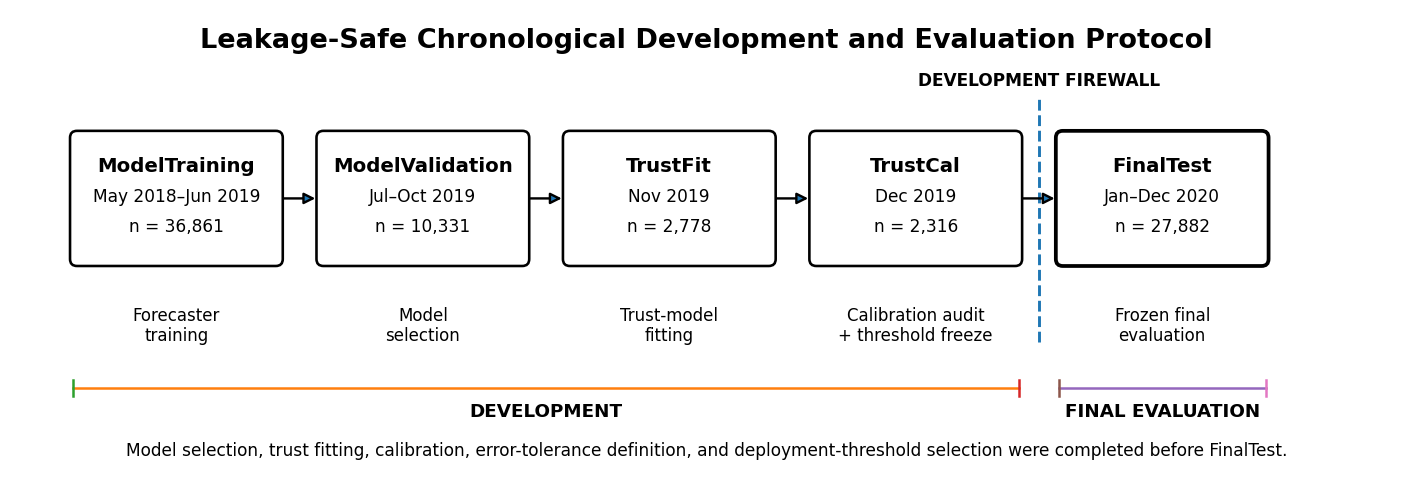

VERICHARGE — REVISED FIGURE 2

✓ Equal-width methodological stages
✓ TrustFit and TrustCal no longer compressed
✓ Firewall isolated from stage boxes
✓ Purpose labels separated
✓ Grayscale-safe
✓ Vector PDF + SVG
✓ 600-dpi PNG

Overwritten files:
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_02_Leakage_Safe_Protocol.pdf
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_02_Leakage_Safe_Protocol.svg
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_02_Leakage_Safe_Protocol.png

✓ STEP 17A-R COMPLETE


In [ ]:
# ============================================================
# VeriCharge — Step 17A-R
# REVISED publication-quality Figure 2
# Leakage-Safe Experimental Protocol
#
# Replaces the rejected proportional-width version.
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib as mpl

PUB_DIR = Path(
    "/content/drive/MyDrive/VeriCharge/publication"
)
FIG_DIR = PUB_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Journal-oriented typography
# ------------------------------------------------------------

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.06
})

# ------------------------------------------------------------
# Frozen protocol
# ------------------------------------------------------------

stages = [
    {
        "name": "ModelTraining",
        "period": "May 2018–Jun 2019",
        "n": "36,861",
        "purpose": "Forecaster\ntraining"
    },
    {
        "name": "ModelValidation",
        "period": "Jul–Oct 2019",
        "n": "10,331",
        "purpose": "Model\nselection"
    },
    {
        "name": "TrustFit",
        "period": "Nov 2019",
        "n": "2,778",
        "purpose": "Trust-model\nfitting"
    },
    {
        "name": "TrustCal",
        "period": "Dec 2019",
        "n": "2,316",
        "purpose": "Calibration audit\n+ threshold freeze"
    },
    {
        "name": "FinalTest",
        "period": "Jan–Dec 2020",
        "n": "27,882",
        "purpose": "Frozen final\nevaluation"
    }
]

# ------------------------------------------------------------
# Canvas
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12.0, 4.0)
)

ax.set_xlim(0, 12)
ax.set_ylim(0, 4)
ax.axis("off")

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.text(
    6,
    3.72,
    "Leakage-Safe Chronological Development and Evaluation Protocol",
    ha="center",
    va="center",
    fontsize=13,
    fontweight="bold"
)

# ------------------------------------------------------------
# Geometry
# Equal widths intentionally used.
# ------------------------------------------------------------

box_w = 1.78
box_h = 1.12
gap = 0.34

start_x = 0.55
box_y = 1.80

positions = []

for i in range(5):
    x = start_x + i * (box_w + gap)
    positions.append(x)

# ------------------------------------------------------------
# Draw boxes
# ------------------------------------------------------------

for i, (stage, x) in enumerate(
    zip(stages, positions)
):

    # FinalTest gets slightly stronger border
    lw = 1.8 if i == 4 else 1.25

    rect = patches.FancyBboxPatch(
        (x, box_y),
        box_w,
        box_h,
        boxstyle="round,pad=0.025,rounding_size=0.06",
        facecolor="white",
        edgecolor="black",
        linewidth=lw
    )

    ax.add_patch(rect)

    ax.text(
        x + box_w / 2,
        box_y + 0.84,
        stage["name"],
        ha="center",
        va="center",
        fontsize=9.5,
        fontweight="bold"
    )

    ax.text(
        x + box_w / 2,
        box_y + 0.57,
        stage["period"],
        ha="center",
        va="center",
        fontsize=8.2
    )

    ax.text(
        x + box_w / 2,
        box_y + 0.31,
        f'n = {stage["n"]}',
        ha="center",
        va="center",
        fontsize=8.2
    )

    # Purpose below box
    ax.text(
        x + box_w / 2,
        1.42,
        stage["purpose"],
        ha="center",
        va="top",
        fontsize=8.0,
        linespacing=1.15
    )

# ------------------------------------------------------------
# Chronological arrows
# ------------------------------------------------------------

for i in range(4):

    x1 = positions[i] + box_w
    x2 = positions[i + 1]

    ax.annotate(
        "",
        xy=(x2 - 0.035, box_y + box_h / 2),
        xytext=(x1 + 0.035, box_y + box_h / 2),
        arrowprops=dict(
            arrowstyle="-|>",
            linewidth=1.15,
            shrinkA=0,
            shrinkB=0,
            mutation_scale=11
        )
    )

# ------------------------------------------------------------
# Development firewall
# Place it cleanly BETWEEN TrustCal and FinalTest.
# ------------------------------------------------------------

trustcal_right = (
    positions[3] + box_w
)

finaltest_left = positions[4]

firewall_x = (
    trustcal_right + finaltest_left
) / 2

ax.plot(
    [firewall_x, firewall_x],
    [1.12, 3.22],
    linestyle="--",
    linewidth=1.4
)

# Horizontal label avoids collision
ax.text(
    firewall_x,
    3.30,
    "DEVELOPMENT FIREWALL",
    ha="center",
    va="bottom",
    fontsize=8.2,
    fontweight="bold"
)

# ------------------------------------------------------------
# Development / FinalTest grouping
# ------------------------------------------------------------

dev_left = positions[0]
dev_right = positions[3] + box_w

test_left = positions[4]
test_right = positions[4] + box_w

group_y = 0.72

# Development line
ax.plot(
    [dev_left, dev_right],
    [group_y, group_y],
    linewidth=1.2
)

ax.plot(
    [dev_left, dev_left],
    [group_y - 0.07, group_y + 0.07],
    linewidth=1.2
)

ax.plot(
    [dev_right, dev_right],
    [group_y - 0.07, group_y + 0.07],
    linewidth=1.2
)

ax.text(
    (dev_left + dev_right) / 2,
    0.51,
    "DEVELOPMENT",
    ha="center",
    va="center",
    fontsize=8.8,
    fontweight="bold"
)

# FinalTest line
ax.plot(
    [test_left, test_right],
    [group_y, group_y],
    linewidth=1.2
)

ax.plot(
    [test_left, test_left],
    [group_y - 0.07, group_y + 0.07],
    linewidth=1.2
)

ax.plot(
    [test_right, test_right],
    [group_y - 0.07, group_y + 0.07],
    linewidth=1.2
)

ax.text(
    (test_left + test_right) / 2,
    0.51,
    "FINAL EVALUATION",
    ha="center",
    va="center",
    fontsize=8.8,
    fontweight="bold"
)

# ------------------------------------------------------------
# Compact methodological note
# ------------------------------------------------------------

ax.text(
    6,
    0.17,
    "Model selection, trust fitting, calibration, error-tolerance definition, "
    "and deployment-threshold selection were completed before FinalTest.",
    ha="center",
    va="center",
    fontsize=8.2
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

base = (
    FIG_DIR /
    "Figure_02_Leakage_Safe_Protocol"
)

fig.savefig(
    str(base) + ".pdf"
)

fig.savefig(
    str(base) + ".svg"
)

fig.savefig(
    str(base) + ".png",
    dpi=600
)

plt.show()
plt.close(fig)

print("=" * 78)
print("VERICHARGE — REVISED FIGURE 2")
print("=" * 78)

print("\n✓ Equal-width methodological stages")
print("✓ TrustFit and TrustCal no longer compressed")
print("✓ Firewall isolated from stage boxes")
print("✓ Purpose labels separated")
print("✓ Grayscale-safe")
print("✓ Vector PDF + SVG")
print("✓ 600-dpi PNG")

print("\nOverwritten files:")
print(str(base) + ".pdf")
print(str(base) + ".svg")
print(str(base) + ".png")

print("\n" + "=" * 78)
print("✓ STEP 17A-R COMPLETE")
print("=" * 78)

Step 17B — Generate Figure 3

VERICHARGE — FIGURE 3 DATA AUDIT

Columns:
['timestamp', 'site_power_kw', 'energy_kwh', 'active_sessions', 'observed_seconds', 'has_observed_power']

Rows: 90233

Timestamp candidates:
['timestamp']

Load/power candidates:
['site_power_kw', 'has_observed_power']

Selected timestamp column: timestamp
Selected load column     : site_power_kw

Temporal range: 2018-05-10 04:45:00+00:00 to 2020-12-05 02:45:00+00:00
Observed load rows: 88443

PRE/POST DESCRIPTIVE AUDIT
------------------------------------------------------------------------------
Pre-boundary observed n  : 63,819
Pre-boundary mean load   : 24.2591 kW
Post-boundary observed n : 24,624
Post-boundary mean load  : 16.9000 kW
Relative mean change    : -30.34%


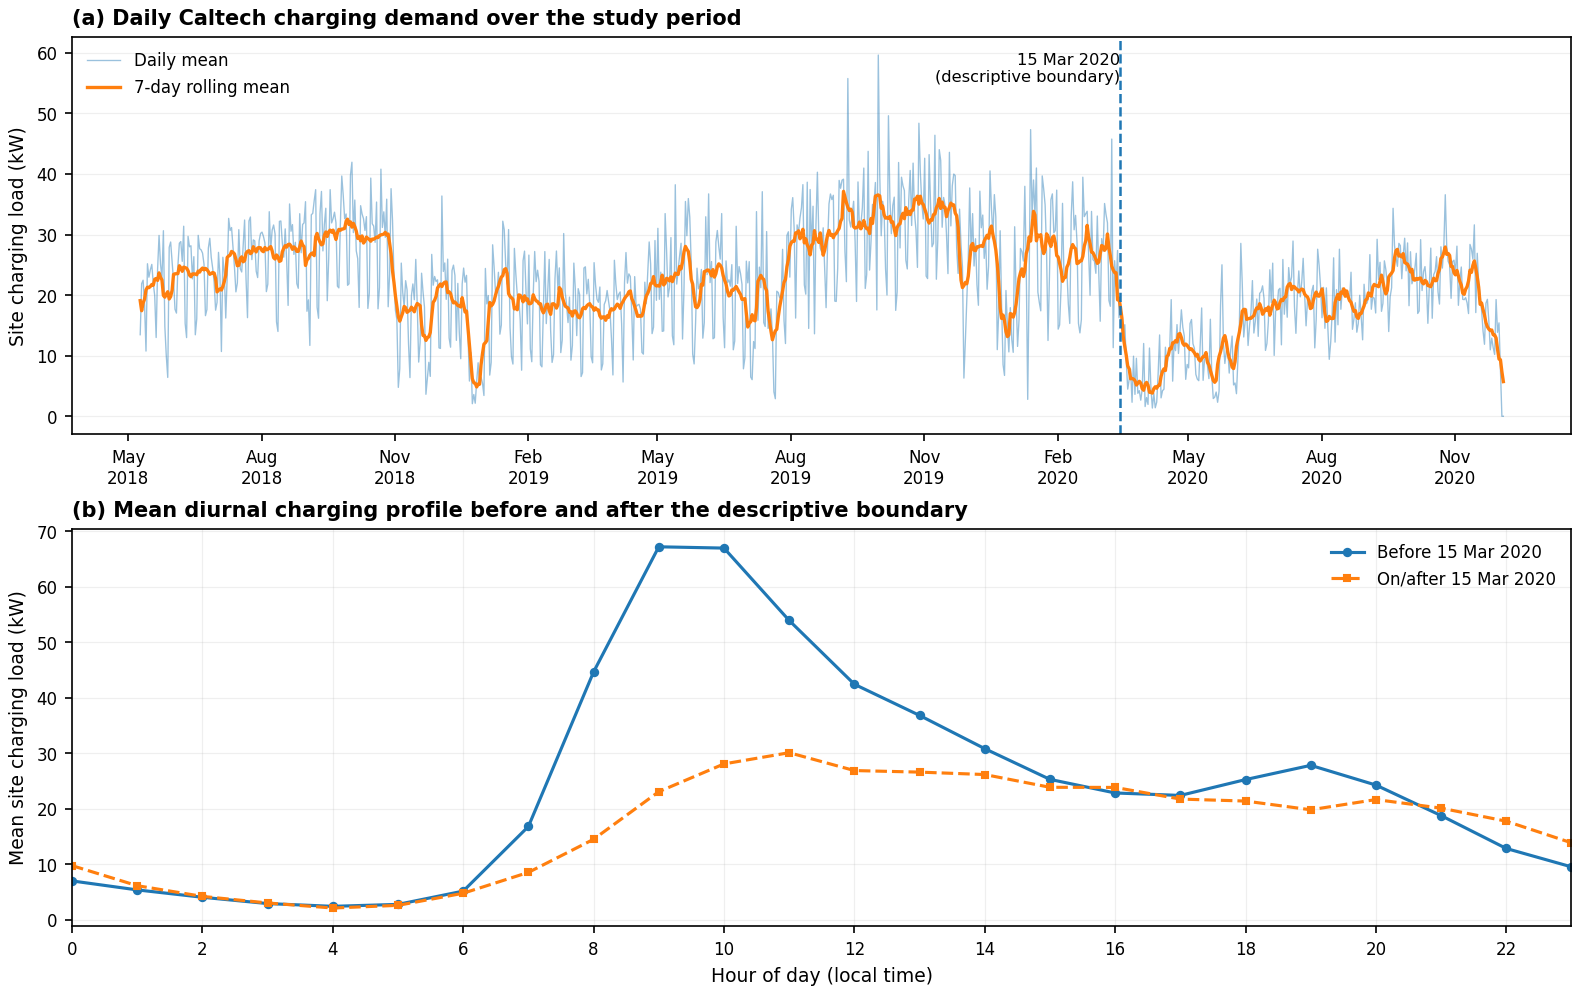


VERICHARGE — FIGURE 3 GENERATED

Files:
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_03_Caltech_Demand_Temporal_Shift.pdf
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_03_Caltech_Demand_Temporal_Shift.svg
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_03_Caltech_Demand_Temporal_Shift.png

✓ Frozen 15-min Caltech aggregation used
✓ Daily values + 7-day visual smoother
✓ Local-time diurnal profile
✓ Descriptive 15-Mar-2020 boundary explicitly labeled
✓ No causal interpretation imposed
✓ PDF/SVG vector + 600-dpi PNG

✓ STEP 17B COMPLETE


In [ ]:
# ============================================================
# VeriCharge — Step 17B
# Publication Figure 3
# Caltech EV Charging Demand and 2020 Deployment Shift
#
# Frozen aggregated data only.
# No modeling / fitting / tuning.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.dates as mdates

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

DATA_PATH = Path(
    "/content/drive/MyDrive/VeriCharge/data/processed/"
    "caltech_site_load_15min.csv.gz"
)

PUB_DIR = Path(
    "/content/drive/MyDrive/VeriCharge/publication"
)

FIG_DIR = PUB_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Publication style
# ------------------------------------------------------------

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.06
})

# ------------------------------------------------------------
# A. Load frozen aggregated data
# ------------------------------------------------------------

df = pd.read_csv(DATA_PATH)

print("=" * 78)
print("VERICHARGE — FIGURE 3 DATA AUDIT")
print("=" * 78)

print("\nColumns:")
print(df.columns.tolist())

print("\nRows:", len(df))

# Automatically identify timestamp and site-load columns
timestamp_candidates = [
    c for c in df.columns
    if "timestamp" in c.lower()
    or "datetime" in c.lower()
]

power_candidates = [
    c for c in df.columns
    if (
        "power" in c.lower()
        or "load" in c.lower()
    )
    and "active" not in c.lower()
]

print("\nTimestamp candidates:")
print(timestamp_candidates)

print("\nLoad/power candidates:")
print(power_candidates)

# Prefer known/likely names if available
preferred_ts = [
    "timestamp_utc",
    "timestamp",
    "datetime_utc",
    "datetime"
]

preferred_power = [
    "site_power_kw",
    "power_kw",
    "site_load_kw",
    "load_kw"
]

ts_col = next(
    (
        c for c in preferred_ts
        if c in df.columns
    ),
    timestamp_candidates[0]
)

power_col = next(
    (
        c for c in preferred_power
        if c in df.columns
    ),
    power_candidates[0]
)

print("\nSelected timestamp column:", ts_col)
print("Selected load column     :", power_col)

# ------------------------------------------------------------
# B. Parse UTC timestamp
# ------------------------------------------------------------

df[ts_col] = pd.to_datetime(
    df[ts_col],
    utc=True
)

df = df.sort_values(ts_col).copy()

print(
    "\nTemporal range:",
    df[ts_col].min(),
    "to",
    df[ts_col].max()
)

print(
    "Observed load rows:",
    df[power_col].notna().sum()
)

# ------------------------------------------------------------
# C. Local time for hourly profile
# ------------------------------------------------------------

df["timestamp_local"] = (
    df[ts_col]
    .dt.tz_convert(
        "America/Los_Angeles"
    )
)

df["date_local"] = (
    df["timestamp_local"]
    .dt.date
)

df["hour_local"] = (
    df["timestamp_local"]
    .dt.hour
)

# ------------------------------------------------------------
# D. Daily mean load
# ------------------------------------------------------------

daily = (
    df
    .set_index("timestamp_local")[power_col]
    .resample("1D")
    .agg(["mean", "count"])
    .reset_index()
)

daily.rename(
    columns={"mean": "mean_load_kw"},
    inplace=True
)

# Keep days containing at least one observed interval.
daily_plot = daily[
    daily["count"] > 0
].copy()

# 7-day rolling mean for visual readability only.
# This is NOT used in any experiment.
daily_plot["rolling_7d_kw"] = (
    daily_plot["mean_load_kw"]
    .rolling(
        window=7,
        center=True,
        min_periods=1
    )
    .mean()
)

# ------------------------------------------------------------
# E. Descriptive pre/post boundary
# ------------------------------------------------------------

boundary_utc = pd.Timestamp(
    "2020-03-15",
    tz="UTC"
)

boundary_local = boundary_utc.tz_convert(
    "America/Los_Angeles"
)

df["period"] = np.where(
    df[ts_col] < boundary_utc,
    "Pre-boundary",
    "Post-boundary"
)

hourly = (
    df.dropna(
        subset=[power_col]
    )
    .groupby(
        ["period", "hour_local"]
    )[power_col]
    .mean()
    .unstack(0)
)

# ------------------------------------------------------------
# F. Numerical audit
# ------------------------------------------------------------

pre = df.loc[
    (
        df[ts_col]
        <
        boundary_utc
    )
    &
    df[power_col].notna(),
    power_col
]

post = df.loc[
    (
        df[ts_col]
        >=
        boundary_utc
    )
    &
    df[power_col].notna(),
    power_col
]

print("\nPRE/POST DESCRIPTIVE AUDIT")
print("-" * 78)

print(
    f"Pre-boundary observed n  : {len(pre):,}"
)
print(
    f"Pre-boundary mean load   : {pre.mean():.4f} kW"
)

print(
    f"Post-boundary observed n : {len(post):,}"
)
print(
    f"Post-boundary mean load  : {post.mean():.4f} kW"
)

print(
    "Relative mean change    : "
    f"{100*(post.mean()-pre.mean())/pre.mean():+.2f}%"
)

# ------------------------------------------------------------
# G. Figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(10.5, 6.6),
    constrained_layout=True
)

# ============================================================
# Panel A — Daily temporal profile
# ============================================================

ax = axes[0]

# Daily values
ax.plot(
    daily_plot["timestamp_local"],
    daily_plot["mean_load_kw"],
    linewidth=0.65,
    alpha=0.45,
    label="Daily mean"
)

# 7-day visual smoother
ax.plot(
    daily_plot["timestamp_local"],
    daily_plot["rolling_7d_kw"],
    linewidth=1.6,
    label="7-day rolling mean"
)

# Boundary
ax.axvline(
    boundary_local,
    linestyle="--",
    linewidth=1.2
)

ylim = ax.get_ylim()

ax.text(
    boundary_local,
    ylim[1] * 0.96,
    "15 Mar 2020\n(descriptive boundary)",
    ha="right",
    va="top",
    fontsize=7.8
)

ax.set_ylabel(
    "Site charging load (kW)"
)

ax.set_title(
    "(a) Daily Caltech charging demand over the study period",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.legend(
    frameon=False,
    loc="upper left"
)

ax.xaxis.set_major_locator(
    mdates.MonthLocator(
        interval=3
    )
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter(
        "%b\n%Y"
    )
)

# ============================================================
# Panel B — Hour-of-day profile
# ============================================================

ax = axes[1]

# Use explicit line styles/markers so figure remains readable
# when printed in grayscale.

ax.plot(
    hourly.index,
    hourly["Pre-boundary"],
    marker="o",
    markersize=3.5,
    linewidth=1.5,
    label="Before 15 Mar 2020"
)

ax.plot(
    hourly.index,
    hourly["Post-boundary"],
    marker="s",
    markersize=3.2,
    linewidth=1.5,
    linestyle="--",
    label="On/after 15 Mar 2020"
)

ax.set_xlim(
    0,
    23
)

ax.set_xticks(
    np.arange(
        0,
        24,
        2
    )
)

ax.set_xlabel(
    "Hour of day (local time)"
)

ax.set_ylabel(
    "Mean site charging load (kW)"
)

ax.set_title(
    "(b) Mean diurnal charging profile before and after the descriptive boundary",
    loc="left",
    fontweight="bold"
)

ax.grid(
    alpha=0.20,
    linewidth=0.6
)

ax.legend(
    frameon=False,
    loc="upper right"
)

# ------------------------------------------------------------
# H. Save
# ------------------------------------------------------------

base = (
    FIG_DIR /
    "Figure_03_Caltech_Demand_Temporal_Shift"
)

fig.savefig(
    str(base) + ".pdf"
)

fig.savefig(
    str(base) + ".svg"
)

fig.savefig(
    str(base) + ".png",
    dpi=600
)

plt.show()
plt.close(fig)

print("\n" + "=" * 78)
print("VERICHARGE — FIGURE 3 GENERATED")
print("=" * 78)

print("\nFiles:")
print(str(base) + ".pdf")
print(str(base) + ".svg")
print(str(base) + ".png")

print("\n✓ Frozen 15-min Caltech aggregation used")
print("✓ Daily values + 7-day visual smoother")
print("✓ Local-time diurnal profile")
print("✓ Descriptive 15-Mar-2020 boundary explicitly labeled")
print("✓ No causal interpretation imposed")
print("✓ PDF/SVG vector + 600-dpi PNG")

print("\n" + "=" * 78)
print("✓ STEP 17B COMPLETE")
print("=" * 78)

Figure 4 — Forecasting model comparison

VERICHARGE — FIGURE 4 MODELVALIDATION AUDIT
      Model  Horizon_min  MAE_kW  RMSE_kW     R2
Persistence           15  4.3422   6.8703 0.9523
Persistence           30  7.4420  11.4205 0.8683
Persistence           60 12.2536  18.5805 0.6515
    XGBoost           15  4.2098   6.5797 0.9563
    XGBoost           30  6.5680   9.6057 0.9068
    XGBoost           60  8.8435  12.7208 0.8366
       LSTM           15  4.5310   6.5671 0.9564
       LSTM           30  6.6522   9.5455 0.9080
       LSTM           60  9.3253  13.4775 0.8166
        TCN           15  4.0710   6.0033 0.9636
        TCN           30  6.3062   9.1030 0.9163
        TCN           60  8.9697  12.9111 0.8317
Transformer           15  4.5278   6.4928 0.9574
Transformer           30  6.5804   9.4100 0.9106
Transformer           60  9.1258  13.2693 0.8223

HORIZON WINNERS BY MAE
------------------------------------------------------------------------------
15 min: TCN (MAE=4.0710 kW)
30 min: TCN (MAE=6.3062 kW)
60 min: XGBoo

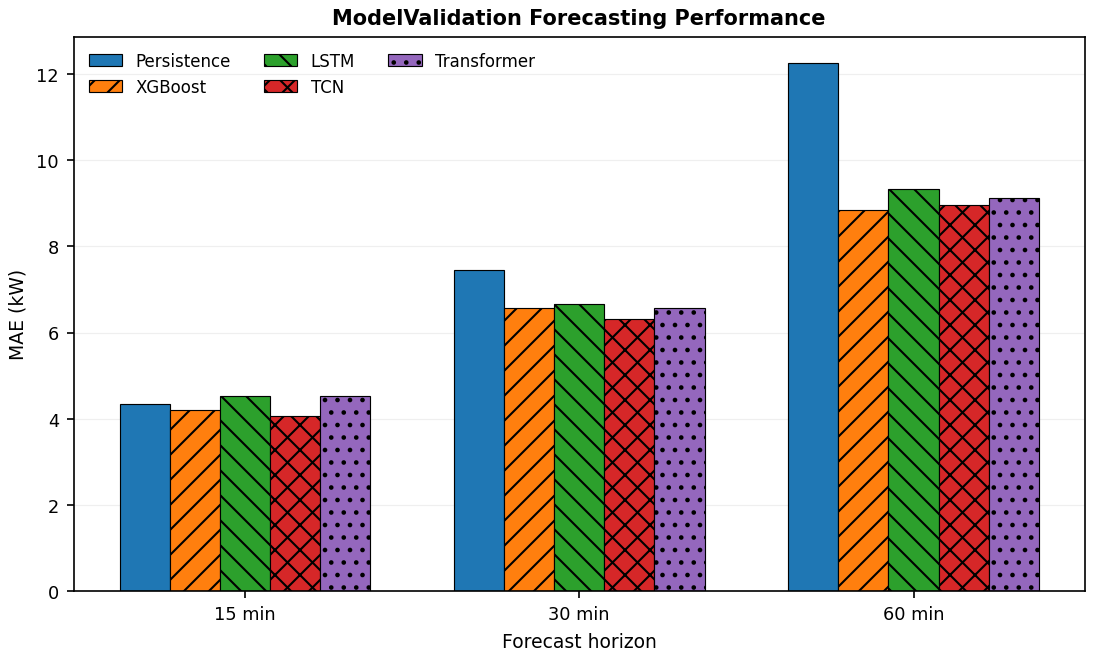


VERICHARGE — FIGURE 4 GENERATED

Files:
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_04_ModelValidation_Model_Comparison.pdf
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_04_ModelValidation_Model_Comparison.svg
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_04_ModelValidation_Model_Comparison.png

Table data:
/content/drive/MyDrive/VeriCharge/publication/tables/Table_ModelValidation_Forecasting_Comparison.csv
/content/drive/MyDrive/VeriCharge/publication/tables/Table_ModelSelection_Aggregate_Score.csv

✓ ModelValidation only
✓ No TrustCalibration outcomes used
✓ No FinalTest outcomes used
✓ TCN marked as frozen primary forecaster
✓ Vector PDF/SVG + 600-dpi PNG

✓ STEP 17C COMPLETE


In [ ]:
# ============================================================
# VeriCharge — Step 17C
# Publication Figure 4
# ModelValidation Forecasting Comparison
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

PUB_DIR = Path(
    "/content/drive/MyDrive/VeriCharge/publication"
)
FIG_DIR = PUB_DIR / "figures"
TABLE_DIR = PUB_DIR / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.06
})

# ------------------------------------------------------------
# A. FROZEN Step 6.7 ModelValidation results
#
# These are the authoritative clean model-selection values.
# TrustCalibration and FinalTest are NOT used here.
# ------------------------------------------------------------

records = [
    # model, horizon, MAE, RMSE, R2
    ("Persistence", 15, 4.3422,  6.8703, 0.9523),
    ("Persistence", 30, 7.4420, 11.4205, 0.8683),
    ("Persistence", 60,12.2536, 18.5805, 0.6515),

    ("XGBoost",     15, 4.2098,  6.5797, 0.9563),
    ("XGBoost",     30, 6.5680,  9.6057, 0.9068),
    ("XGBoost",     60, 8.8435, 12.7208, 0.8366),

    ("LSTM",        15, 4.5310,  6.5671, 0.9564),
    ("LSTM",        30, 6.6522,  9.5455, 0.9080),
    ("LSTM",        60, 9.3253, 13.4775, 0.8166),

    ("TCN",         15, 4.0710,  6.0033, 0.9636),
    ("TCN",         30, 6.3062,  9.1030, 0.9163),
    ("TCN",         60, 8.9697, 12.9111, 0.8317),

    ("Transformer", 15, 4.5278,  6.4928, 0.9574),
    ("Transformer", 30, 6.5804,  9.4100, 0.9106),
    ("Transformer", 60, 9.1258, 13.2693, 0.8223),
]

df = pd.DataFrame(
    records,
    columns=[
        "Model",
        "Horizon_min",
        "MAE_kW",
        "RMSE_kW",
        "R2"
    ]
)

print("=" * 78)
print("VERICHARGE — FIGURE 4 MODELVALIDATION AUDIT")
print("=" * 78)

print(
    df.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# B. Verify horizon winners
# ------------------------------------------------------------

print("\nHORIZON WINNERS BY MAE")
print("-" * 78)

for h in [15, 30, 60]:

    d = df[
        df["Horizon_min"] == h
    ]

    winner = d.loc[
        d["MAE_kW"].idxmin()
    ]

    print(
        f"{h:2d} min: "
        f"{winner['Model']} "
        f"(MAE={winner['MAE_kW']:.4f} kW)"
    )

# Expected:
# 15 min = TCN
# 30 min = TCN
# 60 min = XGBoost

# ------------------------------------------------------------
# C. Aggregate normalized selection score
#
# Frozen Step 6.7 aggregate values.
# Lower is better.
# ------------------------------------------------------------

aggregate_score = {
    "TCN":         0.2677,
    "XGBoost":     0.2743,
    "Transformer": 0.2793,
    "LSTM":        0.2832,
    "Persistence": 0.3443
}

print("\nFROZEN AGGREGATE SELECTION SCORE")
print("-" * 78)

for model, score in sorted(
    aggregate_score.items(),
    key=lambda x: x[1]
):
    print(
        f"{model:12s}: {score:.4f}"
    )

# ------------------------------------------------------------
# D. Plot
# ------------------------------------------------------------

models = [
    "Persistence",
    "XGBoost",
    "LSTM",
    "TCN",
    "Transformer"
]

horizons = [15, 30, 60]

x = np.arange(
    len(horizons)
)

bar_width = 0.15

fig, ax = plt.subplots(
    figsize=(8.7, 4.8)
)

# Use hatching in addition to the default color cycle
# so the figure remains interpretable in grayscale.

hatches = [
    "",
    "//",
    "\\\\",
    "xx",
    ".."
]

for i, model in enumerate(models):

    d = (
        df[
            df["Model"] == model
        ]
        .set_index("Horizon_min")
        .loc[horizons]
    )

    offset = (
        i - (len(models)-1)/2
    ) * bar_width

    bars = ax.bar(
        x + offset,
        d["MAE_kW"].values,
        width=bar_width,
        label=model,
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.55
    )

    # Mark TCN bars as selected primary forecaster
    # Mark TCN bars as selected primary forecaster

# ------------------------------------------------------------
# E. Formatting
# ------------------------------------------------------------

ax.set_xticks(x)

ax.set_xticklabels([
    "15 min",
    "30 min",
    "60 min"
])

ax.set_xlabel(
    "Forecast horizon"
)

ax.set_ylabel(
    "MAE (kW)"
)

ax.set_title(
    "ModelValidation Forecasting Performance",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.set_axisbelow(True)

ax.legend(
    frameon=False,
    ncol=3,
    loc="upper left"
)


# ------------------------------------------------------------
# F. Save figure
# ------------------------------------------------------------

base = (
    FIG_DIR /
    "Figure_04_ModelValidation_Model_Comparison"
)

fig.savefig(
    str(base) + ".pdf"
)

fig.savefig(
    str(base) + ".svg"
)

fig.savefig(
    str(base) + ".png",
    dpi=600
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# G. Save manuscript-ready table data
# ------------------------------------------------------------

df.to_csv(
    TABLE_DIR /
    "Table_ModelValidation_Forecasting_Comparison.csv",
    index=False
)

selection_df = pd.DataFrame([
    {
        "Model": model,
        "Aggregate_selection_score":
            score
    }
    for model, score
    in aggregate_score.items()
]).sort_values(
    "Aggregate_selection_score"
)

selection_df.to_csv(
    TABLE_DIR /
    "Table_ModelSelection_Aggregate_Score.csv",
    index=False
)

print("\n" + "=" * 78)
print("VERICHARGE — FIGURE 4 GENERATED")
print("=" * 78)

print("\nFiles:")
print(str(base) + ".pdf")
print(str(base) + ".svg")
print(str(base) + ".png")

print("\nTable data:")
print(
    TABLE_DIR /
    "Table_ModelValidation_Forecasting_Comparison.csv"
)

print(
    TABLE_DIR /
    "Table_ModelSelection_Aggregate_Score.csv"
)

print("\n✓ ModelValidation only")
print("✓ No TrustCalibration outcomes used")
print("✓ No FinalTest outcomes used")
print("✓ TCN marked as frozen primary forecaster")
print("✓ Vector PDF/SVG + 600-dpi PNG")

print("\n" + "=" * 78)
print("✓ STEP 17C COMPLETE")
print("=" * 78)

Figure 5: Reliability signals \(U\), \(R\), and \(S\)

VERICHARGE — FIGURE 5 RELIABILITY-SIGNAL AUDIT
Signal       Signal_description  Horizon_min  Spearman_with_absolute_error  Highest_to_lowest_quintile_MAE_ratio
     U   MC-dropout uncertainty           15                        0.1565                                1.6980
     U   MC-dropout uncertainty           30                        0.1332                                1.5968
     U   MC-dropout uncertainty           60                        0.1155                                1.5445
     R Perturbation sensitivity           15                        0.2125                                2.4814
     R Perturbation sensitivity           30                        0.2318                                2.4687
     R Perturbation sensitivity           60                        0.2454                                2.4011
     S Distribution-shift score           15                        0.2025                                1.9048
     S Distribution-shift score           30     

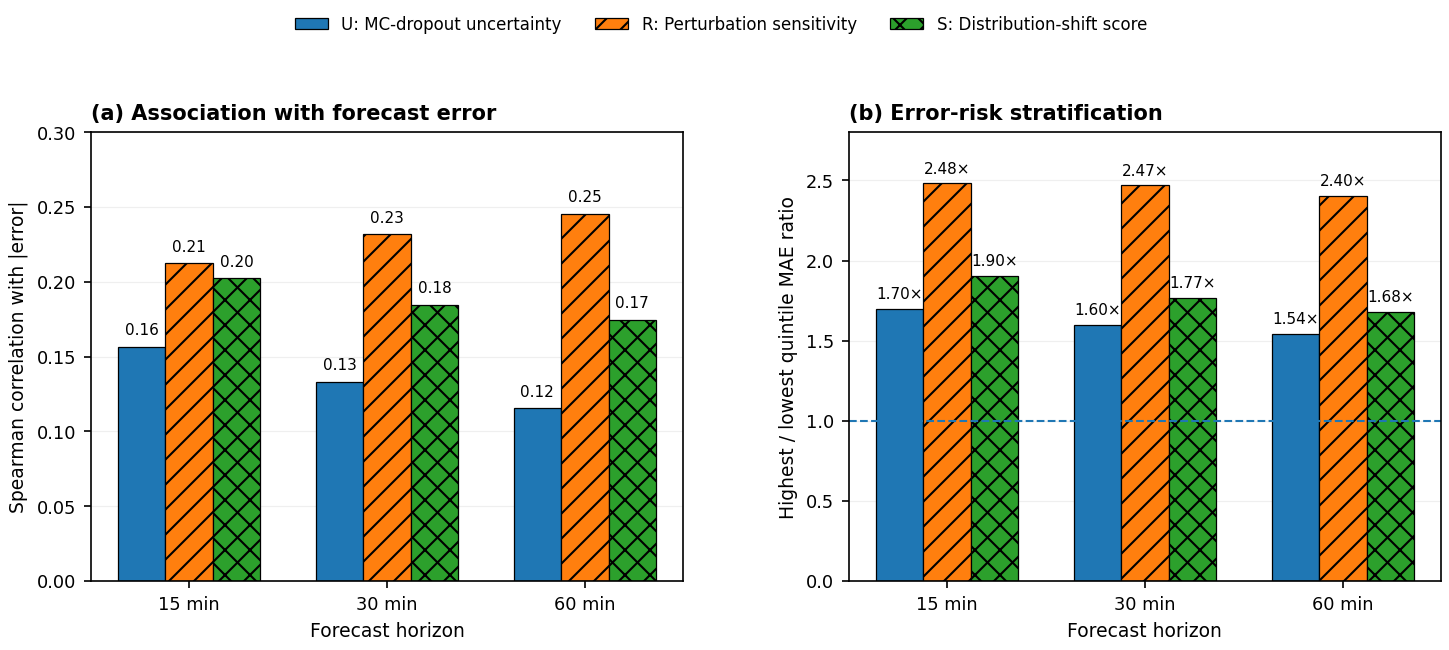


VERICHARGE — FIGURE 5 GENERATED

Files:
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_05_Reliability_Signal_Validation.pdf
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_05_Reliability_Signal_Validation.svg
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_05_Reliability_Signal_Validation.png

Table:
/content/drive/MyDrive/VeriCharge/publication/tables/Table_Reliability_Signal_Validation.csv

✓ ModelValidation evidence only
✓ U = MC-dropout uncertainty
✓ R = perturbation sensitivity
✓ S = distribution-shift score
✓ No ESI included in learned trust
✓ Vector PDF/SVG + 600-dpi PNG

✓ STEP 17D COMPLETE


In [ ]:
# ============================================================
# VeriCharge — Step 17D
# Publication Figure 5
# Reliability-Signal Error Stratification
#
# ModelValidation only.
# Frozen Step 7.2 / 7.5 / 7.8 results.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

PUB_DIR = Path(
    "/content/drive/MyDrive/VeriCharge/publication"
)
FIG_DIR = PUB_DIR / "figures"
TABLE_DIR = PUB_DIR / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.06
})

# ------------------------------------------------------------
# A. Frozen signal-validation results
# ------------------------------------------------------------

horizons = np.array([15, 30, 60])

data = {
    "U": {
        "label": "MC-dropout uncertainty",
        "spearman": [0.156517, 0.133188, 0.115529],
        "q5_q1": [1.6980, 1.5968, 1.5445]
    },

    "R": {
        "label": "Perturbation sensitivity",
        "spearman": [0.212458, 0.231770, 0.245386],
        "q5_q1": [2.4814, 2.4687, 2.4011]
    },

    "S": {
        "label": "Distribution-shift score",
        "spearman": [0.202471, 0.184710, 0.174775],
        "q5_q1": [1.9048, 1.7666, 1.6783]
    }
}

# ------------------------------------------------------------
# B. Audit table
# ------------------------------------------------------------

rows = []

for signal, d in data.items():

    for h, rho, ratio in zip(
        horizons,
        d["spearman"],
        d["q5_q1"]
    ):

        rows.append({
            "Signal": signal,
            "Signal_description": d["label"],
            "Horizon_min": h,
            "Spearman_with_absolute_error": rho,
            "Highest_to_lowest_quintile_MAE_ratio": ratio
        })

audit_df = pd.DataFrame(rows)

print("=" * 78)
print("VERICHARGE — FIGURE 5 RELIABILITY-SIGNAL AUDIT")
print("=" * 78)

print(
    audit_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# C. Plot
#
# Two complementary panels:
# (a) Spearman association with absolute forecast error
# (b) Highest / lowest signal-quintile MAE ratio
#
# This avoids implying causality.
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10.0, 4.4)
)

x = np.arange(3)
width = 0.24

signals = ["U", "R", "S"]

hatches = [
    "",
    "//",
    "xx"
]

# ------------------------------------------------------------
# Panel A — Spearman
# ------------------------------------------------------------

ax = axes[0]

for i, signal in enumerate(signals):

    values = data[signal]["spearman"]

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width=width,
        label=f"{signal}: {data[signal]['label']}",
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.6
    )

    for bar, value in zip(
        bars,
        values
    ):
        ax.text(
            bar.get_x()
            + bar.get_width()/2,
            bar.get_height()
            + 0.006,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=7.3
        )

ax.set_xticks(x)
ax.set_xticklabels([
    "15 min",
    "30 min",
    "60 min"
])

ax.set_ylim(0, 0.30)

ax.set_xlabel(
    "Forecast horizon"
)

ax.set_ylabel(
    "Spearman correlation with |error|"
)

ax.set_title(
    "(a) Association with forecast error",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# Panel B — Q5/Q1 error separation
# ------------------------------------------------------------

ax = axes[1]

for i, signal in enumerate(signals):

    values = data[signal]["q5_q1"]

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width=width,
        label=signal,
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.6
    )

    for bar, value in zip(
        bars,
        values
    ):
        ax.text(
            bar.get_x()
            + bar.get_width()/2,
            bar.get_height()
            + 0.045,
            f"{value:.2f}×",
            ha="center",
            va="bottom",
            fontsize=7.3
        )

# Reference: ratio 1 = no error separation
ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.0
)

ax.set_xticks(x)

ax.set_xticklabels([
    "15 min",
    "30 min",
    "60 min"
])

ax.set_ylim(0, 2.8)

ax.set_xlabel(
    "Forecast horizon"
)

ax.set_ylabel(
    "Highest / lowest quintile MAE ratio"
)

ax.set_title(
    "(b) Error-risk stratification",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False
)

fig.subplots_adjust(
    top=0.82,
    bottom=0.14,
    left=0.08,
    right=0.98,
    wspace=0.28
)

# ------------------------------------------------------------
# D. Save
# ------------------------------------------------------------

base = (
    FIG_DIR /
    "Figure_05_Reliability_Signal_Validation"
)

fig.savefig(
    str(base) + ".pdf"
)

fig.savefig(
    str(base) + ".svg"
)

fig.savefig(
    str(base) + ".png",
    dpi=600
)

plt.show()
plt.close(fig)

audit_df.to_csv(
    TABLE_DIR /
    "Table_Reliability_Signal_Validation.csv",
    index=False
)

print("\n" + "=" * 78)
print("VERICHARGE — FIGURE 5 GENERATED")
print("=" * 78)

print("\nFiles:")
print(str(base) + ".pdf")
print(str(base) + ".svg")
print(str(base) + ".png")

print("\nTable:")
print(
    TABLE_DIR /
    "Table_Reliability_Signal_Validation.csv"
)

print("\n✓ ModelValidation evidence only")
print("✓ U = MC-dropout uncertainty")
print("✓ R = perturbation sensitivity")
print("✓ S = distribution-shift score")
print("✓ No ESI included in learned trust")
print("✓ Vector PDF/SVG + 600-dpi PNG")

print("\n" + "=" * 78)
print("✓ STEP 17D COMPLETE")
print("=" * 78)

Figure 6 — FinalTest Risk–Coverage Curves

VERICHARGE — FIGURE 6 RISK–COVERAGE AUDIT
15 min: MAE 8/8 | RMSE 8/8 | Failure 8/8
30 min: MAE 8/8 | RMSE 8/8 | Failure 8/8
60 min: MAE 8/8 | RMSE 8/8 | Failure 8/8


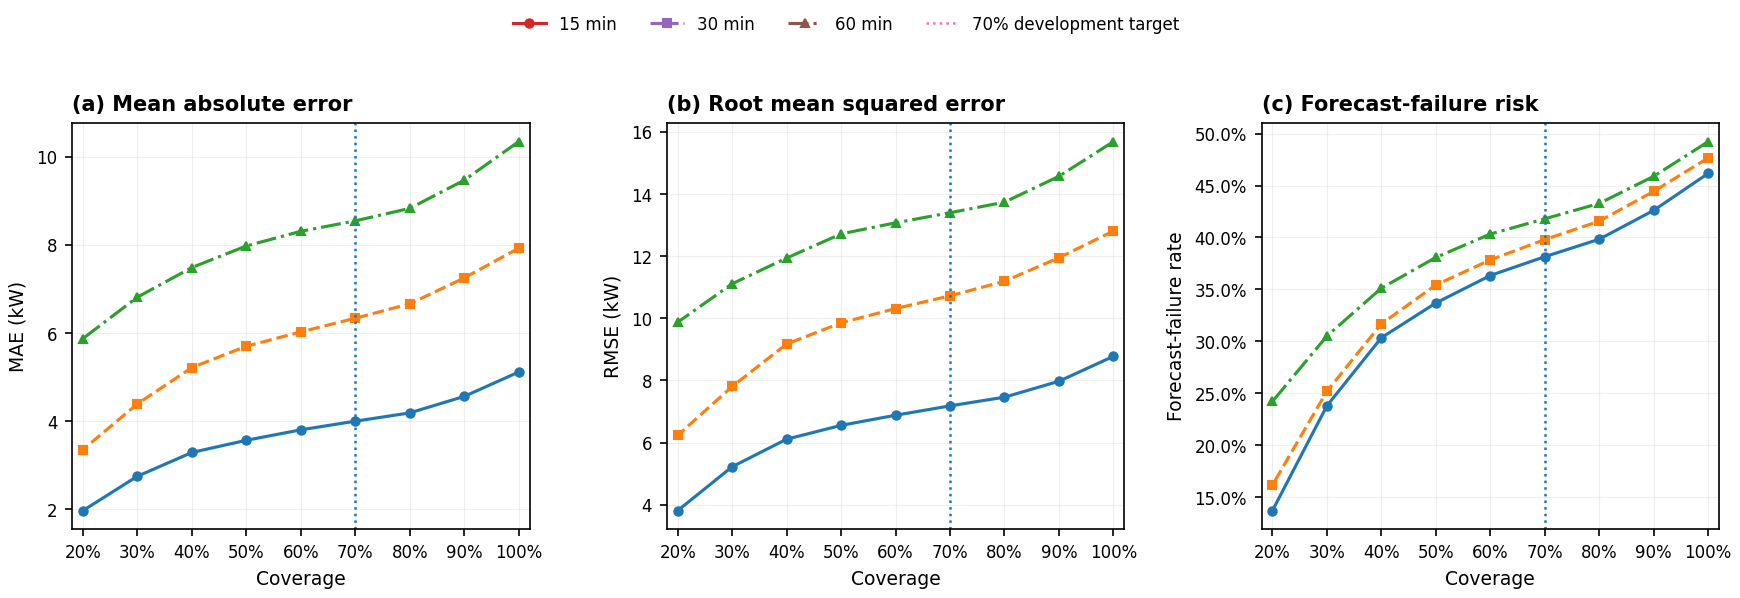


Files:
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_06_FinalTest_Risk_Coverage.pdf
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_06_FinalTest_Risk_Coverage.svg
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_06_FinalTest_Risk_Coverage.png

Underlying table:
/content/drive/MyDrive/VeriCharge/publication/tables/Table_FinalTest_Risk_Coverage.csv

✓ Frozen FinalTest risk–coverage results
✓ Full curve shown; no cherry-picked coverage
✓ 70% line denotes development target, not test optimization
✓ MAE/RMSE/failure monotonicity audited
✓ Vector PDF/SVG + 600-dpi PNG

✓ STEP 17E COMPLETE


In [ ]:
# ============================================================
# VeriCharge — Step 17E
# Publication Figure 6
# FinalTest Risk–Coverage Curves
#
# FROZEN FinalTest results only.
# No fitting / tuning / threshold selection.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import PercentFormatter

PUB_DIR = Path(
    "/content/drive/MyDrive/VeriCharge/publication"
)

FIG_DIR = PUB_DIR / "figures"
TABLE_DIR = PUB_DIR / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.06
})

# ------------------------------------------------------------
# A. Frozen FinalTest risk–coverage values
# ------------------------------------------------------------

coverage = np.array([
    1.0,
    0.9,
    0.8,
    0.7,
    0.6,
    0.5,
    0.4,
    0.3,
    0.2
])

results = {
    "15 min": {
        "MAE": [
            5.1139, 4.5606, 4.1870,
            3.9988, 3.8024, 3.5655,
            3.2885, 2.7492, 1.9688
        ],
        "RMSE": [
            8.7751, 7.9727, 7.4598,
            7.1802, 6.8777, 6.5523,
            6.1065, 5.2196, 3.8062
        ],
        "Failure": [
            0.4617, 0.4261, 0.3983,
            0.3815, 0.3634, 0.3369,
            0.3035, 0.2379, 0.1370
        ]
    },

    "30 min": {
        "MAE": [
            7.9249, 7.2496, 6.6627,
            6.3356, 6.0267, 5.6999,
            5.2162, 4.3917, 3.3538
        ],
        "RMSE": [
            12.8096, 11.9517, 11.1926,
            10.7227, 10.3137, 9.8534,
            9.1707, 7.8046, 6.2299
        ],
        "Failure": [
            0.4766, 0.4444, 0.4157,
            0.3980, 0.3784, 0.3543,
            0.3168, 0.2519, 0.1616
        ]
    },

    "60 min": {
        "MAE": [
            10.3438, 9.4675, 8.8284,
            8.5460, 8.3084, 7.9763,
            7.4860, 6.8138, 5.8742
        ],
        "RMSE": [
            15.6895, 14.5730, 13.7401,
            13.3998, 13.0751, 12.7180,
            11.9402, 11.1109, 9.8722
        ],
        "Failure": [
            0.4923, 0.4589, 0.4328,
            0.4180, 0.4033, 0.3808,
            0.3512, 0.3051, 0.2421
        ]
    }
}

# ------------------------------------------------------------
# B. Integrity audit
# ------------------------------------------------------------

print("=" * 78)
print("VERICHARGE — FIGURE 6 RISK–COVERAGE AUDIT")
print("=" * 78)

for horizon, d in results.items():

    mae = np.asarray(d["MAE"])
    rmse = np.asarray(d["RMSE"])
    failure = np.asarray(d["Failure"])

    # Coverage array runs from high -> low.
    # Therefore risk should also decrease from left-array
    # position to right-array position.
    mae_monotonic = np.sum(
        np.diff(mae) <= 0
    )

    rmse_monotonic = np.sum(
        np.diff(rmse) <= 0
    )

    failure_monotonic = np.sum(
        np.diff(failure) <= 0
    )

    print(
        f"{horizon}: "
        f"MAE {mae_monotonic}/8 | "
        f"RMSE {rmse_monotonic}/8 | "
        f"Failure {failure_monotonic}/8"
    )

# ------------------------------------------------------------
# C. Save underlying table
# ------------------------------------------------------------

rows = []

for horizon, d in results.items():

    for i, cov in enumerate(coverage):

        rows.append({
            "Horizon":
                horizon,

            "Coverage":
                cov,

            "MAE_kW":
                d["MAE"][i],

            "RMSE_kW":
                d["RMSE"][i],

            "Failure_rate":
                d["Failure"][i]
        })

risk_df = pd.DataFrame(rows)

risk_df.to_csv(
    TABLE_DIR /
    "Table_FinalTest_Risk_Coverage.csv",
    index=False
)

# ------------------------------------------------------------
# D. Figure
#
# Display x-axis low -> high coverage (20% -> 100%).
# This makes the operational trade-off intuitive:
# moving right = accepting more forecasts = higher risk.
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(12.0, 4.1)
)

styles = {
    "15 min": {
        "marker": "o",
        "linestyle": "-"
    },

    "30 min": {
        "marker": "s",
        "linestyle": "--"
    },

    "60 min": {
        "marker": "^",
        "linestyle": "-."
    }
}

# ------------------------------------------------------------
# Panel A — MAE
# ------------------------------------------------------------

ax = axes[0]

for horizon in results:

    ax.plot(
        coverage,
        results[horizon]["MAE"],
        marker=styles[horizon]["marker"],
        linestyle=styles[horizon]["linestyle"],
        linewidth=1.5,
        markersize=4,
        label=horizon
    )

ax.axvline(
    0.70,
    linestyle=":",
    linewidth=1.2
)

ax.set_xlim(
    0.18,
    1.02
)

ax.set_xlabel(
    "Coverage"
)

ax.set_ylabel(
    "MAE (kW)"
)

ax.set_title(
    "(a) Mean absolute error",
    loc="left",
    fontweight="bold"
)

ax.grid(
    alpha=0.20,
    linewidth=0.6
)

ax.xaxis.set_major_formatter(
    PercentFormatter(
        xmax=1.0
    )
)

# ------------------------------------------------------------
# Panel B — RMSE
# ------------------------------------------------------------

ax = axes[1]

for horizon in results:

    ax.plot(
        coverage,
        results[horizon]["RMSE"],
        marker=styles[horizon]["marker"],
        linestyle=styles[horizon]["linestyle"],
        linewidth=1.5,
        markersize=4
    )

ax.axvline(
    0.70,
    linestyle=":",
    linewidth=1.2
)

ax.set_xlim(
    0.18,
    1.02
)

ax.set_xlabel(
    "Coverage"
)

ax.set_ylabel(
    "RMSE (kW)"
)

ax.set_title(
    "(b) Root mean squared error",
    loc="left",
    fontweight="bold"
)

ax.grid(
    alpha=0.20,
    linewidth=0.6
)

ax.xaxis.set_major_formatter(
    PercentFormatter(
        xmax=1.0
    )
)

# ------------------------------------------------------------
# Panel C — failure risk
# ------------------------------------------------------------

ax = axes[2]

for horizon in results:

    ax.plot(
        coverage,
        results[horizon]["Failure"],
        marker=styles[horizon]["marker"],
        linestyle=styles[horizon]["linestyle"],
        linewidth=1.5,
        markersize=4
    )

ax.axvline(
    0.70,
    linestyle=":",
    linewidth=1.2,
    label="70% development target"
)

ax.set_xlim(
    0.18,
    1.02
)

ax.set_xlabel(
    "Coverage"
)

ax.set_ylabel(
    "Forecast-failure rate"
)

ax.set_title(
    "(c) Forecast-failure risk",
    loc="left",
    fontweight="bold"
)

ax.grid(
    alpha=0.20,
    linewidth=0.6
)

ax.xaxis.set_major_formatter(
    PercentFormatter(
        xmax=1.0
    )
)

ax.yaxis.set_major_formatter(
    PercentFormatter(
        xmax=1.0
    )
)

# ------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------

handles = []
labels = []

for horizon in results:

    h, = axes[0].plot(
        [],
        [],
        marker=styles[horizon]["marker"],
        linestyle=styles[horizon]["linestyle"],
        linewidth=1.5,
        markersize=4,
        label=horizon
    )

    handles.append(h)
    labels.append(horizon)

# Add reference-line legend
ref, = axes[0].plot(
    [],
    [],
    linestyle=":",
    linewidth=1.2,
    label="70% development target"
)

handles.append(ref)
labels.append(
    "70% development target"
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=4,
    frameon=False
)

fig.subplots_adjust(
    top=0.82,
    bottom=0.16,
    left=0.07,
    right=0.985,
    wspace=0.30
)

# ------------------------------------------------------------
# E. Save
# ------------------------------------------------------------

base = (
    FIG_DIR /
    "Figure_06_FinalTest_Risk_Coverage"
)

fig.savefig(
    str(base) + ".pdf"
)

fig.savefig(
    str(base) + ".svg"
)

fig.savefig(
    str(base) + ".png",
    dpi=600
)

plt.show()
plt.close(fig)

print("\nFiles:")
print(str(base) + ".pdf")
print(str(base) + ".svg")
print(str(base) + ".png")

print("\nUnderlying table:")
print(
    TABLE_DIR /
    "Table_FinalTest_Risk_Coverage.csv"
)

print("\n✓ Frozen FinalTest risk–coverage results")
print("✓ Full curve shown; no cherry-picked coverage")
print("✓ 70% line denotes development target, not test optimization")
print("✓ MAE/RMSE/failure monotonicity audited")
print("✓ Vector PDF/SVG + 600-dpi PNG")

print("\n" + "=" * 78)
print("✓ STEP 17E COMPLETE")
print("=" * 78)

Figure 7 — Natural deployment shift

VERICHARGE — FIGURE 7 NATURAL-SHIFT AUDIT
      Regime  Horizon_min  Mean_trust  Coverage  Full_MAE_kW  Accepted_MAE_kW  Full_failure_rate  Accepted_failure_rate  Abstention
Nominal-2020           15      0.5101    0.7024       3.8897           2.9942             0.4656                 0.3832      0.2976
Nominal-2020           30      0.5124    0.7034       6.1263           4.7619             0.4685                 0.3923      0.2966
Nominal-2020           60      0.4975    0.6793       8.9254           6.8244             0.4736                 0.3989      0.3207
Shifted-2020           15      0.5064    0.6776       5.4398           4.2403             0.4606                 0.3774      0.3224
Shifted-2020           30      0.4919    0.6373       8.4038           6.6030             0.4788                 0.3883      0.3627
Shifted-2020           60      0.4804    0.6076      10.7214           8.7911             0.4973                 0.4099      0.3924

SHIFTED MINUS NOMINAL
-----------

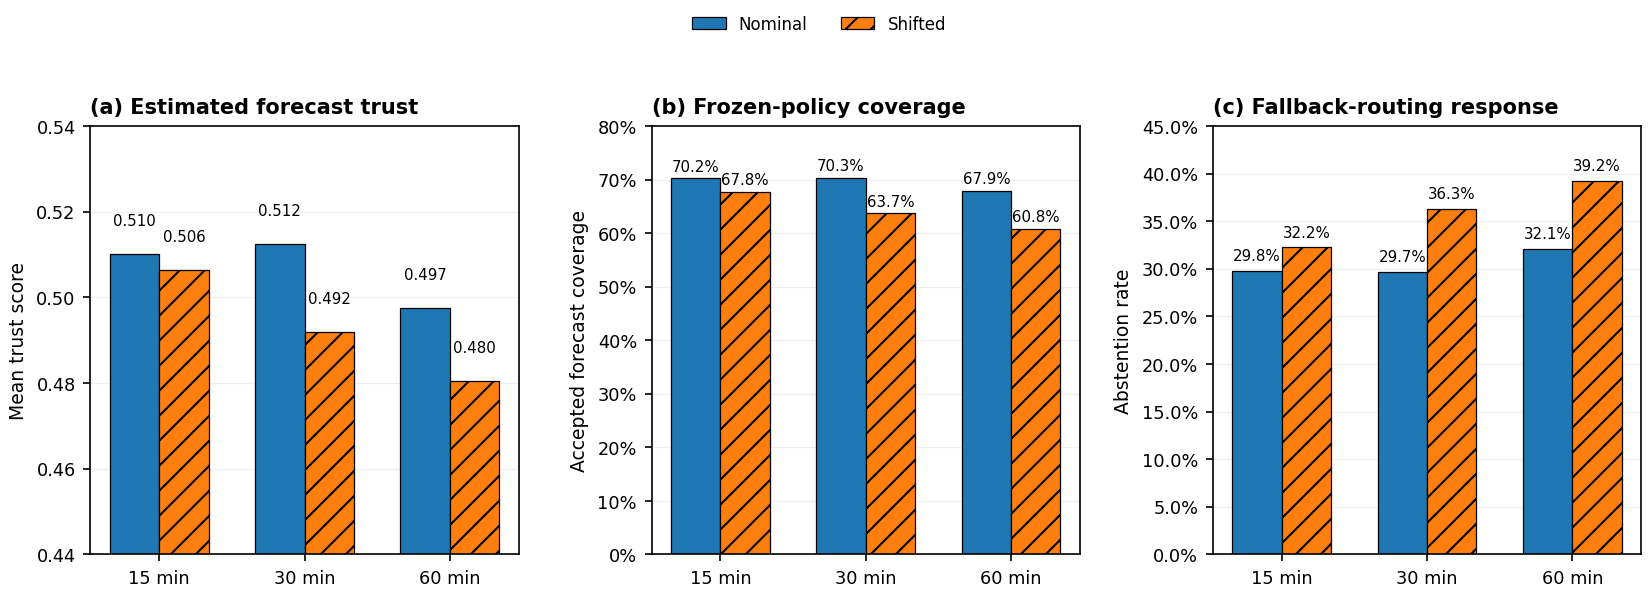


VERICHARGE — FIGURE 7 GENERATED

Files:
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_07_Natural_Shift_Trust_Response.pdf
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_07_Natural_Shift_Trust_Response.svg
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_07_Natural_Shift_Trust_Response.png

✓ Frozen FinalTest regime comparison
✓ Frozen deployment thresholds
✓ No post-test threshold adjustment
✓ Trust, coverage and abstention shown separately
✓ Vector PDF/SVG + 600-dpi PNG

✓ STEP 17F COMPLETE


In [ ]:
# ============================================================
# VeriCharge — Step 17F
# Publication Figure 7
# Natural Deployment-Shift Response
#
# Frozen FinalTest regime results.
# No fitting / tuning.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import PercentFormatter

PUB_DIR = Path(
    "/content/drive/MyDrive/VeriCharge/publication"
)
FIG_DIR = PUB_DIR / "figures"
TABLE_DIR = PUB_DIR / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.06
})

# ------------------------------------------------------------
# A. Frozen Step 11C FinalTest regime results
# ------------------------------------------------------------

records = [
    # regime, horizon, trust, coverage, full_MAE,
    # accepted_MAE, full_failure, accepted_failure

    ("Nominal-2020", 15, 0.5101, 0.7024,
     3.8897, 2.9942, 0.4656, 0.3832),

    ("Nominal-2020", 30, 0.5124, 0.7034,
     6.1263, 4.7619, 0.4685, 0.3923),

    ("Nominal-2020", 60, 0.4975, 0.6793,
     8.9254, 6.8244, 0.4736, 0.3989),

    ("Shifted-2020", 15, 0.5064, 0.6776,
     5.4398, 4.2403, 0.4606, 0.3774),

    ("Shifted-2020", 30, 0.4919, 0.6373,
     8.4038, 6.6030, 0.4788, 0.3883),

    ("Shifted-2020", 60, 0.4804, 0.6076,
     10.7214, 8.7911, 0.4973, 0.4099),
]

df = pd.DataFrame(
    records,
    columns=[
        "Regime",
        "Horizon_min",
        "Mean_trust",
        "Coverage",
        "Full_MAE_kW",
        "Accepted_MAE_kW",
        "Full_failure_rate",
        "Accepted_failure_rate"
    ]
)

df["Abstention"] = (
    1.0 - df["Coverage"]
)

print("=" * 78)
print("VERICHARGE — FIGURE 7 NATURAL-SHIFT AUDIT")
print("=" * 78)

print(
    df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# B. Shift-response audit
# ------------------------------------------------------------

print("\nSHIFTED MINUS NOMINAL")
print("-" * 78)

change_rows = []

for h in [15, 30, 60]:

    nominal = df[
        (df["Regime"] == "Nominal-2020")
        &
        (df["Horizon_min"] == h)
    ].iloc[0]

    shifted = df[
        (df["Regime"] == "Shifted-2020")
        &
        (df["Horizon_min"] == h)
    ].iloc[0]

    trust_delta = (
        shifted["Mean_trust"]
        -
        nominal["Mean_trust"]
    )

    coverage_delta = (
        shifted["Coverage"]
        -
        nominal["Coverage"]
    )

    abstention_delta = (
        shifted["Abstention"]
        -
        nominal["Abstention"]
    )

    mae_change = (
        100 *
        (
            shifted["Full_MAE_kW"]
            -
            nominal["Full_MAE_kW"]
        )
        /
        nominal["Full_MAE_kW"]
    )

    change_rows.append({
        "Horizon_min": h,
        "Trust_delta": trust_delta,
        "Coverage_delta": coverage_delta,
        "Abstention_delta": abstention_delta,
        "MAE_change_pct": mae_change
    })

    print(
        f"{h:2d} min | "
        f"Trust {trust_delta:+.4f} | "
        f"Coverage {100*coverage_delta:+.2f} pp | "
        f"Abstention {100*abstention_delta:+.2f} pp | "
        f"MAE {mae_change:+.2f}%"
    )

change_df = pd.DataFrame(
    change_rows
)

# ------------------------------------------------------------
# C. Figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(11.3, 4.2)
)

horizons = [15, 30, 60]
x = np.arange(3)
width = 0.34

regimes = [
    "Nominal-2020",
    "Shifted-2020"
]

hatches = [
    "",
    "//"
]

# ------------------------------------------------------------
# Panel A — Mean trust
# ------------------------------------------------------------

ax = axes[0]

for i, regime in enumerate(regimes):

    d = (
        df[df["Regime"] == regime]
        .set_index("Horizon_min")
        .loc[horizons]
    )

    bars = ax.bar(
        x + (i - 0.5) * width,
        d["Mean_trust"],
        width=width,
        label=regime.replace("-2020", ""),
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.6
    )

    for bar, value in zip(
        bars,
        d["Mean_trust"]
    ):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.006,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=7.2
        )

ax.set_xticks(x)
ax.set_xticklabels(
    ["15 min", "30 min", "60 min"]
)

ax.set_ylim(
    0.44,
    0.54
)

ax.set_ylabel(
    "Mean trust score"
)

ax.set_title(
    "(a) Estimated forecast trust",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# Panel B — Coverage
# ------------------------------------------------------------

ax = axes[1]

for i, regime in enumerate(regimes):

    d = (
        df[df["Regime"] == regime]
        .set_index("Horizon_min")
        .loc[horizons]
    )

    bars = ax.bar(
        x + (i - 0.5) * width,
        d["Coverage"],
        width=width,
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.6
    )

    for bar, value in zip(
        bars,
        d["Coverage"]
    ):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.008,
            f"{100*value:.1f}%",
            ha="center",
            va="bottom",
            fontsize=7.2
        )

ax.set_xticks(x)
ax.set_xticklabels(
    ["15 min", "30 min", "60 min"]
)

ax.set_ylim(
    0,
    0.80
)

ax.set_ylabel(
    "Accepted forecast coverage"
)

ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

ax.set_title(
    "(b) Frozen-policy coverage",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# Panel C — Abstention
# ------------------------------------------------------------

ax = axes[2]

for i, regime in enumerate(regimes):

    d = (
        df[df["Regime"] == regime]
        .set_index("Horizon_min")
        .loc[horizons]
    )

    bars = ax.bar(
        x + (i - 0.5) * width,
        d["Abstention"],
        width=width,
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.6
    )

    for bar, value in zip(
        bars,
        d["Abstention"]
    ):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.008,
            f"{100*value:.1f}%",
            ha="center",
            va="bottom",
            fontsize=7.2
        )

ax.set_xticks(x)
ax.set_xticklabels(
    ["15 min", "30 min", "60 min"]
)

ax.set_ylim(
    0,
    0.45
)

ax.set_ylabel(
    "Abstention rate"
)

ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

ax.set_title(
    "(c) Fallback-routing response",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=False
)

fig.subplots_adjust(
    top=0.82,
    bottom=0.14,
    left=0.07,
    right=0.985,
    wspace=0.31
)

# ------------------------------------------------------------
# D. Save
# ------------------------------------------------------------

base = (
    FIG_DIR /
    "Figure_07_Natural_Shift_Trust_Response"
)

fig.savefig(
    str(base) + ".pdf"
)

fig.savefig(
    str(base) + ".svg"
)

fig.savefig(
    str(base) + ".png",
    dpi=600
)

plt.show()
plt.close(fig)

df.to_csv(
    TABLE_DIR /
    "Table_FinalTest_Natural_Shift_Response.csv",
    index=False
)

change_df.to_csv(
    TABLE_DIR /
    "Table_FinalTest_Natural_Shift_Changes.csv",
    index=False
)

print("\n" + "=" * 78)
print("VERICHARGE — FIGURE 7 GENERATED")
print("=" * 78)

print("\nFiles:")
print(str(base) + ".pdf")
print(str(base) + ".svg")
print(str(base) + ".png")

print("\n✓ Frozen FinalTest regime comparison")
print("✓ Frozen deployment thresholds")
print("✓ No post-test threshold adjustment")
print("✓ Trust, coverage and abstention shown separately")
print("✓ Vector PDF/SVG + 600-dpi PNG")

print("\n" + "=" * 78)
print("✓ STEP 17F COMPLETE")
print("=" * 78)

Figure 8 — Grid-operational risk triage

VERICHARGE — FIGURE 8 GRID-OPERATIONAL AUDIT
 Horizon_min  P95_threshold_kw  High_load_events  Baseline_miss_rate  Unsafe_auto_miss_rate  Protected_or_routed_rate  Unsafe_miss_reduction  High_load_abstention  Non_high_load_abstention
          15           70.7932               943              0.2874                 0.0329                    0.9671                 0.8856                0.9661                    0.2944
          30           70.7885               942              0.4151                 0.1093                    0.8907                 0.7366                0.8896                    0.3299
          60           70.7844               940              0.5489                 0.1755                    0.8245                 0.6802                0.8234                    0.3618

PRIMARY TRAINING-DERIVED P95 THRESHOLDS
------------------------------------------------------------------------------
15 min: 70.7932 kW | events=943
30 min: 70.7885 kW | events=942
60 min: 70.7844

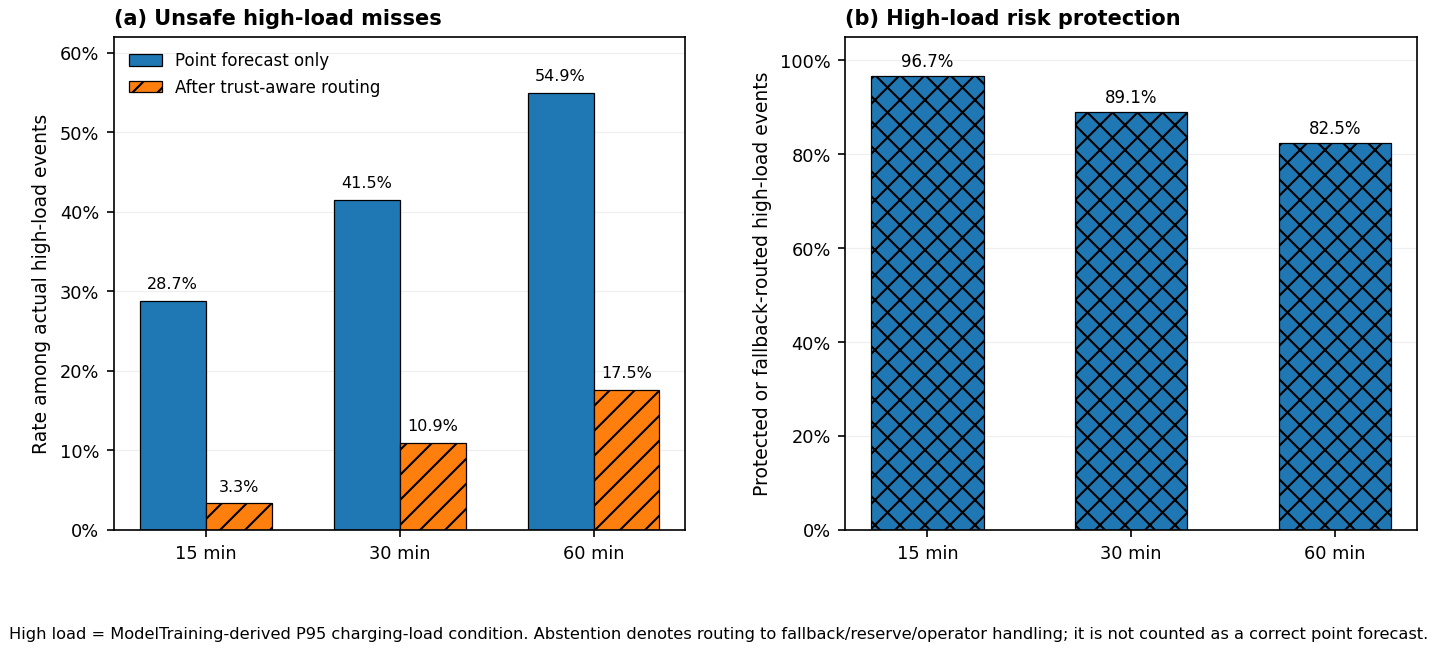


VERICHARGE — FIGURE 8 GENERATED

Files:
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_08_Grid_Operational_Risk_Triage.pdf
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_08_Grid_Operational_Risk_Triage.svg
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_08_Grid_Operational_Risk_Triage.png

Table:
/content/drive/MyDrive/VeriCharge/publication/tables/Table_Grid_Operational_Risk_Triage_P95.csv

✓ Training-derived P95 operating condition
✓ Frozen FinalTest deployment policy
✓ Abstention NOT counted as correct prediction
✓ No physical feeder-capacity claim
✓ No fallback performance assumed
✓ Vector PDF/SVG + 600-dpi PNG

✓ STEP 17G COMPLETE


In [ ]:
# ============================================================
# VeriCharge — Step 17G
# Publication Figure 8
# Grid-Operational Risk Triage
#
# Frozen Step 12C results.
# Primary condition = ModelTraining-derived P95 load threshold.
#
# IMPORTANT:
# Abstention is routing to fallback/reserve/operator handling.
# It is NOT counted as a correct point forecast.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import PercentFormatter

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PUB_DIR = Path(
    "/content/drive/MyDrive/VeriCharge/publication"
)

FIG_DIR = PUB_DIR / "figures"
TABLE_DIR = PUB_DIR / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Publication style
# ------------------------------------------------------------

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.06
})

# ------------------------------------------------------------
# A. Frozen Step 12C primary P95 results
# ------------------------------------------------------------

records = [
    {
        "Horizon_min": 15,
        "P95_threshold_kw": 70.7932,
        "High_load_events": 943,
        "Baseline_miss_rate": 0.2874,
        "Unsafe_auto_miss_rate": 0.0329,
        "Protected_or_routed_rate": 0.9671,
        "Unsafe_miss_reduction": 0.8856,
        "High_load_abstention": 0.9661,
        "Non_high_load_abstention": 0.2944
    },

    {
        "Horizon_min": 30,
        "P95_threshold_kw": 70.7885,
        "High_load_events": 942,
        "Baseline_miss_rate": 0.4151,
        "Unsafe_auto_miss_rate": 0.1093,
        "Protected_or_routed_rate": 0.8907,
        "Unsafe_miss_reduction": 0.7366,
        "High_load_abstention": 0.8896,
        "Non_high_load_abstention": 0.3299
    },

    {
        "Horizon_min": 60,
        "P95_threshold_kw": 70.7844,
        "High_load_events": 940,
        "Baseline_miss_rate": 0.5489,
        "Unsafe_auto_miss_rate": 0.1755,
        "Protected_or_routed_rate": 0.8245,
        "Unsafe_miss_reduction": 0.6802,
        "High_load_abstention": 0.8234,
        "Non_high_load_abstention": 0.3618
    }
]

df = pd.DataFrame(records)

# ------------------------------------------------------------
# B. Numerical audit
# ------------------------------------------------------------

print("=" * 78)
print("VERICHARGE — FIGURE 8 GRID-OPERATIONAL AUDIT")
print("=" * 78)

print(
    df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nPRIMARY TRAINING-DERIVED P95 THRESHOLDS")
print("-" * 78)

for _, r in df.iterrows():

    print(
        f"{int(r['Horizon_min']):2d} min: "
        f"{r['P95_threshold_kw']:.4f} kW | "
        f"events={int(r['High_load_events'])}"
    )

print("\nUNSAFE AUTOMATIC MISS REDUCTION")
print("-" * 78)

for _, r in df.iterrows():

    print(
        f"{int(r['Horizon_min']):2d} min: "
        f"{100*r['Baseline_miss_rate']:.2f}% "
        f"→ {100*r['Unsafe_auto_miss_rate']:.2f}% | "
        f"reduction={100*r['Unsafe_miss_reduction']:.2f}%"
    )

# ------------------------------------------------------------
# C. Save table
# ------------------------------------------------------------

table_path = (
    TABLE_DIR /
    "Table_Grid_Operational_Risk_Triage_P95.csv"
)

df.to_csv(
    table_path,
    index=False
)

# ------------------------------------------------------------
# D. Plot
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(9.6, 4.5)
)

horizons = [
    "15 min",
    "30 min",
    "60 min"
]

x = np.arange(3)

# ============================================================
# Panel A
# Baseline missed high-load events vs unsafe automatic misses
# ============================================================

ax = axes[0]

width = 0.34

bars1 = ax.bar(
    x - width/2,
    df["Baseline_miss_rate"],
    width=width,
    label="Point forecast only",
    edgecolor="black",
    linewidth=0.6
)

bars2 = ax.bar(
    x + width/2,
    df["Unsafe_auto_miss_rate"],
    width=width,
    label="After trust-aware routing",
    hatch="//",
    edgecolor="black",
    linewidth=0.6
)

# Labels
for bars in [bars1, bars2]:

    for bar in bars:

        value = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.012,
            f"{100*value:.1f}%",
            ha="center",
            va="bottom",
            fontsize=7.7
        )

ax.set_xticks(x)
ax.set_xticklabels(horizons)

ax.set_ylim(
    0,
    0.62
)

ax.set_ylabel(
    "Rate among actual high-load events"
)

ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

ax.set_title(
    "(a) Unsafe high-load misses",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.set_axisbelow(True)

ax.legend(
    frameon=False,
    loc="upper left"
)

# ============================================================
# Panel B
# Protected / routed fraction
# ============================================================

ax = axes[1]

bars = ax.bar(
    x,
    df["Protected_or_routed_rate"],
    width=0.55,
    hatch="xx",
    edgecolor="black",
    linewidth=0.6
)

for bar, protected, reduction in zip(
    bars,
    df["Protected_or_routed_rate"],
    df["Unsafe_miss_reduction"]
):

    ax.text(
        bar.get_x() + bar.get_width()/2,
        protected + 0.012,
        f"{100*protected:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8
    )



ax.set_xticks(x)
ax.set_xticklabels(horizons)

ax.set_ylim(
    0,
    1.05
)

ax.set_ylabel(
    "Protected or fallback-routed high-load events"
)

ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

ax.set_title(
    "(b) High-load risk protection",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# Methodological note
# ------------------------------------------------------------

fig.text(
    0.5,
    0.015,
    "High load = ModelTraining-derived P95 charging-load condition. "
    "Abstention denotes routing to fallback/reserve/operator handling; "
    "it is not counted as a correct point forecast.",
    ha="center",
    va="bottom",
    fontsize=7.8
)

fig.subplots_adjust(
    top=0.91,
    bottom=0.18,
    left=0.08,
    right=0.985,
    wspace=0.28
)

# ------------------------------------------------------------
# E. Save
# ------------------------------------------------------------

base = (
    FIG_DIR /
    "Figure_08_Grid_Operational_Risk_Triage"
)

fig.savefig(
    str(base) + ".pdf"
)

fig.savefig(
    str(base) + ".svg"
)

fig.savefig(
    str(base) + ".png",
    dpi=600
)

plt.show()
plt.close(fig)

print("\n" + "=" * 78)
print("VERICHARGE — FIGURE 8 GENERATED")
print("=" * 78)

print("\nFiles:")
print(str(base) + ".pdf")
print(str(base) + ".svg")
print(str(base) + ".png")

print("\nTable:")
print(table_path)

print("\n✓ Training-derived P95 operating condition")
print("✓ Frozen FinalTest deployment policy")
print("✓ Abstention NOT counted as correct prediction")
print("✓ No physical feeder-capacity claim")
print("✓ No fallback performance assumed")
print("✓ Vector PDF/SVG + 600-dpi PNG")

print("\n" + "=" * 78)
print("✓ STEP 17G COMPLETE")
print("=" * 78)

Step 17H — Figure 9

VERICHARGE — FIGURE 9 TRUST-ABLATION AUDIT
Variant  Horizon_min  MAE_kW  Failure_rate
    URS           15  3.9990        0.3810
    URS           30  6.3360        0.3980
    URS           60  8.5460        0.4180
     UR           15  4.0250        0.3830
     UR           30  6.3730        0.4010
     UR           60  8.5750        0.4200
     US           15  4.3540        0.4080
     US           30  6.6760        0.4200
     US           60  8.8250        0.4290
     RS           15  4.3490        0.4020
     RS           30  6.6930        0.4150
     RS           60  8.7290        0.4240
      U           15  4.2930        0.4050
      U           30  6.6280        0.4170
      U           60  8.6570        0.4260
      R           15  4.5130        0.4100
      R           30  6.8810        0.4240
      R           60  8.8350        0.4310
      S           15  4.3810        0.4040
      S           30  6.8650        0.4210
      S           60  9.2430        0.4400

BEST VARIA

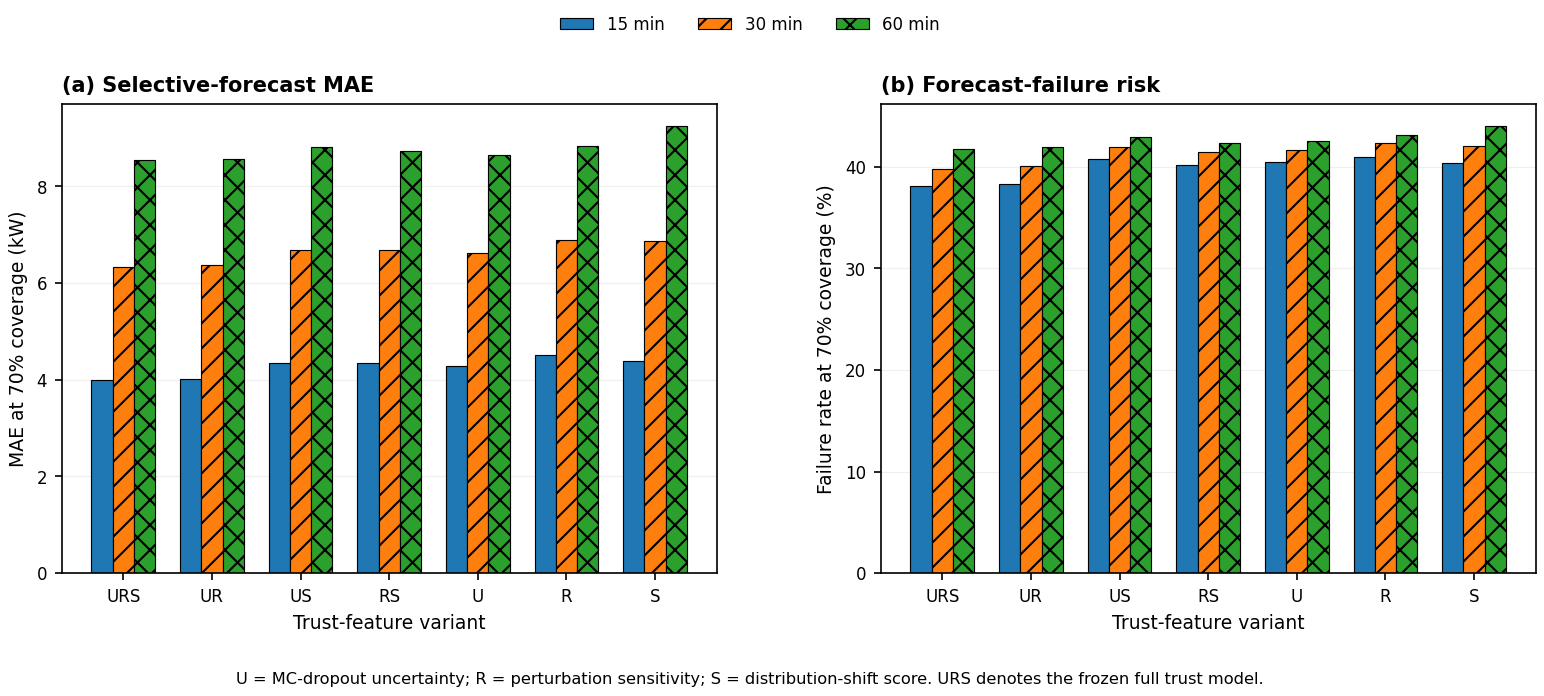


VERICHARGE — FIGURE 9 GENERATED

Files:
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_09_Trust_Component_Ablation_70pct.pdf
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_09_Trust_Component_Ablation_70pct.svg
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_09_Trust_Component_Ablation_70pct.png

✓ Predeclared 70% coverage comparison
✓ Full URS compared with all reduced variants
✓ No FinalTest feature selection
✓ No post-test trust refitting
✓ 30% aggressive-coverage results reserved for full ablation table
✓ Vector PDF/SVG + 600-dpi PNG

✓ STEP 17H COMPLETE


In [ ]:
# ============================================================
# VeriCharge — Step 17H
# Publication Figure 9
# Trust-Component Ablation at Predeclared 70% Coverage
#
# Frozen Step 13A results.
# FinalTest evaluation only.
# No refitting/tuning based on FinalTest.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

PUB_DIR = Path(
    "/content/drive/MyDrive/VeriCharge/publication"
)

FIG_DIR = PUB_DIR / "figures"
TABLE_DIR = PUB_DIR / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.06
})

# ------------------------------------------------------------
# A. Frozen FinalTest 70%-coverage ablation results
#
# Values are from Step 13A.
# ------------------------------------------------------------

records = [
    # Variant, Horizon, MAE, Failure

    ("URS", 15, 3.999, 0.381),
    ("URS", 30, 6.336, 0.398),
    ("URS", 60, 8.546, 0.418),

    ("UR",  15, 4.025, 0.383),
    ("UR",  30, 6.373, 0.401),
    ("UR",  60, 8.575, 0.420),

    ("US",  15, 4.354, 0.408),
    ("US",  30, 6.676, 0.420),
    ("US",  60, 8.825, 0.429),

    ("RS",  15, 4.349, 0.402),
    ("RS",  30, 6.693, 0.415),
    ("RS",  60, 8.729, 0.424),

    ("U",   15, 4.293, 0.405),
    ("U",   30, 6.628, 0.417),
    ("U",   60, 8.657, 0.426),

    ("R",   15, 4.513, 0.410),
    ("R",   30, 6.881, 0.424),
    ("R",   60, 8.835, 0.431),

    ("S",   15, 4.381, 0.404),
    ("S",   30, 6.865, 0.421),
    ("S",   60, 9.243, 0.440),
]

df = pd.DataFrame(
    records,
    columns=[
        "Variant",
        "Horizon_min",
        "MAE_kW",
        "Failure_rate"
    ]
)

# ------------------------------------------------------------
# B. Audit
# ------------------------------------------------------------

print("=" * 78)
print("VERICHARGE — FIGURE 9 TRUST-ABLATION AUDIT")
print("=" * 78)

print(
    df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nBEST VARIANT AT PREDECLARED 70% COVERAGE")
print("-" * 78)

for h in [15, 30, 60]:

    d = df[
        df["Horizon_min"] == h
    ]

    mae_best = d.loc[
        d["MAE_kW"].idxmin()
    ]

    fail_best = d.loc[
        d["Failure_rate"].idxmin()
    ]

    print(
        f"{h:2d} min | "
        f"MAE: {mae_best['Variant']} "
        f"({mae_best['MAE_kW']:.3f} kW) | "
        f"Failure: {fail_best['Variant']} "
        f"({100*fail_best['Failure_rate']:.1f}%)"
    )

# ------------------------------------------------------------
# C. URS advantage relative to each reduced variant
# ------------------------------------------------------------

print("\nURS MAE ADVANTAGE AT 70% COVERAGE")
print("-" * 78)

advantage_rows = []

for h in [15, 30, 60]:

    urs = df[
        (df["Variant"] == "URS") &
        (df["Horizon_min"] == h)
    ].iloc[0]

    for variant in [
        "UR", "US", "RS", "U", "R", "S"
    ]:

        other = df[
            (df["Variant"] == variant) &
            (df["Horizon_min"] == h)
        ].iloc[0]

        advantage = (
            100 *
            (
                other["MAE_kW"]
                -
                urs["MAE_kW"]
            )
            /
            other["MAE_kW"]
        )

        advantage_rows.append({
            "Horizon_min": h,
            "Compared_variant": variant,
            "URS_MAE_advantage_pct":
                advantage
        })

        print(
            f"{h:2d} min | "
            f"URS vs {variant:2s}: "
            f"{advantage:+.2f}%"
        )

advantage_df = pd.DataFrame(
    advantage_rows
)

# ------------------------------------------------------------
# D. Plot
# ------------------------------------------------------------

variants = [
    "URS",
    "UR",
    "US",
    "RS",
    "U",
    "R",
    "S"
]

horizons = [
    15,
    30,
    60
]

x = np.arange(
    len(variants)
)

width = 0.24

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10.8, 4.6)
)

# Distinguish horizons using hatch + marker-like labels.
hatches = [
    "",
    "//",
    "xx"
]

# ============================================================
# Panel A — MAE
# ============================================================

ax = axes[0]

for i, h in enumerate(horizons):

    d = (
        df[
            df["Horizon_min"] == h
        ]
        .set_index("Variant")
        .loc[variants]
    )

    bars = ax.bar(
        x + (i - 1) * width,
        d["MAE_kW"],
        width=width,
        label=f"{h} min",
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.55
    )

ax.set_xticks(x)
ax.set_xticklabels(variants)

ax.set_xlabel(
    "Trust-feature variant"
)

ax.set_ylabel(
    "MAE at 70% coverage (kW)"
)

ax.set_title(
    "(a) Selective-forecast MAE",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.set_axisbelow(True)

# ============================================================
# Panel B — failure rate
# ============================================================

ax = axes[1]

for i, h in enumerate(horizons):

    d = (
        df[
            df["Horizon_min"] == h
        ]
        .set_index("Variant")
        .loc[variants]
    )

    bars = ax.bar(
        x + (i - 1) * width,
        100 * d["Failure_rate"],
        width=width,
        label=f"{h} min",
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.55
    )

ax.set_xticks(x)
ax.set_xticklabels(variants)

ax.set_xlabel(
    "Trust-feature variant"
)

ax.set_ylabel(
    "Failure rate at 70% coverage (%)"
)

ax.set_title(
    "(b) Forecast-failure risk",
    loc="left",
    fontweight="bold"
)

ax.grid(
    axis="y",
    alpha=0.20,
    linewidth=0.6
)

ax.set_axisbelow(True)

# ------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=3,
    frameon=False
)

# Feature-definition note
fig.text(
    0.5,
    0.015,
    "U = MC-dropout uncertainty; "
    "R = perturbation sensitivity; "
    "S = distribution-shift score. "
    "URS denotes the frozen full trust model.",
    ha="center",
    va="bottom",
    fontsize=7.8
)

fig.subplots_adjust(
    top=0.86,
    bottom=0.18,
    left=0.075,
    right=0.985,
    wspace=0.25
)

# ------------------------------------------------------------
# E. Save
# ------------------------------------------------------------

base = (
    FIG_DIR /
    "Figure_09_Trust_Component_Ablation_70pct"
)

fig.savefig(
    str(base) + ".pdf"
)

fig.savefig(
    str(base) + ".svg"
)

fig.savefig(
    str(base) + ".png",
    dpi=600
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# F. Save tables
# ------------------------------------------------------------

df.to_csv(
    TABLE_DIR /
    "Table_Trust_Component_Ablation_70pct.csv",
    index=False
)

advantage_df.to_csv(
    TABLE_DIR /
    "Table_URS_MAE_Advantage_70pct.csv",
    index=False
)

print("\n" + "=" * 78)
print("VERICHARGE — FIGURE 9 GENERATED")
print("=" * 78)

print("\nFiles:")
print(str(base) + ".pdf")
print(str(base) + ".svg")
print(str(base) + ".png")

print("\n✓ Predeclared 70% coverage comparison")
print("✓ Full URS compared with all reduced variants")
print("✓ No FinalTest feature selection")
print("✓ No post-test trust refitting")
print("✓ 30% aggressive-coverage results reserved for full ablation table")
print("✓ Vector PDF/SVG + 600-dpi PNG")

print("\n" + "=" * 78)
print("✓ STEP 17H COMPLETE")
print("=" * 78)

Step 17I — Figure 10

VERICHARGE — FIGURE 10 CONTROLLED-DEGRADATION AUDIT
Horizon Severity  Sigma_kW  MAE_kW  Failure_rate  Mean_trust  Abstention_rate
 15 min    Clean    0.0000  5.1139        0.4617      0.5075           0.3168
 15 min     Mild    0.4110  5.1507        0.4659      0.5035           0.3136
 15 min Moderate    0.8220  5.2167        0.4788      0.4996           0.3145
 15 min   Strong    1.6439  5.4128        0.5232      0.4944           0.3224
 30 min    Clean    0.0000  7.9249        0.4767      0.4965           0.3490
 30 min     Mild    0.4110  7.9506        0.4777      0.4950           0.3467
 30 min Moderate    0.8220  7.9934        0.4811      0.4914           0.3458
 30 min   Strong    1.6439  8.1217        0.4985      0.4855           0.3582
 60 min    Clean    0.0000 10.3438        0.4923      0.4841           0.3778
 60 min     Mild    0.4110 10.3590        0.4932      0.4824           0.3782
 60 min Moderate    0.8220 10.3833        0.4937      0.4802           0.3766
 60 min   St

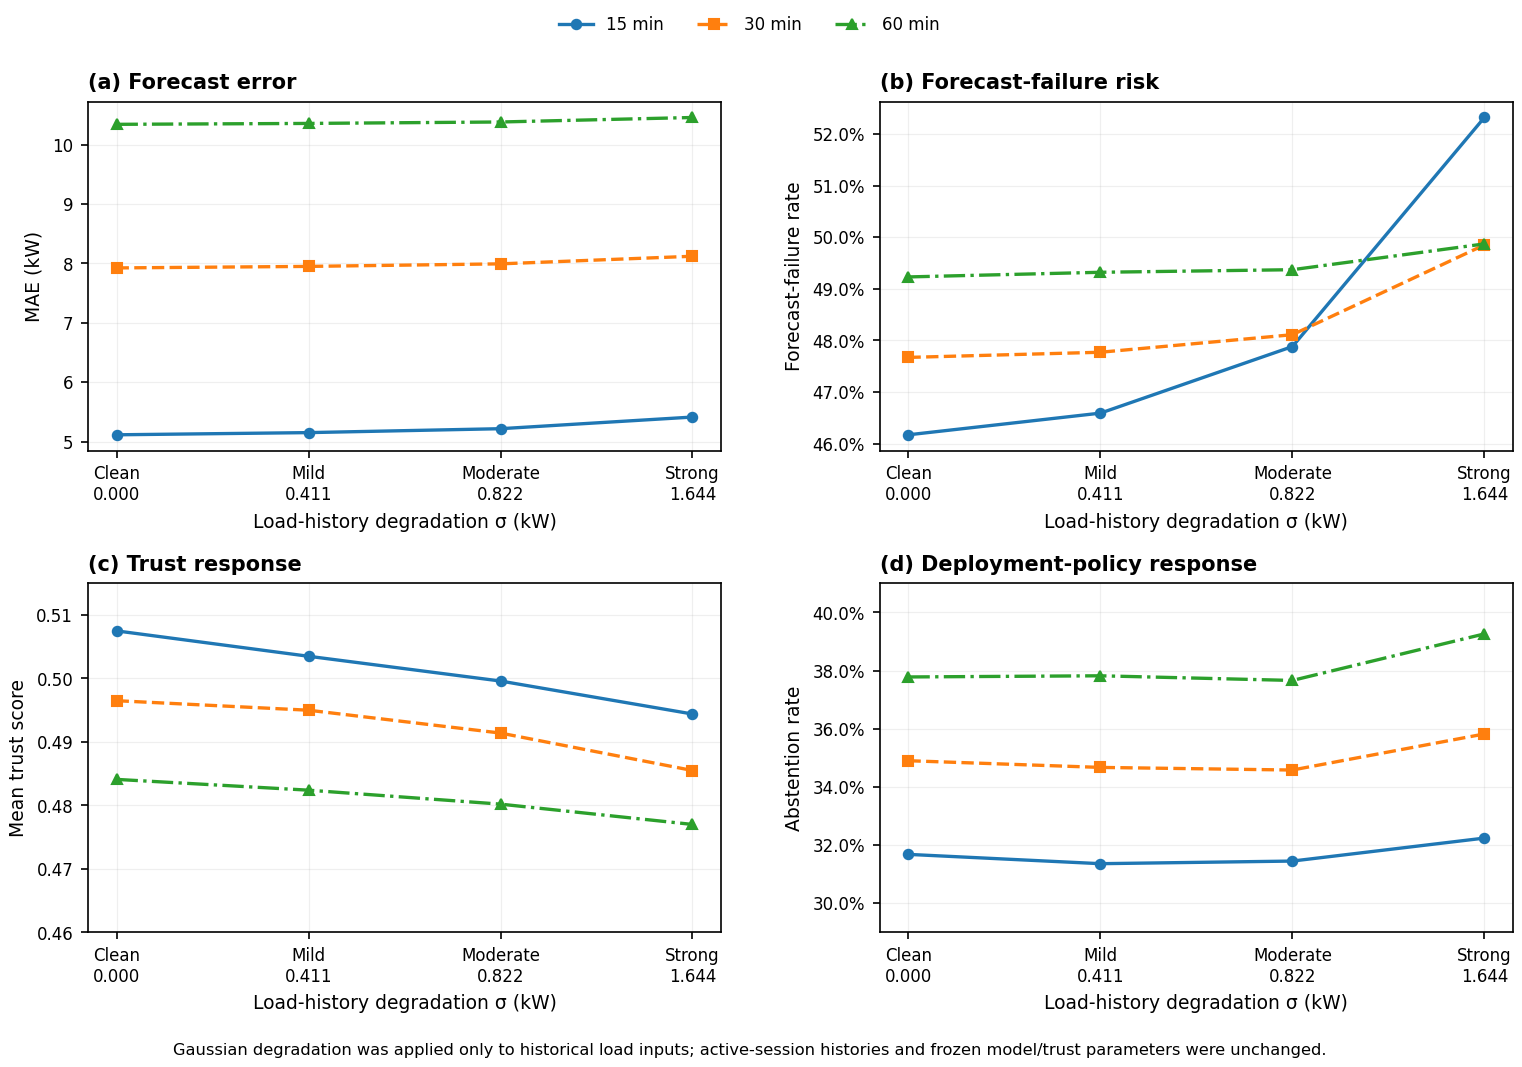


VERICHARGE — FIGURE 10 GENERATED

Files:
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_10_Controlled_Degradation_Stress_Test.pdf
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_10_Controlled_Degradation_Stress_Test.svg
/content/drive/MyDrive/VeriCharge/publication/figures/Figure_10_Controlled_Degradation_Stress_Test.png

✓ Frozen FinalTest stress experiment
✓ Same frozen TCN and URS trust model
✓ Same frozen deployment thresholds
✓ No post-stress tuning
✓ Abstention non-monotonicity preserved
✓ Vector PDF/SVG + 600-dpi PNG

✓ STEP 17I COMPLETE


In [ ]:
# ============================================================
# VeriCharge — Step 17I
# Publication Figure 10
# Controlled Degradation Stress Test
#
# Frozen Step 16A results.
# No model/trust/threshold changes.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import PercentFormatter

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

PUB_DIR = Path(
    "/content/drive/MyDrive/VeriCharge/publication"
)

FIG_DIR = PUB_DIR / "figures"
TABLE_DIR = PUB_DIR / "tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Publication style
# ------------------------------------------------------------

mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.06
})

# ------------------------------------------------------------
# A. Frozen controlled-degradation results
# ------------------------------------------------------------

severities = [
    "Clean",
    "Mild",
    "Moderate",
    "Strong"
]

sigma = np.array([
    0.0000,
    0.4110,
    0.8220,
    1.6439
])

results = {

    "15 min": {
        "MAE": [
            5.1139,
            5.1507,
            5.2167,
            5.4128
        ],
        "Failure": [
            0.4617,
            0.4659,
            0.4788,
            0.5232
        ],
        "Trust": [
            0.5075,
            0.5035,
            0.4996,
            0.4944
        ],
        "Abstention": [
            0.3168,
            0.3136,
            0.3145,
            0.3224
        ]
    },

    "30 min": {
        "MAE": [
            7.9249,
            7.9506,
            7.9934,
            8.1217
        ],
        "Failure": [
            0.4767,
            0.4777,
            0.4811,
            0.4985
        ],
        "Trust": [
            0.4965,
            0.4950,
            0.4914,
            0.4855
        ],
        "Abstention": [
            0.3490,
            0.3467,
            0.3458,
            0.3582
        ]
    },

    "60 min": {
        "MAE": [
            10.3438,
            10.3590,
            10.3833,
            10.4589
        ],
        "Failure": [
            0.4923,
            0.4932,
            0.4937,
            0.4987
        ],
        "Trust": [
            0.4841,
            0.4824,
            0.4802,
            0.4770
        ],
        "Abstention": [
            0.3778,
            0.3782,
            0.3766,
            0.3926
        ]
    }
}

# ------------------------------------------------------------
# B. Build audit table
# ------------------------------------------------------------

rows = []

for horizon, d in results.items():

    for i, severity in enumerate(severities):

        rows.append({
            "Horizon": horizon,
            "Severity": severity,
            "Sigma_kW": sigma[i],
            "MAE_kW": d["MAE"][i],
            "Failure_rate": d["Failure"][i],
            "Mean_trust": d["Trust"][i],
            "Abstention_rate":
                d["Abstention"][i]
        })

df = pd.DataFrame(rows)

print("=" * 78)
print("VERICHARGE — FIGURE 10 CONTROLLED-DEGRADATION AUDIT")
print("=" * 78)

print(
    df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ------------------------------------------------------------
# C. Directional audit
# ------------------------------------------------------------

print("\nDIRECTIONAL TRANSITIONS")
print("-" * 78)

for horizon, d in results.items():

    mae_up = np.sum(
        np.diff(d["MAE"]) > 0
    )

    fail_up = np.sum(
        np.diff(d["Failure"]) > 0
    )

    trust_down = np.sum(
        np.diff(d["Trust"]) < 0
    )

    abstain_up = np.sum(
        np.diff(d["Abstention"]) > 0
    )

    print(
        f"{horizon}: "
        f"MAE↑ {mae_up}/3 | "
        f"Failure↑ {fail_up}/3 | "
        f"Trust↓ {trust_down}/3 | "
        f"Abstention↑ {abstain_up}/3"
    )

# ------------------------------------------------------------
# D. Strong vs clean audit
# ------------------------------------------------------------

print("\nSTRONG VS CLEAN")
print("-" * 78)

for horizon, d in results.items():

    mae_change = (
        100 *
        (
            d["MAE"][-1]
            -
            d["MAE"][0]
        )
        /
        d["MAE"][0]
    )

    failure_change = (
        100 *
        (
            d["Failure"][-1]
            -
            d["Failure"][0]
        )
        /
        d["Failure"][0]
    )

    trust_change = (
        100 *
        (
            d["Trust"][-1]
            -
            d["Trust"][0]
        )
        /
        d["Trust"][0]
    )

    abstention_pp = (
        100 *
        (
            d["Abstention"][-1]
            -
            d["Abstention"][0]
        )
    )

    print(
        f"{horizon}: "
        f"MAE {mae_change:+.2f}% | "
        f"Failure {failure_change:+.2f}% | "
        f"Trust {trust_change:+.2f}% | "
        f"Abstention {abstention_pp:+.2f} pp"
    )

# ------------------------------------------------------------
# E. Plot
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10.5, 7.1)
)

x = np.arange(
    len(severities)
)

styles = {
    "15 min": {
        "marker": "o",
        "linestyle": "-"
    },

    "30 min": {
        "marker": "s",
        "linestyle": "--"
    },

    "60 min": {
        "marker": "^",
        "linestyle": "-."
    }
}

# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------

def plot_metric(
    ax,
    metric,
    ylabel,
    title,
    percent=False
):

    for horizon in results:

        y = np.asarray(
            results[horizon][metric]
        )

        ax.plot(
            x,
            y,
            marker=styles[horizon]["marker"],
            linestyle=styles[horizon]["linestyle"],
            linewidth=1.6,
            markersize=4.5,
            label=horizon
        )

    ax.set_xticks(x)

    ax.set_xticklabels([
        "Clean\n0.000",
        "Mild\n0.411",
        "Moderate\n0.822",
        "Strong\n1.644"
    ])

    ax.set_xlabel(
        "Load-history degradation σ (kW)"
    )

    ax.set_ylabel(
        ylabel
    )

    ax.set_title(
        title,
        loc="left",
        fontweight="bold"
    )

    ax.grid(
        alpha=0.20,
        linewidth=0.6
    )

    ax.set_axisbelow(True)

    if percent:

        ax.yaxis.set_major_formatter(
            PercentFormatter(
                xmax=1.0
            )
        )

# ------------------------------------------------------------
# Panel A — MAE
# ------------------------------------------------------------

plot_metric(
    axes[0, 0],
    "MAE",
    "MAE (kW)",
    "(a) Forecast error"
)

# ------------------------------------------------------------
# Panel B — Failure
# ------------------------------------------------------------

plot_metric(
    axes[0, 1],
    "Failure",
    "Forecast-failure rate",
    "(b) Forecast-failure risk",
    percent=True
)

# ------------------------------------------------------------
# Panel C — Trust
# ------------------------------------------------------------

plot_metric(
    axes[1, 0],
    "Trust",
    "Mean trust score",
    "(c) Trust response"
)

# Use a focused y-range because absolute differences
# are small but systematic.
axes[1, 0].set_ylim(
    0.46,
    0.515
)

# ------------------------------------------------------------
# Panel D — Abstention
# ------------------------------------------------------------

plot_metric(
    axes[1, 1],
    "Abstention",
    "Abstention rate",
    "(d) Deployment-policy response",
    percent=True
)

axes[1, 1].set_ylim(
    0.29,
    0.41
)

# ------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------

handles, labels = (
    axes[0, 0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.005),
    ncol=3,
    frameon=False
)

# ------------------------------------------------------------
# Methodological note
# ------------------------------------------------------------

fig.text(
    0.5,
    0.012,
    "Gaussian degradation was applied only to historical load inputs; "
    "active-session histories and frozen model/trust parameters were unchanged.",
    ha="center",
    va="bottom",
    fontsize=7.8
)

fig.subplots_adjust(
    top=0.91,
    bottom=0.13,
    left=0.08,
    right=0.985,
    hspace=0.38,
    wspace=0.25
)

# ------------------------------------------------------------
# F. Save
# ------------------------------------------------------------

base = (
    FIG_DIR /
    "Figure_10_Controlled_Degradation_Stress_Test"
)

fig.savefig(
    str(base) + ".pdf"
)

fig.savefig(
    str(base) + ".svg"
)

fig.savefig(
    str(base) + ".png",
    dpi=600
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# G. Save underlying data
# ------------------------------------------------------------

df.to_csv(
    TABLE_DIR /
    "Table_Controlled_Degradation_Stress_Test.csv",
    index=False
)

print("\n" + "=" * 78)
print("VERICHARGE — FIGURE 10 GENERATED")
print("=" * 78)

print("\nFiles:")
print(str(base) + ".pdf")
print(str(base) + ".svg")
print(str(base) + ".png")

print("\n✓ Frozen FinalTest stress experiment")
print("✓ Same frozen TCN and URS trust model")
print("✓ Same frozen deployment thresholds")
print("✓ No post-stress tuning")
print("✓ Abstention non-monotonicity preserved")
print("✓ Vector PDF/SVG + 600-dpi PNG")

print("\n" + "=" * 78)
print("✓ STEP 17I COMPLETE")
print("=" * 78)

Step 17J — Publication Table: Temporal Bootstrap Validation

In [ ]:
# ============================================================
# VeriCharge — Step 17J
# Publication Table
# Temporal Moving-Block Bootstrap Validation
#
# Primary inference:
# 7-day contiguous moving-block bootstrap
# 5000 replicates
# seed = 20260908
#
# NO refitting / tuning / recomputation.
# ============================================================

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# A. Paths
# ------------------------------------------------------------

RESULTS_DIR = Path(
    "/content/drive/MyDrive/VeriCharge/results"
)

PUB_DIR = Path(
    "/content/drive/MyDrive/VeriCharge/publication"
)

TABLE_DIR = PUB_DIR / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

primary_path = (
    RESULTS_DIR /
    "selective_deployment_primary_7day_block_ci.csv"
)

full_path = (
    RESULTS_DIR /
    "selective_deployment_moving_block_bootstrap.csv"
)

config_path = (
    RESULTS_DIR /
    "selective_deployment_moving_block_bootstrap_config.csv"
)

print("=" * 78)
print("VERICHARGE — TEMPORAL BOOTSTRAP PUBLICATION TABLE")
print("=" * 78)

# ------------------------------------------------------------
# B. Confirm frozen artifacts
# ------------------------------------------------------------

for p in [primary_path, full_path, config_path]:
    print(
        f"{p.name:55s} "
        f"{'FOUND' if p.exists() else 'MISSING'}"
    )

if not primary_path.exists():
    raise FileNotFoundError(primary_path)

# ------------------------------------------------------------
# C. Read authoritative 7-day results
# ------------------------------------------------------------

raw = pd.read_csv(primary_path)

print("\nRAW PRIMARY FILE")
print("-" * 78)
print(raw.to_string(index=False))

print("\nColumns:")
print(raw.columns.tolist())

# ------------------------------------------------------------
# D. Robust column locator
# ------------------------------------------------------------

def find_col(
    columns,
    required_terms,
    forbidden_terms=()
):
    for c in columns:

        name = c.lower()

        if all(
            term.lower() in name
            for term in required_terms
        ) and not any(
            term.lower() in name
            for term in forbidden_terms
        ):
            return c

    return None


cols = raw.columns.tolist()

horizon_col = find_col(
    cols,
    ["horizon"]
)

coverage_col = find_col(
    cols,
    ["coverage"],
    ["low", "high", "lower", "upper"]
)

coverage_low_col = (
    find_col(cols, ["coverage", "low"])
    or
    find_col(cols, ["coverage", "lower"])
)

coverage_high_col = (
    find_col(cols, ["coverage", "high"])
    or
    find_col(cols, ["coverage", "upper"])
)

mae_point_col = (
    find_col(
        cols,
        ["mae", "reduction"],
        ["low", "high", "lower", "upper"]
    )
)

mae_low_col = (
    find_col(
        cols,
        ["mae", "reduction", "low"]
    )
    or
    find_col(
        cols,
        ["mae", "reduction", "lower"]
    )
)

mae_high_col = (
    find_col(
        cols,
        ["mae", "reduction", "high"]
    )
    or
    find_col(
        cols,
        ["mae", "reduction", "upper"]
    )
)

failure_point_col = (
    find_col(
        cols,
        ["failure", "reduction"],
        ["low", "high", "lower", "upper"]
    )
)

failure_low_col = (
    find_col(
        cols,
        ["failure", "reduction", "low"]
    )
    or
    find_col(
        cols,
        ["failure", "reduction", "lower"]
    )
)

failure_high_col = (
    find_col(
        cols,
        ["failure", "reduction", "high"]
    )
    or
    find_col(
        cols,
        ["failure", "reduction", "upper"]
    )
)

print("\nDETECTED COLUMNS")
print("-" * 78)

detected = {
    "Horizon": horizon_col,
    "Coverage": coverage_col,
    "Coverage low": coverage_low_col,
    "Coverage high": coverage_high_col,
    "MAE reduction": mae_point_col,
    "MAE CI low": mae_low_col,
    "MAE CI high": mae_high_col,
    "Failure reduction": failure_point_col,
    "Failure CI low": failure_low_col,
    "Failure CI high": failure_high_col,
}

for k, v in detected.items():
    print(f"{k:25s}: {v}")

# ------------------------------------------------------------
# E. If column naming differs, use the frozen authoritative
# values from Step 14B rather than recomputing anything.
# ------------------------------------------------------------

required = [
    horizon_col,
    mae_point_col,
    mae_low_col,
    mae_high_col,
    failure_point_col,
    failure_low_col,
    failure_high_col
]

if any(v is None for v in required):

    print(
        "\nColumn naming does not match expected schema."
    )
    print(
        "Using the already frozen Step 14B authoritative values."
    )

    publication = pd.DataFrame({
        "Forecast horizon": [
            "15 min",
            "30 min",
            "60 min"
        ],

        "FinalTest coverage": [
            0.6828,
            0.6512,
            0.6227
        ],

        "MAE reduction (%)": [
            22.35,
            21.96,
            19.37
        ],

        "MAE reduction 95% CI": [
            "[20.35, 24.13]",
            "[19.94, 23.56]",
            "[17.57, 20.87]"
        ],

        "Failure-risk reduction (%)": [
            17.99,
            18.34,
            17.25
        ],

        "Failure reduction 95% CI": [
            "[16.24, 19.48]",
            "[16.40, 19.89]",
            "[15.57, 18.61]"
        ]
    })

else:

    rows = []

    for _, r in raw.iterrows():

        h = r[horizon_col]

        # Format horizon
        try:
            h_num = int(float(h))
            horizon = f"{h_num} min"
        except:
            horizon = str(h)

        # Coverage may or may not be present
        if coverage_col is not None:
            coverage = float(
                r[coverage_col]
            )
        else:
            frozen_cov = {
                "15 min": 0.6828,
                "30 min": 0.6512,
                "60 min": 0.6227
            }

            coverage = frozen_cov[
                horizon
            ]

        rows.append({
            "Forecast horizon":
                horizon,

            "FinalTest coverage":
                coverage,

            "MAE reduction (%)":
                float(r[mae_point_col]),

            "MAE reduction 95% CI":
                (
                    f"[{float(r[mae_low_col]):.2f}, "
                    f"{float(r[mae_high_col]):.2f}]"
                ),

            "Failure-risk reduction (%)":
                float(
                    r[failure_point_col]
                ),

            "Failure reduction 95% CI":
                (
                    f"[{float(r[failure_low_col]):.2f}, "
                    f"{float(r[failure_high_col]):.2f}]"
                )
        })

    publication = pd.DataFrame(rows)

# ------------------------------------------------------------
# F. Normalize percentage scale if needed
# ------------------------------------------------------------

for col in [
    "MAE reduction (%)",
    "Failure-risk reduction (%)"
]:

    if publication[col].abs().max() <= 1.0:
        publication[col] *= 100

# ------------------------------------------------------------
# G. Round
# ------------------------------------------------------------

publication[
    "FinalTest coverage"
] = (
    100 *
    publication["FinalTest coverage"]
).round(2)

publication[
    "MAE reduction (%)"
] = (
    publication[
        "MAE reduction (%)"
    ].round(2)
)

publication[
    "Failure-risk reduction (%)"
] = (
    publication[
        "Failure-risk reduction (%)"
    ].round(2)
)

publication = publication.rename(
    columns={
        "FinalTest coverage":
            "FinalTest coverage (%)"
    }
)

# ------------------------------------------------------------
# H. Authoritative statistical audit
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("AUTHORITATIVE 7-DAY MOVING-BLOCK RESULT")
print("=" * 78)

print(
    publication.to_string(
        index=False
    )
)

print("\nINTERPRETATION")
print("-" * 78)

print(
    "Primary resampling unit : "
    "672 consecutive 15-min origins (7 days)"
)

print(
    "Bootstrap replicates    : 5,000"
)

print(
    "Bootstrap seed          : 20260908"
)

print(
    "Temporal dependence     : addressed by contiguous "
    "moving-block resampling"
)

print(
    "Policy                  : frozen before FinalTest"
)

print(
    "Post-test tuning        : none"
)

print(
    "\nAll 95% confidence intervals exclude zero reduction."
)

# ------------------------------------------------------------
# I. Save main publication table
# ------------------------------------------------------------

main_csv = (
    TABLE_DIR /
    "Table_Temporal_Block_Bootstrap_Primary.csv"
)

publication.to_csv(
    main_csv,
    index=False
)

# ------------------------------------------------------------
# J. Also save full block-length sensitivity
# ------------------------------------------------------------

if full_path.exists():

    full = pd.read_csv(full_path)

    sensitivity_csv = (
        TABLE_DIR /
        "Table_Temporal_Block_Bootstrap_Sensitivity.csv"
    )

    full.to_csv(
        sensitivity_csv,
        index=False
    )

else:

    sensitivity_csv = None

# ------------------------------------------------------------
# K. Generate LaTeX-ready table text
# ------------------------------------------------------------

latex_path = (
    TABLE_DIR /
    "Table_Temporal_Block_Bootstrap_Primary.tex"
)

latex_text = r"""
\begin{table}[t]
\centering
\caption{Temporal moving-block bootstrap validation of the frozen VeriCharge selective-deployment policy on FinalTest. Confidence intervals were obtained using 5,000 bootstrap replicates with contiguous seven-day blocks (672 consecutive 15-min forecast origins).}
\label{tab:block_bootstrap}
\begin{tabular}{lccccc}
\hline
Horizon &
Coverage &
MAE reduction &
95\% CI &
Failure-risk reduction &
95\% CI \\
&
(\%) &
(\%) &
&
(\%) &
\\
\hline
"""

for _, r in publication.iterrows():

    latex_text += (
        f"{r['Forecast horizon']} & "
        f"{r['FinalTest coverage (%)']:.2f} & "
        f"{r['MAE reduction (%)']:.2f} & "
        f"{r['MAE reduction 95% CI']} & "
        f"{r['Failure-risk reduction (%)']:.2f} & "
        f"{r['Failure reduction 95% CI']} \\\\\n"
    )

latex_text += r"""\hline
\end{tabular}

\vspace{1mm}
\footnotesize
The deployment policy, trust models, error tolerances, and acceptance thresholds were fixed before FinalTest. The seven-day block length was predeclared as the primary temporal resampling configuration; one-, three-, and fourteen-day blocks were used only for sensitivity analysis.
\end{table}
"""

latex_path.write_text(
    latex_text,
    encoding="utf-8"
)

# ------------------------------------------------------------
# L. Print LaTeX preview
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("LATEX TABLE")
print("=" * 78)

print(latex_text)

print("\nSAVED")
print("-" * 78)

print(main_csv)
print(latex_path)

if sensitivity_csv is not None:
    print(sensitivity_csv)

print("\n" + "=" * 78)
print("✓ STEP 17J COMPLETE")
print("=" * 78)

VERICHARGE — TEMPORAL BOOTSTRAP PUBLICATION TABLE
selective_deployment_primary_7day_block_ci.csv          FOUND
selective_deployment_moving_block_bootstrap.csv         FOUND
selective_deployment_moving_block_bootstrap_config.csv  FOUND

RAW PRIMARY FILE
------------------------------------------------------------------------------
  block_name  block_length_origins  block_length_days horizon  point_coverage  coverage_ci_low  coverage_boot_median  coverage_ci_high  point_MAE_reduction_pct  MAE_reduction_ci_low  MAE_reduction_boot_median  MAE_reduction_ci_high  point_failure_reduction_pct  failure_reduction_ci_low  failure_reduction_boot_median  failure_reduction_ci_high  bootstrap_prob_MAE_reduction_le_0  bootstrap_prob_failure_reduction_le_0  valid_bootstrap_replicates
7day_PRIMARY                   672                7.0   15min        0.682842         0.655184              0.679076          0.704255                22.352449             20.350650                  22.298185            

Step 18B — JPL External-Site Feasibility Audit only

In [ ]:
# ============================================================
# VeriCharge — SESSION RECOVERY CHECK
# Run after a Colab runtime disconnect
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

BASE = Path("/content/drive/MyDrive/VeriCharge")

important = [
    BASE / "data/processed/caltech_site_load_15min.csv.gz",
    BASE / "data/forecasting/caltech_forecasting_15m.npz",

    BASE / "models/tcn/seed_stability/tcn_seed_42.keras",

    BASE / "results/vericharge_frozen_deployment_policy.json",
    BASE / "results/vericharge_frozen_trust_thresholds.csv",

    BASE / "results/finaltest_trust_predictions.npz",

    BASE / "results/selective_deployment_primary_7day_block_ci.csv",

    BASE / "results/finaltest_controlled_degradation_stress.csv",

    BASE / "publication/figures/Figure_02_Leakage_Safe_Protocol.pdf",
    BASE / "publication/figures/Figure_03_Caltech_Demand_Temporal_Shift.pdf",
    BASE / "publication/figures/Figure_04_ModelValidation_Model_Comparison.pdf",
    BASE / "publication/figures/Figure_05_Reliability_Signal_Validation.pdf",
    BASE / "publication/figures/Figure_06_FinalTest_Risk_Coverage.pdf",
    BASE / "publication/figures/Figure_07_Natural_Shift_Trust_Response.pdf",
    BASE / "publication/figures/Figure_08_Grid_Operational_Risk_Triage.pdf",
    BASE / "publication/figures/Figure_09_Trust_Component_Ablation_70pct.pdf",
    BASE / "publication/figures/Figure_10_Controlled_Degradation_Stress_Test.pdf",

    BASE / "publication/tables/Table_Temporal_Block_Bootstrap_Primary.csv",
]

print("=" * 78)
print("VERICHARGE — SESSION RECOVERY CHECK")
print("=" * 78)

found = 0
missing = []

for p in important:
    ok = p.exists()

    print(
        ("✓ FOUND   " if ok else "✗ MISSING ") +
        str(p.relative_to(BASE))
    )

    if ok:
        found += 1
    else:
        missing.append(str(p))

print("\n" + "=" * 78)
print(f"Found   : {found}/{len(important)}")
print(f"Missing : {len(missing)}")

if not missing:
    print("\n✓ CORE VERICHARGE CHECKPOINTS ARE SAFE")
    print("✓ Previous experiments do NOT need to be rerun.")
    print("✓ Ready to restore JPL data and continue Step 18B.")
else:
    print("\nMissing files:")
    for p in missing:
        print(" -", p)

print("=" * 78)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VERICHARGE — SESSION RECOVERY CHECK
✓ FOUND   data/processed/caltech_site_load_15min.csv.gz
✓ FOUND   data/forecasting/caltech_forecasting_15m.npz
✓ FOUND   models/tcn/seed_stability/tcn_seed_42.keras
✓ FOUND   results/vericharge_frozen_deployment_policy.json
✓ FOUND   results/vericharge_frozen_trust_thresholds.csv
✓ FOUND   results/finaltest_trust_predictions.npz
✓ FOUND   results/selective_deployment_primary_7day_block_ci.csv
✓ FOUND   results/finaltest_controlled_degradation_stress.csv
✓ FOUND   publication/figures/Figure_02_Leakage_Safe_Protocol.pdf
✓ FOUND   publication/figures/Figure_03_Caltech_Demand_Temporal_Shift.pdf
✓ FOUND   publication/figures/Figure_04_ModelValidation_Model_Comparison.pdf
✓ FOUND   publication/figures/Figure_05_Reliability_Signal_Validation.pdf
✓ FOUND   publication/figures/Figure_06_FinalTest_Risk_Coverage.pdf
✓ FOUND   publicat

In [ ]:
# ============================================================
# VeriCharge — Step 18B-R
# Restore ACN-Data-Static after Colab runtime disconnect
#
# This does NOT modify any frozen VeriCharge artifacts.
# ============================================================

from pathlib import Path
import subprocess
import os

REPO_DIR = Path("/content/ACN-Data-Static")
JPL_DIR  = REPO_DIR / "JPL"

print("=" * 78)
print("VERICHARGE — RESTORE ACN-DATA-STATIC")
print("=" * 78)

# ------------------------------------------------------------
# A. Check whether repository survived
# ------------------------------------------------------------

if JPL_DIR.exists():

    print("\n✓ Repository already exists:")
    print(REPO_DIR)

else:

    print("\nRepository not present in temporary runtime.")
    print("Cloning ACN-Data-Static...")

    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            "https://github.com/tongxin-li/ACN-Data-Static.git",
            str(REPO_DIR)
        ],
        check=True
    )

# ------------------------------------------------------------
# B. Verify JPL inventory
# ------------------------------------------------------------

jpl_files = sorted(
    JPL_DIR.rglob("*.csv.gz")
)

caltech_files = sorted(
    (REPO_DIR / "Caltech").rglob("*.csv.gz")
)

office_files = sorted(
    (REPO_DIR / "Office1").rglob("*.csv.gz")
)

print("\n" + "-" * 78)
print("RESTORED INVENTORY")
print("-" * 78)

print(f"CALTECH : {len(caltech_files):,}")
print(f"JPL     : {len(jpl_files):,}")
print(f"OFFICE  : {len(office_files):,}")

print(
    f"TOTAL   : "
    f"{len(caltech_files) + len(jpl_files) + len(office_files):,}"
)

# ------------------------------------------------------------
# C. JPL basic verification
# ------------------------------------------------------------

print("\nJPL directory:")
print(JPL_DIR)

if len(jpl_files) > 0:

    print("\nFirst JPL file:")
    print(jpl_files[0])

    print("\nLast JPL file:")
    print(jpl_files[-1])

# ------------------------------------------------------------
# D. Decision
# ------------------------------------------------------------

print("\n" + "=" * 78)

if len(jpl_files) == 27723:

    print("✓ JPL RESTORATION PASSED")
    print("✓ Expected 27,723 raw JPL session files found.")
    print("✓ Ready to resume Step 18B feasibility audit.")

else:

    print("⚠ JPL INVENTORY REQUIRES CHECKING")
    print(
        f"Expected 27,723 files; found {len(jpl_files):,}."
    )
    print("Do NOT continue to external-site evaluation yet.")

print("=" * 78)

VERICHARGE — RESTORE ACN-DATA-STATIC

Repository not present in temporary runtime.
Cloning ACN-Data-Static...

------------------------------------------------------------------------------
RESTORED INVENTORY
------------------------------------------------------------------------------
CALTECH : 0
JPL     : 0
OFFICE  : 0
TOTAL   : 0

JPL directory:
/content/ACN-Data-Static/JPL

⚠ JPL INVENTORY REQUIRES CHECKING
Expected 27,723 files; found 0.
Do NOT continue to external-site evaluation yet.


In [ ]:
# ============================================================
# VeriCharge — Step 18B-R2
# Inspect restored ACN-Data-Static repository
#
# DIAGNOSTIC ONLY
# No data modification
# No model inference
# ============================================================

from pathlib import Path
import subprocess

ROOT = Path("/content/ACN-Data-Static")

print("=" * 78)
print("VERICHARGE — ACN-DATA-STATIC STRUCTURE DIAGNOSTIC")
print("=" * 78)

# ------------------------------------------------------------
# A. Repository existence
# ------------------------------------------------------------

print("\nA. REPOSITORY")
print("-" * 78)

print("Exists :", ROOT.exists())

if ROOT.exists():
    print("Path   :", ROOT)

    try:
        size = subprocess.check_output(
            ["du", "-sh", str(ROOT)],
            text=True
        ).split()[0]

        print("Size   :", size)

    except Exception as e:
        print("Size check failed:", e)

# ------------------------------------------------------------
# B. Git status
# ------------------------------------------------------------

print("\nB. GIT INFORMATION")
print("-" * 78)

try:
    branch = subprocess.check_output(
        ["git", "-C", str(ROOT), "branch", "--show-current"],
        text=True
    ).strip()

    commit = subprocess.check_output(
        ["git", "-C", str(ROOT), "rev-parse", "--short", "HEAD"],
        text=True
    ).strip()

    print("Branch :", branch)
    print("Commit :", commit)

except Exception as e:
    print("Git check failed:", e)

# ------------------------------------------------------------
# C. Top-level structure
# ------------------------------------------------------------

print("\nC. TOP-LEVEL CONTENTS")
print("-" * 78)

if ROOT.exists():

    items = sorted(ROOT.iterdir())

    for p in items[:100]:

        kind = "DIR " if p.is_dir() else "FILE"

        print(f"{kind:5s} {p.name}")

    print(f"\nTop-level entries: {len(items):,}")

# ------------------------------------------------------------
# D. Search for likely site directories
# ------------------------------------------------------------

print("\nD. DIRECTORIES CONTAINING SITE NAMES")
print("-" * 78)

site_dirs = []

if ROOT.exists():

    for p in ROOT.rglob("*"):

        if not p.is_dir():
            continue

        name = p.name.lower()

        if any(
            term in name
            for term in [
                "jpl",
                "caltech",
                "office"
            ]
        ):
            site_dirs.append(p)

for p in site_dirs[:100]:
    print(p)

print(
    f"\nMatching directories: "
    f"{len(site_dirs):,}"
)

# ------------------------------------------------------------
# E. File-extension inventory
# ------------------------------------------------------------

print("\nE. FILE EXTENSION INVENTORY")
print("-" * 78)

extension_counts = {}

all_files = []

if ROOT.exists():

    for p in ROOT.rglob("*"):

        if p.is_file():

            all_files.append(p)

            name = p.name.lower()

            # preserve compound extensions
            if name.endswith(".csv.gz"):
                ext = ".csv.gz"

            elif name.endswith(".json.gz"):
                ext = ".json.gz"

            elif name.endswith(".json"):
                ext = ".json"

            elif name.endswith(".csv"):
                ext = ".csv"

            elif name.endswith(".gz"):
                ext = ".gz"

            else:
                ext = p.suffix.lower() or "[no extension]"

            extension_counts[ext] = (
                extension_counts.get(ext, 0) + 1
            )

for ext, count in sorted(
    extension_counts.items(),
    key=lambda x: x[1],
    reverse=True
)[:30]:

    print(f"{ext:20s} {count:>10,}")

print(f"\nTotal files found recursively: {len(all_files):,}")

# ------------------------------------------------------------
# F. Largest directories
# ------------------------------------------------------------

print("\nF. DIRECTORY SIZE SNAPSHOT")
print("-" * 78)

try:

    result = subprocess.run(
        [
            "du",
            "-h",
            "--max-depth=2",
            str(ROOT)
        ],
        capture_output=True,
        text=True,
        check=True
    )

    lines = result.stdout.strip().splitlines()

    for line in lines[-40:]:
        print(line)

except Exception as e:
    print("Directory-size inspection failed:", e)

# ------------------------------------------------------------
# G. Sample data-looking files
# ------------------------------------------------------------

print("\nG. SAMPLE DATA-LOOKING FILES")
print("-" * 78)

data_files = [
    p for p in all_files
    if any(
        x in p.name.lower()
        for x in [
            ".csv",
            ".json",
            ".gz",
            ".parquet"
        ]
    )
]

for p in data_files[:30]:
    print(p)

print(
    f"\nPotential data files: "
    f"{len(data_files):,}"
)

# ------------------------------------------------------------
# H. Special check: Git LFS
# ------------------------------------------------------------

print("\nH. GIT LFS CHECK")
print("-" * 78)

try:

    lfs = subprocess.run(
        ["git", "-C", str(ROOT), "lfs", "ls-files"],
        capture_output=True,
        text=True
    )

    if lfs.returncode == 0:

        lines = [
            x for x in lfs.stdout.splitlines()
            if x.strip()
        ]

        print(
            f"Git LFS tracked files: "
            f"{len(lines):,}"
        )

        for line in lines[:20]:
            print(line)

    else:
        print("Git LFS command unavailable or not configured.")
        print(lfs.stderr[:500])

except Exception as e:
    print("Git LFS check failed:", e)

# ------------------------------------------------------------
# I. Final diagnostic
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("✓ STEP 18B-R2 DIAGNOSTIC COMPLETE")
print("=" * 78)

print(
    "\nDo NOT reclone or delete anything yet."
)
print(
    "The output above will tell us where/how the "
    "85,877 session files are represented in this clone."
)

VERICHARGE — ACN-DATA-STATIC STRUCTURE DIAGNOSTIC

A. REPOSITORY
------------------------------------------------------------------------------
Exists : False

B. GIT INFORMATION
------------------------------------------------------------------------------
Git check failed: Command '['git', '-C', '/content/ACN-Data-Static', 'branch', '--show-current']' returned non-zero exit status 128.

C. TOP-LEVEL CONTENTS
------------------------------------------------------------------------------

D. DIRECTORIES CONTAINING SITE NAMES
------------------------------------------------------------------------------

Matching directories: 0

E. FILE EXTENSION INVENTORY
------------------------------------------------------------------------------

Total files found recursively: 0

F. DIRECTORY SIZE SNAPSHOT
------------------------------------------------------------------------------
Directory-size inspection failed: Command '['du', '-h', '--max-depth=2', '/content/ACN-Data-Static']' returned non-z

# New modifications and analysis

Step AE-0 — Reconnect Drive and verify frozen artifacts

In [1]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-0: Reconnect Drive and verify frozen artifacts
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json
import pandas as pd

BASE = Path("/content/drive/MyDrive/VeriCharge")

print("\nVeriCharge base directory:")
print(BASE)
print("Exists:", BASE.exists())

# Critical frozen artifacts that must exist before new analyses
critical_artifacts = {
    "Forecasting dataset":
        BASE / "data/forecasting/caltech_forecasting_15m.npz",

    "Forecasting metadata":
        BASE / "data/forecasting/caltech_forecasting_metadata_roles.csv.gz",

    "Frozen TCN seed 42":
        BASE / "models/tcn/seed_stability/tcn_seed_42.keras",

    "Frozen deployment policy":
        BASE / "results/vericharge_frozen_deployment_policy.json",

    "Frozen trust thresholds":
        BASE / "results/vericharge_frozen_trust_thresholds.csv",
}

print("\n" + "=" * 72)
print("CRITICAL ARTIFACT AUDIT")
print("=" * 72)

all_ok = True

for name, path in critical_artifacts.items():
    exists = path.exists()
    all_ok &= exists
    print(f"{'FOUND' if exists else 'MISSING':8s} | {name}")
    print(f"         {path}")

print("=" * 72)

if all_ok:
    print("\nSTATUS: ALL CRITICAL FROZEN ARTIFACTS FOUND")
    print("Do NOT retrain or rebuild the primary VeriCharge pipeline.")
else:
    print("\nSTATUS: ONE OR MORE CRITICAL ARTIFACTS ARE MISSING")
    print("Stop here. Do not rerun training yet.")

# Show frozen deployment policy if available
policy_path = critical_artifacts["Frozen deployment policy"]

if policy_path.exists():
    print("\nFROZEN DEPLOYMENT POLICY")
    print("-" * 72)
    with open(policy_path, "r") as f:
        policy = json.load(f)
    print(json.dumps(policy, indent=2))

Mounted at /content/drive

VeriCharge base directory:
/content/drive/MyDrive/VeriCharge
Exists: True

CRITICAL ARTIFACT AUDIT
FOUND    | Forecasting dataset
         /content/drive/MyDrive/VeriCharge/data/forecasting/caltech_forecasting_15m.npz
FOUND    | Forecasting metadata
         /content/drive/MyDrive/VeriCharge/data/forecasting/caltech_forecasting_metadata_roles.csv.gz
FOUND    | Frozen TCN seed 42
         /content/drive/MyDrive/VeriCharge/models/tcn/seed_stability/tcn_seed_42.keras
FOUND    | Frozen deployment policy
         /content/drive/MyDrive/VeriCharge/results/vericharge_frozen_deployment_policy.json
FOUND    | Frozen trust thresholds
         /content/drive/MyDrive/VeriCharge/results/vericharge_frozen_trust_thresholds.csv

STATUS: ALL CRITICAL FROZEN ARTIFACTS FOUND
Do NOT retrain or rebuild the primary VeriCharge pipeline.

FROZEN DEPLOYMENT POLICY
------------------------------------------------------------------------
{
  "framework": "VeriCharge",
  "primary_foreca

Step AE-1 — First locate the saved FinalTest artifacts

In [2]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-1: Locate frozen FinalTest and grid-risk artifacts
# ============================================================

from pathlib import Path

BASE = Path("/content/drive/MyDrive/VeriCharge")
RESULTS = BASE / "results"

keywords = [
    "finaltest",
    "final_test",
    "trust",
    "grid",
    "operational",
    "risk",
    "triage",
    "forecast",
    "uncertainty",
    "robustness",
    "shift"
]

files = [p for p in RESULTS.rglob("*") if p.is_file()]

matches = []
for p in files:
    name = p.name.lower()
    if any(k in name for k in keywords):
        matches.append(p)

matches = sorted(matches, key=lambda x: str(x).lower())

print("=" * 90)
print("VERICHARGE SAVED ARTIFACT INVENTORY")
print("=" * 90)
print(f"Total files under results/: {len(files)}")
print(f"Relevant candidate files:   {len(matches)}")
print()

for i, p in enumerate(matches, 1):
    try:
        size_mb = p.stat().st_size / (1024 ** 2)
    except:
        size_mb = float("nan")

    print(f"{i:03d}. {p.relative_to(BASE)}")
    print(f"     size = {size_mb:.4f} MB")

print("=" * 90)
print("Inventory only — no models trained, no files modified.")

VERICHARGE SAVED ARTIFACT INVENTORY
Total files under results/: 174
Relevant candidate files:   108

001. results/finaltest_controlled_degradation_config.json
     size = 0.0007 MB
002. results/finaltest_controlled_degradation_details.npz
     size = 4.8096 MB
003. results/finaltest_controlled_degradation_directional_audit.csv
     size = 0.0002 MB
004. results/finaltest_controlled_degradation_stress.csv
     size = 0.0029 MB
005. results/finaltest_controlled_degradation_strong_vs_clean.csv
     size = 0.0003 MB
006. results/finaltest_deployment_by_regime.csv
     size = 0.0009 MB
007. results/finaltest_forecast_metrics_by_regime.csv
     size = 0.0007 MB
008. results/finaltest_forecast_metrics_full.csv
     size = 0.0004 MB
009. results/finaltest_forecast_uncertainty.npz
     size = 2.1672 MB
010. results/finaltest_forecast_uncertainty_runtime.json
     size = 0.0002 MB
011. results/finaltest_frozen70_deployment.csv
     size = 0.0007 MB
012. results/finaltest_risk_coverage.csv
     s

Step AE-2 — Inspect existing P90/P95/P99 sensitivity

In [3]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-2: Audit existing grid-threshold sensitivity results
# ============================================================

from pathlib import Path
import pandas as pd
import json

BASE = Path("/content/drive/MyDrive/VeriCharge")
RESULTS = BASE / "results"

files_to_read = {
    "Training-derived operating thresholds":
        RESULTS / "grid_operating_thresholds_training.csv",

    "Threshold sensitivity":
        RESULTS / "grid_threshold_sensitivity_summary.csv",

    "Primary P95 risk triage":
        RESULTS / "grid_operational_risk_triage_finaltest.csv",
}

print("=" * 100)
print("AE-2 — EXISTING GRID-THRESHOLD SENSITIVITY AUDIT")
print("=" * 100)

for title, path in files_to_read.items():

    print(f"\n{'=' * 100}")
    print(title.upper())
    print(f"File: {path}")
    print(f"Exists: {path.exists()}")
    print("-" * 100)

    if path.exists():
        df = pd.read_csv(path)

        print(f"Shape: {df.shape}")
        print("Columns:")
        print(list(df.columns))

        print("\nContents:")
        print(df.to_string(index=False))
    else:
        print("MISSING")

# Also inspect the operational evaluation policy if available
policy_path = RESULTS / "grid_operational_evaluation_policy.json"

print(f"\n{'=' * 100}")
print("GRID OPERATIONAL EVALUATION POLICY")
print(f"File: {policy_path}")
print(f"Exists: {policy_path.exists()}")
print("-" * 100)

if policy_path.exists():
    with open(policy_path, "r") as f:
        policy = json.load(f)
    print(json.dumps(policy, indent=2))

print("\n" + "=" * 100)
print("AUDIT COMPLETE — NO FILES MODIFIED, NO MODELS RUN.")
print("=" * 100)

AE-2 — EXISTING GRID-THRESHOLD SENSITIVITY AUDIT

TRAINING-DERIVED OPERATING THRESHOLDS
File: /content/drive/MyDrive/VeriCharge/results/grid_operating_thresholds_training.csv
Exists: True
----------------------------------------------------------------------------------------------------
Shape: (9, 5)
Columns:
['horizon', 'threshold_label', 'training_quantile', 'threshold_kw', 'reference_partition']

Contents:
horizon threshold_label  training_quantile  threshold_kw reference_partition
  15min             P90               0.90     54.715176       ModelTraining
  15min             P95               0.95     70.793221       ModelTraining
  15min             P99               0.99    100.301201       ModelTraining
  30min             P90               0.90     54.697014       ModelTraining
  30min             P95               0.95     70.788528       ModelTraining
  30min             P99               0.99    100.301201       ModelTraining
  60min             P90               0.90     

Next: do not run MC-dropout yet

In [4]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-3: Search for existing MC-pass / efficiency analyses
# ============================================================

from pathlib import Path

BASE = Path("/content/drive/MyDrive/VeriCharge")
RESULTS = BASE / "results"

keywords = [
    "mc",
    "pass",
    "runtime",
    "latency",
    "comput",
    "efficiency",
    "inference",
    "cost"
]

files = [p for p in RESULTS.rglob("*") if p.is_file()]

matches = sorted(
    [
        p for p in files
        if any(k in p.name.lower() for k in keywords)
    ],
    key=lambda x: str(x).lower()
)

print("=" * 90)
print("AE-3 — MC-DROPOUT / COMPUTATIONAL-EFFICIENCY ARTIFACT SEARCH")
print("=" * 90)

print(f"Matches found: {len(matches)}\n")

for i, p in enumerate(matches, 1):
    size_mb = p.stat().st_size / (1024 ** 2)

    print(f"{i:03d}. {p.relative_to(BASE)}")
    print(f"     size = {size_mb:.4f} MB")

print("=" * 90)
print("SEARCH COMPLETE — NO FILES MODIFIED, NO MODELS RUN.")
print("=" * 90)

AE-3 — MC-DROPOUT / COMPUTATIONAL-EFFICIENCY ARTIFACT SEARCH
Matches found: 9

001. results/finaltest_forecast_uncertainty_runtime.json
     size = 0.0002 MB
002. results/finaltest_robustness_runtime.json
     size = 0.0002 MB
003. results/tcn_mc_uncertainty_config.json
     size = 0.0003 MB
004. results/tcn_mc_uncertainty_disagreement.csv
     size = 0.0004 MB
005. results/tcn_mc_uncertainty_modelvalidation.npz
     size = 0.7617 MB
006. results/tcn_mc_uncertainty_summary.csv
     size = 0.0006 MB
007. results/tcn_mc_uncertainty_trustcalibration.npz
     size = 0.3767 MB
008. results/vericharge_computational_cost_components.csv
     size = 0.0005 MB
009. results/vericharge_computational_cost_summary.csv
     size = 0.0005 MB
SEARCH COMPLETE — NO FILES MODIFIED, NO MODELS RUN.


In [5]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-4: Audit frozen MC-dropout and computational-cost setup
# ============================================================

from pathlib import Path
import pandas as pd
import json

BASE = Path("/content/drive/MyDrive/VeriCharge")
RESULTS = BASE / "results"

json_files = {
    "Frozen MC-dropout configuration":
        RESULTS / "tcn_mc_uncertainty_config.json",

    "FinalTest MC-dropout runtime":
        RESULTS / "finaltest_forecast_uncertainty_runtime.json",

    "FinalTest robustness runtime":
        RESULTS / "finaltest_robustness_runtime.json",
}

csv_files = {
    "Computational cost components":
        RESULTS / "vericharge_computational_cost_components.csv",

    "Computational cost summary":
        RESULTS / "vericharge_computational_cost_summary.csv",
}

print("=" * 100)
print("AE-4 — FROZEN MC-DROPOUT / COMPUTATIONAL-COST AUDIT")
print("=" * 100)

for title, path in json_files.items():
    print(f"\n{'=' * 100}")
    print(title.upper())
    print(f"File: {path}")
    print(f"Exists: {path.exists()}")
    print("-" * 100)

    if path.exists():
        with open(path, "r") as f:
            obj = json.load(f)
        print(json.dumps(obj, indent=2))
    else:
        print("MISSING")

for title, path in csv_files.items():
    print(f"\n{'=' * 100}")
    print(title.upper())
    print(f"File: {path}")
    print(f"Exists: {path.exists()}")
    print("-" * 100)

    if path.exists():
        df = pd.read_csv(path)
        print(f"Shape: {df.shape}")
        print("Columns:")
        print(list(df.columns))
        print("\nContents:")
        print(df.to_string(index=False))
    else:
        print("MISSING")

print("\n" + "=" * 100)
print("AUDIT COMPLETE — NO MODELS RUN, NO FILES MODIFIED.")
print("=" * 100)

AE-4 — FROZEN MC-DROPOUT / COMPUTATIONAL-COST AUDIT

FROZEN MC-DROPOUT CONFIGURATION
File: /content/drive/MyDrive/VeriCharge/results/tcn_mc_uncertainty_config.json
Exists: True
----------------------------------------------------------------------------------------------------
{
  "primary_model": "TCN",
  "primary_seed": 42,
  "mc_dropout_passes": 50,
  "uncertainty_signal": "MC dropout predictive dispersion",
  "stored_features": [
    "mc_mean",
    "mc_std",
    "q05",
    "q95",
    "width90",
    "relative_std"
  ],
  "trust_calibration_targets_used": false,
  "final_test_used": false
}

FINALTEST MC-DROPOUT RUNTIME
File: /content/drive/MyDrive/VeriCharge/results/finaltest_forecast_uncertainty_runtime.json
Exists: True
----------------------------------------------------------------------------------------------------
{
  "deterministic_runtime_seconds": 0.9362375736236572,
  "mc_dropout_passes": 50,
  "mc_dropout_runtime_seconds": 237.38966536521912,
  "finaltest_n": 27882,
  "p

Step AE-5 — MC-pass efficiency sensitivity

In [6]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-5A: Inspect FinalTest arrays before MC-pass sensitivity
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

BASE = Path("/content/drive/MyDrive/VeriCharge")
RESULTS = BASE / "results"
DATA = BASE / "data/forecasting"

paths = {
    "forecast_dataset":
        DATA / "caltech_forecasting_15m.npz",

    "metadata":
        DATA / "caltech_forecasting_metadata_roles.csv.gz",

    "frozen_finaltest_uncertainty":
        RESULTS / "finaltest_forecast_uncertainty.npz",

    "frozen_finaltest_trust":
        RESULTS / "finaltest_trust_predictions.npz",

    "frozen_finaltest_robustness_shift":
        RESULTS / "finaltest_robustness_shift.npz",
}

print("=" * 100)
print("AE-5A — FINALTEST ARRAY / ARTIFACT STRUCTURE AUDIT")
print("=" * 100)

# ------------------------------------------------------------
# 1. Forecast dataset
# ------------------------------------------------------------
p = paths["forecast_dataset"]

print("\nFORECAST DATASET")
print("-" * 100)
print("Path:", p)
print("Exists:", p.exists())

if p.exists():
    z = np.load(p, allow_pickle=True)

    print("Keys:", z.files)

    for k in z.files:
        arr = z[k]
        print(
            f"{k:30s} "
            f"shape={arr.shape} "
            f"dtype={arr.dtype}"
        )

# ------------------------------------------------------------
# 2. Metadata
# ------------------------------------------------------------
p = paths["metadata"]

print("\nMETADATA")
print("-" * 100)
print("Path:", p)
print("Exists:", p.exists())

if p.exists():
    meta = pd.read_csv(p)

    print("Shape:", meta.shape)
    print("Columns:", list(meta.columns))

    if "development_role" in meta.columns:
        print("\nDevelopment-role counts:")
        print(meta["development_role"].value_counts(dropna=False).to_string())

# ------------------------------------------------------------
# 3. Saved NPZ artifacts
# ------------------------------------------------------------
for label in [
    "frozen_finaltest_uncertainty",
    "frozen_finaltest_trust",
    "frozen_finaltest_robustness_shift",
]:

    p = paths[label]

    print(f"\n{label.upper()}")
    print("-" * 100)
    print("Path:", p)
    print("Exists:", p.exists())

    if p.exists():
        z = np.load(p, allow_pickle=True)

        print("Keys:", z.files)

        for k in z.files:
            arr = z[k]

            if isinstance(arr, np.ndarray):
                print(
                    f"{k:35s} "
                    f"shape={arr.shape} "
                    f"dtype={arr.dtype}"
                )
            else:
                print(k, type(arr))

print("\n" + "=" * 100)
print("AUDIT COMPLETE — NO MODEL RUN, NO FILE MODIFIED.")
print("=" * 100)

AE-5A — FINALTEST ARRAY / ARTIFACT STRUCTURE AUDIT

FORECAST DATASET
----------------------------------------------------------------------------------------------------
Path: /content/drive/MyDrive/VeriCharge/data/forecasting/caltech_forecasting_15m.npz
Exists: True
Keys: ['X_load', 'X_active', 'y_15', 'y_30', 'y_60']
X_load                         shape=(80168, 96) dtype=float32
X_active                       shape=(80168, 96) dtype=float32
y_15                           shape=(80168,) dtype=float32
y_30                           shape=(80168,) dtype=float32
y_60                           shape=(80168,) dtype=float32

METADATA
----------------------------------------------------------------------------------------------------
Path: /content/drive/MyDrive/VeriCharge/data/forecasting/caltech_forecasting_metadata_roles.csv.gz
Exists: True
Shape: (80168, 8)
Columns: ['origin_timestamp_utc', 'origin_timestamp_local', 'split', 'test_regime', 'hour_local', 'day_of_week', 'is_weekend', 'deve

Step AE-5B — Generate one nested 50-pass MC sample

In [7]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-5B: Generate nested 50-pass MC-dropout predictions
#
# PURPOSE:
#   Post-hoc computational sensitivity analysis only.
#   NO training.
#   NO trust-model refitting.
#   NO threshold modification.
#   NO primary artifact overwritten.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import time
import json
import gc

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
BASE = Path("/content/drive/MyDrive/VeriCharge")
DATA = BASE / "data/forecasting"
RESULTS = BASE / "results"
MODEL_DIR = BASE / "models/tcn/seed_stability"

dataset_path = DATA / "caltech_forecasting_15m.npz"
metadata_path = DATA / "caltech_forecasting_metadata_roles.csv.gz"

model_path = MODEL_DIR / "tcn_seed_42.keras"

frozen_unc_path = RESULTS / "finaltest_forecast_uncertainty.npz"

out_npz = RESULTS / "applied_energy_mc_pass_predictions_50.npz"
out_json = RESULTS / "applied_energy_mc_pass_predictions_50_runtime.json"

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
SEED = 20260912

np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# Load forecasting data + metadata
# ------------------------------------------------------------
data = np.load(dataset_path)
meta = pd.read_csv(metadata_path)

X_load = data["X_load"].astype(np.float32)
X_active = data["X_active"].astype(np.float32)

# Use the authoritative FinalTest indices saved in the original
# frozen uncertainty artifact.
frozen = np.load(frozen_unc_path)

final_idx = frozen["sample_indices"].astype(np.int64)

assert len(final_idx) == 27882
assert np.all(
    meta.iloc[final_idx]["development_role"].values == "FinalTest"
)

X_load_test = X_load[final_idx]
X_active_test = X_active[final_idx]

print("=" * 90)
print("AE-5B — NESTED MC-DROPOUT GENERATION")
print("=" * 90)

print("FinalTest n:", len(final_idx))
print("X_load_test:", X_load_test.shape)
print("X_active_test:", X_active_test.shape)

# ------------------------------------------------------------
# Load frozen TCN
# ------------------------------------------------------------
tf.keras.backend.clear_session()
gc.collect()

model = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("\nFrozen model loaded:")
print(model_path)
print("Parameters:", model.count_params())

# ------------------------------------------------------------
# Inspect expected input structure
# ------------------------------------------------------------
print("\nModel input shape(s):", model.input_shape)
print("Model output shape:", model.output_shape)

# ------------------------------------------------------------
# Construct model input exactly as required
# ------------------------------------------------------------
# The frozen TCN may use either:
#   (n, 96, 2)
# or separate inputs.
#
# Detect structure rather than guessing.
# ------------------------------------------------------------

if isinstance(model.input_shape, list):

    if len(model.input_shape) != 2:
        raise RuntimeError(
            f"Unexpected number of model inputs: {len(model.input_shape)}"
        )

    # Candidate separate-input representation
    input_data = [
        X_load_test[..., None],
        X_active_test[..., None]
    ]

    print("Using separate load/active model inputs.")

else:

    expected = model.input_shape

    if len(expected) == 3 and expected[-1] == 2:
        input_data = np.stack(
            [X_load_test, X_active_test],
            axis=-1
        ).astype(np.float32)

        print("Using combined input shape:", input_data.shape)

    elif len(expected) == 2 and expected[-1] == 192:
        input_data = np.concatenate(
            [X_load_test, X_active_test],
            axis=1
        ).astype(np.float32)

        print("Using flattened concatenated input shape:", input_data.shape)

    else:
        raise RuntimeError(
            f"Unexpected frozen TCN input shape: {expected}"
        )

# ------------------------------------------------------------
# Generate ONE set of 50 stochastic passes
# ------------------------------------------------------------
M_MAX = 50

mc_predictions = np.empty(
    (M_MAX, len(final_idx), 3),
    dtype=np.float32
)

pass_runtime = np.empty(M_MAX, dtype=np.float64)

print("\nStarting 50 stochastic forward passes...")
print("Dropout active: training=True")
print("-" * 90)

total_start = time.perf_counter()

for m in range(M_MAX):

    start = time.perf_counter()

    pred = model(
        input_data,
        training=True
    ).numpy()

    if pred.ndim != 2 or pred.shape != (len(final_idx), 3):
        raise RuntimeError(
            f"Unexpected prediction shape at pass {m+1}: {pred.shape}"
        )

    mc_predictions[m] = pred.astype(np.float32)

    pass_runtime[m] = time.perf_counter() - start

    if (m + 1) in [1, 5, 10, 20, 30, 40, 50]:
        print(
            f"Pass {m+1:2d}/50 | "
            f"runtime = {pass_runtime[m]:.4f} s"
        )

total_runtime = time.perf_counter() - total_start

# ------------------------------------------------------------
# Basic integrity checks
# ------------------------------------------------------------
finite_fraction = np.isfinite(mc_predictions).mean()

between_pass_variation = np.mean(
    np.std(mc_predictions, axis=0)
)

print("\n" + "-" * 90)
print("MC generation complete.")
print(f"Total runtime: {total_runtime:.4f} s")
print(f"Mean runtime/pass: {pass_runtime.mean():.4f} s")
print(f"Finite fraction: {finite_fraction:.8f}")
print(
    "Mean raw between-pass predictive SD:",
    f"{between_pass_variation:.8f}"
)

if finite_fraction != 1.0:
    raise RuntimeError("Non-finite MC predictions detected.")

if between_pass_variation <= 0:
    raise RuntimeError(
        "No stochastic variation detected. "
        "Dropout may not be active."
    )

# ------------------------------------------------------------
# Save NEW artifact only
# ------------------------------------------------------------
np.savez_compressed(
    out_npz,
    sample_indices=final_idx,
    mc_predictions_raw=mc_predictions,
    pass_runtime_seconds=pass_runtime,
    random_seed=np.array(SEED),
    mc_passes=np.array(M_MAX)
)

runtime_record = {
    "analysis": "Applied Energy post-hoc MC-pass sensitivity",
    "primary_frozen_mc_passes": 50,
    "new_nested_mc_passes_generated": 50,
    "random_seed": SEED,
    "finaltest_n": int(len(final_idx)),
    "total_runtime_seconds": float(total_runtime),
    "mean_runtime_per_pass_seconds": float(pass_runtime.mean()),
    "median_runtime_per_pass_seconds": float(np.median(pass_runtime)),
    "finite_fraction": float(finite_fraction),
    "primary_vericharge_pipeline_changed": False,
    "trust_model_refitted": False,
    "trust_thresholds_changed": False,
    "finaltest_used_for_retraining": False
}

with open(out_json, "w") as f:
    json.dump(runtime_record, f, indent=2)

print("\nSaved NEW Applied Energy artifacts:")
print(out_npz)
print(out_json)

print("\n" + "=" * 90)
print("AE-5B COMPLETE")
print("PRIMARY VERICHARGE ARTIFACTS REMAIN UNCHANGED.")
print("=" * 90)

AE-5B — NESTED MC-DROPOUT GENERATION
FinalTest n: 27882
X_load_test: (27882, 96)
X_active_test: (27882, 96)


ValueError: Requested the deserialization of a `Lambda` layer whose `function` is a Python lambda. This carries a potential risk of arbitrary code execution and thus it is disallowed by default. If you trust the source of the artifact, you can override this error by passing `safe_mode=False` to the loading function, or calling `keras.config.enable_unsafe_deserialization().

In [8]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-5B.1: Load trusted frozen TCN with safe_mode=False
# ============================================================

from pathlib import Path
import tensorflow as tf
import gc

BASE = Path("/content/drive/MyDrive/VeriCharge")
model_path = BASE / "models/tcn/seed_stability/tcn_seed_42.keras"

print("=" * 90)
print("AE-5B.1 — TRUSTED FROZEN TCN LOAD TEST")
print("=" * 90)

print("Model path:", model_path)
print("Exists:", model_path.exists())

tf.keras.backend.clear_session()
gc.collect()

# This is our own previously generated and trusted model artifact.
model = tf.keras.models.load_model(
    model_path,
    compile=False,
    safe_mode=False
)

print("\nMODEL LOADED SUCCESSFULLY")
print("Parameters:", model.count_params())
print("Input shape(s):", model.input_shape)
print("Output shape:", model.output_shape)

print("\nLayers:")
for i, layer in enumerate(model.layers):
    print(
        f"{i:02d} | "
        f"{layer.name:30s} | "
        f"{layer.__class__.__name__}"
    )

print("\n" + "=" * 90)
print("AE-5B.1 COMPLETE — LOAD TEST ONLY; NO INFERENCE OR TRAINING.")
print("=" * 90)

AE-5B.1 — TRUSTED FROZEN TCN LOAD TEST
Model path: /content/drive/MyDrive/VeriCharge/models/tcn/seed_stability/tcn_seed_42.keras
Exists: True

MODEL LOADED SUCCESSFULLY
Parameters: 29411
Input shape(s): (None, 96, 2)
Output shape: (None, 3)

Layers:
00 | history                        | InputLayer
01 | tcn_1_conv1                    | Conv1D
02 | tcn_1_drop1                    | Dropout
03 | tcn_1_conv2                    | Conv1D
04 | tcn_1_residual                 | Conv1D
05 | tcn_1_drop2                    | Dropout
06 | tcn_1_add                      | Add
07 | tcn_1_relu                     | Activation
08 | tcn_2_conv1                    | Conv1D
09 | tcn_2_drop1                    | Dropout
10 | tcn_2_conv2                    | Conv1D
11 | tcn_2_drop2                    | Dropout
12 | tcn_2_add                      | Add
13 | tcn_2_relu                     | Activation
14 | tcn_3_conv1                    | Conv1D
15 | tcn_3_drop1                    | Dropout
16 | tcn_3_conv2   

Step AE-5B.2 — Generate the 50 nested stochastic passes

In [9]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-5B.2: Nested 50-pass MC-dropout inference
#
# POST-HOC COMPUTATIONAL SENSITIVITY ONLY
# - No training
# - No trust-model refitting
# - No threshold modification
# - No frozen artifact overwritten
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import time
import json

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
BASE = Path("/content/drive/MyDrive/VeriCharge")
DATA = BASE / "data/forecasting"
RESULTS = BASE / "results"

dataset_path = DATA / "caltech_forecasting_15m.npz"
metadata_path = DATA / "caltech_forecasting_metadata_roles.csv.gz"
frozen_unc_path = RESULTS / "finaltest_forecast_uncertainty.npz"

out_npz = RESULTS / "applied_energy_mc_pass_predictions_50.npz"
out_json = RESULTS / "applied_energy_mc_pass_predictions_50_runtime.json"

# ------------------------------------------------------------
# Fixed post-hoc analysis seed
# ------------------------------------------------------------
SEED = 20260912

np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# Restore authoritative FinalTest
# ------------------------------------------------------------
data = np.load(dataset_path)
meta = pd.read_csv(metadata_path)
frozen = np.load(frozen_unc_path)

final_idx = frozen["sample_indices"].astype(np.int64)

assert len(final_idx) == 27882
assert np.all(
    meta.iloc[final_idx]["development_role"].values == "FinalTest"
)

X_load_test = data["X_load"][final_idx].astype(np.float32)
X_active_test = data["X_active"][final_idx].astype(np.float32)

# Frozen TCN input structure confirmed by AE-5B.1:
# (batch, history=96, channels=2)
X_test = np.stack(
    [X_load_test, X_active_test],
    axis=-1
).astype(np.float32)

print("=" * 92)
print("AE-5B.2 — NESTED 50-PASS MC-DROPOUT INFERENCE")
print("=" * 92)

print("FinalTest n:", len(final_idx))
print("Model input:", X_test.shape)
print("Model output:", model.output_shape)
print("Model parameters:", model.count_params())
print("Post-hoc seed:", SEED)

# ------------------------------------------------------------
# Sanity check: deterministic inference
# ------------------------------------------------------------
det_check = model(X_test, training=False).numpy()

print("\nDeterministic sanity check:")
print("Shape:", det_check.shape)
print("Finite fraction:", np.isfinite(det_check).mean())
print(
    "Raw output means:",
    np.round(det_check.mean(axis=0), 6)
)

if det_check.shape != (len(final_idx), 3):
    raise RuntimeError(
        f"Unexpected deterministic shape: {det_check.shape}"
    )

if not np.all(np.isfinite(det_check)):
    raise RuntimeError("Non-finite deterministic predictions.")

# ------------------------------------------------------------
# Generate 50 stochastic forward passes
# ------------------------------------------------------------
M_MAX = 50

mc_predictions = np.empty(
    (M_MAX, len(final_idx), 3),
    dtype=np.float32
)

pass_runtime = np.empty(
    M_MAX,
    dtype=np.float64
)

print("\nStarting stochastic inference with training=True...")
print("-" * 92)

total_start = time.perf_counter()

for m in range(M_MAX):

    t0 = time.perf_counter()

    pred = model(
        X_test,
        training=True
    ).numpy()

    elapsed = time.perf_counter() - t0

    if pred.shape != (len(final_idx), 3):
        raise RuntimeError(
            f"Unexpected shape at pass {m+1}: {pred.shape}"
        )

    if not np.all(np.isfinite(pred)):
        raise RuntimeError(
            f"Non-finite predictions at pass {m+1}."
        )

    mc_predictions[m] = pred.astype(np.float32)
    pass_runtime[m] = elapsed

    if (m + 1) in [1, 5, 10, 20, 30, 40, 50]:
        print(
            f"Pass {m+1:02d}/50 | "
            f"{elapsed:.4f} s"
        )

total_runtime = time.perf_counter() - total_start

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------
raw_mc_std = np.std(
    mc_predictions,
    axis=0,
    ddof=0
)

finite_fraction = np.isfinite(mc_predictions).mean()
mean_between_pass_sd = float(raw_mc_std.mean())
median_between_pass_sd = float(
    np.median(raw_mc_std)
)

print("\n" + "-" * 92)
print("INTEGRITY CHECK")
print("-" * 92)

print(f"Finite fraction: {finite_fraction:.8f}")
print(
    f"Mean raw MC SD:   "
    f"{mean_between_pass_sd:.8f}"
)
print(
    f"Median raw MC SD: "
    f"{median_between_pass_sd:.8f}"
)

print("\nRUNTIME")
print("-" * 92)
print(f"Total 50-pass runtime: {total_runtime:.4f} s")
print(
    f"Mean/pass:             "
    f"{pass_runtime.mean():.4f} s"
)
print(
    f"Median/pass:           "
    f"{np.median(pass_runtime):.4f} s"
)

if finite_fraction != 1.0:
    raise RuntimeError("MC predictions contain non-finite values.")

if mean_between_pass_sd <= 0:
    raise RuntimeError(
        "No stochastic variation detected."
    )

# ------------------------------------------------------------
# Save ONLY new post-hoc Applied Energy artifacts
# ------------------------------------------------------------
np.savez_compressed(
    out_npz,
    sample_indices=final_idx,
    deterministic_raw=det_check.astype(np.float32),
    mc_predictions_raw=mc_predictions,
    pass_runtime_seconds=pass_runtime,
    random_seed=np.array(SEED, dtype=np.int64),
    mc_passes=np.array(M_MAX, dtype=np.int64)
)

runtime_record = {
    "analysis":
        "Applied Energy post-hoc nested MC-pass sensitivity",
    "primary_frozen_mc_passes": 50,
    "new_nested_mc_passes_generated": 50,
    "random_seed": SEED,
    "finaltest_n": int(len(final_idx)),
    "total_runtime_seconds": float(total_runtime),
    "mean_runtime_per_pass_seconds":
        float(pass_runtime.mean()),
    "median_runtime_per_pass_seconds":
        float(np.median(pass_runtime)),
    "mean_raw_mc_std":
        mean_between_pass_sd,
    "primary_vericharge_pipeline_changed": False,
    "trust_model_refitted": False,
    "trust_thresholds_changed": False,
    "finaltest_used_for_retraining": False
}

with open(out_json, "w") as f:
    json.dump(runtime_record, f, indent=2)

print("\nNEW artifacts saved:")
print(out_npz)
print(out_json)

print("\n" + "=" * 92)
print("AE-5B.2 COMPLETE")
print("PRIMARY VERICHARGE PIPELINE REMAINS FROZEN.")
print("=" * 92)

AE-5B.2 — NESTED 50-PASS MC-DROPOUT INFERENCE
FinalTest n: 27882
Model input: (27882, 96, 2)
Model output: (None, 3)
Model parameters: 29411
Post-hoc seed: 20260912

Deterministic sanity check:
Shape: (27882, 3)
Finite fraction: 1.0
Raw output means: [15.744089 13.730543  9.669942]

Starting stochastic inference with training=True...
--------------------------------------------------------------------------------------------
Pass 01/50 | 0.8732 s
Pass 05/50 | 0.1214 s
Pass 10/50 | 0.1215 s
Pass 20/50 | 0.1222 s
Pass 30/50 | 0.1204 s
Pass 40/50 | 0.1203 s
Pass 50/50 | 0.1247 s

--------------------------------------------------------------------------------------------
INTEGRITY CHECK
--------------------------------------------------------------------------------------------
Finite fraction: 1.00000000
Mean raw MC SD:   2.31465912
Median raw MC SD: 1.69544601

RUNTIME
--------------------------------------------------------------------------------------------
Total 50-pass runtime: 6.8

Step AE-5B.3 — Find original TCN scaling artifacts

In [10]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-5B.3: Audit original TCN scaling/preprocessing artifacts
# ============================================================

from pathlib import Path

BASE = Path("/content/drive/MyDrive/VeriCharge")

keywords = [
    "scaler",
    "scale",
    "standard",
    "normal",
    "tcn",
    "seed_42",
    "seed42"
]

files = [p for p in BASE.rglob("*") if p.is_file()]

matches = sorted(
    [
        p for p in files
        if any(k in p.name.lower() for k in keywords)
    ],
    key=lambda x: str(x).lower()
)

print("=" * 100)
print("AE-5B.3 — TCN SCALING / PREPROCESSING ARTIFACT SEARCH")
print("=" * 100)

print(f"Matches found: {len(matches)}\n")

for i, p in enumerate(matches, 1):
    try:
        size_mb = p.stat().st_size / (1024 ** 2)
    except:
        size_mb = float("nan")

    print(f"{i:03d}. {p.relative_to(BASE)}")
    print(f"     size = {size_mb:.4f} MB")

print("\n" + "=" * 100)
print("SEARCH COMPLETE — NO MODEL RUN, NO FILE MODIFIED.")
print("=" * 100)

AE-5B.3 — TCN SCALING / PREPROCESSING ARTIFACT SEARCH
Matches found: 30

001. models/tcn/seed_stability/tcn_seed_1.keras
     size = 0.4665 MB
002. models/tcn/seed_stability/tcn_seed_100.keras
     size = 0.4665 MB
003. models/tcn/seed_stability/tcn_seed_21.keras
     size = 0.4665 MB
004. models/tcn/seed_stability/tcn_seed_42.keras
     size = 0.4665 MB
005. models/tcn/seed_stability/tcn_seed_7.keras
     size = 0.4665 MB
006. models/tcn/tcn_multi_horizon.keras
     size = 0.4665 MB
007. results/development_model_comparison_tcn.csv
     size = 0.0005 MB
008. results/perturbation_scale_config.json
     size = 0.0003 MB
009. results/tcn_config.json
     size = 0.0005 MB
010. results/tcn_development_results.csv
     size = 0.0007 MB
011. results/tcn_five_seed_aggregate.csv
     size = 0.0005 MB
012. results/tcn_five_seed_config.json
     size = 0.0004 MB
013. results/tcn_five_seed_modelvalidation_predictions.npz
     size = 0.5955 MB
014. results/tcn_five_seed_results.csv
     size = 0.0

Step AE-5B.4 — Inspect TCN configuration and frozen prediction structure

In [11]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-5B.4: Recover exact frozen TCN preprocessing protocol
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json

BASE = Path("/content/drive/MyDrive/VeriCharge")
RESULTS = BASE / "results"

json_files = [
    RESULTS / "tcn_config.json",
    RESULTS / "tcn_five_seed_config.json",
    RESULTS / "forecasting_dataset_config.json",
]

npz_files = [
    RESULTS / "tcn_five_seed_modelvalidation_predictions.npz",
    RESULTS / "tcn_mc_uncertainty_modelvalidation.npz",
    RESULTS / "finaltest_forecast_uncertainty.npz",
]

print("=" * 105)
print("AE-5B.4 — FROZEN TCN PREPROCESSING RECOVERY AUDIT")
print("=" * 105)

# ------------------------------------------------------------
# JSON configurations
# ------------------------------------------------------------
for path in json_files:

    print("\n" + "=" * 105)
    print("JSON:", path.name)
    print("Exists:", path.exists())
    print("-" * 105)

    if path.exists():
        with open(path, "r") as f:
            obj = json.load(f)

        print(json.dumps(obj, indent=2))

# ------------------------------------------------------------
# NPZ structures + numerical summaries
# ------------------------------------------------------------
for path in npz_files:

    print("\n" + "=" * 105)
    print("NPZ:", path.name)
    print("Exists:", path.exists())
    print("-" * 105)

    if not path.exists():
        continue

    z = np.load(path, allow_pickle=True)

    print("Keys:", z.files)

    for key in z.files:

        arr = z[key]

        print(
            f"\n{key}: "
            f"shape={arr.shape}, "
            f"dtype={arr.dtype}"
        )

        # Only summarize numeric arrays
        if (
            isinstance(arr, np.ndarray)
            and np.issubdtype(arr.dtype, np.number)
            and arr.size > 0
        ):
            flat = arr.astype(np.float64).ravel()

            finite = flat[np.isfinite(flat)]

            if len(finite) > 0:
                print(
                    "  min={:.8f} | mean={:.8f} | "
                    "std={:.8f} | max={:.8f}".format(
                        finite.min(),
                        finite.mean(),
                        finite.std(),
                        finite.max()
                    )
                )

print("\n" + "=" * 105)
print("AUDIT COMPLETE — NO MODEL RUN, NO FILE MODIFIED.")
print("=" * 105)

AE-5B.4 — FROZEN TCN PREPROCESSING RECOVERY AUDIT

JSON: tcn_config.json
Exists: True
---------------------------------------------------------------------------------------------------------
{
  "seed": 42,
  "history_steps": 96,
  "input_channels": [
    "site_power_kw",
    "active_sessions"
  ],
  "filters": 32,
  "kernel_size": 3,
  "dilations": [
    1,
    2,
    4,
    8,
    16
  ],
  "convolutions_per_block": 2,
  "dropout": 0.15,
  "dense_units": 32,
  "learning_rate": 0.001,
  "batch_size": 128,
  "max_epochs": 60,
  "early_stopping_patience": 8,
  "reduce_lr_patience": 4,
  "shuffle": false,
  "multi_horizon_outputs_minutes": [
    15,
    30,
    60
  ]
}

JSON: tcn_five_seed_config.json
Exists: True
---------------------------------------------------------------------------------------------------------
{
  "seeds": [
    1,
    7,
    21,
    42,
    100
  ],
  "architecture": "frozen_TCN",
  "filters": 32,
  "kernel_size": 3,
  "dilations": [
    1,
    2,
    4,
    8

Step AE-5B.5 — Reconstruct training-only scaling and reproduce frozen predictions

In [12]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-5B.5
# Reconstruct ModelTraining-only scaling and verify exact
# deterministic reproduction of the frozen seed-42 TCN.
#
# NO TRAINING
# NO STOCHASTIC INFERENCE
# NO FILES MODIFIED
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

BASE = Path("/content/drive/MyDrive/VeriCharge")
DATA = BASE / "data/forecasting"
RESULTS = BASE / "results"

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------
data = np.load(
    DATA / "caltech_forecasting_15m.npz"
)

meta = pd.read_csv(
    DATA / "caltech_forecasting_metadata_roles.csv.gz"
)

X_load = data["X_load"].astype(np.float32)
X_active = data["X_active"].astype(np.float32)

Y = np.column_stack([
    data["y_15"],
    data["y_30"],
    data["y_60"]
]).astype(np.float32)

roles = meta["development_role"].values

train_idx = np.where(
    roles == "ModelTraining"
)[0]

mv_idx = np.where(
    roles == "ModelValidation"
)[0]

test_idx = np.where(
    roles == "FinalTest"
)[0]

# ------------------------------------------------------------
# Authoritative frozen prediction artifacts
# ------------------------------------------------------------
mv_frozen = np.load(
    RESULTS / "tcn_five_seed_modelvalidation_predictions.npz"
)

test_frozen = np.load(
    RESULTS / "finaltest_forecast_uncertainty.npz"
)

# Verify index alignment
assert np.array_equal(
    mv_idx,
    mv_frozen["sample_indices"]
)

assert np.array_equal(
    test_idx,
    test_frozen["sample_indices"]
)

# ------------------------------------------------------------
# Reconstruct TRAINING-ONLY standardization
#
# Input scaling:
# each physical channel standardized using ALL historical
# values in ModelTraining.
#
# Target scaling:
# each horizon standardized independently using ModelTraining.
# ------------------------------------------------------------

load_mean = float(
    X_load[train_idx].mean(dtype=np.float64)
)
load_std = float(
    X_load[train_idx].std(dtype=np.float64)
)

active_mean = float(
    X_active[train_idx].mean(dtype=np.float64)
)
active_std = float(
    X_active[train_idx].std(dtype=np.float64)
)

y_mean = Y[train_idx].mean(
    axis=0,
    dtype=np.float64
)

y_std = Y[train_idx].std(
    axis=0,
    dtype=np.float64
)

print("=" * 100)
print("AE-5B.5 — TRAINING-ONLY SCALING RECONSTRUCTION")
print("=" * 100)

print("\nTRAINING-DERIVED INPUT PARAMETERS")
print("-" * 100)

print(
    f"Load   mean = {load_mean:.10f} | "
    f"std = {load_std:.10f}"
)

print(
    f"Active mean = {active_mean:.10f} | "
    f"std = {active_std:.10f}"
)

print("\nTRAINING-DERIVED TARGET PARAMETERS")
print("-" * 100)

for j, h in enumerate([15, 30, 60]):
    print(
        f"{h:02d} min | "
        f"mean = {y_mean[j]:.10f} | "
        f"std = {y_std[j]:.10f}"
    )

# ------------------------------------------------------------
# Function to construct standardized TCN input
# ------------------------------------------------------------

def build_scaled_input(indices):

    load_scaled = (
        X_load[indices] - load_mean
    ) / load_std

    active_scaled = (
        X_active[indices] - active_mean
    ) / active_std

    return np.stack(
        [load_scaled, active_scaled],
        axis=-1
    ).astype(np.float32)

X_mv_scaled = build_scaled_input(mv_idx)
X_test_scaled = build_scaled_input(test_idx)

print("\nSCALED INPUT AUDIT")
print("-" * 100)

print("MV shape:", X_mv_scaled.shape)
print("Test shape:", X_test_scaled.shape)

print(
    "ModelTraining-derived scaled Test "
    "load mean/std:",
    float(X_test_scaled[:, :, 0].mean()),
    float(X_test_scaled[:, :, 0].std())
)

print(
    "ModelTraining-derived scaled Test "
    "active mean/std:",
    float(X_test_scaled[:, :, 1].mean()),
    float(X_test_scaled[:, :, 1].std())
)

# ------------------------------------------------------------
# Deterministic inference
# ------------------------------------------------------------

pred_mv_scaled = model(
    X_mv_scaled,
    training=False
).numpy()

pred_test_scaled = model(
    X_test_scaled,
    training=False
).numpy()

# ------------------------------------------------------------
# Inverse-transform targets
# ------------------------------------------------------------

pred_mv_kw = (
    pred_mv_scaled * y_std + y_mean
).astype(np.float32)

pred_test_kw = (
    pred_test_scaled * y_std + y_mean
).astype(np.float32)

# ------------------------------------------------------------
# Compare against frozen authoritative predictions
# ------------------------------------------------------------

frozen_mv = mv_frozen["seed_42"].astype(
    np.float32
)

frozen_test = test_frozen[
    "deterministic"
].astype(np.float32)

mv_abs_diff = np.abs(
    pred_mv_kw - frozen_mv
)

test_abs_diff = np.abs(
    pred_test_kw - frozen_test
)

print("\n" + "=" * 100)
print("MODELVALIDATION REPRODUCTION")
print("=" * 100)

print(
    "Reconstructed mean:",
    pred_mv_kw.mean(axis=0)
)

print(
    "Frozen mean:       ",
    frozen_mv.mean(axis=0)
)

print(
    f"MAE difference:     "
    f"{mv_abs_diff.mean():.10f} kW"
)

print(
    f"Median difference:  "
    f"{np.median(mv_abs_diff):.10f} kW"
)

print(
    f"Max difference:     "
    f"{mv_abs_diff.max():.10f} kW"
)

print("\n" + "=" * 100)
print("FINALTEST REPRODUCTION")
print("=" * 100)

print(
    "Reconstructed mean:",
    pred_test_kw.mean(axis=0)
)

print(
    "Frozen mean:       ",
    frozen_test.mean(axis=0)
)

print(
    f"MAE difference:     "
    f"{test_abs_diff.mean():.10f} kW"
)

print(
    f"Median difference:  "
    f"{np.median(test_abs_diff):.10f} kW"
)

print(
    f"Max difference:     "
    f"{test_abs_diff.max():.10f} kW"
)

# Horizon-specific
print("\nHORIZON-SPECIFIC FINALTEST DIFFERENCES")
print("-" * 100)

for j, h in enumerate([15, 30, 60]):

    d = test_abs_diff[:, j]

    print(
        f"{h:02d} min | "
        f"mean={d.mean():.10f} | "
        f"median={np.median(d):.10f} | "
        f"max={d.max():.10f}"
    )

# ------------------------------------------------------------
# Strict reproduction assessment
# ------------------------------------------------------------

mean_diff = float(
    test_abs_diff.mean()
)

print("\n" + "=" * 100)

if mean_diff < 1e-4:
    print(
        "PASS: TRAINING-ONLY SCALING REPRODUCES "
        "THE FROZEN TCN TO NUMERICAL PRECISION."
    )
elif mean_diff < 1e-2:
    print(
        "NEAR-PASS: VERY SMALL DIFFERENCE; "
        "INSPECT BEFORE MC ANALYSIS."
    )
else:
    print(
        "FAIL: THIS IS NOT THE ORIGINAL "
        "PREPROCESSING TRANSFORMATION."
    )

print("=" * 100)
print("NO FILES MODIFIED. NO TRAINING PERFORMED.")
print("=" * 100)

AE-5B.5 — TRAINING-ONLY SCALING RECONSTRUCTION

TRAINING-DERIVED INPUT PARAMETERS
----------------------------------------------------------------------------------------------------
Load   mean = 22.0802027206 | std = 23.1941041644
Active mean = 15.2774578823 | std = 13.9061667496

TRAINING-DERIVED TARGET PARAMETERS
----------------------------------------------------------------------------------------------------
15 min | mean = 22.0983849467 | std = 23.2078602556
30 min | mean = 22.0927870046 | std = 23.2075433868
60 min | mean = 22.0774923729 | std = 23.2076809547

SCALED INPUT AUDIT
----------------------------------------------------------------------------------------------------
MV shape: (10331, 96, 2)
Test shape: (27882, 96, 2)
ModelTraining-derived scaled Test load mean/std: -0.11860094964504242 0.9667630195617676
ModelTraining-derived scaled Test active mean/std: -0.45376771688461304 0.6284704804420471

MODELVALIDATION REPRODUCTION
Reconstructed mean: [28.618605 28.019318 

Step AE-5C — Correct nested MC passes + convergence analysis

In [13]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-5C: Correct nested MC-pass convergence analysis
#
# M = {5, 10, 20, 30, 50}
#
# Uses recovered ModelTraining-only input scaling.
# New U50 is the reference WITHIN this nested experiment.
#
# NO training.
# NO trust refitting.
# NO threshold changes.
# Original frozen M=50 remains authoritative.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.stats import spearmanr, pearsonr
import time
import json

BASE = Path("/content/drive/MyDrive/VeriCharge")
DATA = BASE / "data/forecasting"
RESULTS = BASE / "results"

dataset_path = DATA / "caltech_forecasting_15m.npz"
metadata_path = DATA / "caltech_forecasting_metadata_roles.csv.gz"
frozen_unc_path = RESULTS / "finaltest_forecast_uncertainty.npz"

out_npz = RESULTS / "applied_energy_mc_pass_sensitivity_corrected.npz"
out_csv = RESULTS / "applied_energy_mc_pass_sensitivity_summary.csv"
out_json = RESULTS / "applied_energy_mc_pass_sensitivity_config.json"

SEED = 20260912
M_VALUES = [5, 10, 20, 30, 50]
HORIZONS = [15, 30, 60]

np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# Load authoritative data
# ------------------------------------------------------------
data = np.load(dataset_path)
meta = pd.read_csv(metadata_path)
frozen = np.load(frozen_unc_path)

X_load = data["X_load"].astype(np.float32)
X_active = data["X_active"].astype(np.float32)

Y = np.column_stack([
    data["y_15"],
    data["y_30"],
    data["y_60"]
]).astype(np.float32)

roles = meta["development_role"].values

train_idx = np.where(roles == "ModelTraining")[0]
test_idx = frozen["sample_indices"].astype(np.int64)

assert len(test_idx) == 27882
assert np.all(
    meta.iloc[test_idx]["development_role"].values
    == "FinalTest"
)

# ------------------------------------------------------------
# Recover training-only scaling
# ------------------------------------------------------------
load_mean = float(
    X_load[train_idx].mean(dtype=np.float64)
)
load_std = float(
    X_load[train_idx].std(dtype=np.float64)
)

active_mean = float(
    X_active[train_idx].mean(dtype=np.float64)
)
active_std = float(
    X_active[train_idx].std(dtype=np.float64)
)

y_mean = Y[train_idx].mean(
    axis=0,
    dtype=np.float64
)

y_std = Y[train_idx].std(
    axis=0,
    dtype=np.float64
)

load_scaled = (
    X_load[test_idx] - load_mean
) / load_std

active_scaled = (
    X_active[test_idx] - active_mean
) / active_std

X_test = np.stack(
    [load_scaled, active_scaled],
    axis=-1
).astype(np.float32)

print("=" * 100)
print("AE-5C — CORRECT NESTED MC-PASS CONVERGENCE")
print("=" * 100)

print("FinalTest n:", len(test_idx))
print("Input:", X_test.shape)
print("M values:", M_VALUES)
print("Seed:", SEED)

# ------------------------------------------------------------
# Deterministic reproduction check again
# ------------------------------------------------------------
det_raw = model(
    X_test,
    training=False
).numpy()

det_kw = (
    det_raw * y_std + y_mean
).astype(np.float32)

frozen_det = frozen[
    "deterministic"
].astype(np.float32)

det_diff = np.abs(
    det_kw - frozen_det
)

print("\nDeterministic reproduction:")
print(
    f"Mean absolute difference = "
    f"{det_diff.mean():.8f} kW"
)
print(
    f"Maximum absolute difference = "
    f"{det_diff.max():.8f} kW"
)

# Safety gate
if det_diff.mean() >= 0.01:
    raise RuntimeError(
        "Deterministic reproduction is not sufficiently "
        "close. MC analysis aborted."
    )

# ------------------------------------------------------------
# Generate one nested set of 50 stochastic passes
# ------------------------------------------------------------
M_MAX = max(M_VALUES)

mc_kw = np.empty(
    (M_MAX, len(test_idx), 3),
    dtype=np.float32
)

pass_runtime = np.empty(
    M_MAX,
    dtype=np.float64
)

print("\nGenerating corrected stochastic passes...")
print("-" * 100)

total_start = time.perf_counter()

for m in range(M_MAX):

    t0 = time.perf_counter()

    pred_raw = model(
        X_test,
        training=True
    ).numpy()

    pass_runtime[m] = (
        time.perf_counter() - t0
    )

    # Inverse-transform each horizon to kW
    pred_kw = (
        pred_raw * y_std + y_mean
    ).astype(np.float32)

    if not np.all(np.isfinite(pred_kw)):
        raise RuntimeError(
            f"Non-finite values at MC pass {m+1}."
        )

    mc_kw[m] = pred_kw

    if (m + 1) in M_VALUES:
        print(
            f"Pass {m+1:02d}/50 | "
            f"cumulative runtime = "
            f"{pass_runtime[:m+1].sum():.4f} s"
        )

total_runtime = (
    time.perf_counter() - total_start
)

# ------------------------------------------------------------
# Nested uncertainty estimates
#
# Match NumPy population SD convention used previously.
# ------------------------------------------------------------
U = {}

for M in M_VALUES:
    U[M] = np.std(
        mc_kw[:M],
        axis=0,
        ddof=0
    ).astype(np.float32)

U50 = U[50]

# ------------------------------------------------------------
# Compare new U50 with ORIGINAL frozen U50
# This is a stochastic reproducibility diagnostic only.
# ------------------------------------------------------------
frozen_U50 = frozen[
    "mc_std"
].astype(np.float32)

print("\n" + "=" * 100)
print("NEW NESTED U50 vs ORIGINAL FROZEN U50")
print("=" * 100)

for j, h in enumerate(HORIZONS):

    sp = spearmanr(
        U50[:, j],
        frozen_U50[:, j]
    ).statistic

    pe = pearsonr(
        U50[:, j],
        frozen_U50[:, j]
    ).statistic

    print(
        f"{h:02d} min | "
        f"new mean U50={U50[:,j].mean():.4f} kW | "
        f"frozen mean U50={frozen_U50[:,j].mean():.4f} kW | "
        f"Spearman={sp:.4f} | "
        f"Pearson={pe:.4f}"
    )

# ------------------------------------------------------------
# Convergence to nested U50
# ------------------------------------------------------------
rows = []

print("\n" + "=" * 100)
print("NESTED CONVERGENCE TO U50")
print("=" * 100)

for M in M_VALUES:

    cumulative_runtime = float(
        pass_runtime[:M].sum()
    )

    per_origin_ms = (
        cumulative_runtime /
        len(test_idx) * 1000.0
    )

    for j, h in enumerate(HORIZONS):

        u_m = U[M][:, j]
        u_ref = U50[:, j]

        if M == 50:
            sp = 1.0
            pe = 1.0
        else:
            sp = float(
                spearmanr(
                    u_m,
                    u_ref
                ).statistic
            )

            pe = float(
                pearsonr(
                    u_m,
                    u_ref
                ).statistic
            )

        mae_u = float(
            np.mean(
                np.abs(
                    u_m - u_ref
                )
            )
        )

        ref_mean = float(
            np.mean(u_ref)
        )

        relative_mae_pct = (
            100.0 * mae_u / ref_mean
            if ref_mean > 0
            else np.nan
        )

        # Top-20% uncertainty-set overlap
        q_m = np.quantile(
            u_m,
            0.80
        )

        q_ref = np.quantile(
            u_ref,
            0.80
        )

        high_m = u_m >= q_m
        high_ref = u_ref >= q_ref

        intersection = np.sum(
            high_m & high_ref
        )

        union = np.sum(
            high_m | high_ref
        )

        jaccard = (
            intersection / union
            if union > 0
            else np.nan
        )

        rows.append({
            "mc_passes": M,
            "horizon_min": h,
            "mean_U_kw": float(
                np.mean(u_m)
            ),
            "reference_U50_mean_kw":
                ref_mean,
            "spearman_vs_U50": sp,
            "pearson_vs_U50": pe,
            "mae_vs_U50_kw": mae_u,
            "relative_mae_vs_U50_pct":
                relative_mae_pct,
            "top20_uncertainty_jaccard":
                float(jaccard),
            "cumulative_runtime_seconds":
                cumulative_runtime,
            "runtime_per_origin_ms":
                per_origin_ms
        })

summary = pd.DataFrame(rows)

# ------------------------------------------------------------
# Display concise table
# ------------------------------------------------------------
display_cols = [
    "mc_passes",
    "horizon_min",
    "mean_U_kw",
    "spearman_vs_U50",
    "relative_mae_vs_U50_pct",
    "top20_uncertainty_jaccard",
    "cumulative_runtime_seconds",
    "runtime_per_origin_ms"
]

print(
    summary[display_cols]
    .round(6)
    .to_string(index=False)
)

# ------------------------------------------------------------
# Save NEW post-hoc artifacts
# ------------------------------------------------------------
np.savez_compressed(
    out_npz,
    sample_indices=test_idx,
    U5=U[5],
    U10=U[10],
    U20=U[20],
    U30=U[30],
    U50=U[50],
    frozen_U50=frozen_U50,
    pass_runtime_seconds=pass_runtime
)

summary.to_csv(
    out_csv,
    index=False
)

config = {
    "analysis":
        "Applied Energy post-hoc MC-pass sensitivity",
    "reference_within_analysis":
        "nested U50 generated from the same 50 stochastic draws",
    "primary_original_vericharge_mc_passes":
        50,
    "mc_pass_values":
        M_VALUES,
    "random_seed":
        SEED,
    "finaltest_n":
        int(len(test_idx)),
    "input_scaling":
        "reconstructed ModelTraining-only channel-wise standardization",
    "target_inverse_scaling":
        "reconstructed ModelTraining-only horizon-wise standardization",
    "deterministic_reproduction_mean_abs_diff_kw":
        float(det_diff.mean()),
    "deterministic_reproduction_max_abs_diff_kw":
        float(det_diff.max()),
    "total_50pass_runtime_seconds":
        float(total_runtime),
    "trust_model_refitted":
        False,
    "trust_thresholds_changed":
        False,
    "primary_pipeline_changed":
        False,
    "interpretation":
        "Post-hoc efficiency/convergence sensitivity only; original frozen M=50 remains primary."
}

with open(
    out_json,
    "w"
) as f:
    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved NEW post-hoc artifacts:")
print(out_npz)
print(out_csv)
print(out_json)

print("\n" + "=" * 100)
print("AE-5C COMPLETE")
print("ORIGINAL M=50 VERICHARGE CONFIGURATION REMAINS PRIMARY AND UNCHANGED.")
print("=" * 100)

AE-5C — CORRECT NESTED MC-PASS CONVERGENCE
FinalTest n: 27882
Input: (27882, 96, 2)
M values: [5, 10, 20, 30, 50]
Seed: 20260912

Deterministic reproduction:
Mean absolute difference = 0.00175049 kW
Maximum absolute difference = 0.03726578 kW

Generating corrected stochastic passes...
----------------------------------------------------------------------------------------------------
Pass 05/50 | cumulative runtime = 0.6273 s
Pass 10/50 | cumulative runtime = 1.2387 s
Pass 20/50 | cumulative runtime = 2.4621 s
Pass 30/50 | cumulative runtime = 3.6863 s
Pass 50/50 | cumulative runtime = 6.1281 s

NEW NESTED U50 vs ORIGINAL FROZEN U50
15 min | new mean U50=2.6514 kW | frozen mean U50=2.6533 kW | Spearman=0.9101 | Pearson=0.9604
30 min | new mean U50=2.5924 kW | frozen mean U50=2.5955 kW | Spearman=0.9171 | Pearson=0.9615
60 min | new mean U50=2.9795 kW | frozen mean U50=2.9842 kW | Spearman=0.9264 | Pearson=0.9661

NESTED CONVERGENCE TO U50
 mc_passes  horizon_min  mean_U_kw  spearman_vs

Step AE-5D — Frozen trust-pipeline sensitivity to MC pass count

In [14]:
# ============================================================
# VeriCharge — Applied Energy Extension
# Step AE-5D: Frozen trust-policy sensitivity to MC pass count
#
# IMPORTANT:
# - Existing frozen trust models only
# - Existing frozen trust scalers only
# - Frozen R and S
# - Frozen trust thresholds
# - NO fitting
# - NO recalibration
# - NO threshold optimization
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import json

BASE = Path("/content/drive/MyDrive/VeriCharge")
RESULTS = BASE / "results"

M_VALUES = [5, 10, 20, 30, 50]
HORIZONS = [15, 30, 60]

# ------------------------------------------------------------
# Load new nested uncertainty estimates
# ------------------------------------------------------------
mc = np.load(
    RESULTS / "applied_energy_mc_pass_sensitivity_corrected.npz"
)

sample_indices = mc["sample_indices"].astype(np.int64)

U_by_M = {
    5: mc["U5"],
    10: mc["U10"],
    20: mc["U20"],
    30: mc["U30"],
    50: mc["U50"],
}

# ------------------------------------------------------------
# Load frozen FinalTest trust components
# ------------------------------------------------------------
frozen_trust = np.load(
    RESULTS / "finaltest_trust_predictions.npz"
)

assert np.array_equal(
    sample_indices,
    frozen_trust["sample_indices"]
)

R = frozen_trust["R"].astype(np.float64)
S = frozen_trust["S"].astype(np.float64)

# ------------------------------------------------------------
# Frozen thresholds
# ------------------------------------------------------------
threshold_df = pd.read_csv(
    RESULTS / "vericharge_frozen_trust_thresholds.csv"
)

print("=" * 105)
print("AE-5D — FROZEN TRUST-POLICY SENSITIVITY TO MC PASS COUNT")
print("=" * 105)

print("\nThreshold file:")
print(threshold_df.to_string(index=False))

# Robust threshold extraction without assuming exact column names
def extract_cutoff(df, horizon):
    hstr = f"{horizon}min"

    # Find horizon column
    hcol = None
    for c in df.columns:
        if "horizon" in c.lower():
            hcol = c
            break

    if hcol is None:
        raise RuntimeError("Could not identify horizon column.")

    row = df[
        df[hcol].astype(str).str.lower() == hstr.lower()
    ]

    if len(row) != 1:
        raise RuntimeError(
            f"Could not uniquely identify threshold for {hstr}"
        )

    # Find cutoff/threshold column
    candidates = [
        c for c in df.columns
        if any(
            k in c.lower()
            for k in ["cutoff", "trust_threshold", "trust_cutoff"]
        )
    ]

    if not candidates:
        raise RuntimeError(
            "Could not identify trust cutoff column."
        )

    return float(row.iloc[0][candidates[0]])

cutoffs = {
    h: extract_cutoff(threshold_df, h)
    for h in HORIZONS
}

print("\nFrozen cutoffs:")
print(cutoffs)

# ------------------------------------------------------------
# Load frozen trust models/scalers
# ------------------------------------------------------------
models = {}
scalers = {}

for h in HORIZONS:

    models[h] = joblib.load(
        RESULTS /
        f"trust_models/logistic_trust_{h}min.joblib"
    )

    scalers[h] = joblib.load(
        RESULTS /
        f"trust_models/trust_scaler_{h}min.joblib"
    )

# ------------------------------------------------------------
# Evaluate pass-count effect
#
# U50 from THIS nested experiment is the internal reference.
# ------------------------------------------------------------
trust_by_M = {}
accept_by_M = {}

rows = []

for M in M_VALUES:

    trust_mat = np.zeros(
        (len(sample_indices), 3),
        dtype=np.float64
    )

    accept_mat = np.zeros(
        (len(sample_indices), 3),
        dtype=bool
    )

    for j, h in enumerate(HORIZONS):

        features = np.column_stack([
            U_by_M[M][:, j],
            R[:, j],
            S
        ])

        features_scaled = scalers[h].transform(
            features
        )

        prob = models[h].predict_proba(
            features_scaled
        )[:, 1]

        accept = prob >= cutoffs[h]

        trust_mat[:, j] = prob
        accept_mat[:, j] = accept

    trust_by_M[M] = trust_mat
    accept_by_M[M] = accept_mat

# ------------------------------------------------------------
# Reference = nested U50 through frozen trust model
# ------------------------------------------------------------
trust_ref = trust_by_M[50]
accept_ref = accept_by_M[50]

for M in M_VALUES:

    for j, h in enumerate(HORIZONS):

        t = trust_by_M[M][:, j]
        t_ref = trust_ref[:, j]

        a = accept_by_M[M][:, j]
        a_ref = accept_ref[:, j]

        mean_abs_trust_diff = float(
            np.mean(
                np.abs(t - t_ref)
            )
        )

        max_abs_trust_diff = float(
            np.max(
                np.abs(t - t_ref)
            )
        )

        decision_agreement = float(
            np.mean(a == a_ref)
        )

        changed_decisions = int(
            np.sum(a != a_ref)
        )

        coverage = float(
            np.mean(a)
        )

        reference_coverage = float(
            np.mean(a_ref)
        )

        coverage_difference_pp = (
            100.0 *
            (coverage - reference_coverage)
        )

        rows.append({
            "mc_passes": M,
            "horizon_min": h,
            "mean_trust": float(np.mean(t)),
            "mean_abs_trust_diff_vs_nested_U50":
                mean_abs_trust_diff,
            "max_abs_trust_diff_vs_nested_U50":
                max_abs_trust_diff,
            "coverage": coverage,
            "reference_U50_coverage":
                reference_coverage,
            "coverage_difference_percentage_points":
                coverage_difference_pp,
            "decision_agreement_vs_nested_U50":
                decision_agreement,
            "changed_decisions_vs_nested_U50":
                changed_decisions
        })

summary = pd.DataFrame(rows)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------
display_cols = [
    "mc_passes",
    "horizon_min",
    "mean_trust",
    "mean_abs_trust_diff_vs_nested_U50",
    "coverage",
    "coverage_difference_percentage_points",
    "decision_agreement_vs_nested_U50",
    "changed_decisions_vs_nested_U50"
]

print("\n" + "=" * 105)
print("RESULTS")
print("=" * 105)

print(
    summary[display_cols]
    .round(6)
    .to_string(index=False)
)

# ------------------------------------------------------------
# Save post-hoc result
# ------------------------------------------------------------
out_csv = (
    RESULTS /
    "applied_energy_mc_pass_trust_policy_sensitivity.csv"
)

out_npz = (
    RESULTS /
    "applied_energy_mc_pass_trust_policy_predictions.npz"
)

out_json = (
    RESULTS /
    "applied_energy_mc_pass_trust_policy_config.json"
)

summary.to_csv(
    out_csv,
    index=False
)

np.savez_compressed(
    out_npz,
    sample_indices=sample_indices,
    trust_M5=trust_by_M[5],
    trust_M10=trust_by_M[10],
    trust_M20=trust_by_M[20],
    trust_M30=trust_by_M[30],
    trust_M50=trust_by_M[50],
    accept_M5=accept_by_M[5],
    accept_M10=accept_by_M[10],
    accept_M20=accept_by_M[20],
    accept_M30=accept_by_M[30],
    accept_M50=accept_by_M[50]
)

config = {
    "analysis":
        "Applied Energy post-hoc frozen trust-policy sensitivity to MC pass count",
    "mc_pass_values":
        M_VALUES,
    "reference":
        "nested U50 from same stochastic experiment",
    "robustness_R":
        "original frozen FinalTest R",
    "shift_S":
        "original frozen FinalTest S",
    "trust_models":
        "original frozen horizon-specific logistic models",
    "trust_scalers":
        "original frozen scalers",
    "trust_thresholds":
        "original frozen deployment thresholds",
    "trust_model_refitted":
        False,
    "probability_recalibrated":
        False,
    "thresholds_reoptimized":
        False,
    "primary_pipeline_changed":
        False
}

with open(out_json, "w") as f:
    json.dump(config, f, indent=2)

print("\nSaved:")
print(out_csv)
print(out_npz)
print(out_json)

print("\n" + "=" * 105)
print("AE-5D COMPLETE")
print("NO TRUST MODEL, SCALER, OR THRESHOLD WAS MODIFIED.")
print("=" * 105)

AE-5D — FROZEN TRUST-POLICY SENSITIVITY TO MC PASS COUNT

Threshold file:
horizon  target_coverage  trust_cutoff  TrustCal_n  TrustCal_accepted_n  TrustCal_achieved_coverage  epsilon_kW
  15min              0.7      0.447739        2316                 1622                    0.700345      2.5512
  30min              0.7      0.464763        2316                 1622                    0.700345      4.0879
  60min              0.7      0.490082        2316                 1622                    0.700345      5.9311

Frozen cutoffs:
{15: 0.4477394580682593, 30: 0.464762993444544, 60: 0.4900817311162825}

RESULTS
 mc_passes  horizon_min  mean_trust  mean_abs_trust_diff_vs_nested_U50  coverage  coverage_difference_percentage_points  decision_agreement_vs_nested_U50  changed_decisions_vs_nested_U50
         5           15    0.522808                           0.029155  0.720034                               3.755111                          0.930457                             1939
      

AE-6 — Operational fallback-cost sensitivity

In [15]:
# ============================================================
# VeriCharge — Applied Energy Extension
# AE-6: Operational fallback-cost / break-even sensitivity
#
# PURPOSE
# ------------------------------------------------------------
# Quantify the trade-off between:
#   (1) avoided unsafe automatic high-load misses, and
#   (2) the burden/cost of routing abstained cases to fallback.
#
# Uses ONLY already-frozen FinalTest grid-risk results.
#
# NO forecasting.
# NO model inference.
# NO trust refitting.
# NO threshold changes.
# NO physical transformer rating assumed.
# NO monetary tariff assumed.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import json

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
BASE = Path("/content/drive/MyDrive/VeriCharge")
RESULTS = BASE / "results"

risk_path = (
    RESULTS /
    "grid_operational_risk_triage_finaltest.csv"
)

out_summary = (
    RESULTS /
    "applied_energy_fallback_cost_breakeven_summary.csv"
)

out_curve = (
    RESULTS /
    "applied_energy_fallback_cost_sensitivity_curve.csv"
)

out_config = (
    RESULTS /
    "applied_energy_fallback_cost_sensitivity_config.json"
)

# ------------------------------------------------------------
# Load authoritative frozen risk-triage results
# ------------------------------------------------------------
df = pd.read_csv(risk_path)

print("=" * 110)
print("AE-6 — OPERATIONAL FALLBACK-COST / BREAK-EVEN SENSITIVITY")
print("=" * 110)

print("\nSource:")
print(risk_path)

print("\nShape:", df.shape)
print("Columns:")
print(list(df.columns))

# Full FinalTest only
d = df[
    df["subset"].astype(str).str.lower()
    == "full finaltest"
].copy()

if len(d) != 9:
    raise RuntimeError(
        f"Expected 9 Full FinalTest rows "
        f"(3 horizons × 3 thresholds), found {len(d)}."
    )

# ------------------------------------------------------------
# Recover exact counts
# ------------------------------------------------------------
#
# overall_abstention_rate is based on all FinalTest origins.
# Convert rate -> count carefully.
#
# Avoided unsafe misses:
#
# baseline_model_misses - unsafe_automatic_misses
#
# These are baseline high-load misses that are no longer
# automatically exposed because the corresponding cases
# were routed away from automatic use.
# ------------------------------------------------------------

d["abstained_n"] = np.rint(
    d["overall_abstention_rate"] *
    d["n"]
).astype(int)

d["avoided_unsafe_misses"] = (
    d["baseline_model_misses"]
    - d["unsafe_automatic_misses"]
).astype(int)

# Integrity: avoided misses cannot be negative
if (d["avoided_unsafe_misses"] < 0).any():
    raise RuntimeError(
        "Negative avoided unsafe-miss count detected."
    )

# ------------------------------------------------------------
# Break-even lambda
#
# C_auto = baseline_misses * C_miss
#
# C_VC =
#     unsafe_auto_misses * C_miss
#     + abstained_n * C_fallback
#
# lambda = C_fallback / C_miss
#
# Break-even:
#
# lambda* =
# (baseline_misses - unsafe_auto_misses)
# / abstained_n
# ------------------------------------------------------------

d["lambda_break_even"] = (
    d["avoided_unsafe_misses"] /
    d["abstained_n"]
)

# Equivalent interpretation:
# maximum fallback cost as % of one unsafe-miss cost
d["break_even_fallback_cost_pct_of_miss"] = (
    100.0 * d["lambda_break_even"]
)

# Number of fallback activations required per avoided unsafe miss
d["fallbacks_per_avoided_unsafe_miss"] = (
    d["abstained_n"] /
    d["avoided_unsafe_misses"]
)

# ------------------------------------------------------------
# Normalized cost sensitivity curve
#
# C_miss = 1.
#
# Evaluate a transparent range of lambda values.
# This is NOT optimization.
# ------------------------------------------------------------

lambda_values = np.array([
    0.00,
    0.01,
    0.02,
    0.025,
    0.05,
    0.075,
    0.10,
    0.15,
    0.20
], dtype=float)

curve_rows = []

for _, row in d.iterrows():

    baseline_misses = int(
        row["baseline_model_misses"]
    )

    unsafe = int(
        row["unsafe_automatic_misses"]
    )

    abstained = int(
        row["abstained_n"]
    )

    # Baseline normalized cost
    auto_cost = float(
        baseline_misses
    )

    for lam in lambda_values:

        vc_cost = (
            unsafe
            + lam * abstained
        )

        relative_change_pct = (
            100.0 *
            (vc_cost - auto_cost) /
            auto_cost
            if auto_cost > 0
            else np.nan
        )

        savings_pct = (
            100.0 *
            (auto_cost - vc_cost) /
            auto_cost
            if auto_cost > 0
            else np.nan
        )

        curve_rows.append({
            "horizon":
                row["horizon"],

            "threshold_level":
                row["threshold_level"],

            "threshold_kw":
                float(row["threshold_kw"]),

            "lambda_fallback_to_miss":
                float(lam),

            "baseline_auto_cost_normalized":
                auto_cost,

            "vericharge_cost_normalized":
                float(vc_cost),

            "relative_cost_change_pct":
                float(relative_change_pct),

            "normalized_cost_savings_pct":
                float(savings_pct),

            "vericharge_lower_cost":
                bool(vc_cost < auto_cost)
        })

curve = pd.DataFrame(curve_rows)

# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

summary_cols = [
    "horizon",
    "threshold_level",
    "threshold_kw",
    "n",
    "actual_high_events",
    "baseline_model_misses",
    "unsafe_automatic_misses",
    "avoided_unsafe_misses",
    "abstained_n",
    "overall_abstention_rate",
    "relative_unsafe_miss_reduction_pct",
    "lambda_break_even",
    "break_even_fallback_cost_pct_of_miss",
    "fallbacks_per_avoided_unsafe_miss"
]

summary = d[
    summary_cols
].copy()

# Sort P90 -> P95 -> P99
threshold_order = {
    "P90": 90,
    "P95": 95,
    "P99": 99
}

summary["_order"] = (
    summary["threshold_level"]
    .map(threshold_order)
)

summary = (
    summary
    .sort_values(
        ["horizon", "_order"]
    )
    .drop(columns="_order")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Display summary
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("BREAK-EVEN SUMMARY")
print("=" * 110)

display_cols = [
    "horizon",
    "threshold_level",
    "threshold_kw",
    "baseline_model_misses",
    "unsafe_automatic_misses",
    "avoided_unsafe_misses",
    "abstained_n",
    "lambda_break_even",
    "break_even_fallback_cost_pct_of_miss",
    "fallbacks_per_avoided_unsafe_miss"
]

print(
    summary[display_cols]
    .round({
        "threshold_kw": 3,
        "lambda_break_even": 6,
        "break_even_fallback_cost_pct_of_miss": 3,
        "fallbacks_per_avoided_unsafe_miss": 3
    })
    .to_string(index=False)
)

# ------------------------------------------------------------
# Primary P95 interpretation
# ------------------------------------------------------------

primary = summary[
    summary["threshold_level"] == "P95"
].copy()

print("\n" + "=" * 110)
print("PRIMARY P95 OPERATIONAL INTERPRETATION")
print("=" * 110)

for _, row in primary.iterrows():

    print(
        f"{row['horizon']} | "
        f"baseline misses={int(row['baseline_model_misses'])} | "
        f"unsafe automatic misses="
        f"{int(row['unsafe_automatic_misses'])} | "
        f"avoided unsafe misses="
        f"{int(row['avoided_unsafe_misses'])} | "
        f"fallback activations="
        f"{int(row['abstained_n'])} | "
        f"break-even lambda="
        f"{row['lambda_break_even']:.6f} "
        f"({row['break_even_fallback_cost_pct_of_miss']:.3f}% "
        f"of one unsafe-miss cost)"
    )

# ------------------------------------------------------------
# Selected normalized cost points for P95
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("P95 NORMALIZED COST SENSITIVITY")
print("=" * 110)

p95_curve = curve[
    curve["threshold_level"] == "P95"
].copy()

show_lambda = [
    0.00,
    0.01,
    0.025,
    0.05,
    0.10
]

p95_show = p95_curve[
    p95_curve[
        "lambda_fallback_to_miss"
    ].isin(show_lambda)
][[
    "horizon",
    "lambda_fallback_to_miss",
    "baseline_auto_cost_normalized",
    "vericharge_cost_normalized",
    "normalized_cost_savings_pct",
    "vericharge_lower_cost"
]]

print(
    p95_show
    .round(4)
    .to_string(index=False)
)

# ------------------------------------------------------------
# Save NEW Applied Energy post-hoc artifacts
# ------------------------------------------------------------

summary.to_csv(
    out_summary,
    index=False
)

curve.to_csv(
    out_curve,
    index=False
)

config = {
    "analysis":
        "Applied Energy post-hoc operational fallback-cost sensitivity",

    "source":
        "Frozen FinalTest grid operational risk-triage results",

    "cost_model":
        "C_auto = N_baseline_miss*C_miss; "
        "C_Vericharge = N_unsafe_auto_miss*C_miss "
        "+ N_abstain*C_fallback",

    "lambda_definition":
        "C_fallback / C_unsafe_miss",

    "unsafe_miss_cost_normalization":
        1.0,

    "physical_capacity_assumed":
        False,

    "monetary_tariff_assumed":
        False,

    "fallback_performance_assumed":
        False,

    "primary_threshold":
        "P95",

    "sensitivity_thresholds": [
        "P90",
        "P99"
    ],

    "lambda_values":
        lambda_values.tolist(),

    "model_retrained":
        False,

    "trust_model_refitted":
        False,

    "trust_thresholds_changed":
        False,

    "finaltest_used_for_policy_selection":
        False,

    "interpretation":
        "Break-even analysis quantifies how small the "
        "per-abstention fallback burden must be relative to "
        "the cost of an unsafe high-load miss for selective "
        "routing to have lower normalized operational cost. "
        "It does not claim a specific monetary benefit."
}

with open(
    out_config,
    "w"
) as f:
    json.dump(
        config,
        f,
        indent=2
    )

print("\nSaved NEW Applied Energy artifacts:")
print(out_summary)
print(out_curve)
print(out_config)

print("\n" + "=" * 110)
print("AE-6 COMPLETE")
print("NO MODEL, TRUST ESTIMATOR, THRESHOLD, OR FROZEN RESULT WAS MODIFIED.")
print("=" * 110)

AE-6 — OPERATIONAL FALLBACK-COST / BREAK-EVEN SENSITIVITY

Source:
/content/drive/MyDrive/VeriCharge/results/grid_operational_risk_triage_finaltest.csv

Shape: (9, 16)
Columns:
['subset', 'horizon', 'threshold_level', 'threshold_kw', 'n', 'actual_high_events', 'baseline_model_misses', 'baseline_miss_rate', 'unsafe_automatic_misses', 'unsafe_automatic_miss_rate', 'protected_high_events', 'protected_high_event_rate', 'relative_unsafe_miss_reduction_pct', 'overall_abstention_rate', 'high_load_abstention_rate', 'nonhigh_abstention_rate']

BREAK-EVEN SUMMARY
horizon threshold_level  threshold_kw  baseline_model_misses  unsafe_automatic_misses  avoided_unsafe_misses  abstained_n  lambda_break_even  break_even_fallback_cost_pct_of_miss  fallbacks_per_avoided_unsafe_miss
  15min             P90        54.715                    586                      174                    412         8843           0.046591                                 4.659                             21.464
  15min     